# **CS781 Assignment 2** : **Neural Sequence Models[1100 marks]**


#**Enter your details below:**

Full Name: YourName

Roll No: 007

Email: youremail@iitk.ac.in



#Table of Content

#Motivation & Structure- Neural Sequence Models
In Assignment-1, we explored language modeling at the token and local-context level—covering whitespace tokenization, corpus statistics, n-gram models, smoothing, Word2Vec, NNLM, and BPE sub-tokenization. While these methods helped us understand word representations and local context, they possess fundamental limitations: n-gram models rely on a fixed, limited history and suffer from data sparsity, whereas traditional NNLMs operate on fixed-size context windows and fail to capture long-range dependencies.

Assignment-2 transitions from local language modeling to explicit sequence modeling, sequence-to-sequence learning, and attention mechanisms. Rather than studying architectures in isolation, A-2 is structured as a guided evolutionary chain where every new design choice directly addresses a specific limitation observed in the previous model.

Key Progression & Architectural Evolution
A-1: Corpus Tokens/Subtokens Local Context → N-grams → Word Embeddings → NNLM

A-2: Sequential Context → RNN/LSTM/GRU (Single, Stacked, Bidirectional) → Seq2Seq Translation → Attention Mechanisms → Native PyTorch Optimizations



#**Multi-Label Emotion Classification on GoEmotion dataset**



## **Q1:Implementation of RNN, LSTM and GRU from scratch for Emotion Prediction Task[Total = 230 Marks]**


### **Step 1: Initial Setup**

1. Install the `datasets` library made by huggingface to download and interact with the data.
2. Import the `load_dataset` method from `datasets`
3. Copy and paste the huggingface token you generated above to start using the assingment data
4. The repository id of the data stored in https://huggingface.co/datasets/Exploration-Lab/CS781/tree/main/Assignment2

The notebook contains a placeholder (`SEED = "Fill In Seed Value"`). You are free to use your own chosen standard fixed integer seed (such as `42` or `123`) in the notebook configuration.

Autograder Requirement: The automated evaluation scripts and hidden test suites check your saved state dictionaries (`.pt` files) and exported model definitions rather than enforcing a specific hardcoded seed value.
Best Practice: Choose a fixed integer (e.g., `42`), keep it consistent across all cells, and document it in your notebook report as required by the reproducibility guidelines.



Significance of a Seed Value
A random seed initializes the pseudo-random number generator used across libraries like Python's `random`, NumPy, and PyTorch. Setting a seed ensures deterministic behavior, meaning that random operations—such as weight initialization, data shuffling during batch creation, dropout masks, and stochastic sampling—will follow the exact same sequence every time you run the code. This is fundamental for reproducibility, allowing you and the TAs to replicate training runs, reproduce exact metric scores, and debug effectively.

Why It Was Not Hard-Coded
Leaving the seed unassigned (`SEED = "Fill In Seed Value"`) and letting you define own serves a couple of purposes:

1. Promotes Independence and Experimentation: It encourages students to understand reproducibility mechanics firsthand rather than treating configuration fields as a black box.
2. Prevents Trivial Overlaps:In an individual assignment setting where you will train models on shared infrastructure, allowing custom seeds ensures that random variations remain distinct across individual submissions, verifying that each student ran their own independent pipeline.

In [1]:
# --- Hugging Face authentication ---
import importlib.util
import os
import subprocess
import sys

# Initialize REPO_ID: Exploration Lab dataset folder
REPO_ID = "Exploration-Lab/CS781"  # Do not change this repo id

# Install only dependencies missing from the current Kaggle/Colab/local runtime.
_required_packages = {
    "datasets": "datasets",
    "emoji": "emoji",
    "sacrebleu": "sacrebleu",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "torchinfo": "torchinfo",
}
_missing_packages = [
    package for module, package in _required_packages.items()
    if importlib.util.find_spec(module) is None
]
if _missing_packages:
    print("Installing missing packages:", ", ".join(_missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing_packages])

import json
import math
import pickle as _pkl
import random
import re
import time
from collections import Counter
from getpass import getpass

import emoji
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import sacrebleu
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset


def _load_hf_token():
    """Read a Hugging Face token without embedding a secret in the notebook."""
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return None


hf_token = _load_hf_token()
print("Hugging Face authentication:", "token loaded securely" if hf_token else "no token found; public access will be attempted")


# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if torch.backends.cudnn.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# --- Setting up the device (for putting the tensors on GPU) ---
def get_device():
    """Return the computing device used in the current session."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


"""Checkpointing utilities save model states to CKPT_DIR/<tag>.pt after each epoch, providing several key benefits:
Resilience: Crashed or disconnected training runs automatically resume from the last completed epoch rather than restarting from scratch.
Efficiency: Re-running a training cell that has already finished execution skips the retraining process entirely.
Inspectability: Trained models can be reloaded later for qualitative analysis without requiring a full retraining pass."""


CKPT_DIR = "checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)


def save_checkpoint(tag: str, model: nn.Module, optimizer=None, epoch: int = None, history: dict = None):
    state = {"model": model.state_dict(), "epoch": epoch, "history": history}
    if optimizer is not None:
        state["optimizer"] = optimizer.state_dict()
    torch.save(state, os.path.join(CKPT_DIR, f"{tag}.pt"))


def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
    """Load weights and optional optimizer/history into ``model`` in place."""
    path = os.path.join(CKPT_DIR, f"{tag}.pt")
    if not os.path.exists(path):
        return None, None
    try:
        state = torch.load(path, map_location=map_location or DEVICE, weights_only=False)
    except TypeError:
        state = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(state["model"])
    if optimizer is not None and "optimizer" in state:
        optimizer.load_state_dict(state["optimizer"])
    return state.get("epoch"), state.get("history")


def count_parameters(model: nn.Module) -> int:
    """Return the total number of trainable scalar parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Installing missing packages: sacrebleu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 9.9 MB/s eta 0:00:00
Hugging Face authentication: token loaded securely
Using device: cuda
Tesla T4


###**Step 2: Understanding the Dataset [Marks : 15]**

**What is GoEmotions?**

Developed by researchers at Google Research, GoEmotions is a dataset of more than 58,000 curated Reddit comments labelled across **28 emotion categories** (27 emotions plus a neutral class). Unlike ordinary single-label sentiment classification, GoEmotions is **multi-label**: one comment can express several emotions at once. For example, *"I am so shocked and thrilled by this unexpected news!"* can correctly receive both **surprise** and **joy**.

The official dataset and reference implementation are available at [Google Research — GoEmotions](https://github.com/google-research/google-research/tree/master/goemotions).



**Data Preparation for Emotion Classification** : In this module, we will load, clean, tokenize, and format the **GoEmotions** dataset to prepare it for neural networks (RNN/LSTM/GRU) training.



**Loading the Dataset**

We will be using Hugging Face’s `datasets.load_dataset` to stream three parquet files directly into a structured `DatasetDict`.

In [13]:
from kaggle_secrets import UserSecretsClient
secret_label = "HF_TOKEN"
secret_value = UserSecretsClient().get_secret(secret_label)

In [14]:
#Do not Change content of this cell
from datasets import load_dataset

def load_goemotions(repo_id: str, token: str):
    """Load train, validation, and test splits from the course HF repository."""
    return load_dataset(
        repo_id,
        data_files={
            "train": "Assignment2/goemotions_1.parquet",
            "validation": "Assignment2/goemotions_2.parquet",
            "test": "Assignment2/goemotions_3_1.parquet",
        },
        token=token,
    )

raw = load_goemotions(REPO_ID, hf_token)

Assignment2/goemotions_1.parquet:   0%|          | 0.00/6.07M [00:00<?, ?B/s]

Assignment2/goemotions_2.parquet:   0%|          | 0.00/6.07M [00:00<?, ?B/s]

Assignment2/goemotions_3_1.parquet:   0%|          | 0.00/3.29M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

**Inspection, Schema Alignment & Multi-Label Preparation**

**Why do we need this?**

1. **Schema Check:** Hugging Face datasets can come in different shapes. Sometimes multi-label targets are saved as a single list of positive indices (`[1, 5]`), and other times as individual binary columns (`admiration=0, amusement=1, ...`). We standardize both formats into a uniform list of positive label indices.
2. **Filtering Emojis:** GoEmotions originates from Reddit comments, which often contain emojis. Filtering them out via `remove_emojis` keeps our vocabulary clean and prevents rare symbols from clogging our dictionary.
3. **Multi-Hot Targets:** Unlike single-label restriction, we retain **every example** and all **28 emotion classes**. Each comment's target is converted into a length-28 binary vector (`multi_hot`) with `1` for each present emotion and `0` otherwise, allowing the model to predict multiple emotions simultaneously.

**Example**

* **Raw Comment:** `"I love this so much! ❤️ rare moment of peace."`
* **After Emoji Removal:** `"I love this so much!  rare moment of peace."`
* **Multi-Hot Target Vector:** A 28-dimensional vector where indices corresponding to *admiration* and *joy* are set to `1`, and all other emotion indices are set to `0`.

In [15]:
#Observe the raw train data before preprocessing:
print(raw["train"])

Dataset({
    features: ['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear', 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral'],
    num_rows: 70000
})


In [16]:
# --- GoEmotions Multi-Label Preprocessing ---

TEXT_COL, LABEL_COL = "text", "labels"

_GOEMOTIONS_28 = [
    "admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion",
    "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment",
    "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism",
    "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral",
]


# Align either a list-valued labels schema or 28 independent binary columns.
if LABEL_COL not in raw["train"].column_names:
    emotion_cols = [name for name in _GOEMOTIONS_28 if name in raw["train"].column_names]
    if len(emotion_cols) != len(_GOEMOTIONS_28):
        missing = sorted(set(_GOEMOTIONS_28) - set(emotion_cols))
        raise ValueError(f"GoEmotions schema is missing expected emotion columns: {missing}")

    def extract_indices(row):
        return {LABEL_COL: [idx for idx, name in enumerate(emotion_cols) if int(row[name]) == 1]}

    for split in raw:
        raw[split] = raw[split].map(extract_indices)
else:
    emotion_cols = _GOEMOTIONS_28


def remove_emojis(text: str) -> str:
    """Remove emoji code points while retaining the surrounding text."""
    return emoji.replace_emoji(str(text), replace="")


def preprocess_fn(example: dict) -> dict:
    """Clean one comment and convert all positive labels to a 28-way multi-hot vector."""
    positive_labels = {
        int(label) for label in example[LABEL_COL]
        if 0 <= int(label) < len(_GOEMOTIONS_28)
    }
    return {
        TEXT_COL: remove_emojis(example[TEXT_COL]),
        "multi_hot": [float(idx in positive_labels) for idx in range(len(_GOEMOTIONS_28))],
    }


filtered = {split: raw[split].map(preprocess_fn) for split in raw}

train_ds = filtered["train"].shuffle(seed=SEED)
val_ds = filtered["validation"].shuffle(seed=SEED)
test_ds = filtered["test"].shuffle(seed=SEED)

print(f"Multi-label samples: Train={len(train_ds)}, Val={len(val_ds)}, Test={len(test_ds)}")


Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/35613 [00:00<?, ? examples/s]

Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/35613 [00:00<?, ? examples/s]

Multi-label samples: Train=70000, Val=70000, Test=35613


### **Task 3: Tokenization & Vocabulary Building[Marks :15]**

Tokenization splits text into smaller, discrete pieces called tokens, while vocabulary building assigns each token a unique numerical ID so that a neural network can process it.

**What We Are Doing in This Task**

We are implementing a Regex Word-Level Tokenization strategy. This involves scanning the training data, splitting comments into individual words and punctuation marks using regular expressions, and picking the most frequent words to form a vocabulary. We will build a vocabulary mapping top words to unique IDs, keeping slot `0` for `<pad>` (padding short sentences) and slot `1` for `<unk>` (unknown/rare words).

**Comparison of Tokenization Techniques**

**1. Character Tokenization**

* **What it does:** Splits text into individual letters (e.g., `"cat"` becomes `["c", "a", "t"]`).


* **What it is good for:** Keeping the vocabulary size extremely small and eliminating out-of-vocabulary errors entirely.
* **Why not for this task:** It causes text sequences to become exceptionally long. In custom, from-scratch recurrent networks used for emotion prediction, excessively long sequences worsen the vanishing gradient problem and increase memory overhead, making it difficult for the model to capture the overall sentiment.



**2. Subword Tokenization (BPE/WordPiece)**

* **What it does:** Splits words into frequent morphological pieces or subwords (e.g., `"unhappiness"` becomes `["un", "happi", "ness"]`).


* **What it is good for:** Modern large-scale transformer models like BERT and GPT, as it handles rare, misspelled, or out-of-vocabulary words cleanly.


* **Why not for this task:** It introduces complex vocabulary merging algorithms that are unnecessary for standard word-level emotion classification pipelines and add unwanted overhead to the assignment.



**3. Word/Regex Tokenization**

* **What it does:** Splits text strictly on whitespace and punctuation (e.g., `"I'm happy!"` becomes `["i", "'m", "happy", "!"]`).


* **What it is good for:** Keeping sequence lengths short and clean while isolating the model's performance strictly to the neural network design.


* **Why it is chosen for this task:** For the GoEmotions multi-label emotion prediction task, word-level tokenization keeps sequence lengths tightly bounded (e.g., `MAX_LEN = 30`). This ensures that our custom recurrent emotion classifier processes data efficiently, avoids memory bottlenecks, and successfully maps full comment structures to 28 emotion categories.

Before filling out the code below, familiarize yourself with these key terms and variables:

* **`TOKEN_RE`**: A compiled regular expression object used to split raw text into clean word and punctuation tokens.
* **`PAD` (`"<pad>"`)**: A special padding token. Since neural networks require uniform tensor batch sizes, shorter sentences are filled up to `MAX_LEN` using this token (assigned index `0`).
* **`UNK` (`"<unk>"`)**: The unknown token. Any rare word encountered during testing that is not part of our fixed vocabulary is mapped to this token (assigned index `1`).
* **`MAX_VOCAB`**: The upper limit on how many unique words our vocabulary can store (e.g., 12,000) to keep model parameter sizes manageable.
* **`MAX_LEN`**: The fixed sequence length constraint. Sentences longer than this are truncated, and shorter ones are padded.
* **`counter`**: A frequency dictionary (`Counter`) used to track how often each word appears across the training corpus.
* **`itos` ("Index-to-String")**: A Python list where an integer index position maps back to its corresponding word string (e.g., `itos[42] -> 'happy'`).
* **`stoi` ("String-to-Index")**: A Python dictionary mapping word strings to their unique integer IDs (e.g., `stoi['happy'] -> 42`), enabling fast numerical lookups.
* **`VOCAB_SIZE`**: The total length of the `itos` list, which determines the input dimension of embedding layers.

In [17]:
# Simple regex tokenizer (words + punctuation)
TOKEN_RE = re.compile(r"[A-Za-z']+|[.,!?;]")


def tokenize(text: str) -> list[str]:
    """Split raw text into lowercase word and punctuation tokens."""
    return TOKEN_RE.findall(str(text).lower())


PAD, UNK = "<pad>", "<unk>"
MAX_VOCAB = 12_000
MAX_LEN = 30

counter = Counter()
for ex in train_ds:
    counter.update(tokenize(ex[TEXT_COL]))

itos = [PAD, UNK] + [token for token, _ in counter.most_common(MAX_VOCAB - 2)]
stoi = {token: idx for idx, token in enumerate(itos)}
VOCAB_SIZE = len(itos)
print("Vocabulary size:", VOCAB_SIZE)


def encode(text: str) -> list[int]:
    """Tokenize, numericalize, truncate, and right-pad one comment."""
    ids = [stoi.get(token, stoi[UNK]) for token in tokenize(text)][:MAX_LEN]
    return ids + [stoi[PAD]] * (MAX_LEN - len(ids))


Vocabulary size: 12000


### Task 4: PyTorch DataLoaders[15 marks]

**Why do we need this?**

Neural networks train in parallel minibatches on GPUs. We need to convert our lists of string tokens and integer labels into uniform `torch.Tensor` objects, then stream them to the model using PyTorch `DataLoader` objects.

**What are we doing?**

We wrap our preprocessed HF dataset inside a custom `torch.utils.data.Dataset` class and instantiate training, validation, and test dataloaders.

**Understanding PyTorch Datasets and DataLoaders**

Before filling out the code below, familiarize yourself with these core components:

* **`Dataset` (`torch.utils.data.Dataset`)**: An abstract class representing a dataset. You must implement three methods:
  * `__init__`: Initializes and stores your data splits (e.g., source texts and multi-hot target labels).
  * `__len__`: Returns the total number of samples in the dataset.
  * `__getitem__`: Retrieves a single sample at a given index `idx`, converting text tokens into a `torch.LongTensor` and multi-hot labels into a `torch.FloatTensor`.
* **`DataLoader` (`torch.utils.data.DataLoader`)**: A utility that wraps a `Dataset` to provide batching, shuffling, and parallel data loading for training on GPUs.
* **`batch_size`**: The number of samples processed together in a single forward/backward pass (e.g., `64` for training, `128` for validation/testing).
* **Batch Tensors (`sample_x`, `sample_y`)**: The resulting batched tensors extracted from the dataloader to verify dimensions (expected shapes: `[batch_size, MAX_LEN]` for inputs and `[batch_size, 28]` for multi-hot emotion targets).

In [18]:
class EmotionDataset(Dataset):
    """Return token IDs and a 28-dimensional floating-point multi-hot target."""

    def __init__(self, hf_ds):
        super().__init__()
        self.texts = hf_ds[TEXT_COL]
        self.targets = hf_ds["multi_hot"]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x = torch.tensor(encode(self.texts[idx]), dtype=torch.long)
        y = torch.tensor(self.targets[idx], dtype=torch.float32)
        return x, y


In [19]:
# Instantiate shared DataLoaders once; individual model cells reuse them.
train_loader = DataLoader(
    EmotionDataset(train_ds), batch_size=64, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    EmotionDataset(val_ds), batch_size=128, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    EmotionDataset(test_ds), batch_size=128, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available(),
)

sample_x, sample_y = next(iter(train_loader))
print("Batch tensor shape:", tuple(sample_x.shape))
print("Multi-hot label shape:", tuple(sample_y.shape))


Batch tensor shape: (64, 30)
Multi-hot label shape: (64, 28)


### Task 5 : Defining Models : Architecture, Math & Limitations

####**A. [The Vanilla RNN — Architecture, Math & Limitations](https://arxiv.org/abs/1912.05911)**[Marks: 15]


Now that our GoEmotions text data is tokenized and padded into uniform tensors, we need a model capable of processing sequential data.

In this section, we will build a **Vanilla Recurrent Neural Network (RNN)** cell from scratch using PyTorch tensor operations, break down its mathematical foundations step-by-step, and explore why this classic architecture struggles with long-term memory.



1. Why Do We Need a *Recurrent* Model?

**The Problem with Standard Feed-Forward Networks**

A traditional Feed-Forward Neural Network (MLP) assumes that all inputs are independent and fixed in size. However, human language has two distinct properties:

1. **Variable Length:** A Reddit comment can be 3 words long (*"I love this!"*) or 30 words long (*"I was really hoping for a better outcome, but honestly, it isn't that bad."*).
2. **Sequential Order:** Word order fundamentally changes meaning:
* *"Not bad, actually good"* (Positive / Relief)
* *"Not good, actually bad"* (Negative / Disappointment)



If we collapse a sentence into a single static bag-of-words or average vector, we destroy word order.

![image alt](https://media.geeksforgeeks.org/wp-content/uploads/20251215090811480834/neural_network.webp)

(img src : https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/)

**The Solution: Memory via Recurrence**

In 1990, **Jeffrey Elman** introduced the **Simple Recurrent Network (SRN)**. Instead of taking the entire sentence all at once, an RNN processes text **one token at a time**, maintaining a **hidden state ($h_t$)** that acts as its internal memory.

At step $t$, the network reads token $x_t$ **AND** remembers what it saw previously in $h_{t-1}$ to update its memory to $h_t$.


**Recurrent Neural Network**
![image alt](https://media.geeksforgeeks.org/wp-content/uploads/20251215090149060237/nfa-.webp)
![image alt](https://media.geeksforgeeks.org/wp-content/uploads/20251215090232519391/nfa1.webp)

(img src : https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/)

**2. Anatomy of the Forward Pass: Connecting Math to the Diagram**

Let's break down what happens inside an RNN cell at a single timestep $t$.


![image alt](https://media.geeksforgeeks.org/wp-content/uploads/20260429164557969550/introduction_to_recurrent_neural_network.webp)

(img src : https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/)

**Step-by-Step Mathematical Computation**

For a sequence of input vectors $x = (x_1, x_2, \dots, x_T)$:

$$h_t = \tanh(W_{ih} x_t + b_{ih} + W_{hh} h_{t-1} + b_{hh})$$

Let's dissect each component:

1. **Input Transformation ($W_{ih} x_t + b_{ih}$):**
* $x_t$ is the vector embedding of the current word at timestep $t$.
* $W_{ih}$ (Input-to-Hidden weight matrix) projects the word embedding space into the hidden dimension.
* $b_{ih}$ is the input bias vector.


2. **Memory Propagation ($W_{hh} h_{t-1} + b_{hh}$):**
* $h_{t-1}$ is the hidden state vector from the *previous* word at timestep $t-1$.
* $W_{hh}$ (Hidden-to-Hidden weight matrix) determines how much of the old memory to carry forward.
* $b_{hh}$ is the recurrent bias vector.


3. **Combination & Non-linear Activation ($\tanh$):**
* We add the transformed input and transformed previous memory together.
* We apply the hyperbolic tangent ($\tanh$) activation function to squash all values into the range $[-1, 1]$, preventing hidden values from exploding to infinity as time steps increase.


4. **Initial Hidden State ($h_0$):**
* Before reading the first word ($t=1$), there is no previous state. We initialize $h_0$ as a vector of zeros.


**3. Weight Sharing & Parameter Breakdown**

A key innovation of RNNs is **weight sharing across time**. The exact same weight matrices ($W_{ih}$ and $W_{hh}$) are reused at timestep $1, 2, \dots, T$. This keeps the parameter count constant regardless of sequence length!

| Parameter Tensor | Shape | Function |
| --- | --- | --- |
| `W_ih` (`x2h.weight`) | `(hidden_size, input_size)` | Maps input token vector $x_t$ to hidden dimension |
| `b_ih` (`x2h.bias`) | `(hidden_size,)` | Input projection bias |
| `W_hh` (`h2h.weight`) | `(hidden_size, hidden_size)` | Maps previous hidden state $h_{t-1}$ to new hidden dimension |
| `b_hh` (`h2h.bias`) | `(hidden_size,)` | Recurrent connection bias |


#####**`RNNCell` from Scratch[15 marks]**

 Instead of using PyTorch's black-box `nn.RNN`, we will implement `RNNCell` manually using `nn.Linear` layers.

 **NOTE: DO NOT USE nn.RNN from PyTorch and and implement it from scartch. However, you can use .backward() (automatic differentiation from PyTorch) for backpropogation. If you use nn.RNN, you will be penalized.**

**Understanding the Vanilla RNN Cell (`RNNCell`)**

Before filling out the code below, familiarize yourself with these core components:

* **`RNNCell` (`nn.Module`)**: Implements a single timestep computation of a Vanilla Recurrent Neural Network .
* **`self.x2h` (Input-to-Hidden Projection)**: A linear layer (`nn.Linear(input_size, hidden_size)`) that transforms the current token embedding vector $x_t$ into the hidden dimension ($W_{ih} x_t + b_{ih}$) .
* **`self.h2h` (Hidden-to-Hidden Projection)**: A linear layer (`nn.Linear(hidden_size, hidden_size)`) that transforms the previous hidden state $h_{t-1}$ to carry memory forward ($W_{hh} h_{t-1} + b_{hh}$) .
* **`torch.tanh`**: The non-linear activation function that squashes the combined linear transformations into the range $[-1, 1]$ to prevent values from exploding .
* **Sanity Check Tensors**: Dummy batch tensors used to verify that input shapes (`[4, 128]`), previous state shapes (`[4, 256]`), and output state shapes (`[4, 256]`) match expectations .

In [2]:
class RNNCell(nn.Module):
    """Compute one vanilla-RNN timestep from primitive linear operations.

    Formula: ``h_t = tanh(W_ih x_t + b_ih + W_hh h_prev + b_hh)``.

    Args:
        input_size: Dimension of each input vector.
        hidden_size: Dimension of the recurrent hidden state.
    """

    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.x2h = nn.Linear(input_size, hidden_size)
        self.h2h = nn.Linear(hidden_size, hidden_size)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        """Return ``h_t`` with shape ``[batch_size, hidden_size]``."""
        h_t = torch.tanh(self.x2h(x_t) + self.h2h(h_prev))
        return h_t


In [3]:
# --- RNNCell Quick Sanity Check ---
batch_size, input_dim, hidden_dim = 4, 128, 256
cell = RNNCell(input_size=input_dim, hidden_size=hidden_dim)
dummy_x_t = torch.randn(batch_size, input_dim)
dummy_h_0 = torch.zeros(batch_size, hidden_dim)
dummy_h_1 = cell(dummy_x_t, dummy_h_0)
print("Input tensor shape:", tuple(dummy_x_t.shape))
print("Previous hidden-state shape:", tuple(dummy_h_0.shape))
print("Output hidden-state shape:", tuple(dummy_h_1.shape))


Input tensor shape: (4, 128)
Previous hidden-state shape: (4, 256)
Output hidden-state shape: (4, 256)



> ***[!TIP]***
> **Learning & Experimentation Note (Crucial for Viva & Subjective Understanding)**
> For a deeper conceptual understanding of how models evolve from problems to solutions, try this **hands-on experimentation phase** before applying the fixes:
> 1. **Train a Vanilla RNN *without* gradient clipping** alongside basic LSTM and GRU models.
> 2. **Plot your gradient norms or loss curves** over time (e.g., tracking the backward pass gradient magnitudes using a simple `matplotlib` plot or printing epoch-wise gradient norms) so you can actually *see* **vanishing gradients** (norms decaying flat to zero) and **exploding gradients** (wild spikes or sudden `NaN` losses).
> 3. **Why this matters:** Experiencing these failure modes firsthand is the ultimate preparation for your **viva** and subjective questions. It transforms memorization into deep intuition—helping you explain the exact *why* and *how* behind the transition from basic recurrent layers to clipping and gated architectures.
>
>
> Once you have observed these bottlenecks in action, proceed with the code blocks and concepts below to implement the solutions!

##### Why Vanilla RNNs Fail: The Vanishing & Exploding Gradient Problem

While conceptually elegant, vanilla RNNs suffer from a major limitation during training known as **Backpropagation Through Time (BPTT)**.

**Understanding BPTT Mathematically**

When calculating how much the loss at timestep $T$ (e.g., word 30) depends on the hidden state at timestep 1 (word 1), we use the chain rule:

$$\frac{\partial h_T}{\partial h_1} = \prod_{t=2}^{T} \frac{\partial h_t}{\partial h_{t-1}} = \prod_{t=2}^{T} \text{diag}\left(1 - \tanh^2(\cdot)\right) \cdot W_{hh}^T$$


![img alt](https://media.geeksforgeeks.org/wp-content/uploads/20251215090316988911/frame_3252.webp)


(img src : [https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/](https://www.geeksforgeeks.org/machine-learning/introduction-to-recurrent-neural-network/))

Notice that calculating this gradient requires multiplying by the weight matrix $W_{hh}$ **$T-1$ times in a row**.

1. **Vanishing Gradients ($\Vert{}W_{hh}\Vert{} < 1$ or $\tanh' < 1$):**

* If you multiply numbers smaller than 1 repeatedly ($0.9^{30} \approx 0.04$), the gradient exponentially decays to **zero**.
* **Consequence:** The model "forgets" distant context. Information from the beginning of a sentence cannot influence predictions at the end.

2. **Exploding Gradients ($\Vert{}W_{hh}\Vert{} > 1$):**

* If the weights are larger than 1 ($1.5^{30} \approx 191,751$), the gradient exponentially explodes to **infinity** (resulting in `NaN` losses).
* **Consequence:** Unstable, wildly fluctuating training steps.

**How Do We Fix This?**

Because vanishing and exploding gradients stem from different mathematical root causes, they require distinct solutions:

1. **Fixing Exploding Gradients with Gradient Clipping:**
* When gradients grow uncontrollably large and cause `NaN` losses, we apply **Gradient Clipping** (e.g., `torch.nn.utils.clip_grad_norm_`). This caps the maximum norm of the gradients (such as `max_norm=5.0`), forcefully scaling them down if they exceed the threshold.


2. **Fixing Vanishing Gradients with LSTMs and GRUs:**
* Gradient clipping *cannot* solve vanishing gradients. To prevent early context from decaying to zero over long sequences, modern architectures like **LSTM (Long Short-Term Memory)** and **GRU (Gated Recurrent Unit)** replace purely multiplicative weight chains with **gated additive pathways**, allowing gradients to flow unimpeded.



*(Note: Features like **Bidirectionality** do not fix vanishing or exploding gradients; rather, they are used to grant the network access to future context by processing sequences in both forward and backward directions).*



#####**Handling Gradient Issues in Vanilla RNNs[15 marks]**
[Fixing Exploding Gradients with Gradient Clipping](https://www.geeksforgeeks.org/deep-learning/vanishing-and-exploding-gradients-problems-in-deep-learning/):

When gradients grow uncontrollably large and cause NaN losses during backpropagation through time, we apply Gradient Clipping (using torch.nn.utils.clip_grad_norm_). This caps the maximum norm of the gradients (such as max_norm=5.0), forcefully scaling them down if they exceed the threshold.

[Fixing Vanishing Gradients with LSTMs and GRUs](https://www.geeksforgeeks.org/deep-learning/vanishing-and-exploding-gradients-problems-in-deep-learning/):

Gradient clipping cannot solve vanishing gradients. To prevent early context from decaying to zero over long sequences, modern architectures like LSTM (Long Short-Term Memory) and GRU (Gated Recurrent Unit)—which we will implement in upcoming sections—replace purely multiplicative weight chains with gated additive pathways, allowing gradients to flow unimpeded.

**Before filling out the code below, familiarize yourself with these core concepts:**

* **Backpropagation Through Time (BPTT)**: The process of unrolling a recurrent neural network across multiple timesteps ($T$) to compute gradients with respect to shared weights using standard `loss.backward()`.
* **Exploding Gradients**: When sequence lengths or weight matrices are large, repeated multiplications during BPTT can cause gradient values to blow up exponentially, resulting in `NaN` losses.
* **From-Scratch Gradient Clipping (Do Not use`torch.nn.utils.clip_grad_norm_`)**: Instead of using built-in utilities, you compute the global L2 norm of all parameter gradients manually: $\|\mathbf{g}\|_2 = \sqrt{\sum_{p} \|\mathbf{g}_p\|_2^2}$. If $\|\mathbf{g}\|_2 > \text{max\_norm}$, all gradients are scaled down by $\frac{\text{max\_norm}}{\|\mathbf{g}\|_2}$ to preserve training stability.
* **Optimization Flow**: Standard training loop steps (`zero_grad()`, forward pass, loss calculation, `backward()`, custom gradient clipping, and `optimizer.step()`).

In [22]:
# --- Training Demonstration with From-Scratch Gradient Clipping for Exploding Gradients ---
batch_size, input_dim, hidden_dim = 4, 128, 256
cell = RNNCell(input_size=input_dim, hidden_size=hidden_dim)
optimizer = torch.optim.Adam(cell.parameters(), lr=1e-3)
criterion = nn.MSELoss()

seq_len = 5
inputs = [torch.randn(batch_size, input_dim) for _ in range(seq_len)]
target = torch.randn(batch_size, hidden_dim)

optimizer.zero_grad()
h = torch.zeros(batch_size, hidden_dim)
for x_t in inputs:
    h = cell(x_t, h)

loss = criterion(h, target)
loss.backward()

# Compute and apply global L2 gradient clipping without the built-in utility.
max_norm = 5.0
grad_squares = [parameter.grad.detach().pow(2).sum() for parameter in cell.parameters() if parameter.grad is not None]
total_norm = torch.sqrt(torch.stack(grad_squares).sum()) if grad_squares else torch.tensor(0.0)
clip_coefficient = min(1.0, max_norm / (total_norm.item() + 1e-12))
if clip_coefficient < 1.0:
    with torch.no_grad():
        for parameter in cell.parameters():
            if parameter.grad is not None:
                parameter.grad.mul_(clip_coefficient)

clipped_squares = [parameter.grad.detach().pow(2).sum() for parameter in cell.parameters() if parameter.grad is not None]
clipped_norm = torch.sqrt(torch.stack(clipped_squares).sum()) if clipped_squares else torch.tensor(0.0)
optimizer.step()
print(f"Gradient norm: before={total_norm.item():.4f}, after={clipped_norm.item():.4f}, max_norm={max_norm:.1f}")


Gradient norm: before=0.8491, after=0.8491, max_norm=5.0


####B.  [Long Short-Term Memory (LSTM) Networks](https://deeplearning.cs.cmu.edu/S23/document/readings/LSTM.pdf) [Marks : 20]

As covered previously, **Vanilla RNNs** struggle with a major issue called **vanishing gradients** . When processing long text sequences, repeating matrix multiplications over and over causes early information to fade away to zero, preventing the network from remembering long-term context .

To fix this, Sepp Hochreiter and Jürgen Schmidhuber introduced **Long Short-Term Memory (LSTM)** networks in 1997 .

---

**1. The Core Idea: The "Information Superhighway"**

To picture how an LSTM works, think of a long road trip :
* **In a Vanilla RNN:** You have to constantly unpack and repack your entire trunk (the hidden state $h_t$) at every single stop (timestep $t$) . By the end of a long trip, your original items are either crushed, lost, or overwritten .
* **In an LSTM:** The network adds a dedicated conveyor belt running right along the top called the **Cell State ($c_t$)** . Important information can travel across this belt for many steps with very little friction or loss .

**Why Does the Cell State Prevent Vanishing Gradients?**
Look at how the cell state is updated :
$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$$

Instead of just multiplying weights together repeatedly, the past memory ($c_{t-1}$) is updated **additively** (using addition, $+$) . During backpropagation, gradients flow smoothly through these addition steps without shrinking exponentially . This unbroken pathway is known as the **Constant Error Carousel** .

---

**2. Demystifying the 3 Gates of an LSTM**

An LSTM uses three core "valves" called **gates** to manage data flow . These gates rely on the **sigmoid activation function ($\sigma$)**, which outputs numbers strictly between $0$ and $1$ :
* **Close to 0:** "Block this information / Close the gate."
* **Close to 1:** "Let this information pass through / Open the gate."

The diagram below illustrates the overall architecture and flow of an LSTM cell

![image alt](https://media.geeksforgeeks.org/wp-content/uploads/20250528172141936296/architecture_of_lstms.webp)

(img src: https://www.geeksforgeeks.org/deep-learning/deep-learning-introduction-to-long-short-term-memory/)

**1. The Forget Gate ($f_t$): What should we drop?**
* **What it does:** Decides how much of the old cell state ($c_{t-1}$) we should throw away .
* **Analogy:** Starting a new chapter in a book and clearing out details from the previous chapter that no longer matter .
* **Formula:** $f_t = \sigma(W_{if} x_t + b_{if} + W_{hf} h_{t-1} + b_{hf})$

**2. The Input Gate ($i_t$) & Candidate Memory ($\tilde{c}_t$): What should we store?**
* **What it does:**
  * $\tilde{c}_t$ (Candidate): Builds a new set of possible memories using a $\tanh$ function (outputting values between $-1$ and $1$) .
  * $i_t$ (Input Gate): Decides which parts of that candidate memory are worth keeping .
* **Analogy:** Scanning a news feed and saving only the major breaking news items to your reading list .
* **Formulas:**
  * $i_t = \sigma(W_{ii} x_t + b_{ii} + W_{hi} h_{t-1} + b_{hi})$
  * $\tilde{c}_t = \tanh(W_{ig} x_t + b_{ig} + W_{hg} h_{t-1} + b_{hg})$

**3. Cell State Update ($c_t$): Updating the conveyor belt**
* **What it does:** Merges the old memory (filtered by the forget gate) with the new memory (filtered by the input gate) .
* **Formula:** $c_t = (f_t \odot c_{t-1}) + (i_t \odot \tilde{c}_t)$

**4. The Output Gate ($o_t$) & Hidden State ($h_t$): What should we output?**
* **What it does:** Takes the updated cell state ($c_t$), applies a $\tanh$ function, and multiplies it by the output gate ($o_t$) to create the final hidden state ($h_t$) .
* **Analogy:** Having a rich personal database in your head ($c_t$), but only speaking out loud the specific answer ($h_t$) needed for the current question .
* **Formulas:**
  * $o_t = \sigma(W_{io} x_t + b_{io} + W_{ho} h_{t-1} + b_{ho})$
  * $h_t = o_t \odot \tanh(c_t)$

---

**3. Parameter Packing for Efficiency**

Computing four separate matrix operations step-by-step for $f_t$, $i_t$, $\tilde{c}_t$, and $o_t$ runs slowly on GPUs . To speed things up, LSTMs perform **one single wide linear projection** of size `4 * hidden_size`, and then split the result into four clean pieces using `.chunk(4, dim=-1)` .

**Parameter Comparison: Vanilla RNN vs. LSTM**

| Architecture | Total Weight Matrices | Parameter Count (per layer) |
| :--- | :--- | :--- |
| **Vanilla RNN** | 2 (`W_ih`, `W_hh`) | $H \times I + H \times H + 2H$  |
| **LSTM** | 8 (4 packed into 2) | $4 \times (H \times I + H \times H + 2H)$  |

*(Here, $I$ = `input_size` and $H$ = `hidden_size`) . Because of this structure, an LSTM carries **4 times** as many parameters as a Vanilla RNN of the same hidden dimension* .

The detailed internal operation of these gates within an LSTM cell can be visualized below:
![img alt](https://media.geeksforgeeks.org/wp-content/uploads/20250404172141987003/gate_of_lstm.webp)


(img src : https://www.geeksforgeeks.org/deep-learning/deep-learning-introduction-to-long-short-term-memory/)

#####**PyTorch Implementation: `LSTMCell` from Scratch**

Before filling out the code below, familiarize yourself with these core components:

* **Donot use nn.lstm**

* **`LSTMCell` (`nn.Module`)**: Implements a single timestep of an LSTM, utilizing an additive cell state conveyor belt ($c_t$) to prevent vanishing gradients.
* **Packed Linear Projections (`self.x2g`, `self.h2g`)**: Instead of computing 4 separate weight matrices for the gates sequentially, PyTorch packs them into single wide linear layers of size `4 * hidden_size` (representing the forget, input, candidate, and output gates: $f, i, \tilde{c}, o$).
* **Chunking (`.chunk(4, dim=-1)`)**: Splits the unified gate pre-activation tensor into four equal parts along the last dimension.
* **Gate Activations**:
  * `torch.sigmoid` is applied to the forget ($f$), input ($i$), and output ($o$) gates to output values between $0$ and $1$.
  * `torch.tanh` is applied to the candidate state ($\tilde{c}$) to bound values between $-1$ and $1$.
* **Cell State & Hidden State Update**: Computes the additive cell state update ($c_t = f_t \odot c_{prev} + i_t \odot \tilde{c}_t$) and the filtered hidden state ($h_t = o_t \odot \tanh(c_t)$).

In [4]:
class LSTMCell(nn.Module):
    """Compute one LSTM timestep using packed primitive linear projections.

    Four gate/candidate transformations are packed in ``x2g`` and ``h2g``.
    The returned state order is always ``(h_t, c_t)``.

    Args:
        input_size: Dimension of each input vector.
        hidden_size: Dimension of both hidden and cell states.
    """

    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.hidden_size = hidden_size
        self.x2g = nn.Linear(input_size, 4 * hidden_size)
        self.h2g = nn.Linear(hidden_size, 4 * hidden_size)

    def forward(self, x_t: torch.Tensor, state: tuple) -> tuple[torch.Tensor, torch.Tensor]:
        """Return ``(h_t, c_t)``, each shaped ``[batch_size, hidden_size]``."""
        h_prev, c_prev = state
        gates = self.x2g(x_t) + self.h2g(h_prev)
        f_pre, i_pre, g_pre, o_pre = gates.chunk(4, dim=-1)
        f_t = torch.sigmoid(f_pre)
        i_t = torch.sigmoid(i_pre)
        g_t = torch.tanh(g_pre)
        o_t = torch.sigmoid(o_pre)
        c_t = f_t * c_prev + i_t * g_t
        h_t = o_t * torch.tanh(c_t)
        return h_t, c_t


In [5]:
# --- LSTMCell Quick Sanity Check ---
batch_size, input_dim, hidden_dim = 4, 128, 256
lstm_cell = LSTMCell(input_size=input_dim, hidden_size=hidden_dim)
dummy_x_t = torch.randn(batch_size, input_dim)
dummy_h_0 = torch.zeros(batch_size, hidden_dim)
dummy_c_0 = torch.zeros(batch_size, hidden_dim)
dummy_h_1, dummy_c_1 = lstm_cell(dummy_x_t, (dummy_h_0, dummy_c_0))
print("Input shape:", tuple(dummy_x_t.shape))
print("New hidden-state shape:", tuple(dummy_h_1.shape))
print("New cell-state shape:", tuple(dummy_c_1.shape))


Input shape: (4, 128)
New hidden-state shape: (4, 256)
New cell-state shape: (4, 256)


##### **Summary: Trade-Offs of the LSTM**

**Advantages:**

* **Solves Vanishing Gradients:** Additive cell state updates allow long-term memory to persist.


* **Selective Retention:** Internal gates learn what to keep, forget, or expose automatically.



**Trade-Offs:**

* **4x Parameters:** Requires significantly more GPU memory and compute overhead than a Vanilla RNN.


* **Slower Training:** Additional gate operations and calculations create heavier sequential bottlenecks.



---

While LSTMs successfully solve the vanishing gradient problem of vanilla RNNs, their heavy parameter footprint and slower training speeds highlight the need for a more streamlined design. In the next section, we will explore the **Gated Recurrent Unit (GRU)**, which simplifies the LSTM architecture while retaining its robust gradient flow.


#### **C. [Gated Recurrent Unit (GRU)[15 marks]](https://d2l.ai/chapter_recurrent-modern/gru.html)**

In the previous section, we saw how **LSTMs** solve the vanishing gradient problem using a dedicated cell state ($c_t$) and three separate gates. While effective, LSTMs come with a heavy performance cost: **four times the parameters** of a Vanilla RNN, which leads to higher GPU memory usage and slower training times.

To streamline this design, **Cho et al. (2014)** introduced the **Gated Recurrent Unit (GRU)**. In this module, we will explore how a GRU achieves gradient flow similar to an LSTM while using **fewer parameters and a simpler architecture**.

---

**1. The Core Idea: Simplifying the LSTM**

The GRU simplifies the recurrent cell through two major changes:

1. **No Separate Cell State:** The GRU drops the separate cell state ($c_t$) entirely. Instead, the hidden state ($h_t$) acts as both the internal memory and the final output.
2. **Merged Gates:** Rather than using three separate gates, the GRU relies on **two gates**:
   * **Update Gate ($z_t$):** Combines the roles of the LSTM's forget and input gates to decide how much old memory to keep versus how much new memory to add.
   * **Reset Gate ($r_t$):** Determines how much of the past memory to ignore when computing the new candidate state.

The overall layout and flow of a GRU cell can be seen below:

![GRU Architecture](https://media.geeksforgeeks.org/wp-content/uploads/20251215093334420369/how_gru_works_.webp)  
*(Source: [GeeksforGeeks - Gated Recurrent Unit Networks](https://www.geeksforgeeks.org/machine-learning/gated-recurrent-unit-networks/))*

---

**2. Dissecting the GRU Equations**

Let's break down how a GRU processes input $x_t$ and the previous hidden state $h_{t-1}$ at timestep $t$:

![GRU Internal Structure and Gates](https://media.geeksforgeeks.org/wp-content/uploads/20260501104325986090/structure-of-GRU.webp)  
*(Source: [GeeksforGeeks - Gated Recurrent Unit Networks](https://www.geeksforgeeks.org/machine-learning/gated-recurrent-unit-networks/))*

**1. The Update Gate ($z_t$): Balancing Old vs. New**
* **Role:** Controls the balance between remembering past context and accepting new input.
* **Formula:** $z_t = \sigma(W_{iz} x_t + b_{iz} + W_{hz} h_{t-1} + b_{hz})$
* **Interpretation:**
  * If $z_t \approx 1$: Keep the old hidden state $h_{t-1}$ (great for long-term memory).
  * If $z_t \approx 0$: Replace it with the new candidate state.

**2. The Reset Gate ($r_t$): Filtering Past Memory**
* **Role:** Decides how much of the previous hidden state to drop when forming new memories.
* **Formula:** $r_t = \sigma(W_{ir} x_t + b_{ir} + W_{hr} h_{t-1} + b_{hr})$
* **Interpretation:**
  * If $r_t \approx 0$: Ignore past history completely and treat the current input like a fresh start (useful at sentence boundaries or topic shifts).

**3. Candidate Hidden State ($\tilde{h}_t$): Preparing New Content**
* **Role:** Creates a candidate update vector by applying the reset gate to filter past context.
* **Formula:** $\tilde{h}_t = \tanh(W_{in} x_t + b_{in} + r_t \odot (W_{hn} h_{t-1} + b_{hn}))$

**4. Final Hidden State Update ($h_t$): Linear Interpolation**
* **Role:** Blends the old state $h_{t-1}$ and the new candidate state $\tilde{h}_t$ using the update gate $z_t$ as a smooth blending factor.
* **Formula:** $h_t = (1 - z_t) \odot \tilde{h}_t + z_t \odot h_{t-1}$

---

**3. Parameter Comparison: RNN vs. LSTM vs. GRU**

For a model with `input_size` $I$ and `hidden_size` $H$:

| Architecture | Number of Gates | Linear Layers per Cell | Relative Parameter Count |
| :--- | :--- | :--- | :--- |
| **Vanilla RNN** | 0 | 2 (`x2h`, `h2h`) | **1.0x** (Baseline) |
| **LSTM** | 3 (+ Candidate) | 8 (Packed into 2 wide layers) | **4.0x** |
| **GRU** | 2 (+ Candidate) | 6 (3 input-side, 3 hidden-side) | **3.0x** (25% fewer than LSTM) |

Because GRUs have **25% fewer parameters** than LSTMs, they compute faster, consume less memory, and are less prone to overfitting on smaller datasets.

#####**PyTorch Implementation: `GRUCell` from Scratch[15 Marks]**

To keep the logic clear, we implement the GRU cell using three distinct pairs of linear layers

Before filling out the code below, familiarize yourself with these core components:
* **Donot use nn.GRU**
* **`GRUCell` (`nn.Module`)**: Implements a single timestep computation of a Gated Recurrent Unit, combining the update and reset gates to manage memory efficiently without a separate cell state.
* **Update Gate Projections (`self.x2z`, `self.h2z`)**: Linear layers that compute the update gate ($z_t$), controlling how much of the old hidden state to retain versus update.
* **Reset Gate Projections (`self.x2r`, `self.h2r`)**: Linear layers that compute the reset gate ($r_t$), deciding how much past memory to forget when forming the new candidate state.
* **Candidate State Projections (`self.x2n`, `self.h2n`)**: Linear layers that compute the candidate hidden state ($n_t$), using the reset gate to selectively mask past context.
* **Linear Interpolation ($h_t$)**: Blends the old hidden state and new candidate state smoothly using $(1 - z_t) \odot n_t + z_t \odot h_{prev}$.

In [6]:
class GRUCell(nn.Module):
    """Compute one GRU timestep from six primitive linear transformations.

    Formula:
        ``z_t = sigmoid(W_iz x_t + b_iz + W_hz h_prev + b_hz)``
        ``r_t = sigmoid(W_ir x_t + b_ir + W_hr h_prev + b_hr)``
        ``n_t = tanh(W_in x_t + b_in + r_t * (W_hn h_prev + b_hn))``
        ``h_t = (1 - z_t) * n_t + z_t * h_prev``

    Args:
        input_size: Dimension of each input vector.
        hidden_size: Dimension of the recurrent hidden state.
    """

    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.hidden_size = hidden_size
        self.x2z = nn.Linear(input_size, hidden_size)
        self.h2z = nn.Linear(hidden_size, hidden_size)
        self.x2r = nn.Linear(input_size, hidden_size)
        self.h2r = nn.Linear(hidden_size, hidden_size)
        self.x2n = nn.Linear(input_size, hidden_size)
        self.h2n = nn.Linear(hidden_size, hidden_size)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        """Return ``h_t`` with shape ``[batch_size, hidden_size]``."""
        z_t = torch.sigmoid(self.x2z(x_t) + self.h2z(h_prev))
        r_t = torch.sigmoid(self.x2r(x_t) + self.h2r(h_prev))
        n_t = torch.tanh(self.x2n(x_t) + r_t * self.h2n(h_prev))
        h_t = (1.0 - z_t) * n_t + z_t * h_prev
        return h_t


In [7]:
# --- GRUCell Quick Sanity Check ---
batch_size, input_dim, hidden_dim = 4, 128, 256
gru_cell = GRUCell(input_size=input_dim, hidden_size=hidden_dim)
dummy_x_t = torch.randn(batch_size, input_dim)
dummy_h_0 = torch.zeros(batch_size, hidden_dim)
dummy_h_1 = gru_cell(dummy_x_t, dummy_h_0)
print("Input tensor shape:", tuple(dummy_x_t.shape))
print("Previous hidden-state shape:", tuple(dummy_h_0.shape))
print("Output hidden-state shape:", tuple(dummy_h_1.shape))


Input tensor shape: (4, 128)
Previous hidden-state shape: (4, 256)
Output hidden-state shape: (4, 256)


##### Architectural Limitations of Single-Layer Recurrent Cells

Whether using an `RNNCell`, `LSTMCell`, or `GRUCell`, single-layer unidirectional cells share two primary structural limitations:

1. **Limited Hierarchical Capacity:** A single recurrent layer can only construct one level of temporal abstraction. Stacking multiple recurrent layers (Deep RNNs) enables higher layers to learn much richer, hierarchical sequence representations.
2. **Unidirectional Context:** At any timestep $t$, the hidden state $h_t$ has only processed past tokens ($x_1, \dots, x_t$) and remains completely blind to future context ($x_{t+1}, \dots, x_T$). For tasks where the entire text sequence is available upfront—such as text classification—processing the sequence in both forward and backward directions via **Bidirectional Recurrent Networks** captures significantly richer contextual patterns.

*For a deeper empirical comparison between these architectures, see the seminal paper: [Empirical Evaluation of Gated Recurrent Neural Networks on Sequence Modeling (Chung et al., 2014)](https://arxiv.org/abs/1412.3555).*

###**Task 6 : Architectural Scaling: Depth and Bidirectionality**

Now, we are going to assemble the individual recurrent cells built so far into full-fledged sequence encoders. In doing so, we will solve two major structural limitations of basic recurrent networks: **Depth (Stacking)** and **Context Direction (Bidirectionality)**.

By the end of this module, you will build a single, modular `RecurrentEncoder` class capable of powering all **9 model configurations** for our GoEmotions multi-label emotion prediction task.

**The 9 Model Configurations**

To thoroughly evaluate our recurrent architectures for the GoEmotions task, our modular `RecurrentEncoder` will dynamically build **9 distinct configurations** by combining 3 cell types with 3 structural variations:

| Configuration ID | Cell Type | Layers (Depth) | Directionality |
| :--- | :--- | :--- | :--- |
| **Config 1** | Vanilla RNN | Single Layer ($L=1$) | Unidirectional |
| **Config 2** | Vanilla RNN | Single Layer ($L=1$) | Bidirectional |
| **Config 3** | Vanilla RNN | Multi-Layer ($L=2$) | Bidirectional |
| **Config 4** | LSTM | Single Layer ($L=1$) | Unidirectional |
| **Config 5** | LSTM | Single Layer ($L=1$) | Bidirectional |
| **Config 6** | LSTM | Multi-Layer ($L=2$) | Bidirectional |
| **Config 7** | GRU | Single Layer ($L=1$) | Unidirectional |
| **Config 8** | GRU | Single Layer ($L=1$) | Bidirectional |
| **Config 9** | GRU | Multi-Layer ($L=2$) | Bidirectional |

By writing a single parameterized class, we can easily toggle between these options to compare how depth, gates, and bidirectional context impact our 28-dimensional emotion prediction performance.

**Stacking Recurrent Layers (Multi-Layer Depth)**

**Why Do We Need Depth?**

A single-layer recurrent network is the sequence equivalent of a 1-layer MLP. While it can process text, it can only learn simple, low-level representations.

To capture complex, hierarchical language abstractions, we **stack** recurrent layers on top of each other. In a stacked network, **the sequence of hidden states generated by Layer 1 becomes the input sequence fed into Layer 2**:

$$h_t^{(l)} = \text{Cell}^{(l)}\left(h_t^{(l-1)}, h_{t-1}^{(l)}\right), \qquad \text{where } h_t^{(0)} = x_t \text{ (input embedding)}$$

* **Important Note:** Each layer maintains its **own independent set of weights**. Layer 2 does not share parameters with Layer 1.

![Stacked RNN Architecture](https://media.geeksforgeeks.org/wp-content/uploads/20231006110426/1.png)  
*(Source: [GeeksforGeeks - Stacked RNNs in NLP](https://www.geeksforgeeks.org/nlp/stacked-rnns-in-nlp/))*

**What Stacking *Doesn't* Fix**

Stacking makes your network deeper, but each layer remains strictly **unidirectional**. Layer $l$'s state at timestep $t$ only knows about past words ($x_1 \dots x_t$) and has zero visibility into what comes later in the sentence ($x_{t+1} \dots x_T$). To fix that, we need **bidirectionality**.

**Bidirectionality (Reading Forward and Backward)**

Why Do We Need Bidirectionality?

In emotion prediction, sentence order matters, but so does full context. Consider these two comments:
* *"I thought the movie was going to be terrible, but it was actually **amazing**!"*
* *"I thought the movie was going to be **amazing**, but it was actually terrible!"*

A left-to-right model processing word 5 (*"terrible"*) doesn't yet know the plot twist at the end. **Schuster & Paliwal (1997)** solved this by introducing the **Bidirectional Recurrent Neural Network**, which runs two separate passes:

1. **Forward Pass ($\overrightarrow{h}_t$):** Processes text from start to end ($t = 1 \dots T$).
2. **Backward Pass ($\overleftarrow{h}_t$):** Processes text from end to start ($t = T \dots 1$).

At each position $t$, we concatenate both hidden vectors to form a complete representation:
$$h_t = \left[ \overrightarrow{h}_t \;;\; \overleftarrow{h}_t \right] \in \mathbb{R}^{2 \cdot \text{hidden_size}}$$

![Bidirectional RNN Flow](https://media.geeksforgeeks.org/wp-content/uploads/20260519103233137475/inputs.webp)  
*(Source: [GeeksforGeeks - Bidirectional Recurrent Neural Network](https://www.geeksforgeeks.org/deep-learning/bidirectional-recurrent-neural-network/))*



> **Note: Emotion Prediction vs. Generation (The Bidirectionality Rule)**
> Bidirectionality can only be used when the entire input sequence is available upfront—such as in our GoEmotions multi-label classification task. For text generation tasks (like machine translation or language modeling), future tokens are unknown *a priori*, making bidirectional reading impossible.
> *Keep this golden rule in mind:* **Encoders can be bidirectional; decoders MUST be unidirectional.**

####**Putting It Together: A Generic `RecurrentEncoder`[Marks :45]**

Now, we will build a single, flexible **`RecurrentEncoder`** module capable of instantiating any combination of cell type, depth, and bidirectionality for our emotion prediction model.

Before filling out the code below, familiarize yourself with these core components:

Modular Recurrent Encoder Architecture: Designed to flexibly build custom multi-layer, optionally bidirectional sequence encoders using from-scratch recurrent cell implementations (RNNCell, LSTMCell, or GRUCell).  

Explicit Time-Step Unrolling (_run_direction): Unrolls recurrent cells across individual sequence timesteps to manually build the autograd graph required for Backpropagation Through Time (BPTT).

Directional Context Handling: Manages independent forward and backward cell passes for bidirectional configurations, subsequently concatenating their hidden representations to capture comprehensive sequence context.  

Hierarchical Layer Depth: Organizes stacked layers such that the sequence output tensor of layer $l$ serves as the input token stream for layer $l+1$.

In [8]:
class RecurrentEncoder(nn.Module):
    """Build a multi-layer, optionally bidirectional scratch recurrent encoder.

    Args:
        cell_cls: One of ``RNNCell``, ``LSTMCell``, or ``GRUCell``.
        input_size: Input feature dimension at the first recurrent layer.
        hidden_size: Hidden-state dimension for every cell.
        num_layers: Number of stacked recurrent layers.
        bidirectional: Whether every layer has independent forward/backward cells.
        is_lstm: Whether cells propagate ``(hidden, cell)`` tuple states.
    """

    def __init__(self, cell_cls: type, input_size: int, hidden_size: int, num_layers: int = 1,
                 bidirectional: bool = False, is_lstm: bool = False):
        super().__init__()
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.hidden_size = hidden_size
        self.is_lstm = is_lstm
        self.num_directions = 2 if bidirectional else 1
        self.cells = nn.ModuleList()
        for layer_idx in range(num_layers):
            in_dim = input_size if layer_idx == 0 else hidden_size * self.num_directions
            for _direction in range(self.num_directions):
                self.cells.append(cell_cls(in_dim, hidden_size))

    def _run_direction(self, cell: nn.Module, x: torch.Tensor, reverse: bool):
        """Explicitly unroll one recurrent cell across one sequence direction."""
        batch_size, seq_len, _ = x.shape
        device = x.device
        h = torch.zeros(batch_size, self.hidden_size, device=device, dtype=x.dtype)
        c = torch.zeros_like(h) if self.is_lstm else None
        steps = range(seq_len - 1, -1, -1) if reverse else range(seq_len)
        outputs = [None] * seq_len

        for timestep in steps:
            x_t = x[:, timestep, :]
            if self.is_lstm:
                h, c = cell(x_t, (h, c))
            else:
                h = cell(x_t, h)
            outputs[timestep] = h

        stacked_outputs = torch.stack(outputs, dim=1)
        final_state = (h, c) if self.is_lstm else h
        return stacked_outputs, final_state

    def forward(self, x: torch.Tensor):
        """Return top-layer sequence outputs and concatenated final hidden state."""
        layer_input = x
        cell_idx = 0
        final_h = None

        for _layer_idx in range(self.num_layers):
            dir_outputs, dir_finals = [], []
            for direction_idx in range(self.num_directions):
                cell = self.cells[cell_idx]
                cell_idx += 1
                is_reverse = self.bidirectional and direction_idx == 1
                output, final = self._run_direction(cell, layer_input, is_reverse)
                dir_outputs.append(output)
                h_final = final[0] if self.is_lstm else final
                dir_finals.append(h_final)

            layer_input = torch.cat(dir_outputs, dim=-1)
            final_h = torch.cat(dir_finals, dim=-1)

        return layer_input, final_h


**BPTT and the Initial Hidden State**

For each sequence, the recurrent encoder starts with $h_0=\mathbf{0}$. This is the base case: before the first token, there is no earlier sequence information. The same cell parameters are reused at every timestep, while the hidden state carries information forward through $h_t=f_\theta(x_t,h_{t-1})$.

The explicit time-step loop records this chain of operations in PyTorch's autograd graph. When `loss.backward()` is called, PyTorch automatically applies **Backpropagation Through Time (BPTT)**: gradients flow from the final loss backward through the unrolled hidden states and accumulate on the shared cell weights. No manual BPTT loop is required; gradients are clipped afterward to control possible exploding gradients.


**Parameter Count Sanity Check**

To verify your model construction, make sure the number of instantiated cell objects matches this table:

| Configuration | Total Cells Created | Notes |
| --- | --- | --- |
| **Single-layer, Unidirectional** | $1 \times 1 = \mathbf{1}$ | 1 forward cell |
| **Stacked (2-layer), Unidirectional** | $2 \times 1 = \mathbf{2}$ | Layer 2's input dim = `hidden_size` |
| **Single-layer, Bidirectional** | $1 \times 2 = \mathbf{2}$ | Independent forward & backward cells |
| **Stacked (2-layer), Bidirectional** | $2 \times 2 = \mathbf{4}$ | Layer 2's input dim = `hidden_size * 2` |

Before filling out the code below, familiarize yourself with these core components:

* **Dimensions (`B, T, I, H`)**: Define the structural parameters for dummy tensor generation—batch size (`B`), sequence length (`T`), input embedding size (`I`), and hidden size (`H`).
* **Dummy Input Tensor (`x`)**: A randomly initialized input tensor of shape `[B, T, I]` used to test forward-pass compatibility.
* **Configuration Loop (`L, Bidir`)**: Iterates through multiple combinations of layer depth (`L`) and bidirectionality (`Bidir`) to verify that the encoder handles structural variations cleanly.
* **Direction Multiplier (`D`)**: Computes the output dimension scaling factor (`1` for unidirectional, `2` for bidirectional).
* **Encoder Forward Pass (`enc`, `out`, `h`)**: Dynamically instantiates the `RecurrentEncoder`, executes a forward pass, and validates that sequence outputs and final hidden states conform to expected shapes.
* **Architecture Summary (`torchinfo.summary`)**: Generates a detailed, layer-by-layer parameter and tensor shape table for the primary 2-layer Bidirectional GRU model.

In [28]:
# Sanity-check all supported depth/direction combinations and print a parameter table.
from torchinfo import summary

B, T, I, H = 4, 30, 128, 256
x = torch.randn(B, T, I)
print("RecurrentEncoder sanity checks")
for num_layers, is_bidir in [(1, False), (2, False), (1, True), (2, True)]:
    directions = 2 if is_bidir else 1
    encoder = RecurrentEncoder(
        GRUCell, input_size=I, hidden_size=H,
        num_layers=num_layers, bidirectional=is_bidir,
    )
    output, hidden = encoder(x)
    assert output.shape == (B, T, H * directions)
    assert hidden.shape == (B, H * directions)
    assert len(encoder.cells) == num_layers * directions
    tag = f"{'Stacked' if num_layers == 2 else 'Single'}-{'Bi' if is_bidir else 'Uni'}directional"
    print(f"{tag:28s} cells={len(encoder.cells)} output={tuple(output.shape)} hidden={tuple(hidden.shape)}")

print("\n2-layer bidirectional GRU encoder parameter summary")
summary(
    RecurrentEncoder(GRUCell, I, H, num_layers=2, bidirectional=True),
    input_size=(B, T, I),
    col_names=("input_size", "output_size", "num_params"),
    verbose=1,
)


RecurrentEncoder sanity checks
Single-Unidirectional        cells=1 output=(4, 30, 256) hidden=(4, 256)
Stacked-Unidirectional       cells=2 output=(4, 30, 256) hidden=(4, 256)
Single-Bidirectional         cells=2 output=(4, 30, 512) hidden=(4, 512)
Stacked-Bidirectional        cells=4 output=(4, 30, 512) hidden=(4, 512)

2-layer bidirectional GRU encoder parameter summary
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
RecurrentEncoder                         [4, 30, 128]              [4, 30, 512]              --
├─ModuleList: 1-1                        --                        --                        --
│    └─GRUCell: 2-1                      [4, 128]                  [4, 256]                  --
│    │    └─Linear: 3-1                  [4, 128]                  [4, 256]                  33,024
│    │    └─Linear: 3-2                  [4, 256]                  [4, 256]                  65,792
│    │    └─Linear: 3-3            

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
RecurrentEncoder                         [4, 30, 128]              [4, 30, 512]              --
├─ModuleList: 1-1                        --                        --                        --
│    └─GRUCell: 2-1                      [4, 128]                  [4, 256]                  --
│    │    └─Linear: 3-1                  [4, 128]                  [4, 256]                  33,024
│    │    └─Linear: 3-2                  [4, 256]                  [4, 256]                  65,792
│    │    └─Linear: 3-3                  [4, 128]                  [4, 256]                  33,024
│    │    └─Linear: 3-4                  [4, 256]                  [4, 256]                  65,792
│    │    └─Linear: 3-5                  [4, 128]                  [4, 256]                  33,024
│    │    └─Linear: 3-6                  [4, 256]                  [4, 256]                  65,792
│    └─GRUC

###**Task 7 :The Emotion Classifier Pipeline[10 Marks]**

Now that we have our `RecurrentEncoder`, we wrap it in a complete classification network:

```
Token IDs [batch_size, seq_len]
    |
    v
[ nn.Embedding ]
    |
    v
[ RecurrentEncoder ]  --->  Final Hidden State [batch_size, hidden_size * num_directions]
                                |
                                v
                         [ nn.Dropout ]
                                |
                                v
                         [ nn.Linear ]
                                |
                                v
                      Logits [batch_size, 28]

```

In [9]:
class EmotionClassifier(nn.Module):
    """Combine token embeddings, a scratch recurrent encoder, and a linear head.

    Args:
        vocab_size: Number of entries in the emotion vocabulary.
        emb_dim: Token embedding dimension.
        hidden_size: Hidden dimension of each recurrent direction.
        num_classes: Number of independent emotion labels.
        cell_cls: Scratch recurrent cell class.
        num_layers: Number of recurrent layers.
        bidirectional: Whether the encoder reads in both directions.
        is_lstm: Whether the recurrent state includes an LSTM cell state.
    """

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int, num_classes: int,
                 cell_cls: type, num_layers: int, bidirectional: bool, is_lstm: bool):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.encoder = RecurrentEncoder(
            cell_cls, emb_dim, hidden_size,
            num_layers=num_layers,
            bidirectional=bidirectional,
            is_lstm=is_lstm,
        )
        classifier_in_dim = hidden_size * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(classifier_in_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return unnormalized 28-label logits for token IDs ``x``."""
        embeds = self.embedding(x)
        _, final_hidden = self.encoder(embeds)
        logits = self.fc(self.dropout(final_hidden))
        return logits


**Training & Evaluation Loop[10 marks]**

All nine configurations use identical training settings:

* **Optimizer:** Adam (<code>lr=1e-3</code>)
* **Loss:** <code>BCEWithLogitsLoss</code> for independent multi-label predictions
* **Decision rule:** <code>sigmoid(logits) >= 0.5</code>
* **Validation metric:** micro-F1 (stored as <code>val_acc</code> for compatibility with the existing comparison cells), with exact-match accuracy also reported
* **Gradient clipping:** max norm <code>5.0</code>


**Understanding the Training and Evaluation Loop**

Before filling out the code below, familiarize yourself with these core components:

* **Multi-Label Loss (`BCEWithLogitsLoss`)**: Computes independent binary cross-entropy losses for all 28 emotion categories without requiring mutually exclusive classes.
* **Decision Threshold (`MULTILABEL_THRESHOLD`)**: Determines positive emotion predictions where `sigmoid(logits) >= 0.5`.
* **Gradient Clipping**: Constrains gradient norms to a maximum value of `5.0` to prevent exploding gradients during Backpropagation Through Time (BPTT).
* **Metrics Tracking**: Tracks validation micro-F1 scores, subset accuracy (exact match), and per-label confusion matrices via `evaluate_full`.

In [30]:
# Autograd traverses the explicit recurrent unroll backward in time (BPTT).
# The shared trainer clips gradients before every optimizer update.
import gc
import shutil
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

from sklearn.metrics import classification_report, multilabel_confusion_matrix

MULTILABEL_THRESHOLD = 0.5
Q1_CHECKPOINT_EVERY = 5

# GoEmotions targets are sparse. Weight positive examples using training data only
# so BCE does not minimize loss by predicting every label as absent.
POS_WEIGHT_CAP = 20.0
_q1_train_targets = torch.tensor(
    np.asarray(train_ds["multi_hot"], dtype=np.float32),
    dtype=torch.float32,
)
_q1_positive_counts = _q1_train_targets.sum(dim=0)
_q1_negative_counts = len(_q1_train_targets) - _q1_positive_counts
POS_WEIGHT = (
    _q1_negative_counts / _q1_positive_counts.clamp_min(1.0)
).clamp(max=POS_WEIGHT_CAP)
Q1_LOSS_NAME = "bce_with_logits_pos_weight_cap20"
print(
    f"Q1 positive-label weights: min={POS_WEIGHT.min().item():.2f}, "
    f"max={POS_WEIGHT.max().item():.2f}"
)
del _q1_train_targets, _q1_positive_counts, _q1_negative_counts
_Q1_RUNTIME_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
Q1_OUTPUT_DIR = _Q1_RUNTIME_ROOT / "q1_artifacts"
Q1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Question 1 artifact directory:", Q1_OUTPUT_DIR)


def _q1_slug(tag: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", tag.lower()).strip("_")


def _q1_paths(tag: str) -> dict:
    slug = _q1_slug(tag)
    return {
        "resume": Q1_OUTPUT_DIR / f"q1_resume_{slug}.pt",
        "best": Q1_OUTPUT_DIR / f"q1_model_{slug}_best.pt",
        "final": Q1_OUTPUT_DIR / f"q1_model_{slug}_final.pt",
        "history": Q1_OUTPUT_DIR / f"q1_{slug}_history.json",
        "result": Q1_OUTPUT_DIR / f"q1_{slug}_result.json",
        "config": Q1_OUTPUT_DIR / f"q1_{slug}_config.json",
        "plot": Q1_OUTPUT_DIR / f"q1_{slug}_training.png",
        "diagnosis": Q1_OUTPUT_DIR / f"q1_{slug}_threshold_diagnosis.json",
        "zip": _Q1_RUNTIME_ROOT / f"q1_{slug}_artifacts.zip",
    }


def _atomic_torch_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)


def _atomic_json_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    with temporary.open("w", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2)
    os.replace(temporary, path)


def _state_dict_cpu(model: nn.Module) -> dict:
    return {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}


def _torch_load_complete(path: Path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def _candidate_q1_files(filename: str) -> list[Path]:
    candidates = [Q1_OUTPUT_DIR / filename, Path.cwd() / filename, _Q1_RUNTIME_ROOT / filename]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates.extend(sorted(kaggle_input.glob(f"*/{filename}")))
        candidates.extend(sorted(kaggle_input.glob(f"*/*/{filename}")))
    unique = []
    seen = set()
    for path in candidates:
        key = str(path.resolve()) if path.exists() else str(path.absolute())
        if key not in seen:
            seen.add(key)
            unique.append(path)
    return unique


def _copy_into_q1_output(source: Path, filename: str) -> Path:
    destination = Q1_OUTPUT_DIR / filename
    if source.resolve() == destination.resolve():
        return destination
    temporary = Path(str(destination) + ".tmp")
    shutil.copy2(source, temporary)
    os.replace(temporary, destination)
    print(f"Restored {filename} from {source}")
    return destination


def _restore_q1_bundle(tag: str) -> bool:
    bundle_name = _q1_paths(tag)["zip"].name
    bundle_candidates = _candidate_q1_files(bundle_name) + _candidate_q1_files("q1_all_artifacts.zip")
    for bundle in bundle_candidates:
        if not bundle.is_file():
            continue
        with ZipFile(bundle, "r") as archive:
            for member in archive.infolist():
                basename = Path(member.filename).name
                if member.is_dir() or not basename:
                    continue
                destination = Q1_OUTPUT_DIR / basename
                temporary = Path(str(destination) + ".tmp")
                with archive.open(member) as source, temporary.open("wb") as target:
                    shutil.copyfileobj(source, target)
                os.replace(temporary, destination)
        print(f"Restored artifact bundle for {tag} from {bundle}")
        return True
    return False


def _resolve_q1_file(tag: str, filename: str) -> Path | None:
    for candidate in _candidate_q1_files(filename):
        if candidate.is_file():
            return _copy_into_q1_output(candidate, filename)
    if _restore_q1_bundle(tag):
        restored = Q1_OUTPUT_DIR / filename
        if restored.is_file():
            return restored
    return None


def _capture_rng_state() -> dict:
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state


def _restore_rng_state(state: dict | None):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and "cuda" in state:
        torch.cuda.set_rng_state_all([rng_state.cpu() for rng_state in state["cuda"]])


def _move_optimizer_state(optimizer, device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


def _validate_checkpoint_config(saved: dict, expected: dict):
    keys = [
        "tag", "cell", "num_layers", "bidirectional", "is_lstm",
        "emb_dim", "hidden_dim", "num_classes", "vocab_size", "max_len", "variant", "loss",
    ]
    mismatches = {
        key: (saved.get(key), expected.get(key))
        for key in keys if saved.get(key) != expected.get(key)
    }
    if mismatches:
        raise ValueError(f"Checkpoint configuration mismatch: {mismatches}")


def _plot_q1_history(tag: str, history: dict, show: bool = False):
    if not history.get("epoch"):
        return
    paths = _q1_paths(tag)
    epochs = history["epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    axes[0].set(title=f"{tag}: loss", xlabel="Epoch", ylabel="BCE loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(epochs, history["val_acc"], marker="o", label="micro-F1")
    axes[1].plot(epochs, history["val_subset_acc"], marker="o", label="exact match")
    axes[1].set(title=f"{tag}: validation metrics", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(paths["plot"], dpi=160, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def _write_q1_bundle(tag: str) -> Path:
    paths = _q1_paths(tag)
    temporary = Path(str(paths["zip"]) + ".tmp")
    with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
        for key in ("resume", "best", "final", "history", "result", "config", "plot", "diagnosis"):
            path = paths[key]
            if path.is_file():
                archive.write(path, arcname=path.name)
    os.replace(temporary, paths["zip"])
    return paths["zip"]


def _persist_q1_snapshot(tag: str, config: dict, checkpoint: dict, history: dict, status: str):
    paths = _q1_paths(tag)
    _atomic_torch_save(checkpoint, paths["resume"])
    _atomic_json_save(config, paths["config"])
    _atomic_json_save(history, paths["history"])
    progress = {
        "tag": tag,
        "status": status,
        "completed_epochs": checkpoint["completed_epochs"],
        "target_epochs": checkpoint["target_epochs"],
        "final_val_micro_f1": history["val_acc"][-1],
        "final_val_loss": history["val_loss"][-1],
        "best_val_micro_f1": checkpoint["best_val_micro_f1"],
        "best_epoch": checkpoint["best_epoch"],
    }
    _atomic_json_save(progress, paths["result"])
    _plot_q1_history(tag, history, show=False)
    bundle = _write_q1_bundle(tag)
    print(f"Checkpoint protected at epoch {checkpoint['completed_epochs']}: {paths['resume']}")
    print(f"Download/update this file before ending the session: {bundle}")


def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                epochs: int = 4, lr: float = 0.001, tag: str = "", resume: bool = True,
                checkpoint_config: dict | None = None, force_retrain: bool = False,
                checkpoint_every: int = Q1_CHECKPOINT_EVERY) -> dict:
    """Train a multi-label model with atomic, validated, resumable checkpoints."""
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))
    start_epoch = 0
    history = {
        "epoch": [], "train_loss": [], "val_loss": [], "val_acc": [],
        "val_subset_acc": [], "learning_rate": [], "epoch_seconds": [],
        "training_seconds": 0.0,
    }
    config = dict(checkpoint_config or {"tag": tag})
    best_val_micro_f1 = -1.0
    best_epoch = 0
    best_model_state = None

    resume_path = None if force_retrain or not (resume and tag) else _resolve_q1_file(tag, _q1_paths(tag)["resume"].name)
    if force_retrain:
        print(f"FORCE_RETRAIN=True: starting {tag} from scratch.")
    elif resume_path is not None:
        state = _torch_load_complete(resume_path, map_location=DEVICE)
        try:
            _validate_checkpoint_config(state.get("config", {}), config)
        except ValueError as error:
            print(f"Ignoring incompatible checkpoint for {tag}: {error}")
            print("Starting from scratch; the incompatible checkpoint will not be loaded.")
        else:
            model.load_state_dict(state["model_state"])
            optimizer.load_state_dict(state["optimizer_state"])
            _move_optimizer_state(optimizer, DEVICE)
            start_epoch = int(state.get("completed_epochs", 0))
            history = state.get("history", history)
            best_val_micro_f1 = float(state.get("best_val_micro_f1", -1.0))
            best_epoch = int(state.get("best_epoch", 0))
            best_model_state = state.get("best_model_state")
            _restore_rng_state(state.get("rng_state"))
            if start_epoch >= epochs:
                print(f"Training already completed for {tag} ({start_epoch}/{epochs} epochs). Loading existing result.")
                return history
            print(f"Resuming {tag} from epoch {start_epoch + 1} (completed epoch {start_epoch}).")
    else:
        print(f"Starting {tag} from scratch.")

    for epoch_idx in range(start_epoch, epochs):
        epoch_started = time.time()
        model.train()
        total_train_loss = 0.0
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_train_loss += loss.item() * x.size(0)

        train_loss = total_train_loss / len(train_loader.dataset)
        model.eval()
        total_val_loss = 0.0
        true_positive = false_positive = false_negative = 0
        subset_correct = 0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                logits = model(x)
                loss = criterion(logits, y)
                total_val_loss += loss.item() * x.size(0)
                predictions = torch.sigmoid(logits) >= MULTILABEL_THRESHOLD
                targets = y.bool()
                true_positive += int((predictions & targets).sum().item())
                false_positive += int((predictions & ~targets).sum().item())
                false_negative += int((~predictions & targets).sum().item())
                subset_correct += int((predictions == targets).all(dim=1).sum().item())

        val_loss = total_val_loss / len(val_loader.dataset)
        denominator = 2 * true_positive + false_positive + false_negative
        val_micro_f1 = (2 * true_positive / denominator) if denominator else 0.0
        val_subset_acc = subset_correct / len(val_loader.dataset)
        elapsed = time.time() - epoch_started
        history["epoch"].append(epoch_idx + 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_micro_f1)
        history["val_subset_acc"].append(val_subset_acc)
        history["learning_rate"].append(optimizer.param_groups[0]["lr"])
        history["epoch_seconds"].append(elapsed)
        history["training_seconds"] = float(history.get("training_seconds", 0.0) + elapsed)

        improved = val_micro_f1 > best_val_micro_f1
        if improved:
            best_val_micro_f1 = val_micro_f1
            best_epoch = epoch_idx + 1
            best_model_state = _state_dict_cpu(model)
            _atomic_torch_save(best_model_state, _q1_paths(tag)["best"])

        print(
            f"{tag} | epoch {epoch_idx + 1:02d}/{epochs:02d} | "
            f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
            f"val_micro_f1={val_micro_f1:.4f} | exact_match={val_subset_acc:.4f} | "
            f"best={best_val_micro_f1:.4f} (epoch {best_epoch}) | {elapsed:.1f}s"
        )

        completed_epoch = epoch_idx + 1
        should_checkpoint = improved or completed_epoch % checkpoint_every == 0 or completed_epoch == epochs
        if tag and should_checkpoint:
            checkpoint = {
                "checkpoint_version": 1,
                "config": config,
                "model_state": _state_dict_cpu(model),
                "optimizer_state": optimizer.state_dict(),
                "completed_epochs": completed_epoch,
                "target_epochs": epochs,
                "history": history,
                "best_val_micro_f1": best_val_micro_f1,
                "best_epoch": best_epoch,
                "best_model_state": best_model_state,
                "rng_state": _capture_rng_state(),
            }
            status = "complete" if completed_epoch >= epochs else "in_progress"
            _persist_q1_snapshot(tag, config, checkpoint, history, status)

    return history


@torch.no_grad()
def _evaluate_q1_metrics(model: nn.Module, loader: DataLoader, class_names: list):
    original_device = next(model.parameters()).device
    model.to(DEVICE)
    model.eval()
    all_preds, all_true = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        predictions = (torch.sigmoid(model(x)) >= MULTILABEL_THRESHOLD).to(torch.int64).cpu().numpy()
        all_preds.append(predictions)
        all_true.append(y.to(torch.int64).cpu().numpy())
    y_pred = np.concatenate(all_preds, axis=0)
    y_true = np.concatenate(all_true, axis=0)
    report = classification_report(
        y_true, y_pred, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    matrices = multilabel_confusion_matrix(y_true, y_pred)
    subset_accuracy = float(np.mean(np.all(y_true == y_pred, axis=1)))
    model.to(original_device)
    return report, matrices, subset_accuracy


@torch.no_grad()
def evaluate_full(model: nn.Module, loader: DataLoader, class_names: list):
    """Return a per-label report and one 2x2 confusion matrix per label."""
    report, matrices, _ = _evaluate_q1_metrics(model, loader, class_names)
    return report, matrices


Q1 positive-label weights: min=2.80, max=20.00
Question 1 artifact directory: /kaggle/working/q1_artifacts


**Running the 9-Model Sweep[5 Marks]**

Now we execute the main experiment! We will train and evaluate all **9 configurations**:

$$\{\text{RNN}, \text{LSTM}, \text{GRU}\} \times \{\text{Single-Layer}, \text{Stacked (2L)}, \text{Bidirectional}\}$$

**Running the 9-Model Sweep**

Now we execute the main experiment! We will train and evaluate all **9 configurations**:

$$\{\text{RNN}, \text{LSTM}, \text{GRU}\} \times \{\text{Single-Layer}, \text{Stacked (2L)}, \text{Bidirectional}\}$$

Before running the sweep code below, familiarize yourself with these core components:

* **Experiment Matrix (`experiment_configs`)**: Defines the full grid of 9 variations, mapping human-readable tags to their respective cell classes, layer depths, and directionality flags.
* **Checkpoint Resuming**: The sweep automatically handles interruptions by checking saved states per epoch, allowing you to resume training seamlessly without restarting from scratch.
* **Immediate Submission Export**: After each finished model training run, the script evaluates test performance and retains the best-performing configuration dynamically.

In [31]:
# --- Shared configuration and restart-safe runner for the 9-model sweep ---
EMB_DIM = 128
HIDDEN_DIM = 256
EPOCHS = 4
NUM_CLASSES = len(_GOEMOTIONS_28)
label_names = list(_GOEMOTIONS_28)

# Each structural change is isolated so Task 8 A1 can compare it fairly.
# Format: (Tag, Cell_Class, Num_Layers, Bidirectional, Is_LSTM)
experiment_configs = [
    ("RNN-single", RNNCell, 1, False, False),
    ("RNN-bidirectional", RNNCell, 1, True, False),
    ("RNN-stacked", RNNCell, 2, False, False),
    ("LSTM-single", LSTMCell, 1, False, True),
    ("LSTM-bidirectional", LSTMCell, 1, True, True),
    ("LSTM-stacked", LSTMCell, 2, False, True),
    ("GRU-single", GRUCell, 1, False, False),
    ("GRU-bidirectional", GRUCell, 1, True, False),
    ("GRU-stacked", GRUCell, 2, False, False),
]
Q1_CHECKPOINT_SUFFIX = "_resume.pt"


def build_emotion_model(cell_cls, n_layers, is_bidir, is_lstm):
    """Rebuild an EmotionClassifier using the shared Question 1 dimensions."""
    return EmotionClassifier(
        vocab_size=VOCAB_SIZE,
        emb_dim=EMB_DIM,
        hidden_size=HIDDEN_DIM,
        num_classes=NUM_CLASSES,
        cell_cls=cell_cls,
        num_layers=n_layers,
        bidirectional=is_bidir,
        is_lstm=is_lstm,
    )


results = globals().get("results", {})
histories = globals().get("histories", {})
trained_models = globals().get("trained_models", {})
_Q1_CONFIG_BY_TAG = {config[0]: config for config in experiment_configs}


def _seed_for_q1_tag(tag: str):
    """Reset every independent run to the assignment seed for fair comparisons."""
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


def _q1_config_metadata(tag: str, cell_cls, n_layers: int, is_bidir: bool,
                        is_lstm: bool, max_len: int = MAX_LEN, variant: str = "baseline") -> dict:
    return {
        "tag": tag,
        "cell": cell_cls.__name__.replace("Cell", ""),
        "num_layers": int(n_layers),
        "bidirectional": bool(is_bidir),
        "is_lstm": bool(is_lstm),
        "emb_dim": EMB_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_classes": NUM_CLASSES,
        "vocab_size": VOCAB_SIZE,
        "max_len": int(max_len),
        "variant": variant,
        "seed": SEED,
        "loss": Q1_LOSS_NAME,
    }


def _json_result_to_memory(result: dict) -> dict:
    converted = dict(result)
    if "cm" in converted:
        converted["cm"] = np.asarray(converted["cm"], dtype=np.int64)
    return converted


def train_q1_variant(tag: str, cell_cls, n_layers: int, is_bidir: bool, is_lstm: bool,
                     train_data_loader: DataLoader, val_data_loader: DataLoader,
                     evaluation_loader: DataLoader, force_retrain: bool = False,
                     max_len: int = MAX_LEN, variant: str = "baseline",
                     register_baseline: bool = False):
    """Train one independent Q1 job, evaluate it, and package all restart artifacts."""
    _seed_for_q1_tag(tag)
    config = _q1_config_metadata(tag, cell_cls, n_layers, is_bidir, is_lstm, max_len, variant)
    model = build_emotion_model(cell_cls, n_layers, is_bidir, is_lstm)
    print("\n" + "=" * 78)
    print(f"QUESTION 1 TRAINING JOB: {tag}")
    print(json.dumps(config, indent=2))
    history = train_model(
        model, train_data_loader, val_data_loader,
        epochs=EPOCHS, lr=1e-3, tag=tag, resume=True,
        checkpoint_config=config, force_retrain=force_retrain,
        checkpoint_every=Q1_CHECKPOINT_EVERY,
    )

    paths = _q1_paths(tag)
    _atomic_torch_save(_state_dict_cpu(model), paths["final"])
    report, matrices, evaluation_subset_accuracy = _evaluate_q1_metrics(
        model, evaluation_loader, label_names,
    )
    result = {
        "tag": tag,
        "status": "complete",
        "config": config,
        "completed_epochs": history["epoch"][-1],
        "final_val_micro_f1": history["val_acc"][-1],
        "final_val_loss": history["val_loss"][-1],
        "final_val_subset_accuracy": history["val_subset_acc"][-1],
        "best_val_micro_f1": max(history["val_acc"]),
        "best_epoch": history["epoch"][int(np.argmax(history["val_acc"]))],
        "evaluation_micro_f1": report["micro avg"]["f1-score"],
        "evaluation_macro_f1": report["macro avg"]["f1-score"],
        "evaluation_subset_accuracy": evaluation_subset_accuracy,
        "parameter_count": count_parameters(model),
        "training_seconds": history.get("training_seconds", sum(history.get("epoch_seconds", []))),
        "report": report,
        "cm": matrices.tolist(),
    }
    _atomic_json_save(config, paths["config"])
    _atomic_json_save(history, paths["history"])
    _atomic_json_save(result, paths["result"])
    _plot_q1_history(tag, history, show=True)
    bundle = _write_q1_bundle(tag)

    model.cpu()
    memory_result = _json_result_to_memory(result)
    if register_baseline:
        histories[tag] = history
        results[tag] = memory_result
        trained_models[tag] = model

    print(
        f"Completed {tag}: final val micro-F1={result['final_val_micro_f1']:.4f}, "
        f"evaluation micro-F1={result['evaluation_micro_f1']:.4f}, "
        f"parameters={result['parameter_count']:,}"
    )
    print(f"Resume checkpoint: {paths['resume']}")
    print(f"Download this file from the Kaggle Output/Files panel: {bundle}")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return model, history, memory_result


def train_q1_model(tag: str, force_retrain: bool = False):
    """Run one of the nine baseline configurations by its exact experiment tag."""
    if tag not in _Q1_CONFIG_BY_TAG:
        raise KeyError(f"Unknown Q1 baseline configuration: {tag}")
    _, cell_cls, n_layers, is_bidir, is_lstm = _Q1_CONFIG_BY_TAG[tag]
    return train_q1_variant(
        tag, cell_cls, n_layers, is_bidir, is_lstm,
        train_loader, val_loader, test_loader,
        force_retrain=force_retrain,
        register_baseline=True,
    )


def load_q1_result(tag: str) -> dict | None:
    path = _resolve_q1_file(tag, _q1_paths(tag)["result"].name)
    if path is None:
        return None
    with path.open("r", encoding="utf-8") as handle:
        result = json.load(handle)
    return _json_result_to_memory(result)


def rebuild_q1_state(require_all: bool = False):
    """Reconstruct ``trained_models``, ``histories``, and ``results`` from uploaded artifacts."""
    missing = []
    for tag, cell_cls, n_layers, is_bidir, is_lstm in experiment_configs:
        paths = _q1_paths(tag)
        config = _q1_config_metadata(tag, cell_cls, n_layers, is_bidir, is_lstm)
        config_path = _resolve_q1_file(tag, paths["config"].name)
        final_path = _resolve_q1_file(tag, paths["final"].name)
        history_path = _resolve_q1_file(tag, paths["history"].name)
        result_path = _resolve_q1_file(tag, paths["result"].name)
        resume_path = None
        if final_path is None:
            resume_path = _resolve_q1_file(tag, paths["resume"].name)

        if config_path is None or (final_path is None and resume_path is None) or history_path is None:
            missing.append(tag)
            continue

        with config_path.open("r", encoding="utf-8") as handle:
            saved_config = json.load(handle)
        _validate_checkpoint_config(saved_config, config)
        model = build_emotion_model(cell_cls, n_layers, is_bidir, is_lstm)
        if final_path is not None:
            state_dict = _torch_load_complete(final_path, map_location="cpu")
        else:
            resume_state = _torch_load_complete(resume_path, map_location="cpu")
            state_dict = resume_state["model_state"]
        model.load_state_dict(state_dict)
        model.cpu().eval()

        with history_path.open("r", encoding="utf-8") as handle:
            history = json.load(handle)
        if not history.get("epoch") or history["epoch"][-1] < EPOCHS:
            missing.append(tag)
            continue

        saved_result = None
        if result_path is not None:
            with result_path.open("r", encoding="utf-8") as handle:
                saved_result = _json_result_to_memory(json.load(handle))
        if saved_result is not None and "report" in saved_result and "cm" in saved_result:
            result = saved_result
        else:
            report, matrices, subset_accuracy = _evaluate_q1_metrics(model, test_loader, label_names)
            result = {
                "tag": tag, "status": "complete", "config": config,
                "completed_epochs": history["epoch"][-1],
                "final_val_micro_f1": history["val_acc"][-1],
                "final_val_loss": history["val_loss"][-1],
                "final_val_subset_accuracy": history["val_subset_acc"][-1],
                "best_val_micro_f1": max(history["val_acc"]),
                "best_epoch": history["epoch"][int(np.argmax(history["val_acc"]))],
                "evaluation_micro_f1": report["micro avg"]["f1-score"],
                "evaluation_macro_f1": report["macro avg"]["f1-score"],
                "evaluation_subset_accuracy": subset_accuracy,
                "parameter_count": count_parameters(model),
                "training_seconds": history.get("training_seconds", sum(history.get("epoch_seconds", []))),
                "report": report, "cm": matrices,
            }
            _atomic_torch_save(_state_dict_cpu(model), paths["final"])
            serializable_result = dict(result)
            serializable_result["cm"] = matrices.tolist()
            _atomic_json_save(serializable_result, paths["result"])
            _write_q1_bundle(tag)

        trained_models[tag] = model
        histories[tag] = history
        results[tag] = result
        print(f"Reconstructed {tag} from saved artifacts.")

    if missing:
        message = "Missing or incomplete Q1 configurations: " + ", ".join(sorted(set(missing)))
        if require_all:
            raise FileNotFoundError(message + ". Upload each per-configuration artifact ZIP and rerun this cell.")
        print(message)
    return sorted(set(missing))


def finalize_q1_artifacts(require_all: bool = True) -> str:
    """Rebuild all baselines and save the validation-selected plain state_dict and manifest."""
    rebuild_q1_state(require_all=require_all)
    available = [tag for tag, *_ in experiment_configs if tag in histories and tag in trained_models]
    if not available:
        raise RuntimeError("No completed Question 1 baseline artifacts are available.")
    best_tag = max(available, key=lambda name: histories[name]["val_acc"][-1])
    best_config = _Q1_CONFIG_BY_TAG[best_tag]
    best_state = _state_dict_cpu(trained_models[best_tag])
    manifest = {
        "q1_best": {
            "cell": best_tag.split("-")[0],
            "num_layers": best_config[2],
            "bidirectional": best_config[3],
        }
    }
    summary_rows = []
    for tag in available:
        summary_rows.append({
            "tag": tag,
            "final_val_micro_f1": histories[tag]["val_acc"][-1],
            "final_val_loss": histories[tag]["val_loss"][-1],
            "final_val_subset_accuracy": histories[tag]["val_subset_acc"][-1],
            "evaluation_micro_f1": results[tag]["report"]["micro avg"]["f1-score"],
            "evaluation_macro_f1": results[tag]["report"]["macro avg"]["f1-score"],
            "parameter_count": count_parameters(trained_models[tag]),
        })

    q1_best_path = Q1_OUTPUT_DIR / "q1_best.pt"
    manifest_path = Q1_OUTPUT_DIR / "manifest.json"
    vocab_path = Q1_OUTPUT_DIR / "vocab_emotion.json"
    _atomic_torch_save(best_state, q1_best_path)
    _atomic_json_save(manifest, manifest_path)
    _atomic_json_save(stoi, vocab_path)
    _atomic_json_save(summary_rows, Q1_OUTPUT_DIR / "q1_results_summary.json")

    # Keep the exact autograder filenames in the current working directory too.
    _atomic_torch_save(best_state, Path.cwd() / "q1_best.pt")
    _atomic_json_save(manifest, Path.cwd() / "manifest.json")
    _atomic_json_save(stoi, Path.cwd() / "vocab_emotion.json")

    print("\nQuestion 1 comparison table (real completed-run values)")
    print("| Model | Val micro-F1 | Val loss | Exact match | Eval micro-F1 | Macro F1 | Parameters |")
    print("|---|---:|---:|---:|---:|---:|---:|")
    for row in summary_rows:
        print(
            f"| {row['tag']} | {row['final_val_micro_f1']:.4f} | {row['final_val_loss']:.4f} | "
            f"{row['final_val_subset_accuracy']:.4f} | {row['evaluation_micro_f1']:.4f} | "
            f"{row['evaluation_macro_f1']:.4f} | {row['parameter_count']:,} |"
        )
    print(f"\nValidation-selected model: {best_tag}")
    print(f"Plain state_dict: {q1_best_path}")
    print(f"Autograder manifest: {manifest_path}")
    return best_tag



QUESTION 1 TRAINING JOB: RNN-single
{
  "tag": "RNN-single",
  "cell": "RNN",
  "num_layers": 1,
  "bidirectional": false,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting RNN-single from scratch.
RNN-single | epoch 01/04 | train_loss=0.9923 | val_loss=0.9878 | val_micro_f1=0.1146 | exact_match=0.0000 | best=0.1146 (epoch 1) | 100.9s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_rnn_single.pt
Download/update this file before ending the session: /kaggle/working/q1_rnn_single_artifacts.zip
RNN-single | epoch 02/04 | train_loss=0.9879 | val_loss=0.9905 | val_micro_f1=0.1588 | exact_match=0.0000 | best=0.1588 (epoch 2) | 100.2s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_rnn_single.pt
Download/update this file before ending the session: /kaggle/working/q1_rnn_single_artifa

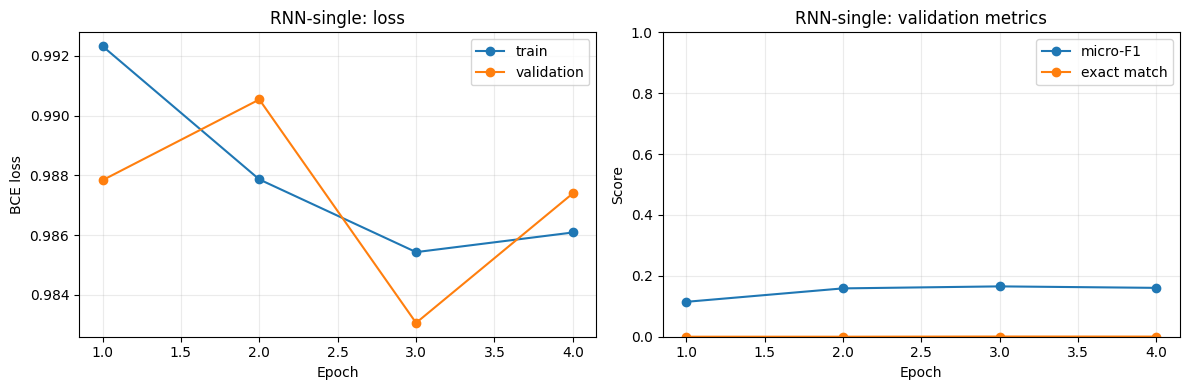

Completed RNN-single: final val micro-F1=0.1605, evaluation micro-F1=0.1596, parameters=1,642,012
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_rnn_single.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_rnn_single_artifacts.zip


In [32]:
# Training job 1/9: RNN, one layer, unidirectional
FORCE_RETRAIN = False
q1_rnn_single_model, q1_rnn_single_history, q1_rnn_single_result = train_q1_model(
    "RNN-single", force_retrain=FORCE_RETRAIN,
)


In [33]:
# Verify that weighted BCE produces positive predictions at the required 0.5 threshold.
@torch.no_grad()
def diagnose_positive_predictions(model: nn.Module, loader: DataLoader, tag: str):
    original_device = next(model.parameters()).device
    model.to(DEVICE).eval()
    probability_batches, target_batches = [], []
    for x, y in loader:
        probability_batches.append(torch.sigmoid(model(x.to(DEVICE))).cpu())
        target_batches.append(y.bool().cpu())

    probabilities = torch.cat(probability_batches)
    targets = torch.cat(target_batches)
    threshold_rows = []
    print(
        f"{tag} probabilities: min={probabilities.min().item():.6f}, "
        f"mean={probabilities.mean().item():.6f}, max={probabilities.max().item():.6f}"
    )
    print("Gold positives:", int(targets.sum().item()))

    for threshold in (0.10, 0.20, 0.30, 0.40, 0.50):
        predictions = probabilities >= threshold
        true_positive = int((predictions & targets).sum().item())
        false_positive = int((predictions & ~targets).sum().item())
        false_negative = int((~predictions & targets).sum().item())
        denominator = 2 * true_positive + false_positive + false_negative
        micro_f1 = 2 * true_positive / denominator if denominator else 0.0
        predicted_positives = int(predictions.sum().item())
        threshold_rows.append({
            "threshold": threshold,
            "predicted_positives": predicted_positives,
            "micro_f1": micro_f1,
        })
        print(
            f"threshold={threshold:.2f} | predicted positives={predicted_positives} | "
            f"micro-F1={micro_f1:.4f}"
        )

    diagnosis = {
        "tag": tag,
        "loss": Q1_LOSS_NAME,
        "probability_min": float(probabilities.min().item()),
        "probability_mean": float(probabilities.mean().item()),
        "probability_max": float(probabilities.max().item()),
        "gold_positives": int(targets.sum().item()),
        "threshold_results": threshold_rows,
    }
    diagnosis_path = _q1_paths(tag)["diagnosis"]
    _atomic_json_save(diagnosis, diagnosis_path)
    _write_q1_bundle(tag)
    model.to(original_device)
    print("Saved threshold diagnosis:", diagnosis_path)
    return diagnosis


q1_rnn_single_diagnosis = diagnose_positive_predictions(
    q1_rnn_single_model, val_loader, "RNN-single"
)


RNN-single probabilities: min=0.000742, mean=0.366521, max=0.936246
Gold positives: 82843
threshold=0.10 | predicted positives=1888241 | micro-F1=0.0838
threshold=0.20 | predicted positives=1562491 | micro-F1=0.0969
threshold=0.30 | predicted positives=1408036 | micro-F1=0.1037
threshold=0.40 | predicted positives=1022618 | micro-F1=0.1208
threshold=0.50 | predicted positives=246124 | micro-F1=0.1605
Saved threshold diagnosis: /kaggle/working/q1_artifacts/q1_rnn_single_threshold_diagnosis.json



QUESTION 1 TRAINING JOB: RNN-bidirectional
{
  "tag": "RNN-bidirectional",
  "cell": "RNN",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting RNN-bidirectional from scratch.
RNN-bidirectional | epoch 01/04 | train_loss=0.9287 | val_loss=0.8831 | val_micro_f1=0.2131 | exact_match=0.0131 | best=0.2131 (epoch 1) | 114.2s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_rnn_bidirectional.pt
Download/update this file before ending the session: /kaggle/working/q1_rnn_bidirectional_artifacts.zip
RNN-bidirectional | epoch 02/04 | train_loss=0.8741 | val_loss=0.9115 | val_micro_f1=0.1548 | exact_match=0.0013 | best=0.2131 (epoch 1) | 114.6s
RNN-bidirectional | epoch 03/04 | train_loss=0.8431 | val_loss=0.8512 | val_micro_f1=0.1975 | exact_match=0.0064 | best=0.2131 

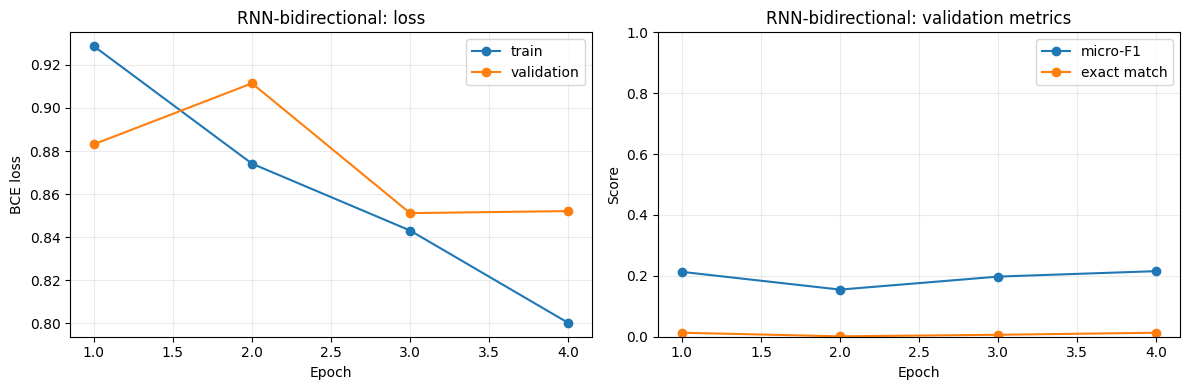

Completed RNN-bidirectional: final val micro-F1=0.2155, evaluation micro-F1=0.2148, parameters=1,747,996
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_rnn_bidirectional.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_rnn_bidirectional_artifacts.zip


In [34]:
# Training job 2/9: RNN, one layer, bidirectional
FORCE_RETRAIN = False
q1_rnn_bidirectional_model, q1_rnn_bidirectional_history, q1_rnn_bidirectional_result = train_q1_model(
    "RNN-bidirectional", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: RNN-stacked
{
  "tag": "RNN-stacked",
  "cell": "RNN",
  "num_layers": 2,
  "bidirectional": false,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting RNN-stacked from scratch.
RNN-stacked | epoch 01/04 | train_loss=0.9929 | val_loss=0.9890 | val_micro_f1=0.1062 | exact_match=0.0006 | best=0.1062 (epoch 1) | 115.5s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_rnn_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_rnn_stacked_artifacts.zip
RNN-stacked | epoch 02/04 | train_loss=1.0011 | val_loss=1.0065 | val_micro_f1=0.1176 | exact_match=0.0000 | best=0.1176 (epoch 2) | 115.8s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_rnn_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_rnn_stack

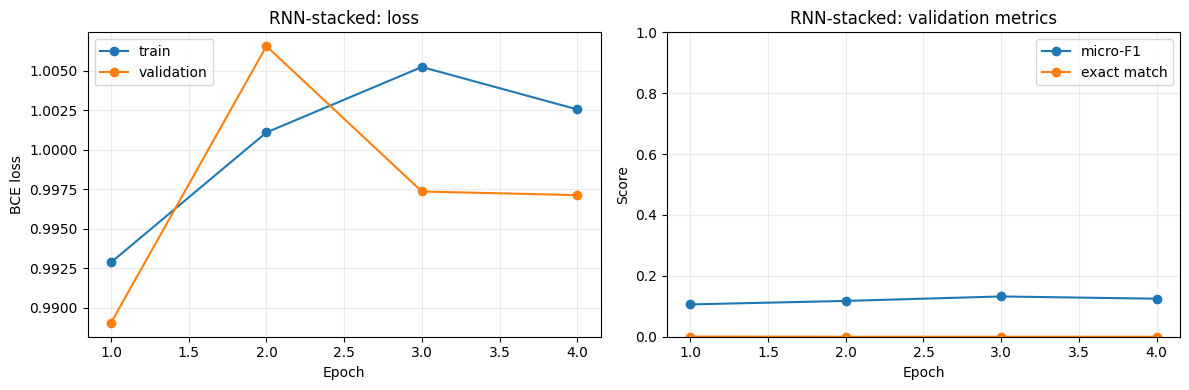

Completed RNN-stacked: final val micro-F1=0.1249, evaluation micro-F1=0.1259, parameters=1,773,596
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_rnn_stacked.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_rnn_stacked_artifacts.zip


In [35]:
# Training job 3/9: RNN, two layers, unidirectional
FORCE_RETRAIN = False
q1_rnn_stacked_model, q1_rnn_stacked_history, q1_rnn_stacked_result = train_q1_model(
    "RNN-stacked", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: LSTM-single
{
  "tag": "LSTM-single",
  "cell": "LSTM",
  "num_layers": 1,
  "bidirectional": false,
  "is_lstm": true,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting LSTM-single from scratch.
LSTM-single | epoch 01/04 | train_loss=0.9558 | val_loss=0.8885 | val_micro_f1=0.2046 | exact_match=0.0019 | best=0.2046 (epoch 1) | 114.1s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_lstm_single.pt
Download/update this file before ending the session: /kaggle/working/q1_lstm_single_artifacts.zip
LSTM-single | epoch 02/04 | train_loss=0.8397 | val_loss=0.8000 | val_micro_f1=0.2407 | exact_match=0.0044 | best=0.2407 (epoch 2) | 114.0s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_lstm_single.pt
Download/update this file before ending the session: /kaggle/working/q1_lstm_sing

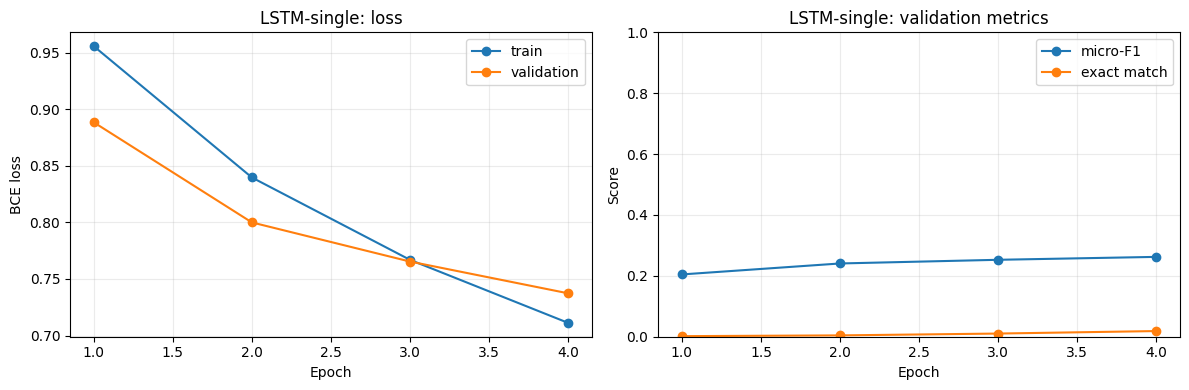

Completed LSTM-single: final val micro-F1=0.2623, evaluation micro-F1=0.2624, parameters=1,938,460
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_lstm_single.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_lstm_single_artifacts.zip


In [36]:
# Training job 4/9: LSTM, one layer, unidirectional
FORCE_RETRAIN = False
q1_lstm_single_model, q1_lstm_single_history, q1_lstm_single_result = train_q1_model(
    "LSTM-single", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: LSTM-bidirectional
{
  "tag": "LSTM-bidirectional",
  "cell": "LSTM",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": true,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting LSTM-bidirectional from scratch.
LSTM-bidirectional | epoch 01/04 | train_loss=0.8416 | val_loss=0.7696 | val_micro_f1=0.2569 | exact_match=0.0330 | best=0.2569 (epoch 1) | 141.1s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_lstm_bidirectional.pt
Download/update this file before ending the session: /kaggle/working/q1_lstm_bidirectional_artifacts.zip
LSTM-bidirectional | epoch 02/04 | train_loss=0.7227 | val_loss=0.7248 | val_micro_f1=0.2821 | exact_match=0.0403 | best=0.2821 (epoch 2) | 142.6s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_lstm_bidirectional.pt
Download/update this file 

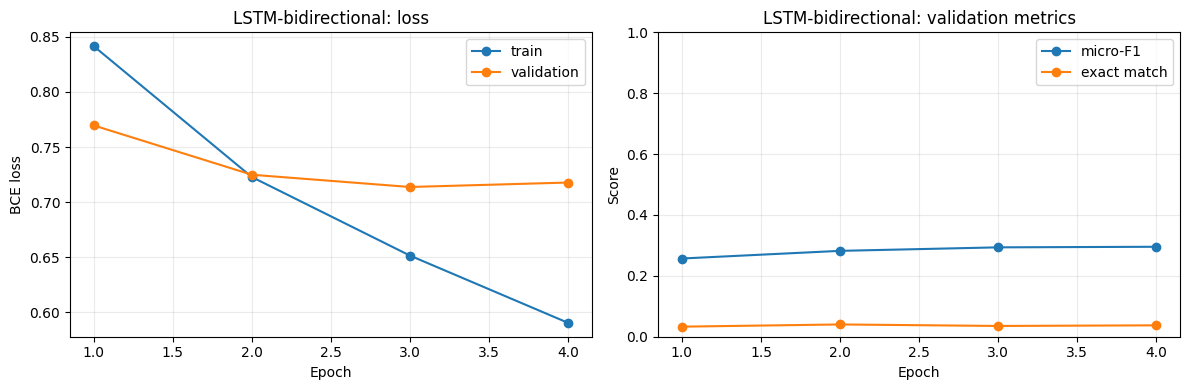

Completed LSTM-bidirectional: final val micro-F1=0.2955, evaluation micro-F1=0.2949, parameters=2,340,892
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_lstm_bidirectional.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_lstm_bidirectional_artifacts.zip


In [37]:
# Training job 5/9: LSTM, one layer, bidirectional
FORCE_RETRAIN = False
q1_lstm_bidirectional_model, q1_lstm_bidirectional_history, q1_lstm_bidirectional_result = train_q1_model(
    "LSTM-bidirectional", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: LSTM-stacked
{
  "tag": "LSTM-stacked",
  "cell": "LSTM",
  "num_layers": 2,
  "bidirectional": false,
  "is_lstm": true,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting LSTM-stacked from scratch.
LSTM-stacked | epoch 01/04 | train_loss=0.9770 | val_loss=0.9662 | val_micro_f1=0.1511 | exact_match=0.0000 | best=0.1511 (epoch 1) | 141.5s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_lstm_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_lstm_stacked_artifacts.zip
LSTM-stacked | epoch 02/04 | train_loss=0.8986 | val_loss=0.8549 | val_micro_f1=0.2038 | exact_match=0.0000 | best=0.2038 (epoch 2) | 142.4s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_lstm_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_l

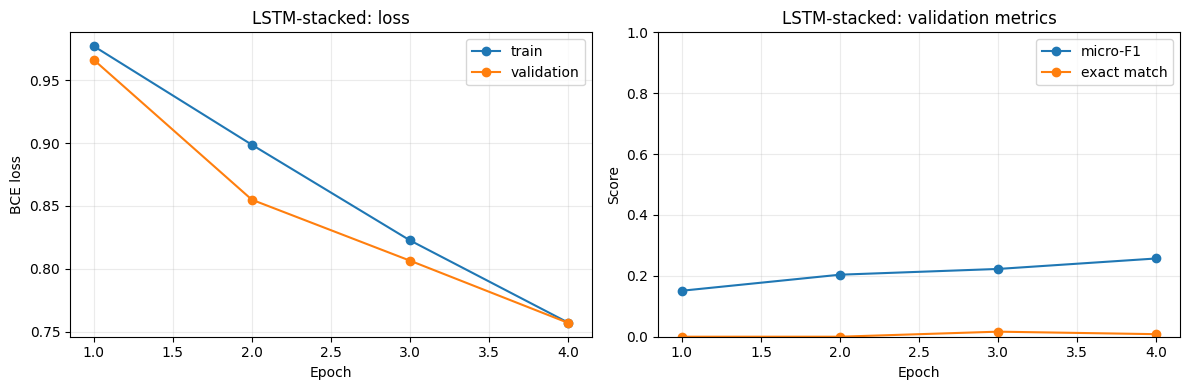

Completed LSTM-stacked: final val micro-F1=0.2571, evaluation micro-F1=0.2567, parameters=2,464,796
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_lstm_stacked.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_lstm_stacked_artifacts.zip


In [38]:
# Training job 6/9: LSTM, two layers, unidirectional
FORCE_RETRAIN = False
q1_lstm_stacked_model, q1_lstm_stacked_history, q1_lstm_stacked_result = train_q1_model(
    "LSTM-stacked", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: GRU-single
{
  "tag": "GRU-single",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": false,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-single from scratch.
GRU-single | epoch 01/04 | train_loss=0.8682 | val_loss=0.7661 | val_micro_f1=0.2502 | exact_match=0.0114 | best=0.2502 (epoch 1) | 132.2s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_single.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_single_artifacts.zip
GRU-single | epoch 02/04 | train_loss=0.7205 | val_loss=0.7129 | val_micro_f1=0.2828 | exact_match=0.0307 | best=0.2828 (epoch 2) | 133.4s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_single.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_single_artifa

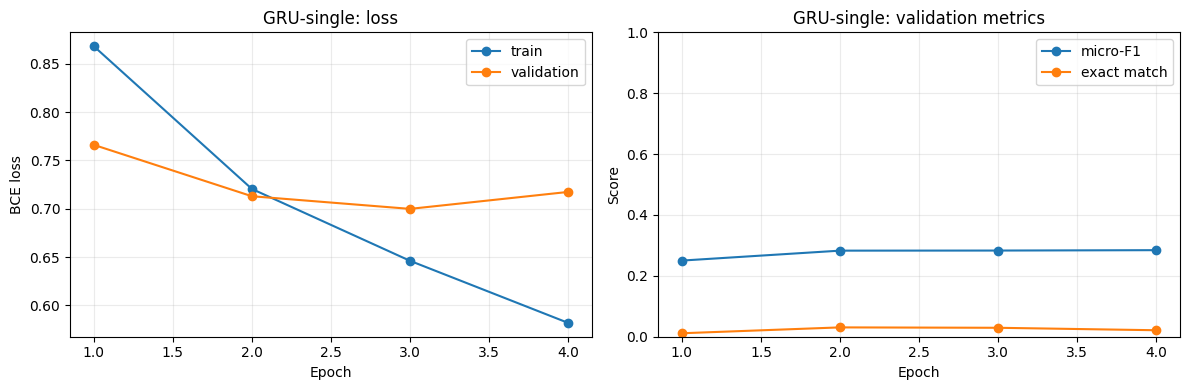

Completed GRU-single: final val micro-F1=0.2844, evaluation micro-F1=0.2845, parameters=1,839,644
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_single.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_single_artifacts.zip


In [39]:
# Training job 7/9: GRU, one layer, unidirectional
FORCE_RETRAIN = False
q1_gru_single_model, q1_gru_single_history, q1_gru_single_result = train_q1_model(
    "GRU-single", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: GRU-bidirectional
{
  "tag": "GRU-bidirectional",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-bidirectional from scratch.
GRU-bidirectional | epoch 01/04 | train_loss=0.8283 | val_loss=0.7516 | val_micro_f1=0.2737 | exact_match=0.0414 | best=0.2737 (epoch 1) | 179.1s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_bidirectional_artifacts.zip
GRU-bidirectional | epoch 02/04 | train_loss=0.7004 | val_loss=0.7077 | val_micro_f1=0.2776 | exact_match=0.0341 | best=0.2776 (epoch 2) | 179.8s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional.pt
Download/update this file before e

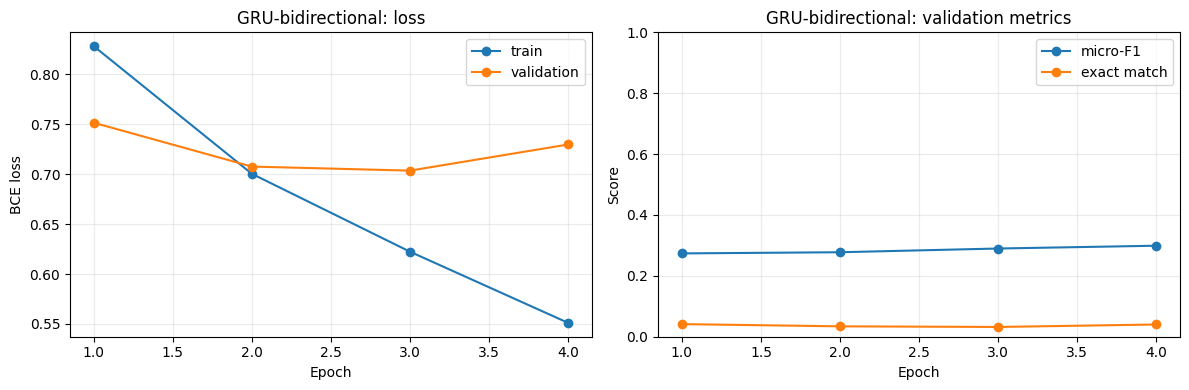

Completed GRU-bidirectional: final val micro-F1=0.2990, evaluation micro-F1=0.2988, parameters=2,143,260
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_bidirectional_artifacts.zip


In [40]:
# Training job 8/9: GRU, one layer, bidirectional
FORCE_RETRAIN = False
q1_gru_bidirectional_model, q1_gru_bidirectional_history, q1_gru_bidirectional_result = train_q1_model(
    "GRU-bidirectional", force_retrain=FORCE_RETRAIN,
)



QUESTION 1 TRAINING JOB: GRU-stacked
{
  "tag": "GRU-stacked",
  "cell": "GRU",
  "num_layers": 2,
  "bidirectional": false,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "baseline",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-stacked from scratch.
GRU-stacked | epoch 01/04 | train_loss=0.8455 | val_loss=0.7533 | val_micro_f1=0.2346 | exact_match=0.0088 | best=0.2346 (epoch 1) | 180.3s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_stacked_artifacts.zip
GRU-stacked | epoch 02/04 | train_loss=0.7051 | val_loss=0.6991 | val_micro_f1=0.2803 | exact_match=0.0275 | best=0.2803 (epoch 2) | 180.2s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_stacked.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_stack

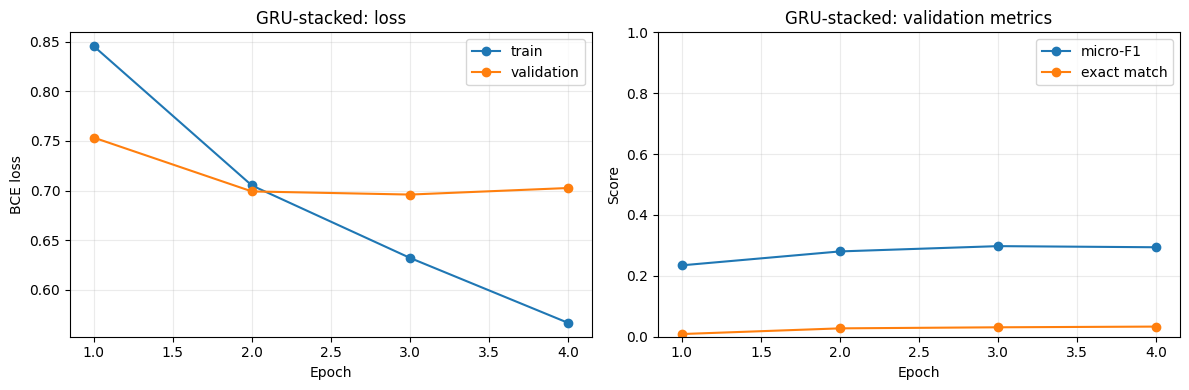

Completed GRU-stacked: final val micro-F1=0.2939, evaluation micro-F1=0.2940, parameters=2,234,396
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_stacked.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_stacked_artifacts.zip


In [41]:
# Training job 9/9: GRU, two layers, unidirectional
FORCE_RETRAIN = False
q1_gru_stacked_model, q1_gru_stacked_history, q1_gru_stacked_result = train_q1_model(
    "GRU-stacked", force_retrain=FORCE_RETRAIN,
)


In [42]:
# Run after the nine per-configuration ZIPs are present locally or uploaded under /kaggle/input.
q1_best_tag = finalize_q1_artifacts(require_all=True)


Reconstructed RNN-single from saved artifacts.
Reconstructed RNN-bidirectional from saved artifacts.
Reconstructed RNN-stacked from saved artifacts.
Reconstructed LSTM-single from saved artifacts.
Reconstructed LSTM-bidirectional from saved artifacts.
Reconstructed LSTM-stacked from saved artifacts.
Reconstructed GRU-single from saved artifacts.
Reconstructed GRU-bidirectional from saved artifacts.
Reconstructed GRU-stacked from saved artifacts.

Question 1 comparison table (real completed-run values)
| Model | Val micro-F1 | Val loss | Exact match | Eval micro-F1 | Macro F1 | Parameters |
|---|---:|---:|---:|---:|---:|---:|
| RNN-single | 0.1605 | 0.9874 | 0.0004 | 0.1596 | 0.0578 | 1,642,012 |
| RNN-bidirectional | 0.2155 | 0.8521 | 0.0131 | 0.2148 | 0.1834 | 1,747,996 |
| RNN-stacked | 0.1249 | 0.9971 | 0.0000 | 0.1259 | 0.0610 | 1,773,596 |
| LSTM-single | 0.2623 | 0.7373 | 0.0186 | 0.2624 | 0.2386 | 1,938,460 |
| LSTM-bidirectional | 0.2955 | 0.7177 | 0.0374 | 0.2949 | 0.2666 | 2,

**Quantitative & Qualitative Analysis[5 Marks]**

1. Per-Label F1 Heatmaps

For multi-label classification, a single 28×28 confusion matrix is not meaningful because classes are independent rather than mutually exclusive. Instead, the grid below visualizes each model's F1 score across all 28 emotion categories:

* **Why Heatmaps?** They immediately expose which emotion labels (e.g., *gratitude*, *admiration*) are easily learned versus which abstract or rare emotions (e.g., *grief*, *relief*) suffer across different architectures.
* **Architecture Comparison:** Comparing subplots side-by-side reveals how moving from Vanilla RNNs to LSTMs/GRUs and adding bidirectionality lifts per-label performance across the board.

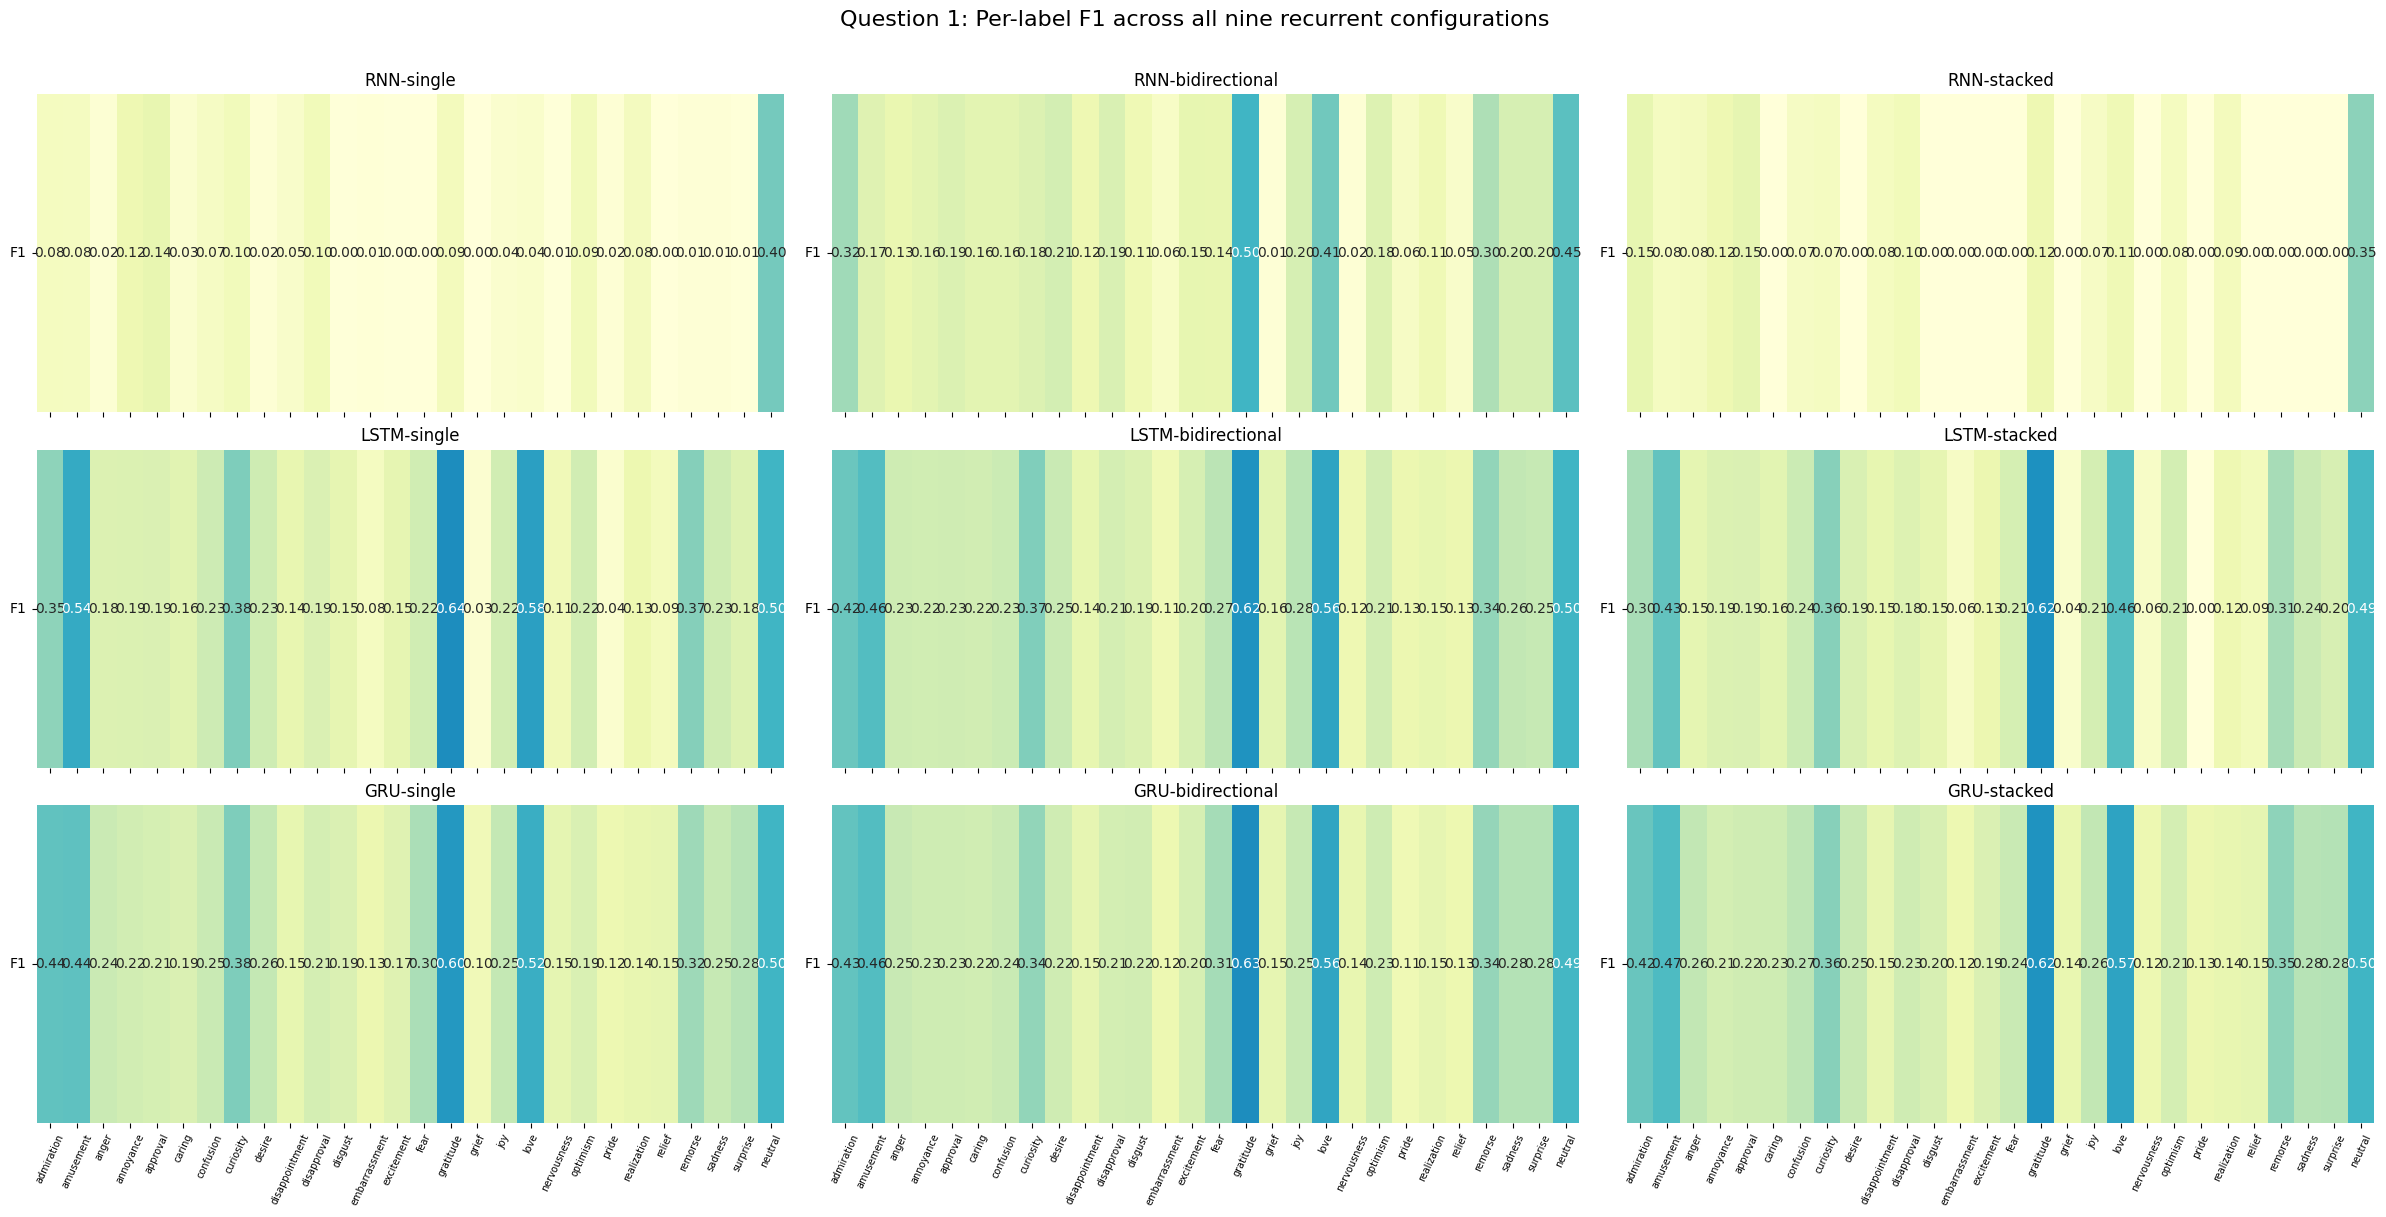

Saved per-label F1 grid: /kaggle/working/q1_artifacts/q1_per_label_f1_grid.png


In [43]:
# --- Per-Label F1 Heatmaps Visualization ---
if any(tag not in results for tag, *_ in experiment_configs):
    rebuild_q1_state(require_all=True)

fig, axes = plt.subplots(3, 3, figsize=(24, 12), sharex=True)
for axis, (tag, _, _, _, _) in zip(axes.flat, experiment_configs):
    report = results[tag]["report"]
    f1_scores = np.asarray([[report[label]["f1-score"] for label in label_names]])
    sns.heatmap(
        f1_scores, ax=axis, vmin=0.0, vmax=1.0, cmap="YlGnBu",
        annot=True, fmt=".2f", cbar=False,
        xticklabels=label_names, yticklabels=["F1"],
    )
    axis.set_title(tag)
    axis.tick_params(axis="x", labelrotation=65, labelsize=7)
    axis.tick_params(axis="y", labelrotation=0)

fig.suptitle("Question 1: Per-label F1 across all nine recurrent configurations", fontsize=16, y=1.01)
fig.tight_layout()
f1_grid_path = Q1_OUTPUT_DIR / "q1_per_label_f1_grid.png"
fig.savefig(f1_grid_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved per-label F1 grid:", f1_grid_path)


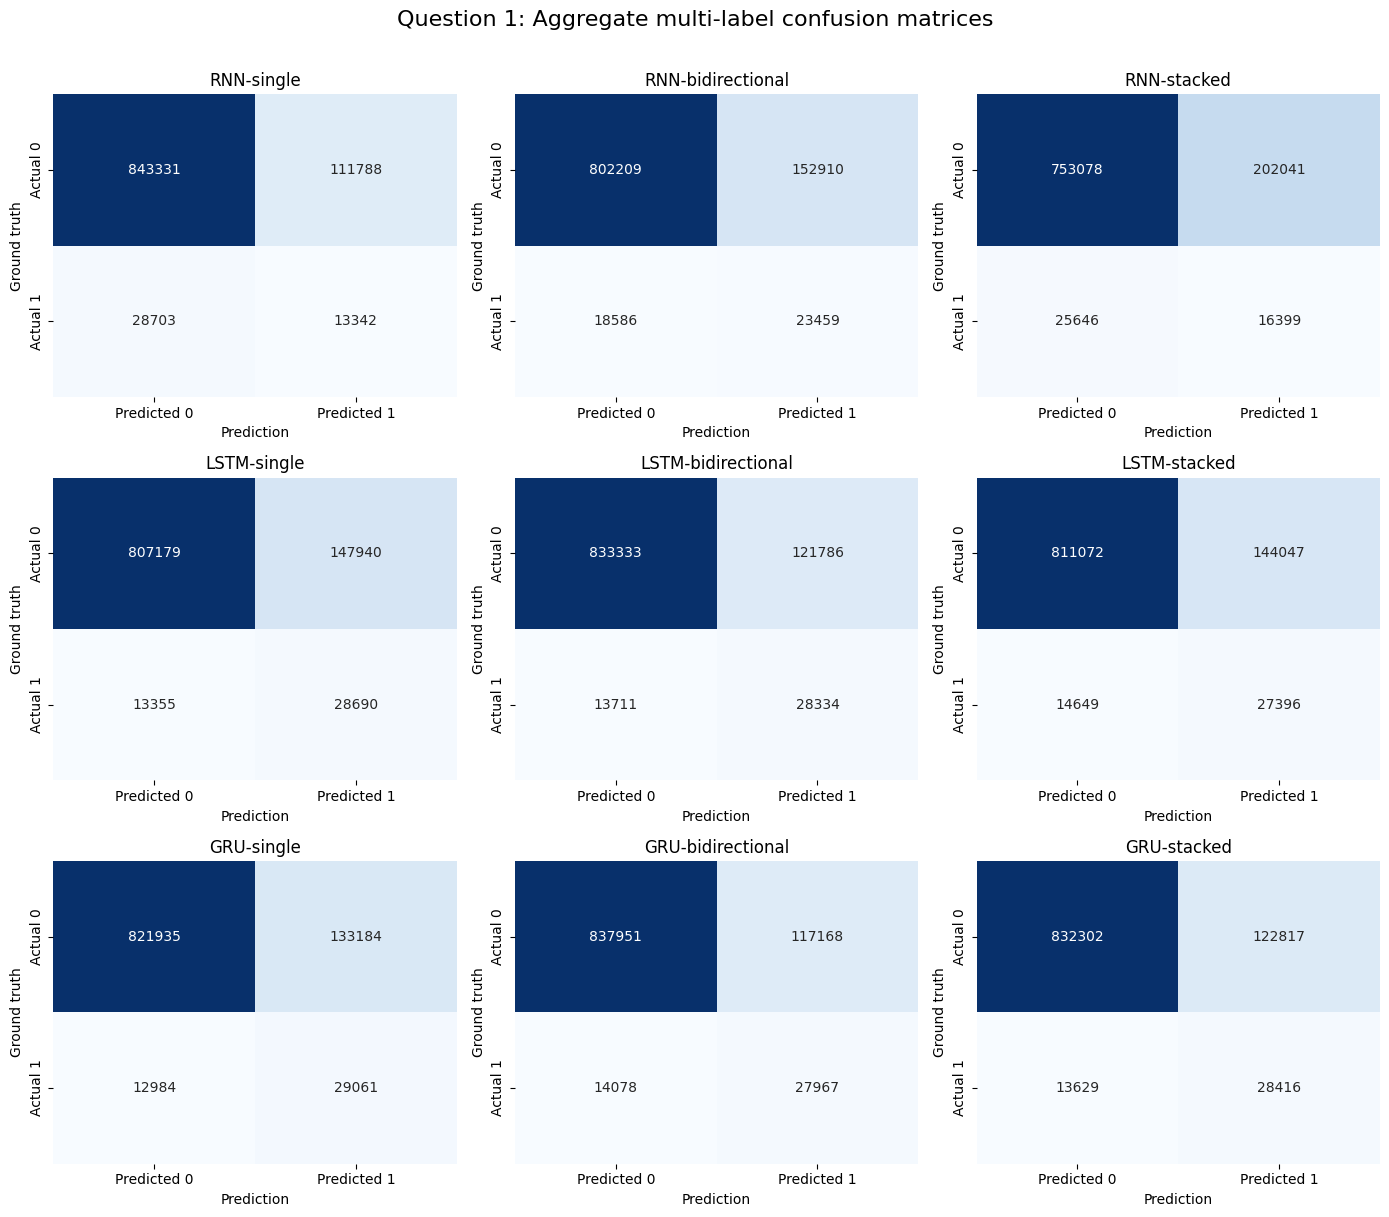

Saved 3 x 3 confusion-matrix grid: /kaggle/working/q1_artifacts/q1_confusion_matrix_grid.png


In [44]:
# --- Required 3 x 3 aggregate multi-label confusion-matrix grid ---
# Each panel sums the 28 independent 2x2 label matrices for one model.
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for axis, (tag, _, _, _, _) in zip(axes.flat, experiment_configs):
    aggregate_matrix = np.asarray(results[tag]["cm"]).sum(axis=0)
    sns.heatmap(
        aggregate_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
    )
    axis.set_title(tag)
    axis.set_xlabel("Prediction")
    axis.set_ylabel("Ground truth")

fig.suptitle("Question 1: Aggregate multi-label confusion matrices", fontsize=16, y=1.01)
fig.tight_layout()
confusion_grid_path = Q1_OUTPUT_DIR / "q1_confusion_matrix_grid.png"
fig.savefig(confusion_grid_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved 3 x 3 confusion-matrix grid:", confusion_grid_path)


**Identifying the Largest Multi-Label Errors[5 Marks]**

For each label, we inspect false positives and false negatives rather than forcing one predicted class to compete with another.


For multi-label classification, standard multi-class confusion matrices do not work because each emotion is evaluated independently. Instead, we inspect **False Positives (FP)** and **False Negatives (FN)** across individual 2×2 label matrices:

* **False Positives (Type I Error):** The model predicts an emotion that wasn't actually present in the comment (over-predicting).
* **False Negatives (Type II Error):** The model misses an emotion that was present in the gold-standard labels (under-predicting).
* **Why Track This?** Isolating top FP and FN counts per label helps us pinpoint which specific emotions our best recurrent architecture struggles with most.

In [45]:
# --- Identifying Largest Multi-Label Errors ---
def get_top_label_errors(label_confusion_matrices, class_names, k=5):
    """Return the largest per-label false-positive and false-negative counts."""
    errors = []
    for matrix, class_name in zip(label_confusion_matrices, class_names):
        false_positive = int(matrix[0, 1])
        false_negative = int(matrix[1, 0])
        errors.append((false_positive, "false positive", class_name))
        errors.append((false_negative, "false negative", class_name))
    return sorted(errors, key=lambda item: item[0], reverse=True)[:k]


best_model_tag = max(histories, key=lambda tag: histories[tag]["val_acc"][-1])
best_confusion_matrices = np.asarray(results[best_model_tag]["cm"])
top_errors = get_top_label_errors(best_confusion_matrices, label_names, k=10)
print(f"Largest label-wise errors for {best_model_tag}:")
for count, error_type, label in top_errors:
    print(f"{label:16s} | {error_type:14s} | {count:5d}")


Largest label-wise errors for GRU-bidirectional:
approval         | false positive | 11075
neutral          | false positive |  9869
disapproval      | false positive |  9662
annoyance        | false positive |  9454
disappointment   | false positive |  8270
realization      | false positive |  7674
optimism         | false positive |  5683
confusion        | false positive |  5466
joy              | false positive |  5335
admiration       | false positive |  5090


**Qualitative Inspection: Multi-Label Prediction Errors[5 Marks]**

Inspect examples where the predicted set of labels does not exactly match the true label set.


Quantitative metrics like F1 scores and confusion matrices show us *where* the model fails globally, but qualitative inspection shows us *why* it fails on specific texts.

* **Exact Set Mismatch:** We look for comments where the model's predicted set of emotion labels does not perfectly align with the gold-standard true labels.
* **Nuance & Overlap:** This inspection reveals how the model handles subtle linguistic cues, sarcasm, or highly overlapping categories (e.g., confusing *admiration* with *approval*).

In [46]:
# --- Qualitative Inspection of Multi-Label Errors ---
@torch.no_grad()
def inspect_multilabel_errors(model: nn.Module, test_ds, class_names: list, n_samples: int = 5):
    """Print comments whose predicted multi-label sets differ from their true sets."""
    model.to(DEVICE).eval()
    count = 0
    for example in test_ds:
        x = torch.tensor([encode(example[TEXT_COL])], dtype=torch.long, device=DEVICE)
        predicted = (torch.sigmoid(model(x))[0] >= MULTILABEL_THRESHOLD).cpu()
        target = torch.tensor(example["multi_hot"], dtype=torch.bool)
        if not torch.equal(predicted, target):
            true_labels = [class_names[idx] for idx, value in enumerate(target) if value]
            predicted_labels = [class_names[idx] for idx, value in enumerate(predicted) if value]
            print("Text:", example[TEXT_COL])
            print("True labels:", true_labels)
            print("Predicted labels:", predicted_labels)
            print("-" * 80)
            count += 1
        if count >= n_samples:
            break
    model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


best_cfg = _Q1_CONFIG_BY_TAG[best_model_tag]
best_model = trained_models[best_model_tag]
inspect_multilabel_errors(best_model, test_ds, label_names, n_samples=5)
print(f"Displayed qualitative errors for validation-selected model: {best_model_tag}")


Text: I always cry when [NAME] is on screen.
True labels: ['joy']
Predicted labels: ['sadness', 'neutral']
--------------------------------------------------------------------------------
Text: I'm jealous. I'm in California
True labels: ['neutral']
Predicted labels: ['sadness']
--------------------------------------------------------------------------------
Text: It's nice to see someone regognize my username :)
True labels: ['excitement']
Predicted labels: ['admiration', 'approval', 'excitement', 'joy']
--------------------------------------------------------------------------------
Text: The importance of believing in [NAME] and see, and sticking with them, when you realize they're good things 
True labels: ['joy']
Predicted labels: ['approval', 'realization', 'neutral']
--------------------------------------------------------------------------------
Text: Holy shit I was so anxious reading this. I’m so sorry
True labels: ['curiosity', 'remorse', 'sadness']
Predicted labels: ['annoy

**Parameter Efficiency Breakdown[10 Marks]**

Finally, let's analyze the trade-off between **model capacity (parameter count)** and **validation accuracy**:

Finally, let's analyze the trade-off between **model capacity (parameter count)** and **validation micro-F1 performance**:

* **Efficiency vs. Performance:** Larger models (like multi-layer LSTMs or BiGRUs) have higher parameter capacities, but do they always yield proportional accuracy gains over simpler architectures?
* **Comparative Trade-Offs:** Plotting parameter counts against validation scores helps us determine the optimal "sweet spot"—balancing computational cost and inference speed against multi-label classification accuracy across our 9 model configurations.

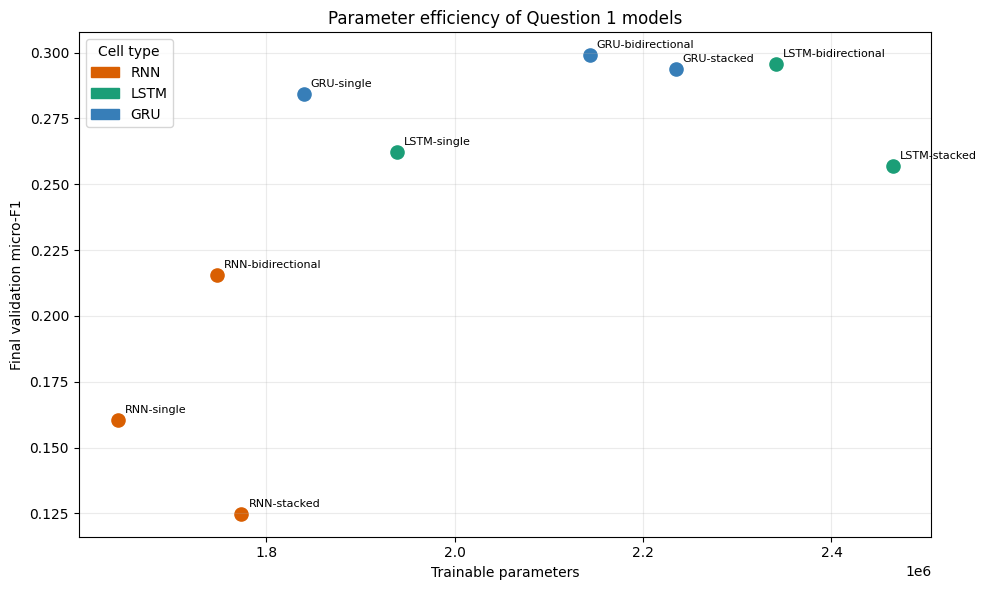

| Model | Trainable parameters | Final validation micro-F1 |
|---|---:|---:|
| RNN-single | 1,642,012 | 0.1605 |
| RNN-bidirectional | 1,747,996 | 0.2155 |
| RNN-stacked | 1,773,596 | 0.1249 |
| LSTM-single | 1,938,460 | 0.2623 |
| LSTM-bidirectional | 2,340,892 | 0.2955 |
| LSTM-stacked | 2,464,796 | 0.2571 |
| GRU-single | 1,839,644 | 0.2844 |
| GRU-bidirectional | 2,143,260 | 0.2990 |
| GRU-stacked | 2,234,396 | 0.2939 |
Saved parameter-efficiency plot: /kaggle/working/q1_artifacts/q1_parameter_efficiency.png


In [47]:
# --- Parameter Efficiency Breakdown & Scaling Analysis ---
if any(tag not in trained_models for tag, *_ in experiment_configs):
    rebuild_q1_state(require_all=True)

parameter_rows = []
fig, axis = plt.subplots(figsize=(10, 6))
architecture_colors = {"RNN": "#d95f02", "LSTM": "#1b9e77", "GRU": "#377eb8"}
for tag, cell_cls, n_layers, is_bidir, is_lstm in experiment_configs:
    model = trained_models[tag]
    parameters = count_parameters(model)
    micro_f1 = histories[tag]["val_acc"][-1]
    architecture = tag.split("-")[0]
    parameter_rows.append((tag, parameters, micro_f1))
    axis.scatter(parameters, micro_f1, s=90, color=architecture_colors[architecture], label=architecture)
    axis.annotate(tag, (parameters, micro_f1), xytext=(5, 5), textcoords="offset points", fontsize=8)

handles = [mpatches.Patch(color=color, label=name) for name, color in architecture_colors.items()]
axis.legend(handles=handles, title="Cell type")
axis.set(title="Parameter efficiency of Question 1 models", xlabel="Trainable parameters", ylabel="Final validation micro-F1")
axis.grid(alpha=0.25)
fig.tight_layout()
parameter_plot_path = Q1_OUTPUT_DIR / "q1_parameter_efficiency.png"
fig.savefig(parameter_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("| Model | Trainable parameters | Final validation micro-F1 |")
print("|---|---:|---:|")
for tag, parameters, micro_f1 in parameter_rows:
    print(f"| {tag} | {parameters:,} | {micro_f1:.4f} |")
print("Saved parameter-efficiency plot:", parameter_plot_path)


### Task 8 : Advanced Analytical & Experimental Evaluation[Total = 50 Marks]

Answer all questions below using evidence, metrics, and observations directly from your 9-model sweep and experimental runs.

- Logical & Reasoning

* **L1. Stacking vs. Bidirectionality:[10 Marks]** Both doubling stacking depth and adding bidirectionality roughly double parameter count, but do they solve the same problem? Justify your answer using the architectural limitations and sequence-reading constraints observed in your sweep.






Stacking and bidirectionality increase capacity in different ways. Stacking sends the complete sequence representation from one recurrent layer into the next, so higher layers can learn progressively more abstract temporal features. It does not give a unidirectional timestep access to later tokens. Bidirectionality instead runs independent forward and backward cells, giving the classifier evidence from both left and right context; it does not add representational depth. Their parameter counts can be similar, but they address hierarchical capacity and context availability respectively. The A1 output below supplies the measured final micro-F1 deltas from this run so this architectural explanation is grounded in the nine-model sweep rather than an assumed outcome.


* **L2. Universal Gradient Clipping:[10 marks]** Is applying a uniform gradient clipping norm (`max_norm=5.0`) to all models (including LSTM/GRU and vanilla RNN) scientifically correct for a fair 9-model comparison, or could it mask a real performance difference between architectures? Explain your reasoning.


Using the same clipping rule for all nine models is a defensible controlled comparison because every architecture receives the same optimizer-side safeguard and no model is given a specially tuned threshold. However, it can partially hide a genuine stability difference: vanilla RNNs may cross the threshold more often, while LSTM/GRU gates may naturally keep gradients better conditioned. Clipping changes only gradients above the threshold, so the comparison measures performance under a shared stable-training protocol, not each architecture's unconstrained gradient behavior. A stronger follow-up would report pre-clipping gradient norms and clipping frequency per model, or tune the threshold only in a separate ablation; the required sweep should retain the common `max_norm=5.0` rule.


- Analytical (Requires Your Run's Data & Plots)

* **A1. Performance Sweep Analysis:[10 Marks]** Report the final validation micro-F1 score and validation loss for all 9 trained models. Which single architectural change (single→stacked, or unidirectional→bidirectional) yielded the largest micro-F1 gain, averaged across cell types?


Before filling out the code below, familiarize yourself with these core components:

* **`histories`**: A dictionary storing the training and validation history for all 9 models trained during the sweep, tracking keys such as `"val_acc"` (validation micro-F1) and `"val_loss"`.
* **`experiment_configs`**: The configuration list mapping model tags to their corresponding cell types, layer depths, and directionality settings.
* **Micro-F1 Gain Calculation**: Computes the delta ($\Delta$) in validation micro-F1 when transitioning from single-layer to stacked layers ($L=1 \rightarrow 2$) and from unidirectional to bidirectional contexts across RNN, LSTM, and GRU variants.
* **Comparative Evaluation**: Averages the performance deltas across cell families to determine which architectural scaling method provides a larger boost in multi-label classification accuracy.

In [48]:
# --- A1: Real nine-model performance table and isolated architecture gains ---
if any(tag not in histories for tag, *_ in experiment_configs):
    rebuild_q1_state(require_all=True)

print("| Model | Final validation micro-F1 | Final validation loss |")
print("|---|---:|---:|")
for tag, *_ in experiment_configs:
    print(f"| {tag} | {histories[tag]['val_acc'][-1]:.4f} | {histories[tag]['val_loss'][-1]:.4f} |")

stacking_gains = {}
bidirectional_gains = {}
for architecture in ("RNN", "LSTM", "GRU"):
    single_score = histories[f"{architecture}-single"]["val_acc"][-1]
    stacked_score = histories[f"{architecture}-stacked"]["val_acc"][-1]
    bidirectional_score = histories[f"{architecture}-bidirectional"]["val_acc"][-1]
    stacking_gains[architecture] = stacked_score - single_score
    bidirectional_gains[architecture] = bidirectional_score - single_score

average_stacking_gain = float(np.mean(list(stacking_gains.values())))
average_bidirectional_gain = float(np.mean(list(bidirectional_gains.values())))
larger_change = "single-layer to stacked" if average_stacking_gain > average_bidirectional_gain else "unidirectional to bidirectional"

print("\nIsolated micro-F1 gains: stacking is 1L-uni to 2L-uni; bidirectionality is 1L-uni to 1L-bi.")
for architecture in ("RNN", "LSTM", "GRU"):
    print(
        f"{architecture}: stacking={stacking_gains[architecture]:+.4f}, "
        f"bidirectionality={bidirectional_gains[architecture]:+.4f}"
    )
print(f"Average stacking gain: {average_stacking_gain:+.4f}")
print(f"Average bidirectionality gain: {average_bidirectional_gain:+.4f}")
print(f"Largest average gain in this run: {larger_change}")

q1_a1_analysis = {
    "stacking_gains": stacking_gains,
    "bidirectional_gains": bidirectional_gains,
    "average_stacking_gain": average_stacking_gain,
    "average_bidirectional_gain": average_bidirectional_gain,
    "largest_average_gain": larger_change,
}
_atomic_json_save(q1_a1_analysis, Q1_OUTPUT_DIR / "q1_a1_analysis.json")


| Model | Final validation micro-F1 | Final validation loss |
|---|---:|---:|
| RNN-single | 0.1605 | 0.9874 |
| RNN-bidirectional | 0.2155 | 0.8521 |
| RNN-stacked | 0.1249 | 0.9971 |
| LSTM-single | 0.2623 | 0.7373 |
| LSTM-bidirectional | 0.2955 | 0.7177 |
| LSTM-stacked | 0.2571 | 0.7570 |
| GRU-single | 0.2844 | 0.7174 |
| GRU-bidirectional | 0.2990 | 0.7298 |
| GRU-stacked | 0.2939 | 0.7025 |

Isolated micro-F1 gains: stacking is 1L-uni to 2L-uni; bidirectionality is 1L-uni to 1L-bi.
RNN: stacking=-0.0356, bidirectionality=+0.0549
LSTM: stacking=-0.0052, bidirectionality=+0.0332
GRU: stacking=+0.0096, bidirectionality=+0.0146
Average stacking gain: -0.0104
Average bidirectionality gain: +0.0343
Largest average gain in this run: unidirectional to bidirectional


* **E1. Word-Order Control:[10 Marks]** Run a word-order control experiment: shuffle the token order randomly within every train/val example (preserving the exact same token set) and retrain `GRU-single` from scratch. Compare its final validation micro-F1 to the un-shuffled `GRU-single` baseline.


Before filling out the code below, familiarize yourself with these core components:

* **Token-Order Shuffling (`shuffled_encode`)**: Randomizes the sequence of tokenized words prior to truncation and padding. This tests whether the model relies on sequential syntax or solves the classification task primarily via bag-of-words keyword matching.
* **`ShuffledEmotionDataset`**: A custom dataset wrapper that inherits standard target indexing but leverages `shuffled_encode` for input representations.
* **Retraining and Comparison**: Retrains a fresh `GRU-single` model configuration on the shuffled data loaders to measure the validation performance drop.

In [49]:
def shuffled_encode(text: str, shuffle_seed: int) -> list[int]:
    """Shuffle tokens deterministically before truncation and padding."""
    tokens = tokenize(text)
    rng = random.Random(shuffle_seed)
    rng.shuffle(tokens)
    ids = [stoi.get(token, stoi[UNK]) for token in tokens][:MAX_LEN]
    return ids + [stoi[PAD]] * (MAX_LEN - len(ids))


In [50]:
class ShuffledEmotionDataset(Dataset):
    """Return deterministic word-order-shuffled inputs and unchanged targets."""

    def __init__(self, hf_ds, seed_offset: int = 0):
        super().__init__()
        self.texts = hf_ds[TEXT_COL]
        self.targets = hf_ds["multi_hot"]
        self.seed_offset = seed_offset

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = shuffled_encode(self.texts[idx], SEED + self.seed_offset + idx)
        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(self.targets[idx], dtype=torch.float32),
        )



QUESTION 1 TRAINING JOB: GRU-single-shuffled
{
  "tag": "GRU-single-shuffled",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": false,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "word_order_shuffled",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-single-shuffled from scratch.
GRU-single-shuffled | epoch 01/04 | train_loss=0.8888 | val_loss=0.7808 | val_micro_f1=0.2456 | exact_match=0.0150 | best=0.2456 (epoch 1) | 133.5s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_single_shuffled.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_single_shuffled_artifacts.zip
GRU-single-shuffled | epoch 02/04 | train_loss=0.7337 | val_loss=0.7255 | val_micro_f1=0.2804 | exact_match=0.0381 | best=0.2804 (epoch 2) | 137.8s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_single_shuffled.pt
Downlo

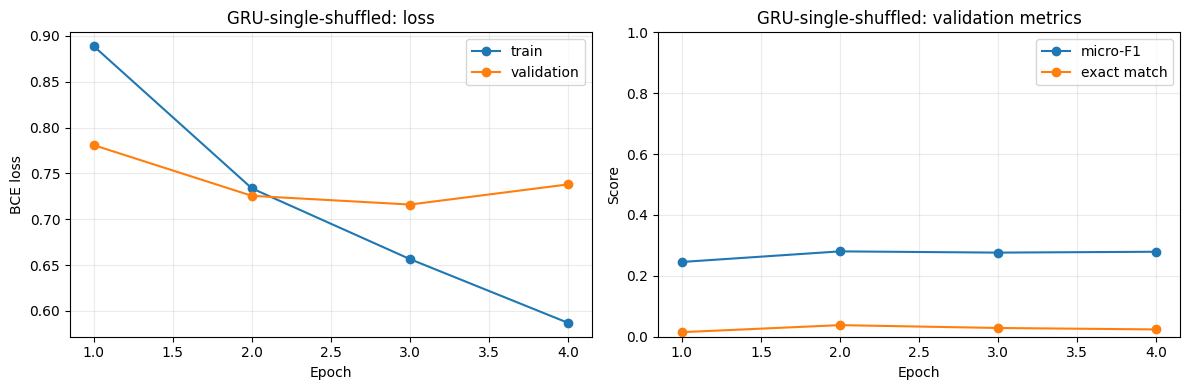

Completed GRU-single-shuffled: final val micro-F1=0.2791, evaluation micro-F1=0.2775, parameters=1,839,644
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_single_shuffled.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_single_shuffled_artifacts.zip
GRU-single baseline final validation micro-F1: 0.2844
Shuffled-order final validation micro-F1: 0.2791
Shuffled minus baseline: -0.0052


In [51]:
# E1 training job: shuffled-word-order GRU-single (separately resumable)
shuffled_train_loader = DataLoader(
    ShuffledEmotionDataset(train_ds, seed_offset=0), batch_size=64, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available(),
)
shuffled_val_loader = DataLoader(
    ShuffledEmotionDataset(val_ds, seed_offset=100_000), batch_size=128, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available(),
)
FORCE_RETRAIN = False
word_order_model, word_order_history, word_order_result = train_q1_variant(
    "GRU-single-shuffled", GRUCell, 1, False, False,
    shuffled_train_loader, shuffled_val_loader, test_loader,
    force_retrain=FORCE_RETRAIN, variant="word_order_shuffled",
)

baseline_gru_single = results.get("GRU-single") or load_q1_result("GRU-single")
if baseline_gru_single is None or baseline_gru_single.get("status") != "complete":
    raise FileNotFoundError("Upload the completed q1_gru_single_artifacts.zip to compare E1 with its baseline.")
baseline_score = baseline_gru_single["final_val_micro_f1"]
shuffled_score = word_order_history["val_acc"][-1]
word_order_delta = shuffled_score - baseline_score
print(f"GRU-single baseline final validation micro-F1: {baseline_score:.4f}")
print(f"Shuffled-order final validation micro-F1: {shuffled_score:.4f}")
print(f"Shuffled minus baseline: {word_order_delta:+.4f}")
_atomic_json_save(
    {"baseline": baseline_score, "shuffled": shuffled_score, "delta": word_order_delta},
    Q1_OUTPUT_DIR / "q1_e1_word_order_comparison.json",
)


* **E2. Sequence Length Sweep:[10 Marks]** Vary `MAX_LEN` in $\{15, 30, 50\}$ and retrain `GRU-bidirectional` for each setting, holding all other hyperparameters fixed. Plot and analyze validation micro-F1 vs. `MAX_LEN`.

Before filling out the code below, familiarize yourself with these core components:

* **Self-Contained DataLoaders (`build_loaders_for_max_len`)**: Dynamically reconstructs dataset encoding rules for different sequence length thresholds ($\text{MAX\_LEN} \in \{15, 30, 50\}$) without corrupting global variables.
* **Model Retraining Loop**: Trains a fresh `GRU-bidirectional` classifier configuration across each sequence length setting while holding all other hyperparameters constant.
* **Performance Analysis**: Evaluates validation micro-F1 fluctuations to examine how truncation or padding density impacts sequence context capture.

In [52]:
# --- E2: Self-contained data loaders for each fixed sequence length ---
def build_loaders_for_max_len(max_len: int):
    """Build loaders without changing the global MAX_LEN or baseline datasets."""
    class FixedLengthEmotionDataset(Dataset):
        def __init__(self, hf_ds):
            self.texts = hf_ds[TEXT_COL]
            self.targets = hf_ds["multi_hot"]

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            ids = [stoi.get(token, stoi[UNK]) for token in tokenize(self.texts[idx])][:max_len]
            ids += [stoi[PAD]] * (max_len - len(ids))
            return (
                torch.tensor(ids, dtype=torch.long),
                torch.tensor(self.targets[idx], dtype=torch.float32),
            )

    return (
        DataLoader(FixedLengthEmotionDataset(train_ds), batch_size=64, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(FixedLengthEmotionDataset(val_ds), batch_size=128, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(FixedLengthEmotionDataset(test_ds), batch_size=128, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
    )


sequence_length_results = globals().get("sequence_length_results", {})



QUESTION 1 TRAINING JOB: GRU-bidirectional-len15
{
  "tag": "GRU-bidirectional-len15",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 15,
  "variant": "sequence_length",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-bidirectional-len15 from scratch.
GRU-bidirectional-len15 | epoch 01/04 | train_loss=0.8464 | val_loss=0.7833 | val_micro_f1=0.2571 | exact_match=0.0364 | best=0.2571 (epoch 1) | 133.7s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len15.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_bidirectional_len15_artifacts.zip
GRU-bidirectional-len15 | epoch 02/04 | train_loss=0.7256 | val_loss=0.7470 | val_micro_f1=0.2639 | exact_match=0.0290 | best=0.2639 (epoch 2) | 133.2s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_bi

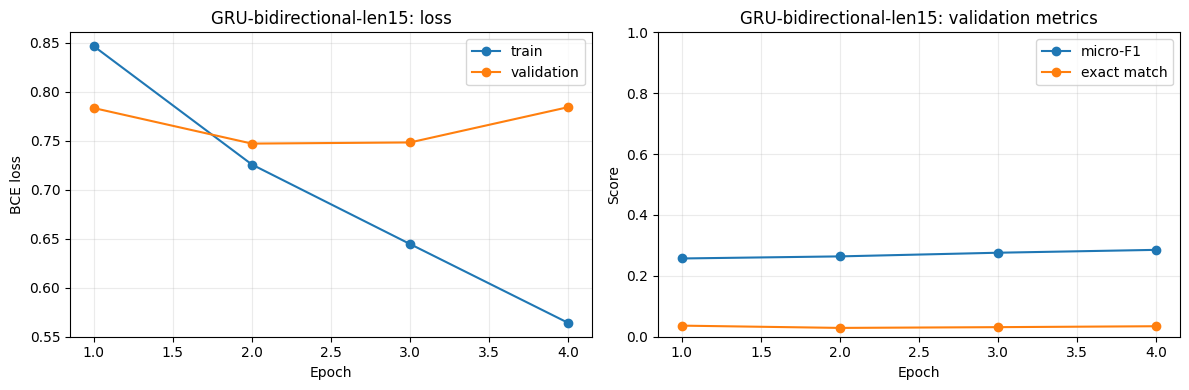

Completed GRU-bidirectional-len15: final val micro-F1=0.2854, evaluation micro-F1=0.2865, parameters=2,143,260
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len15.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_bidirectional_len15_artifacts.zip


In [53]:
# E2 training job 1/3: GRU-bidirectional with MAX_LEN=15
train_loader_len15, val_loader_len15, test_loader_len15 = build_loaders_for_max_len(15)
FORCE_RETRAIN = False
q1_len15_model, q1_len15_history, q1_len15_result = train_q1_variant(
    "GRU-bidirectional-len15", GRUCell, 1, True, False,
    train_loader_len15, val_loader_len15, test_loader_len15,
    force_retrain=FORCE_RETRAIN, max_len=15, variant="sequence_length",
)
sequence_length_results[15] = q1_len15_result
del q1_len15_model, train_loader_len15, val_loader_len15, test_loader_len15
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()



QUESTION 1 TRAINING JOB: GRU-bidirectional-len30
{
  "tag": "GRU-bidirectional-len30",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 30,
  "variant": "sequence_length",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-bidirectional-len30 from scratch.
GRU-bidirectional-len30 | epoch 01/04 | train_loss=0.8283 | val_loss=0.7516 | val_micro_f1=0.2737 | exact_match=0.0414 | best=0.2737 (epoch 1) | 180.6s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len30.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_bidirectional_len30_artifacts.zip
GRU-bidirectional-len30 | epoch 02/04 | train_loss=0.7004 | val_loss=0.7077 | val_micro_f1=0.2776 | exact_match=0.0341 | best=0.2776 (epoch 2) | 180.8s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_bi

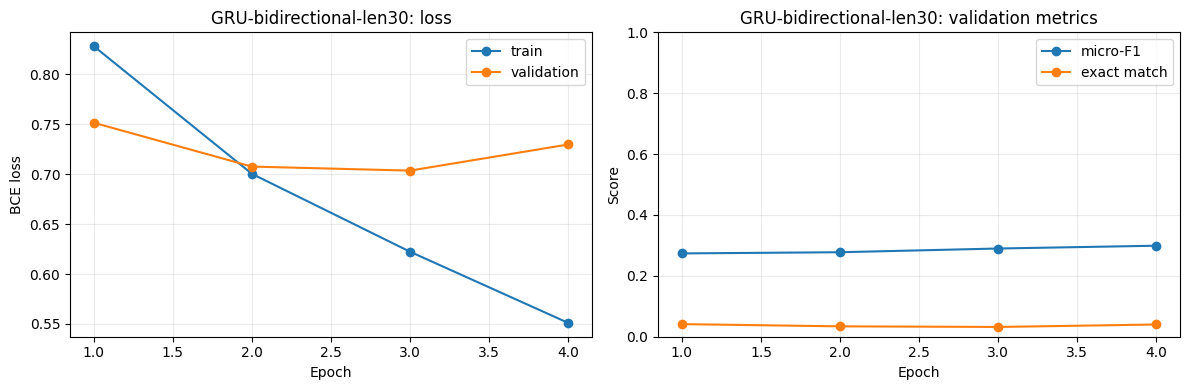

Completed GRU-bidirectional-len30: final val micro-F1=0.2990, evaluation micro-F1=0.2988, parameters=2,143,260
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len30.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_bidirectional_len30_artifacts.zip


In [54]:
# E2 training job 2/3: GRU-bidirectional with MAX_LEN=30
train_loader_len30, val_loader_len30, test_loader_len30 = build_loaders_for_max_len(30)
FORCE_RETRAIN = False
q1_len30_model, q1_len30_history, q1_len30_result = train_q1_variant(
    "GRU-bidirectional-len30", GRUCell, 1, True, False,
    train_loader_len30, val_loader_len30, test_loader_len30,
    force_retrain=FORCE_RETRAIN, max_len=30, variant="sequence_length",
)
sequence_length_results[30] = q1_len30_result
del q1_len30_model, train_loader_len30, val_loader_len30, test_loader_len30
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()



QUESTION 1 TRAINING JOB: GRU-bidirectional-len50
{
  "tag": "GRU-bidirectional-len50",
  "cell": "GRU",
  "num_layers": 1,
  "bidirectional": true,
  "is_lstm": false,
  "emb_dim": 128,
  "hidden_dim": 256,
  "num_classes": 28,
  "vocab_size": 12000,
  "max_len": 50,
  "variant": "sequence_length",
  "seed": 42,
  "loss": "bce_with_logits_pos_weight_cap20"
}
Starting GRU-bidirectional-len50 from scratch.
GRU-bidirectional-len50 | epoch 01/04 | train_loss=0.8311 | val_loss=0.7551 | val_micro_f1=0.2689 | exact_match=0.0396 | best=0.2689 (epoch 1) | 243.8s
Checkpoint protected at epoch 1: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len50.pt
Download/update this file before ending the session: /kaggle/working/q1_gru_bidirectional_len50_artifacts.zip
GRU-bidirectional-len50 | epoch 02/04 | train_loss=0.7071 | val_loss=0.7102 | val_micro_f1=0.2751 | exact_match=0.0296 | best=0.2751 (epoch 2) | 242.8s
Checkpoint protected at epoch 2: /kaggle/working/q1_artifacts/q1_resume_gru_bi

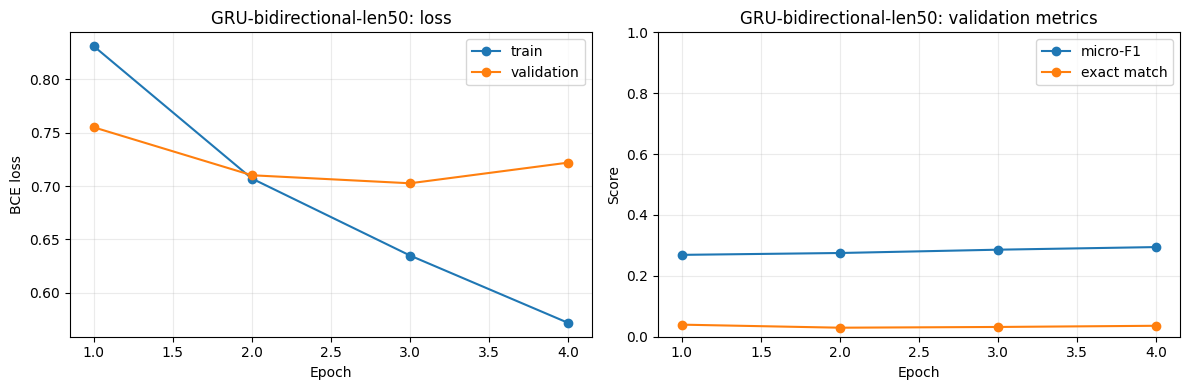

Completed GRU-bidirectional-len50: final val micro-F1=0.2945, evaluation micro-F1=0.2937, parameters=2,143,260
Resume checkpoint: /kaggle/working/q1_artifacts/q1_resume_gru_bidirectional_len50.pt
Download this file from the Kaggle Output/Files panel: /kaggle/working/q1_gru_bidirectional_len50_artifacts.zip


In [55]:
# E2 training job 3/3: GRU-bidirectional with MAX_LEN=50
train_loader_len50, val_loader_len50, test_loader_len50 = build_loaders_for_max_len(50)
FORCE_RETRAIN = False
q1_len50_model, q1_len50_history, q1_len50_result = train_q1_variant(
    "GRU-bidirectional-len50", GRUCell, 1, True, False,
    train_loader_len50, val_loader_len50, test_loader_len50,
    force_retrain=FORCE_RETRAIN, max_len=50, variant="sequence_length",
)
sequence_length_results[50] = q1_len50_result
del q1_len50_model, train_loader_len50, val_loader_len50, test_loader_len50
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


| MAX_LEN | Final validation micro-F1 | Final validation loss |
|---:|---:|---:|
| 15 | 0.2854 | 0.7842 |
| 30 | 0.2990 | 0.7298 |
| 50 | 0.2945 | 0.7220 |


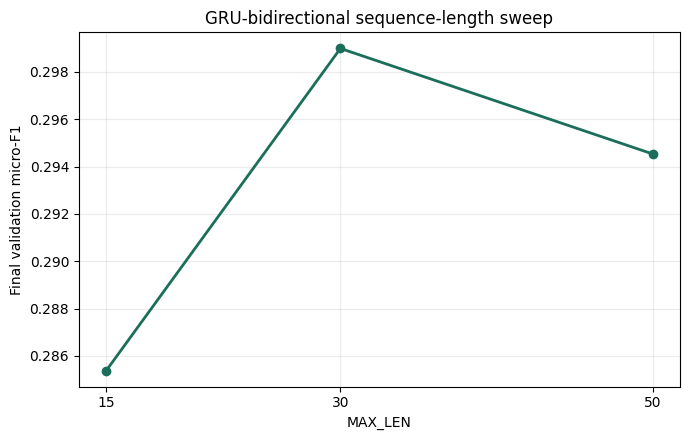

Best validation micro-F1 in this executed sweep occurs at MAX_LEN=30.


In [56]:
# E2 analysis: restore all three real run results and plot validation micro-F1.
for sequence_length in (15, 30, 50):
    if sequence_length not in sequence_length_results:
        tag = f"GRU-bidirectional-len{sequence_length}"
        restored_result = load_q1_result(tag)
        if restored_result is None or restored_result.get("status") != "complete":
            raise FileNotFoundError(f"Upload the completed artifact ZIP for {tag} before running E2 analysis.")
        sequence_length_results[sequence_length] = restored_result

lengths = [15, 30, 50]
length_scores = [sequence_length_results[length]["final_val_micro_f1"] for length in lengths]
print("| MAX_LEN | Final validation micro-F1 | Final validation loss |")
print("|---:|---:|---:|")
for length in lengths:
    result = sequence_length_results[length]
    print(f"| {length} | {result['final_val_micro_f1']:.4f} | {result['final_val_loss']:.4f} |")

fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(lengths, length_scores, marker="o", linewidth=2, color="#1b6f5a")
axis.set(title="GRU-bidirectional sequence-length sweep", xlabel="MAX_LEN", ylabel="Final validation micro-F1", xticks=lengths)
axis.grid(alpha=0.25)
fig.tight_layout()
length_plot_path = Q1_OUTPUT_DIR / "q1_e2_sequence_length_sweep.png"
fig.savefig(length_plot_path, dpi=180, bbox_inches="tight")
plt.show()
best_length = lengths[int(np.argmax(length_scores))]
print(f"Best validation micro-F1 in this executed sweep occurs at MAX_LEN={best_length}.")
_atomic_json_save(
    {"scores": {str(length): score for length, score in zip(lengths, length_scores)}, "best_max_len": best_length},
    Q1_OUTPUT_DIR / "q1_e2_sequence_length_analysis.json",
)


In [57]:
# --- Final Question 1 protection archive ---
# Rebuilds all nine baselines, refreshes q1_best.pt/manifest.json, and bundles available Q1 work.
q1_best_tag = finalize_q1_artifacts(require_all=True)
all_q1_archive = _Q1_RUNTIME_ROOT / "q1_all_artifacts.zip"
temporary_archive = Path(str(all_q1_archive) + ".tmp")
with ZipFile(temporary_archive, "w", ZIP_DEFLATED) as archive:
    for artifact in sorted(Q1_OUTPUT_DIR.glob("q1_*")):
        if artifact.is_file() and artifact.name != all_q1_archive.name:
            archive.write(artifact, arcname=artifact.name)
    for config_zip in sorted(_Q1_RUNTIME_ROOT.glob("q1_*_artifacts.zip")):
        if config_zip.is_file() and config_zip != all_q1_archive:
            archive.write(config_zip, arcname=f"configuration_bundles/{config_zip.name}")
os.replace(temporary_archive, all_q1_archive)
print(f"Question 1 is protected in: {all_q1_archive}")
print("Download this file from the Kaggle Output/Files panel before ending the session.")


Reconstructed RNN-single from saved artifacts.
Reconstructed RNN-bidirectional from saved artifacts.
Reconstructed RNN-stacked from saved artifacts.
Reconstructed LSTM-single from saved artifacts.
Reconstructed LSTM-bidirectional from saved artifacts.
Reconstructed LSTM-stacked from saved artifacts.
Reconstructed GRU-single from saved artifacts.
Reconstructed GRU-bidirectional from saved artifacts.
Reconstructed GRU-stacked from saved artifacts.

Question 1 comparison table (real completed-run values)
| Model | Val micro-F1 | Val loss | Exact match | Eval micro-F1 | Macro F1 | Parameters |
|---|---:|---:|---:|---:|---:|---:|
| RNN-single | 0.1605 | 0.9874 | 0.0004 | 0.1596 | 0.0578 | 1,642,012 |
| RNN-bidirectional | 0.2155 | 0.8521 | 0.0131 | 0.2148 | 0.1834 | 1,747,996 |
| RNN-stacked | 0.1249 | 0.9971 | 0.0000 | 0.1259 | 0.0610 | 1,773,596 |
| LSTM-single | 0.2623 | 0.7373 | 0.0186 | 0.2624 | 0.2386 | 1,938,460 |
| LSTM-bidirectional | 0.2955 | 0.7177 | 0.0374 | 0.2949 | 0.2666 | 2,

# **Question 2 — English-to-Hindi Machine Translation[Total = 150 Marks]**
2. Implement Encoder-Decoder 2-layer bidirectional GRU model from scratch for machine translation task (English-Hindi translation), train it, do the error analysis to understand the poor performance.


In [10]:
# --- Question 2 Kaggle runtime and restart-safe artifact configuration ---
import gc
import shutil
import zlib
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

_Q2_RUNTIME_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
Q2_OUTPUT_DIR = _Q2_RUNTIME_ROOT / "q2_artifacts"
Q2_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
Q2_PROGRESS_PATH = _Q2_RUNTIME_ROOT / "q2_progress_manifest.json"
Q2_CHECKPOINT_EVERY = 5

# In a new Kaggle notebook/version, set this to the mounted directory containing
# a previously downloaded q2_<experiment>_bundle.zip. Current working files win.
Q2_PREVIOUS_ARTIFACT_DIR = None

_Q2_PROGRESS_LOCK = threading.Lock()
_Q2_PLOT_LOCK = threading.Lock()
_Q2_MODEL_BUILD_LOCK = threading.Lock()


def _q2_slug(name: str) -> str:
    slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    return slug[3:] if slug.startswith("q2_") else slug


def _q2_atomic_torch_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)


def _q2_atomic_json_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    with temporary.open("w", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2, ensure_ascii=False)
    os.replace(temporary, path)


def _q2_paths(experiment_name: str) -> dict:
    slug = _q2_slug(experiment_name)
    directory = Q2_OUTPUT_DIR / slug
    directory.mkdir(parents=True, exist_ok=True)
    return {
        "slug": slug,
        "dir": directory,
        "resume": directory / f"q2_{slug}_resume.pt",
        "best": directory / f"q2_{slug}_best_state.pt",
        "model": directory / f"q2_{slug}_encoder_decoder.pt",
        "history": directory / f"q2_{slug}_history.json",
        "config": directory / f"q2_{slug}_config.json",
        "result": directory / f"q2_{slug}_result.json",
        "examples": directory / f"q2_{slug}_examples.json",
        "plot": directory / f"q2_{slug}_training.png",
        "readme": directory / f"q2_{slug}_README.txt",
        "bundle": _Q2_RUNTIME_ROOT / f"q2_{slug}_bundle.zip",
    }


def _q2_restore_experiment(experiment_name: str):
    """Restore one exact experiment bundle/checkpoint; never pick silently."""
    paths = _q2_paths(experiment_name)
    if paths["resume"].is_file():
        print(f"Using current Q2 checkpoint: {paths['resume']}")
        return
    search_roots = []
    if Q2_PREVIOUS_ARTIFACT_DIR is not None:
        previous = Path(Q2_PREVIOUS_ARTIFACT_DIR)
        if not previous.is_dir():
            raise FileNotFoundError(f"Q2_PREVIOUS_ARTIFACT_DIR does not exist: {previous}")
        search_roots.append(previous)
    else:
        kaggle_input = Path("/kaggle/input")
        if kaggle_input.is_dir():
            search_roots.extend(path for path in kaggle_input.iterdir() if path.is_dir())
    candidates = [paths["bundle"]] if paths["bundle"].is_file() else []
    for previous in search_roots:
        candidates.extend(previous.rglob(paths["bundle"].name))
        candidates.extend(previous.rglob(paths["resume"].name))
    candidates = list(dict.fromkeys(candidate.resolve() for candidate in candidates))
    if len(candidates) > 1:
        raise RuntimeError(f"Multiple restore candidates for {experiment_name}: {candidates}")
    if not candidates:
        print(f"No prior artifact found for {experiment_name}; searched current output and {search_roots}")
        return
    candidate = candidates[0]
    if candidate.suffix == ".zip":
        with ZipFile(candidate) as archive:
            for member in archive.infolist():
                basename = Path(member.filename).name
                if member.is_dir() or not basename or basename in {"vocab_en.json", "vocab_hi.json", "q2_progress_manifest.json"}:
                    continue
                destination = paths["dir"] / basename
                temporary = Path(str(destination) + ".tmp")
                with archive.open(member) as source_handle, temporary.open("wb") as target_handle:
                    shutil.copyfileobj(source_handle, target_handle)
                os.replace(temporary, destination)
    else:
        shutil.copy2(candidate, paths["resume"])
    print(f"Restored {experiment_name} from: {candidate}")


def _q2_load_progress() -> dict:
    if not Q2_PROGRESS_PATH.is_file():
        return {}
    with Q2_PROGRESS_PATH.open("r", encoding="utf-8") as handle:
        return json.load(handle)


def _q2_update_progress(experiment_name: str, **values):
    # Two GPU workers may finish an epoch together; serialize the read-modify-write.
    with _Q2_PROGRESS_LOCK:
        progress = _q2_load_progress()
        progress[experiment_name] = {**progress.get(experiment_name, {}), **values}
        _q2_atomic_json_save(progress, Q2_PROGRESS_PATH)


def _q2_capture_rng_state() -> dict:
    state = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state


def _q2_restore_rng_state(state):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and "cuda" in state:
        torch.cuda.set_rng_state_all([item.cpu() for item in state["cuda"]])


def _q2_torch_load(path: Path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


print("Question 2 artifact directory:", Q2_OUTPUT_DIR)
print("Visible CUDA devices:", torch.cuda.device_count())
for _gpu_index in range(torch.cuda.device_count()):
    print(f"  cuda:{_gpu_index}: {torch.cuda.get_device_name(_gpu_index)}")
print("Set Q2_PREVIOUS_ARTIFACT_DIR before a training/evaluation cell when restoring an older Kaggle output.")


Question 2 artifact directory: /kaggle/working/q2_artifacts
Visible CUDA devices: 2
  cuda:0: Tesla T4
  cuda:1: Tesla T4
Set Q2_PREVIOUS_ARTIFACT_DIR before a training/evaluation cell when restoring an older Kaggle output.


In Question 1, we worked on multi-label emotion classification—where the model reads a sentence and predicts a **set of multiple emotion labels** simultaneously.

Machine translation is completely different. Here, we convert a **variable-length sequence of English words** into a **variable-length sequence of Hindi words**:

$$\text{"I love learning NLP."} \longrightarrow \text{"मुझे एनएलपी सीखना पसंद है।"}$$

Because input and output lengths can be completely different, a fixed classification head won't work. Instead, we use an **Encoder-Decoder (Seq2Seq)** framework:

* **The Encoder:** Reads the entire English sentence and compresses its meaning into a single hidden vector representation.
* **The Decoder:** Unrolls that vector to generate the Hindi translation, token by token.

### **Dataset Preparation**

In this section, we will prepare our English-Hindi parallel text dataset, build two separate vocabularies, and construct PyTorch `DataLoaders` that handle sequence padding and special tokens.



#### **Loading the Parallel Corpus**

**What are we doing?**

We call `load_dataset` to retrieve our train, validation, and test splits and inspect their column names. **Never assume column names!** They might be structured as `["english", "hindi"]`, `["src", "tgt"]`, or nested inside a `["translation"]` dictionary. Always print an example row to verify the schema before writing any downstream processing code.

In [11]:
#Do not Change content of this cell
def load_english_hindi(repo_id: str, token: str):
    """Load English-Hindi train, validation, and test splits from the course HF repository."""
    return load_dataset(
        repo_id,
        data_files={
            "train": "Assignment2/EnglishHindi_train.parquet",
            "validation": "Assignment2/EnglishHindi_val.parquet",
            "test": "Assignment2/EnglishHindi_test.parquet",
        },
        token=token,
    )

mt_raw = load_english_hindi(REPO_ID, hf_token)

README.md: 0.00B [00:00, ?B/s]

Assignment2/EnglishHindi_train.parquet:   0%|          | 0.00/190M [00:00<?, ?B/s]

Assignment2/EnglishHindi_val.parquet:   0%|          | 0.00/85.7k [00:00<?, ?B/s]

Assignment2/EnglishHindi_test.parquet:   0%|          | 0.00/281k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

####**Schema Detection & Column Mapping[5 marks]**

**Why do we need this?**


Parquet files stored in Hugging Face can sometimes nest translation pairs inside a dictionary column (e.g., `row['translation']['en']`) or store them in flat top-level columns (e.g., `row['english']` and `row['hindi']`). We need to inspect the schema and assign `SRC_COL` (English) and `TGT_COL` (Hindi) correctly.

In [12]:
# Inspect the dataset schema
print("--- Dataset Splits ---")
print(mt_raw)

print("\n--- Column Names ---")
print(mt_raw["train"].column_names)

print("\n--- Example Row ---")
print(mt_raw["train"][0])

--- Dataset Splits ---
DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 1659083
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 520
    })
    test: Dataset({
        features: ['translation'],
        num_rows: 1253
    })
})

--- Column Names ---
['translation']

--- Example Row ---
{'translation': {'en': 'Give your application an accessibility workout', 'hi': 'अपने अनुप्रयोग को पहुंचनीयता व्यायाम का लाभ दें'}}


Before filling out the code below, familiarize yourself with these core components:

* **`SRC_LANG` & `TGT_LANG`**: Keys used to extract the source (English) and target (Hindi) strings from the nested dictionary format.
* **`extract_pair(example)`**: A helper utility function that safely parses a dataset row and returns the tuple of source and target sentences.
* **`sample_en` & `sample_hi`**: Sanity-check variables that pull the first translated pair to verify proper extraction before building vocabularies.

In [13]:
# From the schema inspection above, translations are nested under example['translation'].
# The helper also accepts common flat schemas so a clear error is raised if the dataset changes.
SRC_LANG, TGT_LANG = "en", "hi"


def extract_pair(example: dict) -> tuple[str, str]:
    """Extract and validate one English-Hindi pair from a course dataset row."""
    if "translation" in example and isinstance(example["translation"], dict):
        translation = example["translation"]
        if SRC_LANG in translation and TGT_LANG in translation:
            return str(translation[SRC_LANG]), str(translation[TGT_LANG])
    for src_key, tgt_key in (("english", "hindi"), ("src", "tgt"), ("en", "hi")):
        if src_key in example and tgt_key in example:
            return str(example[src_key]), str(example[tgt_key])
    raise KeyError(f"Unsupported translation schema. Available keys: {list(example)}")


sample_en, sample_hi = extract_pair(mt_raw["train"][0])
print(f"Detected mapping: translation['{SRC_LANG}'] -> English, translation['{TGT_LANG}'] -> Hindi")
print("Sample English:", sample_en)
print("Sample Hindi:", sample_hi)


Detected mapping: translation['en'] -> English, translation['hi'] -> Hindi
Sample English: Give your application an accessibility workout
Sample Hindi: अपने अनुप्रयोग को पहुंचनीयता व्यायाम का लाभ दें


#### **Tokenization & Building Separate Vocabularies[5 marks]**

#### **Why do we need this?**

1. **Two Languages = Two Vocabularies:** English uses the Latin alphabet (`[a-z]`), while Hindi uses the Devanagari script (`[अ-ह]`). Since their character sets, grammars, and words are completely distinct, we must build **two separate vocabulary mappings** (`stoi_en` / `itos_en` and `stoi_hi` / `itos_hi`).
2. **Special Tokens for Seq2Seq:** Beyond `<pad>` (index 0) and `<unk>` (index 1), sequence-to-sequence models require two extra special control tokens:
* **`<sos>` (Start of Sequence):** Tells the decoder *"Start generating the translation now!"*
* **`<eos>` (End of Sequence):** Tells the decoder *"Stop generating! The sentence is finished."*


**Example Mappings**

* **Special Tokens:**
* `<pad>` $\rightarrow$ `0`
* `<unk>` $\rightarrow$ `1`
* `<sos>` $\rightarrow$ `2`
* `<eos>` $\rightarrow$ `3`

Before filling out the code below, familiarize yourself with these core components:

* **Dual Tokenization (`tokenize_en` / `tokenize_hi`)**: English uses regex word-level tokenization with lowercase conversion, while Hindi uses whitespace tokenization suited for Devanagari script structures.
* **Special Control Tokens (`PAD`, `UNK`, `SOS`, `EOS`)**: Essential tokens for sequence padding (`0`), unknown words (`1`), start of sequence (`2`), and end of sequence (`3`).
* **Vocabulary Limiters (`MAX_VOCAB_EN`, `MAX_VOCAB_HI`)**: Caps vocabulary sizes to control embedding parameter memory and filter out rare noise words.
* **Data Leakage Prevention (`counter_en`, `counter_hi`)**: Frequency counters and vocabulary mappings (`stoi` / `itos`) are built exclusively on the **training split** to prevent information leakage from validation and test sets.

In [14]:
# --- Tokenization & Building Separate Vocabularies ---
EN_TOKEN_RE = re.compile(r"[A-Za-z']+|[.,!?;]")


def tokenize_en(text: str) -> list[str]:
    """Lowercase and tokenize English text using regex."""
    return EN_TOKEN_RE.findall(text.lower())


def tokenize_hi(text: str) -> list[str]:
    """Tokenize Hindi text on whitespace."""
    return text.strip().split()


PAD, UNK, SOS, EOS = "<pad>", "<unk>", "<sos>", "<eos>"
SPECIAL_TOKENS = [PAD, UNK, SOS, EOS]
MAX_VOCAB_EN = 12000
MAX_VOCAB_HI = 15000
counter_en, counter_hi = Counter(), Counter()

for example in mt_raw["train"]:
    src_text, tgt_text = extract_pair(example)
    counter_en.update(tokenize_en(src_text))
    counter_hi.update(tokenize_hi(tgt_text))

itos_en = SPECIAL_TOKENS + [token for token, _ in counter_en.most_common(MAX_VOCAB_EN - len(SPECIAL_TOKENS)) if token not in SPECIAL_TOKENS]
stoi_en = {token: index for index, token in enumerate(itos_en)}
itos_hi = SPECIAL_TOKENS + [token for token, _ in counter_hi.most_common(MAX_VOCAB_HI - len(SPECIAL_TOKENS)) if token not in SPECIAL_TOKENS]
stoi_hi = {token: index for index, token in enumerate(itos_hi)}

print("English vocabulary size:", len(itos_en))
print("Hindi vocabulary size:", len(itos_hi))
print("Hindi special-token IDs:", {token: stoi_hi[token] for token in SPECIAL_TOKENS})

_q2_atomic_json_save(stoi_en, _Q2_RUNTIME_ROOT / "vocab_en.json")
_q2_atomic_json_save(stoi_hi, _Q2_RUNTIME_ROOT / "vocab_hi.json")
_q2_atomic_json_save(stoi_en, Q2_OUTPUT_DIR / "vocab_en.json")
_q2_atomic_json_save(stoi_hi, Q2_OUTPUT_DIR / "vocab_hi.json")
print("Saved Q2 vocabularies:", _Q2_RUNTIME_ROOT / "vocab_en.json", "and", _Q2_RUNTIME_ROOT / "vocab_hi.json")


English vocabulary size: 12000
Hindi vocabulary size: 15000
Hindi special-token IDs: {'<pad>': 0, '<unk>': 1, '<sos>': 2, '<eos>': 3}
Saved Q2 vocabularies: /kaggle/working/vocab_en.json and /kaggle/working/vocab_hi.json


####**Text Encoding & Length Filtering[5 marks]**

#### **Why do we need this?**

1. **Source Encoding:** English sentences are encoded as standard ID sequences.

2. **Target Encoding (Teacher Forcing Format):** The Hindi target sentence **must** be wrapped with start and end markers:

   $$\text{Encoded Hindi} = [\text{stoi_hi}[\text{''<sos>''}] + \text{token_ids} + \text{stoi_hi}[\text{''<eos>''}]]$$

   This allows us to train the decoder using **Teacher Forcing** (feeding `<sos>` as the initial input to predict the first word, and learning to predict `<eos>` when the sentence ends).

3. **Filtering Outliers:** Extremely long sentences (e.g., 200+ tokens) slow down training significantly and consume excessive GPU memory. Filtering out pathologically long sentence pairs keeps our training step times manageable.

Before filling out the code below, familiarize yourself with these core components:

* **Maximum Sequence Lengths (`MAX_LEN_EN`, `MAX_LEN_HI`)**: Caps tokenized sequence lengths to standard tensor dimensions, applying truncation or padding (`PAD`) as necessary.
* **Target Wrapping (`encode_hi`)**: Wraps Hindi target sequences with special control tokens—prepending `<sos>` and appending `<eos>`—which is mandatory for autoregressive sequence-to-sequence training.
* **Outlier Filtering**: Discards pathologically long sentences to prevent excessive memory overhead and maintain efficient batch processing times on the GPU.

In [15]:
# --- Text Encoding & Length Filtering ---
MAX_LEN_EN = 30
MAX_LEN_HI = 30


def encode_en(text: str) -> list[int]:
    """Tokenize and convert English text to token IDs with padding/truncation."""
    tokens = tokenize_en(text)[:MAX_LEN_EN]
    ids = [stoi_en.get(token, stoi_en[UNK]) for token in tokens]
    return ids + [stoi_en[PAD]] * (MAX_LEN_EN - len(ids))


def encode_hi(text: str) -> list[int]:
    """Encode Hindi as SOS + tokens + EOS, preserving EOS when truncating."""
    tokens = tokenize_hi(text)[:MAX_LEN_HI - 2]
    ids = [stoi_hi[SOS]] + [stoi_hi.get(token, stoi_hi[UNK]) for token in tokens] + [stoi_hi[EOS]]
    return ids + [stoi_hi[PAD]] * (MAX_LEN_HI - len(ids))


sample_en_ids = encode_en(sample_en)
sample_hi_ids = encode_hi(sample_hi)
print("Encoded sample English IDs:", sample_en_ids)
print("Encoded sample Hindi IDs:", sample_hi_ids)
print("Hindi sequence begins with SOS and contains EOS:", sample_hi_ids[0] == stoi_hi[SOS], stoi_hi[EOS] in sample_hi_ids)


Encoded sample English IDs: [165, 46, 411, 42, 6317, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Encoded sample Hindi IDs: [2, 33, 1253, 9, 1, 6027, 11, 366, 756, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Hindi sequence begins with SOS and contains EOS: True True


#### **PyTorch Dataset & DataLoader Wrappers[5 marks]**

#### **Why do we need this?**

PyTorch's `DataLoader` automatically handles batching, shuffling, and converting lists of numerical IDs into GPU-ready `torch.LongTensor` objects.

Before filling out the code below, familiarize yourself with these core components:

* **`TranslationDataset` (`torch.utils.data.Dataset`)**: Wraps parallel corpus splits, handling sequence encoding, length-based outlier filtering, and slicing target sequences into decoder input (`tgt_in` excluding the last token) and expected output (`tgt_out` excluding the first `<sos>` token).
* **`DataLoaders` (`torch.utils.data.DataLoader`)**: Automatically manages batching, padding conversions, and tensor casting (`torch.LongTensor`), ensuring **shuffling is enabled exclusively for the training set** to prevent data leakage during validation/testing.

In [16]:
# --- PyTorch Dataset & DataLoader Wrappers ---
class TranslationDataset(Dataset):
    """Filtered English-Hindi pairs with one-time cached tensor encoding."""

    def __init__(self, hf_ds, limit=None):
        super().__init__()
        self.src_texts, self.tgt_texts = [], []
        src_rows, tgt_in_rows, tgt_out_rows = [], [], []
        for example in hf_ds:
            src, tgt = extract_pair(example)
            if len(tokenize_en(src)) <= MAX_LEN_EN and len(tokenize_hi(tgt)) <= MAX_LEN_HI - 2:
                target = encode_hi(tgt)
                self.src_texts.append(src); self.tgt_texts.append(tgt)
                src_rows.append(encode_en(src)); tgt_in_rows.append(target[:-1]); tgt_out_rows.append(target[1:])
                if limit is not None and len(self.src_texts) >= limit:
                    break
        self.src_ids = torch.tensor(src_rows, dtype=torch.long)
        self.tgt_in_ids = torch.tensor(tgt_in_rows, dtype=torch.long)
        self.tgt_out_ids = torch.tensor(tgt_out_rows, dtype=torch.long)

    def __len__(self):
        return self.src_ids.size(0)

    def __getitem__(self, idx):
        return self.src_ids[idx], self.tgt_in_ids[idx], self.tgt_out_ids[idx]


N_DEBUG = None
train_dataset = TranslationDataset(mt_raw["train"], limit=N_DEBUG)
val_dataset = TranslationDataset(mt_raw["validation"], limit=N_DEBUG)
test_dataset = TranslationDataset(mt_raw["test"], limit=N_DEBUG)
BATCH_SIZE = 64


def _q2_make_loader(dataset, batch_size, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator, num_workers=0, pin_memory=torch.cuda.is_available())


train_loader = _q2_make_loader(train_dataset, BATCH_SIZE, True)
val_loader = _q2_make_loader(val_dataset, BATCH_SIZE, False)
test_loader = _q2_make_loader(test_dataset, BATCH_SIZE, False)
sample_src_batch, sample_tgt_in_batch, sample_tgt_out_batch = next(iter(train_loader))
print("Dataset sizes (train/validation/test):", len(train_dataset), len(val_dataset), len(test_dataset))
print("Cached tensor memory (MiB):", round(sum(t.numel() * t.element_size() for t in (train_dataset.src_ids, train_dataset.tgt_in_ids, train_dataset.tgt_out_ids, val_dataset.src_ids, val_dataset.tgt_in_ids, val_dataset.tgt_out_ids, test_dataset.src_ids, test_dataset.tgt_in_ids, test_dataset.tgt_out_ids)) / 2**20, 2))
print("Source batch shape:", tuple(sample_src_batch.shape))
print("Target-input shape:", tuple(sample_tgt_in_batch.shape))
print("Target-output shape:", tuple(sample_tgt_out_batch.shape))
print("Batch dtypes:", sample_src_batch.dtype, sample_tgt_in_batch.dtype, sample_tgt_out_batch.dtype)
print("Loader batches (train/validation/test):", len(train_loader), len(val_loader), len(test_loader))


Dataset sizes (train/validation/test): 1409802 435 881
Cached tensor memory (MiB): 947.41
Source batch shape: (64, 30)
Target-input shape: (64, 29)
Target-output shape: (64, 29)
Batch dtypes: torch.int64 torch.int64 torch.int64
Loader batches (train/validation/test): 22029 7 14


Now that our English and Hindi text is tokenized, numericalized, and batched, we will build a full **Sequence-to-Sequence (Seq2Seq)** model for English-to-Hindi translation.


###Modeling [Encoder-Decoder 2-layer bidirectional GRU model from scratch for machine translation task (English-Hindi translation),]

#### **The Encoder: 2-Layer Bidirectional GRU[10 marks]**

#### **Simple Intuition: How the Encoder Works**
Imagine reading an entire English sentence from start to finish, and then reading it backwards from finish to start to catch all context clues. That is what a **Bidirectional Encoder** does.

* **Why Bidirectional?** In English, a word's meaning often depends on words that come *after* it as well as *before* it. By running two separate GRU passes simultaneously (one left-to-right $\rightarrow$ and one right-to-left $\leftarrow$), the model builds a rich, complete understanding of every single word.
* **The Shape Mismatch Problem:** Because our encoder looks both ways across 2 layers, its final output vector has a size of `2 * hidden_size` (forward state + backward state). However, our decoder only expects a standard size of `hidden_size`.
* **The Bridge Solution:** We use a linear projection layer followed by a $\tanh$ activation function (the **Bridge**) to shrink and squash the combined bidirectional vector down to fit the decoder's exact starting dimensions ($h_0^{\text{dec}}$).

$$h_0^{\text{dec}} = \tanh\left(W_{\text{bridge}} \cdot \left[\overrightarrow{h}_{T_x} \;;\; \overleftarrow{h}_{T_x}\right] + b_{\text{bridge}}\right)$$

You can directly reuse your modular `RecurrentEncoder` from Question 1!

Before filling out the code below, familiarize yourself with these core components:
* **`self.embedding`**: Converts input token integer IDs into dense vectors of size `emb_dim`.
* **`self.rnn`**: A 2-layer bidirectional GRU module processing sequences in both directions.
* **`self.bridge`**: A Linear layer that projects the concatenated final forward and backward states (`2 * hidden_size`) down to `hidden_size`.

In [17]:
class Encoder(nn.Module):
    """Embedding plus a 2-layer bidirectional native GRU and decoder bridge."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int, num_layers: int = 2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = nn.GRU(emb_dim, hidden_size, num_layers=num_layers, bidirectional=True, batch_first=True)
        self.bridge = nn.Linear(2 * hidden_size, hidden_size)

    def forward(self, src: torch.Tensor):
        emb = self.embedding(src)
        lengths = (src != 0).sum(dim=1).clamp_min(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        packed_outputs, final_h = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(packed_outputs, batch_first=True, total_length=src.size(1))
        dec_h0 = torch.tanh(self.bridge(torch.cat([final_h[-2], final_h[-1]], dim=-1)))
        return outputs, dec_h0


####**The Decoder: 2-Layer Unidirectional Step-Wise GRU[10 marks]**

**Simple Intuition: Why Step-Wise Decoding?**
Unlike the encoder (which reads the whole sentence at once), the decoder must generate Hindi words **one at a time (autoregressively)**. When predicting word $t$, the model cannot look into the future ($t+1 \dots T_y$).

* **Why Unidirectional?** Text generation flows strictly forward in time.
* **Why Step-Wise?** Instead of unrolling over a full sequence matrix at once, we implement `DecoderStep` to compute **exactly one timestep at a time**. At each step, it takes the previous token and previous hidden states, updates the memory, and outputs logits over the entire Hindi vocabulary.

Before filling out the code below, familiarize yourself with these core components:
* **`self.embedding`**: Converts target Hindi token IDs into dense embeddings of size `emb_dim`.
* **`self.cells`**: A `torch.nn.ModuleList` containing 2 stacked unidirectional `GRUCell` instances (one for each layer).
* **`self.out`**: A Linear projection layer mapping the top layer's final hidden state (`hidden_size`) to unnormalized vocabulary logits (`vocab_size`).

In [18]:
class DecoderStep(nn.Module):
    """Step-wise 2-layer unidirectional decoder using the scratch Q1 GRUCell."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int, num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.cells = nn.ModuleList([
            GRUCell(emb_dim if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list[torch.Tensor]):
        """Advance the scratch GRU stack once without projecting vocabulary logits."""
        inp = self.embedding(tok)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(inp, hidden_states[layer])
            new_states.append(hidden)
            inp = hidden
        return new_states

    def forward(self, tok: torch.Tensor, hidden_states: list[torch.Tensor]):
        new_states = self.hidden_step(tok, hidden_states)
        logits = self.out(new_states[-1])
        return logits, new_states


#### **Seq2Seq Wrapper & Teacher Forcing[10 marks]**

#### **Simple Intuition: How Seq2Seq and Teacher Forcing Work**
Training an autoregressive decoder without guidance is difficult. If the model makes a minor mistake early in a sentence, feeding that wrong word into the next step compounds the error, causing the training loop to destabilize.

* **Teacher Forcing:** Instead of always feeding its own predictions, the model flips a coin based on `teacher_forcing_ratio`. If true, it uses the **ground-truth previous target token**; otherwise, it uses its own prediction. This stabilizes early training.
* **The Sequence Loop:** The `Seq2Seq` module ties together the encoder and decoder step-by-step: it encodes the source sequence once, initializes all stacked decoder layers using the bridged encoder state, and unrolls predictions across the target length.

Before filling out the code below, familiarize yourself with these core components:
* **`self.encoder` & `self.decoder`**: Submodules handling source compression and step-wise target generation.
* **`hidden_states`**: A list maintaining the hidden state for each of the 2 decoder layers, initialized by replicating `dec_h0` across all layers.
* **`inp_tok`**: Tracks the input token fed into the current decoder step (starting with the `<sos>` token from `tgt_in[:, 0]`).

In [13]:
class Seq2Seq(nn.Module):
    """No-attention encoder-decoder with step-wise teacher forcing."""

    def __init__(self, encoder: Encoder, decoder: DecoderStep, num_layers: int = 2):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.num_layers = num_layers
        self._tf_generator = torch.Generator(device="cpu")
        self._tf_generator.manual_seed(42)

    def forward(self, src: torch.Tensor, tgt_in: torch.Tensor, teacher_forcing_ratio: float = 0.7):
        _, tgt_len = tgt_in.shape
        _, dec_h0 = self.encoder(src)
        hidden_states = [dec_h0.clone() for _ in range(self.num_layers)]
        top_hidden_sequence = []
        inp_tok = tgt_in[:, 0]
        if teacher_forcing_ratio >= 1.0:
            teacher_forcing_draws = [0.0] * max(tgt_len - 1, 0)
        elif teacher_forcing_ratio <= 0.0:
            teacher_forcing_draws = [1.0] * max(tgt_len - 1, 0)
        else:
            teacher_forcing_draws = torch.rand(max(tgt_len - 1, 0), generator=self._tf_generator).tolist()
        for timestep in range(tgt_len):
            hidden_states = self.decoder.hidden_step(inp_tok, hidden_states)
            top_hidden_sequence.append(hidden_states[-1])
            if timestep + 1 < tgt_len:
                use_tf = teacher_forcing_draws[timestep] < teacher_forcing_ratio
                if use_tf:
                    inp_tok = tgt_in[:, timestep + 1]
                else:
                    inp_tok = self.decoder.out(hidden_states[-1]).argmax(dim=-1)
        # One large projection is substantially faster than one small projection per timestep.
        return self.decoder.out(torch.stack(top_hidden_sequence, dim=1))


#### **Teacher Forcing as a Decoder-Training Strategy[10 marks]**

Teacher forcing supplies the gold previous token to the decoder at every training step. For a source sentence $x$ and target sequence $y_{1:T}$ (where $y_0=\texttt{<sos>}$), the teacher-forcing negative log-likelihood is

$$
\mathcal{L}_{\mathrm{TF}}(\theta) = -\sum_{t=1}^{T}\log p_\theta\!\left(y_t \mid y_{<t}, x\right),
$$

with padded positions excluded from the sum. Conditioning on the gold prefix makes the next-token learning signal stable and parallel to the target sequence, but at inference the gold prefix is unavailable. The decoder must instead condition on its own earlier predictions, creating the train–test mismatch commonly called *exposure bias*. In this notebook, `teacher_forcing_ratio=1.0` implements the objective above exactly.

The terminology is commonly attributed to Williams and Zipser (1989); the conditional Seq2Seq formulation is also the standard maximum-likelihood training setup described by [Sutskever, Vinyals, and Le (2014)](https://arxiv.org/abs/1409.3215).


In [14]:
def teacher_forcing_objective(model, src, tgt_in, tgt_out, criterion):
    """Return masked next-token negative log-likelihood under full teacher forcing."""
    logits = model(src, tgt_in, teacher_forcing_ratio=1.0)
    return criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))


#### **Scheduled Sampling as a Decoder-Training Strategy[10 marks]**

Scheduled sampling mixes a gold token and the model's previous prediction while training. At epoch $e$, let $z_t\sim\mathrm{Bernoulli}(p_{\mathrm{TF}}(e))$. The decoder input for the next step is

$$
\tilde y_{t-1}=\begin{cases}
y_{t-1}, & z_t=1,\\
\operatorname{argmax}_v\,p_\theta(v\mid\tilde y_{<t-1},x), & z_t=0.
\end{cases}
$$

This notebook uses the explicit linear curriculum

$$
p_{\mathrm{TF}}(e)=p_{\mathrm{start}}-
\frac{e}{\max(E-1,1)}\left(p_{\mathrm{start}}-p_{\mathrm{end}}\right),
$$

clipped to $[p_{\mathrm{end}},p_{\mathrm{start}}]$. Thus the model starts with fully guided prefixes and gradually practices recovery from its own discrete predictions. The `argmax` token is treated as a non-differentiable input choice; gradients still flow through the logits used in the cross-entropy loss. Scheduled sampling was proposed by [Bengio et al. (2015)](https://proceedings.neurips.cc/paper_files/paper/2015/file/e995f98d56967d946471af29d7bf99f1-Paper.pdf).


In [15]:
def linear_teacher_forcing_probability(epoch, total_epochs, start=1.0, end=0.25):
    """Linearly decay P(use gold previous token) from start to end."""
    if total_epochs <= 1:
        return float(end)
    progress = min(max(epoch / (total_epochs - 1), 0.0), 1.0)
    return float(start - progress * (start - end))


###**Training the Machine Translation Model[10 marks]**

Loss Function & Padding Masking

When computing `nn.CrossEntropyLoss`, we **MUST** pass `ignore_index=stoi_hi[PAD]`. Padding tokens are non-informative; including them in the loss computation rewards the network for predicting empty slots rather than real translation words.

Before filling out the code below, familiarize yourself with these core components:

Teacher Forcing Ratio (tf_ratio): Controls the probability of feeding the ground-truth target token into the decoder at each step during training instead of the model's own autoregressive prediction.

Loss Masking (ignore_index=stoi_hi[PAD]): Ensures that padding tokens are ignored during cross-entropy loss calculation so the model is not rewarded or penalized for predicting padding slots.

Gradient Clipping (torch.nn.utils.clip_grad_norm_): Caps the maximum norm of gradients (e.g., max_norm=5.0) to prevent exploding gradients during Backpropagation Through Time.

Validation Evaluation (tf_ratio=1.0): Enforces full teacher forcing during validation runs to maintain a stable, consistent evaluation loss metric.

In [16]:
# --- Shared Q2 model, training, evaluation, and per-experiment packaging helpers ---
HID_MT, EMB_MT = 256, 128
Q2_MAIN_EPOCHS = 10
Q2_EXPERIMENT_EPOCHS = 4


def build_plain_seq2seq_for_strategy():
    """Build the supplied no-attention hybrid GRU Seq2Seq architecture."""
    encoder = Encoder(len(itos_en), EMB_MT, HID_MT, num_layers=2)
    decoder = DecoderStep(len(itos_hi), EMB_MT, HID_MT, num_layers=2)
    return Seq2Seq(encoder, decoder, num_layers=2)


def _q2_config(experiment_name, epochs, strategy, tf_ratio=None, start=None, end=None, reversed_source=False):
    return {
        "experiment_name": experiment_name,
        "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell decoder; no attention",
        "vocab_en": len(itos_en), "vocab_hi": len(itos_hi),
        "emb_dim": EMB_MT, "hidden_size": HID_MT, "num_layers": 2,
        "max_len_en": MAX_LEN_EN, "max_len_hi": MAX_LEN_HI,
        "epochs": int(epochs), "optimizer": "Adam", "learning_rate": 0.001,
        "strategy": strategy, "teacher_forcing_ratio": tf_ratio,
        "p_tf_start": start, "p_tf_end": end, "reversed_source": bool(reversed_source),
        "seed": SEED,
    }



def _q2_validate_config(saved, expected, completed_epochs=0):
    """Validate everything except a safely reduced/extended target epoch budget."""
    keys = set(expected) - {"epochs"}
    mismatches = {key: (saved.get(key), expected.get(key)) for key in keys if saved.get(key) != expected.get(key)}
    if mismatches:
        raise ValueError(f"Q2 checkpoint configuration mismatch: {mismatches}")
    if completed_epochs > expected["epochs"]:
        raise ValueError(f"Checkpoint already has {completed_epochs} epochs, exceeding requested {expected['epochs']}.")
    if saved.get("epochs") != expected.get("epochs"):
        print(f"Accepted target-budget migration: {saved.get('epochs')} -> {expected.get('epochs')} epochs; architecture/training configuration matches.")


def _q2_move_optimizer(optimizer, run_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(run_device)


def _q2_plot_history(experiment_name, history):
    paths = _q2_paths(experiment_name)
    epochs = history.get("epoch", [])
    if not epochs:
        return
    with _Q2_PLOT_LOCK:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
        axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
        axes[0].set(title=f"{experiment_name}: loss", xlabel="Epoch", ylabel="Cross-entropy")
        axes[0].grid(alpha=0.25); axes[0].legend()
        axes[1].plot(epochs, history["teacher_forcing_probability"], marker="o", color="#b54a35")
        axes[1].set(title="Teacher-forcing probability", xlabel="Epoch", ylabel="p(TF)", ylim=(-0.02, 1.02))
        axes[1].grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(paths["plot"], dpi=170, bbox_inches="tight")
        plt.show()



@torch.no_grad()
def _q2_greedy_decode(model, src_tensor, max_len=MAX_LEN_HI - 1, device=None):
    model.eval()
    run_device = torch.device(device) if device is not None else next(model.parameters()).device
    src_tensor = src_tensor.to(run_device, non_blocking=True)
    _, dec_h0 = model.encoder(src_tensor)
    hidden_states = [dec_h0.clone() for _ in range(model.num_layers)]
    inp_tok = torch.full((src_tensor.size(0),), stoi_hi[SOS], dtype=torch.long, device=run_device)
    finished = torch.zeros(src_tensor.size(0), dtype=torch.bool, device=run_device)
    predictions = []
    for _ in range(max_len):
        logits, hidden_states = model.decoder(inp_tok, hidden_states)
        next_tok = logits.argmax(dim=-1)
        next_tok = torch.where(finished, torch.full_like(next_tok, stoi_hi[PAD]), next_tok)
        predictions.append(next_tok.cpu())
        finished |= next_tok.eq(stoi_hi[EOS])
        inp_tok = next_tok
        if bool(finished.all()):
            break
    return torch.stack(predictions, dim=1) if predictions else torch.empty(src_tensor.size(0), 0, dtype=torch.long)

def _q2_ids_to_string(token_ids, vocabulary, stop_at_eos=True):
    words = []
    for value in token_ids:
        index = int(value)
        if stop_at_eos and index == stoi_hi[EOS]:
            break
        if index in (0, 2, 3):
            continue
        words.append(vocabulary[index] if 0 <= index < len(vocabulary) else UNK)
    return " ".join(words)


@torch.no_grad()
def _q2_evaluate_bleu(model, loader, device=None):
    run_device = torch.device(device) if device is not None else next(model.parameters()).device
    model.to(run_device).eval()
    hypotheses, references, examples = [], [], []
    for src, _, tgt_out in loader:
        predicted = _q2_greedy_decode(model, src, device=run_device)
        for row in range(src.size(0)):
            hypothesis = _q2_ids_to_string(predicted[row].tolist(), itos_hi)
            reference = _q2_ids_to_string(tgt_out[row].tolist(), itos_hi)
            source_text = _q2_ids_to_string(src[row].tolist(), itos_en, stop_at_eos=False)
            hypotheses.append(hypothesis); references.append(reference)
            examples.append({"source": source_text, "reference": reference, "hypothesis": hypothesis})
    bleu = float(sacrebleu.corpus_bleu(hypotheses, [references]).score)
    return bleu, hypotheses, references, examples

def _q2_bundle_experiment(experiment_name, assignment_filename=None):
    paths = _q2_paths(experiment_name)
    temporary = Path(str(paths["bundle"]) + ".tmp")
    with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
        for artifact in sorted(paths["dir"].glob("*")):
            if artifact.is_file():
                archive.write(artifact, arcname=artifact.name)
        for name in ("vocab_en.json", "vocab_hi.json", "q2_progress_manifest.json"):
            path = _Q2_RUNTIME_ROOT / name
            if path.is_file():
                archive.write(path, arcname=name)
        if assignment_filename:
            deliverable = _Q2_RUNTIME_ROOT / assignment_filename
            if deliverable.is_file():
                archive.write(deliverable, arcname=deliverable.name)
    os.replace(temporary, paths["bundle"])
    return paths["bundle"]


def _q2_train_core(model, train_data_loader, val_data_loader, config, schedule, device=None):
    experiment_name, epochs = config["experiment_name"], config["epochs"]
    run_device = torch.device(device) if device is not None else DEVICE
    paths = _q2_paths(experiment_name)
    _q2_restore_experiment(experiment_name)
    model.to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])
    amp_enabled = run_device.type == "cuda"
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
    history = {"epoch": [], "train_loss": [], "val_loss": [], "teacher_forcing_probability": [], "epoch_seconds": []}
    start_epoch, best_val_loss, best_epoch, run_action = 0, float("inf"), 0, "started"
    if paths["resume"].is_file():
        state = _q2_torch_load(paths["resume"], run_device)
        start_epoch = int(state["completed_epochs"])
        _q2_validate_config(state["config"], config, start_epoch)
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"]); _q2_move_optimizer(optimizer, run_device)
        if state.get("scaler_state"): scaler.load_state_dict(state["scaler_state"])
        history = state["history"]
        best_val_loss, best_epoch = float(state["best_val_loss"]), int(state["best_epoch"])
        if state.get("tf_generator_state") is not None: model._tf_generator.set_state(state["tf_generator_state"].cpu())
        if getattr(train_data_loader, "generator", None) is not None and state.get("loader_generator_state") is not None:
            train_data_loader.generator.set_state(state["loader_generator_state"].cpu())
        run_action = "skipped-complete" if start_epoch >= epochs else "resumed"
        if state["config"].get("epochs") != epochs:
            state["config"] = config
            _q2_atomic_torch_save(state, paths["resume"])
    print("=" * 78)
    print("QUESTION 2 TRAINING JOB:", experiment_name, "on", run_device)
    print(json.dumps(config, indent=2))
    print(f"Resume status: {run_action}; completed={start_epoch}/{epochs}; AMP={amp_enabled}; checkpoint={paths['resume']}")
    if start_epoch:
        print(f"Restored {start_epoch} completed epoch(s) from the protected checkpoint:")
        probabilities = history.get("teacher_forcing_probability", history.get("p_tf", []))
        for idx in range(start_epoch):
            p_tf_value = probabilities[idx] if idx < len(probabilities) else float("nan")
            print(
                f"  epoch {idx + 1:02d}/{epochs:02d} | pTF={p_tf_value:.3f} | "
                f"train_loss={history['train_loss'][idx]:.4f} | "
                f"val_loss={history['val_loss'][idx]:.4f}"
            )
    for epoch_index in range(start_epoch, epochs):
        started = time.time(); tf_probability = float(schedule(epoch_index, epochs))
        model.train(); total_train_loss = 0.0
        for src, tgt_in, tgt_out in train_data_loader:
            src = src.to(run_device, non_blocking=True); tgt_in = tgt_in.to(run_device, non_blocking=True); tgt_out = tgt_out.to(run_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=run_device.type, dtype=torch.float16, enabled=amp_enabled):
                logits = model(src, tgt_in, teacher_forcing_ratio=tf_probability)
                loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer); scaler.update()
            total_train_loss += loss.detach().item() * src.size(0)
        train_loss = total_train_loss / len(train_data_loader.dataset)
        model.eval(); total_val_loss = 0.0
        with torch.no_grad():
            for src, tgt_in, tgt_out in val_data_loader:
                src = src.to(run_device, non_blocking=True); tgt_in = tgt_in.to(run_device, non_blocking=True); tgt_out = tgt_out.to(run_device, non_blocking=True)
                with torch.autocast(device_type=run_device.type, dtype=torch.float16, enabled=amp_enabled):
                    logits = model(src, tgt_in, teacher_forcing_ratio=1.0)
                    loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
                total_val_loss += loss.detach().item() * src.size(0)
        val_loss = total_val_loss / len(val_data_loader.dataset)
        history["epoch"].append(epoch_index + 1); history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss); history["teacher_forcing_probability"].append(tf_probability)
        history["epoch_seconds"].append(time.time() - started)
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss, best_epoch = val_loss, epoch_index + 1
            _q2_atomic_torch_save({k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, paths["best"])
        completed = epoch_index + 1
        print(f"{experiment_name} [{run_device}] | epoch {completed:02d}/{epochs:02d} | pTF={tf_probability:.3f} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | best={best_val_loss:.4f} (epoch {best_epoch}) | {history['epoch_seconds'][-1]:.1f}s")
        if improved or completed % Q2_CHECKPOINT_EVERY == 0 or completed == epochs:
            checkpoint = {
                "checkpoint_version": 2, "config": config,
                "model_state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                "optimizer_state": optimizer.state_dict(), "scaler_state": scaler.state_dict(),
                "completed_epochs": completed, "history": history,
                "best_val_loss": best_val_loss, "best_epoch": best_epoch,
                "tf_generator_state": model._tf_generator.get_state(),
                "loader_generator_state": train_data_loader.generator.get_state() if getattr(train_data_loader, "generator", None) is not None else None,
                "rng_state": _q2_capture_rng_state(),
            }
            _q2_atomic_torch_save(checkpoint, paths["resume"])
            _q2_atomic_json_save(history, paths["history"]); _q2_atomic_json_save(config, paths["config"])
            refresh_bundle = completed % Q2_CHECKPOINT_EVERY == 0 or completed == epochs
            _q2_update_progress(experiment_name, status="complete" if completed == epochs else "in_progress", completed_epochs=completed, target_epochs=epochs, checkpoint_path=str(paths["resume"]), history_path=str(paths["history"]), bundle_zip_path=str(paths["bundle"]) if refresh_bundle else None)
            print(f"Protected checkpoint: {paths['resume']}")
            if refresh_bundle:
                _q2_bundle_experiment(experiment_name)
                print(f"Download/update this five-epoch bundle from Kaggle Output: {paths['bundle']}")
    if paths["best"].is_file(): model.load_state_dict(_q2_torch_load(paths["best"], "cpu"))
    model.to(run_device)
    return history, run_action, best_val_loss, best_epoch

def _q2_finalize_run(model, history, config, run_action, best_val_loss, best_epoch, evaluation_loader, assignment_filename=None, device=None):
    experiment_name = config["experiment_name"]
    run_device = torch.device(device) if device is not None else DEVICE
    paths = _q2_paths(experiment_name)
    pair = {"encoder": {k: v.detach().cpu().clone() for k, v in model.encoder.state_dict().items()}, "decoder": {k: v.detach().cpu().clone() for k, v in model.decoder.state_dict().items()}}
    _q2_atomic_torch_save(pair, paths["model"])
    if assignment_filename: _q2_atomic_torch_save(pair, _Q2_RUNTIME_ROOT / assignment_filename)
    bleu, _, _, examples = _q2_evaluate_bleu(model, evaluation_loader, device=run_device)
    result = {"experiment_name": experiment_name, "status": "complete", "run_action": run_action, "completed_epochs": len(history["epoch"]), "best_epoch": best_epoch, "best_val_loss": best_val_loss, "final_val_loss": history["val_loss"][-1], "test_bleu": bleu, "assignment_checkpoint": assignment_filename}
    _q2_atomic_json_save(history, paths["history"]); _q2_atomic_json_save(config, paths["config"])
    _q2_atomic_json_save(result, paths["result"]); _q2_atomic_json_save(examples[:25], paths["examples"])
    paths["readme"].write_text(f"Experiment: {experiment_name}\nStatus: complete\nBest epoch: {best_epoch}\nBest validation loss: {best_val_loss:.6f}\nTest SacreBLEU: {bleu:.4f}\n", encoding="utf-8")
    _q2_plot_history(experiment_name, history)
    _q2_update_progress(experiment_name, status="complete", completed_epochs=len(history["epoch"]), target_epochs=config["epochs"], checkpoint_path=str(paths["resume"]), final_deliverable_path=str((_Q2_RUNTIME_ROOT / assignment_filename) if assignment_filename else paths["model"]), history_path=str(paths["history"]), bleu=bleu, bundle_zip_path=str(paths["bundle"]))
    bundle = _q2_bundle_experiment(experiment_name, assignment_filename)
    print(f"Completed {experiment_name}: best validation loss={best_val_loss:.4f}, test SacreBLEU={bleu:.4f}")
    for index, example in enumerate(examples[:3], 1):
        print(f"Example {index} SOURCE: {example['source']}"); print(f"Example {index} REFERENCE: {example['reference']}"); print(f"Example {index} HYPOTHESIS: {example['hypothesis']}")
    print("Final assignment checkpoint:", (_Q2_RUNTIME_ROOT / assignment_filename) if assignment_filename else "not required for this ablation")
    print("Artifact saved in Kaggle output; download manually from Files/Output:", bundle)
    model.cpu(); gc.collect()
    if run_device.type == "cuda": torch.cuda.empty_cache()
    return result

def train_seq2seq(model, train_loader, val_loader, epochs=10, lr=0.001, tf_ratio=0.7, tag="Seq2Seq-noattn", resume=True, device=None):
    """Device-aware restart-safe trainer; finalization remains in each job cell."""
    config = _q2_config(tag, epochs, "fixed", tf_ratio=tf_ratio); config["learning_rate"] = lr
    history, action, best_loss, best_epoch = _q2_train_core(model, train_loader, val_loader, config, lambda _epoch, _total: tf_ratio, device=device)
    model._q2_run_metadata = (config, action, best_loss, best_epoch)
    return history


def _q2_seeded_model():
    """Build identical initial weights safely, including under two worker threads."""
    with _Q2_MODEL_BUILD_LOCK:
        cpu_state = torch.get_rng_state()
        torch.manual_seed(SEED)
        model = build_plain_seq2seq_for_strategy()
        torch.set_rng_state(cpu_state)
    return model


def _q2_fresh_train_loader(dataset=train_dataset):
    return _q2_make_loader(dataset, BATCH_SIZE, True, seed=SEED)


def _q2_run_fixed_job(experiment_name, epochs, tf_ratio, device, assignment_filename=None, train_data=None, val_data=None, test_data=None, reversed_source=False):
    model = _q2_seeded_model()
    train_data = train_data or _q2_fresh_train_loader()
    val_data = val_data or val_loader; test_data = test_data or test_loader
    config = _q2_config(experiment_name, epochs, "fixed", tf_ratio=tf_ratio, reversed_source=reversed_source)
    history, action, best_loss, best_epoch = _q2_train_core(model, train_data, val_data, config, lambda _epoch, _total: tf_ratio, device=device)
    result = _q2_finalize_run(model, history, config, action, best_loss, best_epoch, test_data, assignment_filename, device=device)
    return model, history, result


def _q2_run_pair(left_job, right_job):
    if torch.cuda.device_count() < 2:
        raise RuntimeError("This paired cell requires two visible CUDA GPUs. Use the existing individual fallback cells otherwise.")
    print("Launching independent protected Q2 jobs on cuda:0 and cuda:1")
    with ThreadPoolExecutor(max_workers=2, thread_name_prefix="q2-gpu") as pool:
        left_future = pool.submit(left_job)
        right_future = pool.submit(right_job)
        left_result = left_future.result()
        right_result = right_future.result()
    print("Both GPU jobs completed and produced independent bundles.")
    return left_result, right_result

def _q2_load_completed_model(experiment_name):
    paths = _q2_paths(experiment_name); _q2_restore_experiment(experiment_name)
    state_path = paths["best"] if paths["best"].is_file() else paths["model"]
    if not state_path.is_file():
        raise FileNotFoundError(f"Upload {paths['bundle'].name}, set Q2_PREVIOUS_ARTIFACT_DIR, and rerun this cell.")
    model = build_plain_seq2seq_for_strategy()
    state = _q2_torch_load(state_path, "cpu")
    if set(state) == {"encoder", "decoder"}:
        model.encoder.load_state_dict(state["encoder"]); model.decoder.load_state_dict(state["decoder"])
    else:
        model.load_state_dict(state)
    return model.to(DEVICE).eval()


def _q2_load_json(experiment_name, key):
    paths = _q2_paths(experiment_name); _q2_restore_experiment(experiment_name)
    path = paths[key]
    if not path.is_file(): raise FileNotFoundError(f"Missing {path.name}; restore {paths['bundle'].name} first.")
    with path.open("r", encoding="utf-8") as handle: return json.load(handle)


In [17]:
# --- Q2 lightweight sanity checks: run before spending GPU quota ---
assert sample_src_batch.ndim == sample_tgt_in_batch.ndim == sample_tgt_out_batch.ndim == 2
assert sample_tgt_in_batch.shape == sample_tgt_out_batch.shape
assert torch.equal(sample_tgt_in_batch[:, 1:], sample_tgt_out_batch[:, :-1])
assert bool((sample_tgt_in_batch[:, 0] == stoi_hi[SOS]).all())
assert bool((sample_tgt_out_batch == stoi_hi[EOS]).any(dim=1).all())

smoke_model = build_plain_seq2seq_for_strategy().to(DEVICE)
smoke_src = sample_src_batch[:2].to(DEVICE); smoke_in = sample_tgt_in_batch[:2].to(DEVICE); smoke_out = sample_tgt_out_batch[:2].to(DEVICE)
enc_out, bridge_state = smoke_model.encoder(smoke_src)
step_logits, step_states = smoke_model.decoder(smoke_in[:, 0], [bridge_state.clone() for _ in range(2)])
full_logits = smoke_model(smoke_src, smoke_in, teacher_forcing_ratio=1.0)
criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])
smoke_loss = criterion(full_logits.reshape(-1, full_logits.size(-1)), smoke_out.reshape(-1))
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(parameter.grad is None or torch.isfinite(parameter.grad).all() for parameter in smoke_model.parameters())
decoded = _q2_greedy_decode(smoke_model, smoke_src, max_len=3)
roundtrip = Q2_OUTPUT_DIR / "q2_sanity_roundtrip.pt"
_q2_atomic_torch_save(smoke_model.state_dict(), roundtrip)
clone = build_plain_seq2seq_for_strategy(); clone.load_state_dict(_q2_torch_load(roundtrip, "cpu")); roundtrip.unlink()
print("Smoke-model trainable parameters:", count_parameters(smoke_model))
print("Smoke-model trainable parameters:", count_parameters(smoke_model))
print("Smoke-model trainable parameters:", count_parameters(smoke_model))
print("Source shape:", tuple(smoke_src.shape))
print("Target input/output shapes:", tuple(smoke_in.shape), tuple(smoke_out.shape))
print("Encoder output / bridge shapes:", tuple(enc_out.shape), tuple(bridge_state.shape))
print("Decoder step / Seq2Seq shapes:", tuple(step_logits.shape), tuple(full_logits.shape))
print("PAD ignored at index:", criterion.ignore_index)
print("Finite one-step loss and gradients:", float(smoke_loss.detach()), True)
print("Greedy decoder shape:", tuple(decoded.shape))
print("Checkpoint round-trip: passed")
del smoke_model, clone, smoke_src, smoke_in, smoke_out, full_logits, smoke_loss
if torch.cuda.is_available(): torch.cuda.empty_cache()


Smoke-model trainable parameters: 9909144
Smoke-model trainable parameters: 9909144
Smoke-model trainable parameters: 9909144
Source shape: (2, 30)
Target input/output shapes: (2, 29) (2, 29)
Encoder output / bridge shapes: (2, 30, 512) (2, 256)
Decoder step / Seq2Seq shapes: (2, 15000) (2, 29, 15000)
PAD ignored at index: 0
Finite one-step loss and gradients: 9.605118751525879 True
Greedy decoder shape: (2, 3)
Checkpoint round-trip: passed


Using current Q2 checkpoint: /kaggle/working/q2_artifacts/noattention_baseline/q2_noattention_baseline_resume.pt
Accepted target-budget migration: 50 -> 10 epochs; architecture/training configuration matches.
QUESTION 2 TRAINING JOB: Q2-NoAttention-Baseline on cuda
{
  "experiment_name": "Q2-NoAttention-Baseline",
  "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell decoder; no attention",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "epochs": 10,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "strategy": "fixed",
  "teacher_forcing_ratio": 0.7,
  "p_tf_start": null,
  "p_tf_end": null,
  "reversed_source": false,
  "seed": 42
}
Resume status: skipped-complete; completed=10/10; AMP=True; checkpoint=/kaggle/working/q2_artifacts/noattention_baseline/q2_noattention_baseline_resume.pt
Restored 10 completed epoch(s) from the protected checkpoint:
  epoch 01/10 |

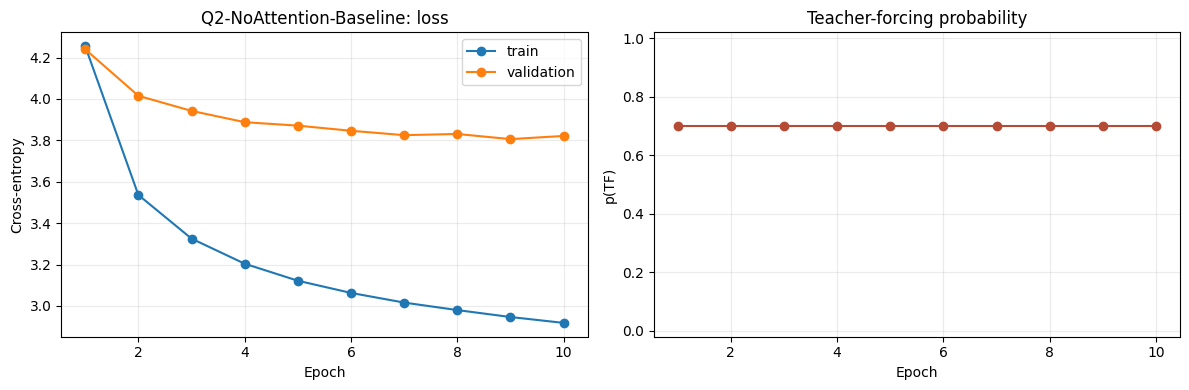

Completed Q2-NoAttention-Baseline: best validation loss=3.8058, test SacreBLEU=11.9787
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: उच्च <unk> के कारण <unk> के कारण <unk> <unk> <unk> <unk> <unk>
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> <unk> और <unk> <unk> <unk> में <unk> <unk> योजनाएं <unk>
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: मैं तो शायद ही नहीं <unk>
Final assignment checkpoint: /kaggle/working/q2_seq2seq_noattn.pt
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_noattention_baseline_

In [21]:
# Q2 TRAINING JOB 1/7: main no-attention baseline (10 epochs, pTF=0.7)
Q2_BASELINE_EPOCHS = Q2_MAIN_EPOCHS
seq2seq_noattn = build_plain_seq2seq_for_strategy()
hist_noattn = train_seq2seq(seq2seq_noattn, train_loader, val_loader, epochs=Q2_BASELINE_EPOCHS, lr=0.001, tf_ratio=0.7, tag="Q2-NoAttention-Baseline", resume=True)
_config, _action, _best_loss, _best_epoch = seq2seq_noattn._q2_run_metadata
q2_noattn_result = _q2_finalize_run(seq2seq_noattn, hist_noattn, _config, _action, _best_loss, _best_epoch, test_loader, "q2_seq2seq_noattn.pt")


####**Added Strategy Training Runs[10 marks]**

The following two new models use the same architecture, data loaders, optimizer, loss masking, and epoch count as the existing no-attention baseline. They are separate variables and do not replace or retrain `seq2seq_noattn`.


Before filling out the code below, familiarize yourself with these core components:


Strict Teacher Forcing ($p_{\text{TF}} = 1.0$): A baseline training setup where the decoder always consumes the ground-truth previous token as input at every step ($p_{\text{TF}} = 1.0$), ensuring highly stable initial convergence.


Scheduled Sampling Curriculum: A strategy that gradually exposes the decoder to its own discrete predictions during training by linearly decaying the teacher-forcing probability (e.g., from $1.00$ down to $0.25$), mitigating the exposure bias problem.

Linear Curriculum Schedule (linear_teacher_forcing_probability): Computes the dynamic probability threshold at each epoch to determine whether to feed the gold target token or the model's prior prediction.

Strategy Checkpoint Persistence (torch.save): Exports the trained encoder and decoder weights into independent target files (q2_seq2seq_teacher_forcing.pt and q2_seq2seq_scheduled_sampling.pt) for evaluation.

In [18]:
# --- Additional Q2 decoder-training strategy helper ---
STRATEGY_TRAINING_EPOCHS = Q2_MAIN_EPOCHS


def train_seq2seq_scheduled_sampling(model, train_loader, val_loader, epochs=STRATEGY_TRAINING_EPOCHS, lr=0.001, p_tf_start=1.0, p_tf_end=0.25, tag="Seq2Seq-ScheduledSampling", resume=True, device=None):
    """Train with a linearly decreasing probability of a gold decoder input."""
    config = _q2_config(tag, epochs, "scheduled_sampling", start=p_tf_start, end=p_tf_end)
    config["learning_rate"] = lr
    schedule = lambda epoch, total: linear_teacher_forcing_probability(epoch, total, p_tf_start, p_tf_end)
    history, action, best_loss, best_epoch = _q2_train_core(model, train_loader, val_loader, config, schedule, device=device)
    model._q2_run_metadata = (config, action, best_loss, best_epoch)
    return history


def _q2_run_scheduled_job(device):
    model = _q2_seeded_model()
    history = train_seq2seq_scheduled_sampling(
        model, _q2_fresh_train_loader(), val_loader,
        epochs=STRATEGY_TRAINING_EPOCHS, lr=0.001,
        p_tf_start=1.0, p_tf_end=0.25,
        tag="Q2-ScheduledSampling", resume=True, device=device,
    )
    config, action, best_loss, best_epoch = model._q2_run_metadata
    result = _q2_finalize_run(
        model, history, config, action, best_loss, best_epoch,
        test_loader, "q2_seq2seq_scheduled_sampling.pt", device=device,
    )
    return model, history, result


In [ ]:
# Q2 TRAINING JOB 2/7: strict teacher forcing (pTF=1.0)
seq2seq_teacher_forcing = build_plain_seq2seq_for_strategy()
hist_teacher_forcing = train_seq2seq(seq2seq_teacher_forcing, train_loader, val_loader, epochs=STRATEGY_TRAINING_EPOCHS, lr=0.001, tf_ratio=1.0, tag="Q2-TeacherForcing-Strict", resume=True)
_config, _action, _best_loss, _best_epoch = seq2seq_teacher_forcing._q2_run_metadata
q2_teacher_forcing_result = _q2_finalize_run(seq2seq_teacher_forcing, hist_teacher_forcing, _config, _action, _best_loss, _best_epoch, test_loader, "q2_seq2seq_teacher_forcing.pt")


In [ ]:
# Q2 TRAINING JOB 3/7: scheduled sampling (pTF linearly 1.0 -> 0.25)
seq2seq_scheduled_sampling = build_plain_seq2seq_for_strategy()
hist_scheduled_sampling = train_seq2seq_scheduled_sampling(seq2seq_scheduled_sampling, train_loader, val_loader, epochs=STRATEGY_TRAINING_EPOCHS, lr=0.001, p_tf_start=1.0, p_tf_end=0.25, tag="Q2-ScheduledSampling", resume=True)
_config, _action, _best_loss, _best_epoch = seq2seq_scheduled_sampling._q2_run_metadata
q2_scheduled_sampling_result = _q2_finalize_run(seq2seq_scheduled_sampling, hist_scheduled_sampling, _config, _action, _best_loss, _best_epoch, test_loader, "q2_seq2seq_scheduled_sampling.pt")


Launching independent protected Q2 jobs on cuda:0 and cuda:1
No prior artifact found for Q2-TeacherForcing-Strict; searched current output and []
QUESTION 2 TRAINING JOB: Q2-TeacherForcing-Strict on cuda:0
{
  "experiment_name": "Q2-TeacherForcing-Strict",
  "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell decoder; no attention",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "epochs": 10,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "strategy": "fixed",
  "teacher_forcing_ratio": 1.0,
  "p_tf_start": null,
  "p_tf_end": null,
  "reversed_source": false,
  "seed": 42
}
Resume status: started; completed=0/10; AMP=True; checkpoint=/kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
No prior artifact found for Q2-ScheduledSampling; searched current output and []
QUESTION 2 TRAINING JOB: Q2-ScheduledSampling on cuda:1
{
  "ex

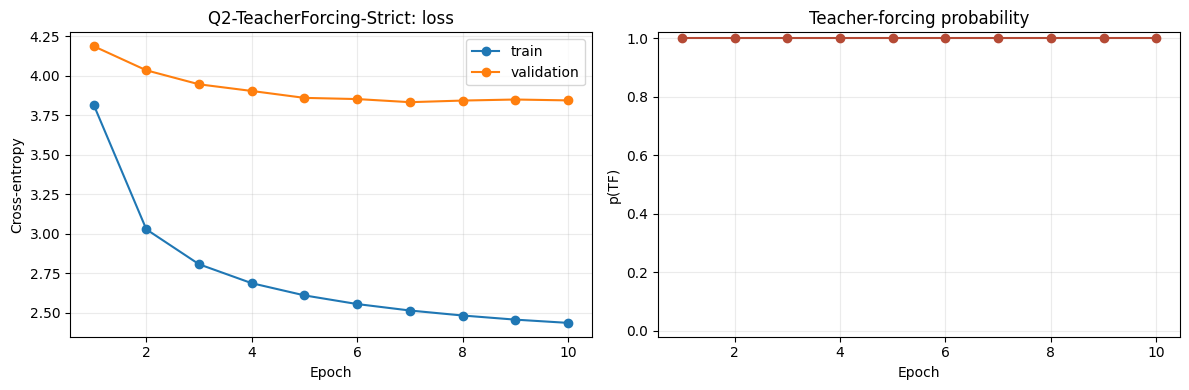

Completed Q2-TeacherForcing-Strict: best validation loss=3.8337, test SacreBLEU=8.5342
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: <unk> के बाद <unk> <unk> के <unk> को <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> के <unk> से पहले ही <unk> <unk> <unk> किया गया है।
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: मैं कुछ समझ में नहीं आया था।
Final assignment checkpoint: /kaggle/working/q2_seq2seq_teacher_forcin

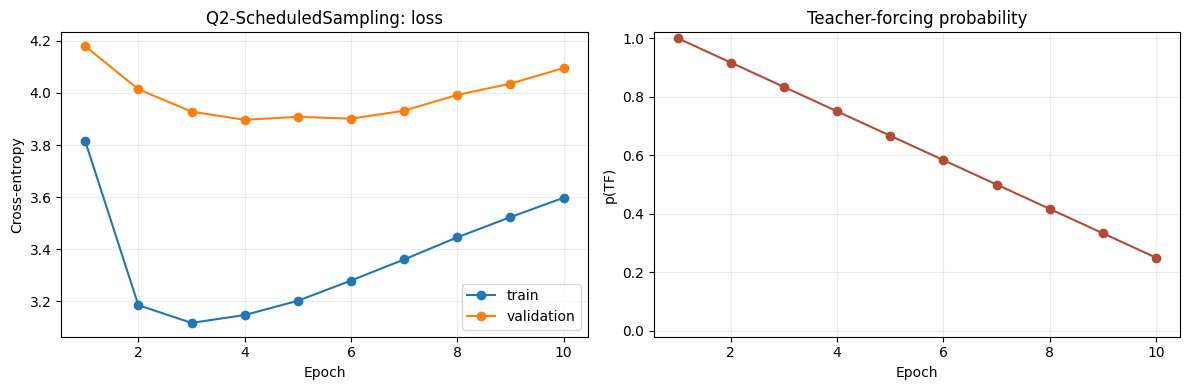

Completed Q2-ScheduledSampling: best validation loss=3.8969, test SacreBLEU=11.0056
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: स्कूल के स्कूल के कारण स्कूल के कारण <unk> स्कूल के <unk> को <unk>
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> <unk> <unk> <unk> <unk>
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: यह केवल एक ही बात नहीं थी।
Final assignment checkpoint: /kaggle/working/q2_seq2seq_scheduled_sampling.pt
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_scheduledsampling_bundle.

In [23]:
# Q2 DUAL-GPU PAIR 1/3 (recommended): strict teacher forcing + scheduled sampling
# Do not also run the two individual fallback cells above for these experiments.
(seq2seq_teacher_forcing, hist_teacher_forcing, q2_teacher_forcing_result), (seq2seq_scheduled_sampling, hist_scheduled_sampling, q2_scheduled_sampling_result) = _q2_run_pair(
    lambda: _q2_run_fixed_job("Q2-TeacherForcing-Strict", STRATEGY_TRAINING_EPOCHS, 1.0, "cuda:0", "q2_seq2seq_teacher_forcing.pt"),
    lambda: _q2_run_scheduled_job("cuda:1"),
)


####**Autoregressive Inference & SacreBLEU Evaluation[5 marks]**

Autoregressive Greedy Decoding

At test time, there are no ground-truth target tokens. We decode **autoregressively**:

1. Feed the encoder representation and start token `<sos>`.
2. Predict the most likely word using `argmax`.
3. Feed that predicted word back as the input for the next timestep.
4. Stop when `<eos>` is emitted or max length is reached.

Measuring Quality with BLEU

We evaluate translation quality using **SacreBLEU**, an industry-standard implementation of BLEU (Bilingual Evaluation Understudy) that computes n-gram precision against ground-truth references.

> **Reference:** Papineni et al. (2002) introduced BLEU in *[BLEU: a Method for Automatic Evaluation of Machine Translation](https://aclanthology.org/P02-1040.pdf)*.

Before filling out the code below, familiarize yourself with these core components:

Autoregressive Greedy Decoding: Generates target sequence tokens one-by-one by picking the token with the highest predicted probability (argmax) at each decoding step without relying on teacher forcing.

SacreBLEU Corpus Evaluation (sacrebleu.corpus_bleu): An industry-standard automated metric comparing hypothesis translation strings against gold-standard human reference sentences to calculate precision and brevity penalties.

Token String Reconstruction (ids_to_string): Filters out special control tokens (<pad>, <sos>, <eos>) and translates lists of numerical token IDs back into clean human-readable language strings.

In [23]:
# --- Autoregressive greedy decoding and SacreBLEU evaluation ---
@torch.no_grad()
def greedy_decode(model: nn.Module, src_tensor: torch.Tensor, max_len: int = MAX_LEN_HI - 1) -> torch.Tensor:
    """Decode a batch autoregressively, suppressing output after each EOS."""
    return _q2_greedy_decode(model, src_tensor, max_len=max_len)


def ids_to_string(token_ids: list[int], vocabulary: list[str]) -> str:
    """Convert token IDs to text while removing controls and stopping at EOS."""
    return _q2_ids_to_string(token_ids, vocabulary)


def evaluate_bleu_score(model: nn.Module, loader: DataLoader):
    """Return corpus SacreBLEU, hypotheses, and references."""
    bleu, hypotheses, references, _ = _q2_evaluate_bleu(model, loader)
    return bleu, hypotheses, references


seq2seq_noattn = globals().get("seq2seq_noattn") or _q2_load_completed_model("Q2-NoAttention-Baseline")
test_bleu, test_hyps, test_refs = evaluate_bleu_score(seq2seq_noattn, test_loader)
print(f"Main no-attention test SacreBLEU: {test_bleu:.4f}")
print("Three real baseline translations")
for index in range(min(3, len(test_hyps))):
    print(f"Reference {index + 1}: {test_refs[index]}")
    print(f"Hypothesis {index + 1}: {test_hyps[index]}")


Using current Q2 checkpoint: /kaggle/working/q2_artifacts/noattention_baseline/q2_noattention_baseline_resume.pt
Main no-attention test SacreBLEU: 11.9787
Three real baseline translations
Reference 1: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Hypothesis 1: उच्च <unk> के कारण <unk> के कारण <unk> <unk> <unk> <unk> <unk>
Reference 2: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Hypothesis 2: <unk> <unk> और <unk> <unk> <unk> में <unk> <unk> योजनाएं <unk>
Reference 3: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Hypothesis 3: मैं तो शायद ही नहीं <unk>


###**Error Analysis: Diagnosing the Information Bottleneck[5 Marks]**

Basic Seq2Seq models usually produce relatively low BLEU scores (often around 5–15). Why?

The Fixed Context Vector Bottleneck

The entire meaning of a 30-word sentence must be compressed into a single vector `dec_h0` of size `hidden_size`. As sentence length increases, early words get squashed and forgotten.

Let's prove this by bucketing test sentences by length ($\le 8$ words vs. $> 8$ words) and comparing their BLEU scores:

Before filling out the code below, familiarize yourself with these core components:

* **Length Bucketing**: Splits test set sentence indices based on source length thresholds ($\le 8$ words vs. $> 8$ words) to diagnose how sentence length impacts translation degradation.
* **Subset Evaluation**: Creates targeted dataset subsets and data loaders for short and long sentence groups to isolate performance drops.
* **BLEU Gap Quantification**: Computes and compares BLEU scores across buckets to quantify the severity of the encoder-decoder information bottleneck.

In [24]:
# --- Length-bucket evaluation and real qualitative failure candidates ---
seq2seq_noattn = globals().get("seq2seq_noattn") or _q2_load_completed_model("Q2-NoAttention-Baseline")
short_indices, long_indices = [], []
for index, src_text in enumerate(test_dataset.src_texts):
    (short_indices if len(tokenize_en(src_text)) <= 8 else long_indices).append(index)
short_loader = DataLoader(torch.utils.data.Subset(test_dataset, short_indices), batch_size=BATCH_SIZE, shuffle=False)
long_loader = DataLoader(torch.utils.data.Subset(test_dataset, long_indices), batch_size=BATCH_SIZE, shuffle=False)
bleu_short, _, _, short_examples = _q2_evaluate_bleu(seq2seq_noattn, short_loader)
bleu_long, _, _, long_examples = _q2_evaluate_bleu(seq2seq_noattn, long_loader)
bleu_drop = bleu_short - bleu_long
print("Short test sentences:", len(short_indices), "SacreBLEU:", f"{bleu_short:.4f}")
print("Long test sentences:", len(long_indices), "SacreBLEU:", f"{bleu_long:.4f}")
print("Exact short-minus-long BLEU difference:", f"{bleu_drop:+.4f}")
print("The measured sign and magnitude above determine whether this run supports the fixed-vector bottleneck claim.")
_q2_atomic_json_save({"short_count": len(short_indices), "long_count": len(long_indices), "short_bleu": bleu_short, "long_bleu": bleu_long, "short_minus_long": bleu_drop}, Q2_OUTPUT_DIR / "q2_length_bucket_analysis.json")

all_examples = short_examples + long_examples
repetition = sorted(all_examples, key=lambda x: max((x["hypothesis"].split().count(t) for t in set(x["hypothesis"].split())), default=0), reverse=True)[:1]
omission = sorted(all_examples, key=lambda x: len(x["hypothesis"].split()) / max(len(x["reference"].split()), 1))[:1]
mismatch = [x for x in all_examples if x["hypothesis"] != x["reference"]][:1]
for category, candidates in (("Repetition candidate", repetition), ("Missing-clause candidate", omission), ("Word-order/mismatch candidate", mismatch)):
    print("\n" + category)
    for example in candidates:
        print("SOURCE:", example["source"]); print("REFERENCE:", example["reference"]); print("HYPOTHESIS:", example["hypothesis"])
_q2_atomic_json_save({"repetition": repetition, "missing_clause": omission, "word_order_or_mismatch": mismatch}, Q2_OUTPUT_DIR / "q2_qualitative_error_candidates.json")


Short test sentences: 57 SacreBLEU: 17.9529
Long test sentences: 824 SacreBLEU: 11.8545
Exact short-minus-long BLEU difference: +6.0984
The measured sign and magnitude above determine whether this run supports the fixed-vector bottleneck claim.

Repetition candidate
SOURCE: <unk> two big men <unk> and <unk> <unk> heads together , said joseph <unk> , a <unk> at the open university and mozambique expert .
REFERENCE: "यह साथ साथ लड़ रहे दो बड़े आदमी ( <unk> <unk> उनके बारे में है," यूसुफ <unk> लंदन ओपन यूनिवर्सिटी में एक <unk> तथा <unk> विशेषज्ञ ने कहा.
HYPOTHESIS: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>

Missing-clause candidate
SOURCE: an alert has been issued .
REFERENCE: इसके बाद से <unk> जारी कर दिया गया है।
HYPOTHESIS: जारी <unk>

Word-order/mismatch candidate
SOURCE: <unk> about billion individual <unk> of corn .
REFERENCE: वह है मक्का की व्यक्तिगत <

**Common Qualitative Failure Modes**

When analyzing model output, you will notice three common types of errors:

1. **Degenerate Repetition:** The decoder gets stuck in a loop repeating the same phrase (*"वह वह वह"*).
2. **Grammatical Word-Order Shift:** English follows Subject-Verb-Object (SVO), while Hindi follows Subject-Object-Verb (SOV). Without attention mechanisms, verb placement often gets garbled.
3. **Dropping Clauses:** Long clauses at the beginning of English sentences vanish entirely from the Hindi output due to vector compression loss.

In Question 3, we will implement **Attention Mechanisms** to eliminate this information bottleneck!

###Advanced Analytical & Experimental Evaluation[Total = 50 Marks]

Answer all questions below using evidence, metrics, and observations directly from your Seq2Seq model runs, sweeps, and length-bucketing analyses.

**Logical & Reasoning**

* **L1. Layer Initialization Symmetry:[4 Marks]** We initialize *every* decoder layer's hidden state with the *same* bridged encoder vector (`hidden_states = [dec_h0] * num_layers`). Why might this initialization constraint limit what individual stacked layers can learn to specialize in, and how does it affect information flow across the 2-layer depth?


Initializing both decoder layers with the same bridged vector gives them identical source summaries before decoding begins. The layers still have different parameters and receive different inputs after the first update, but the lower layer cannot begin as a local/surface specialist while the upper layer begins as a more abstract specialist. The second layer only receives distinctions created by the first layer during decoding. A layer-specific bridge (one projection per layer) would let each depth receive a different view of the encoder and reduce this initialization bottleneck.


* **L2. Exposure Bias in Greedy Decoding:[4 Marks]** `teacher_forcing_ratio = 0.7` exposes the model to its own predictions 30% of the time during training. Using the term **exposure bias**, explain why this mismatch matters significantly more for a model evaluated using autoregressive greedy decoding than one evaluated purely under teacher forcing.


Exposure bias is the mismatch between training on mostly gold prefixes and inference on model-generated prefixes. With `teacher_forcing_ratio=0.7`, 30% of training transitions expose the decoder to its own tokens, but greedy decoding uses its own token at every transition. A wrong greedy token therefore changes the next input and can compound through the entire sentence. Teacher-forced evaluation does not suffer that same cascading distribution shift because each next step is conditioned on the correct previous token.


* **L3. Scheduled Sampling Trade-offs:[5 Marks]** Under the linear schedule, analyze the practical trade-off between decreasing $p_{\mathrm{TF}}$ too aggressively in early epochs versus keeping it near $1.0$ throughout training. Relate both scenarios directly to optimization stability and final inference robustness.



Reducing `p_TF` too quickly gives an immature decoder many incorrect prefixes, creating noisy targets-in-context and unstable optimization. Keeping it near `1.0` makes next-token learning easy and validation loss under gold prefixes strong, but leaves the model poorly prepared to recover from its own errors at inference. A gradual schedule trades some optimization stability for robustness by first learning a useful conditional language model and then increasingly practicing on self-generated contexts.


Analytical (Requires Your Run's Data & Evaluation Metrics)

* **A1. Information Bottleneck & Length Bucketing:[5 Marks]** Report your short-vs-long BLEU split  (splitting at $\le 8$ vs. $> 8$ source words). Does this quantitative gap confirm the fixed context-vector information-bottleneck argument? Quantify the exact BLEU drop.


Before filling out the code below, familiarize yourself with these core components:

* **Model Evaluation Utility (`print_categorization_samples`)**: Inspects model generations against target reference sentences to categorize common failure modes (e.g., repetition loops, word-order shifts, clause omissions).
* **Autoregressive Generation**: Uses greedy decoding to output hypothesis token IDs.
* **String Conversion & Inspection**: Decodes token IDs back to human-readable strings to qualitative assess translation quality.

In [25]:
# A1: Data-driven information-bottleneck answer (requires the length-bucket cell above).
length_path = Q2_OUTPUT_DIR / "q2_length_bucket_analysis.json"
if not length_path.is_file(): raise FileNotFoundError("Run the length-bucket evaluation cell first.")
length_result = json.loads(length_path.read_text(encoding="utf-8"))
drop = length_result["short_minus_long"]
verdict = "supports" if drop > 0 else "does not support"
print(f"Short BLEU={length_result['short_bleu']:.4f}; long BLEU={length_result['long_bleu']:.4f}; exact drop={drop:+.4f}.")
print(f"Therefore, this executed run {verdict} the fixed-context bottleneck argument by the sign of the measured gap.")


Short BLEU=17.9529; long BLEU=11.8545; exact drop=+6.0984.
Therefore, this executed run supports the fixed-context bottleneck argument by the sign of the measured gap.


* **A2. Word-Order Divergence (SVO vs. SOV):[6 marks]** Find 3 test examples where your no-attention model's hypothesis exhibits incorrect word order relative to the target reference (due to English SVO vs. Hindi SOV divergence). Describe specifically how the lack of dynamic alignment caused the verb or object placement to fail.


In [26]:
# A2: Select real candidates with inversions among Hindi tokens shared by reference and hypothesis.
seq2seq_noattn = globals().get("seq2seq_noattn") or _q2_load_completed_model("Q2-NoAttention-Baseline")
_, _, _, candidates = _q2_evaluate_bleu(seq2seq_noattn, test_loader)


def shared_token_inversions(reference, hypothesis):
    ref = reference.split(); hyp = hypothesis.split(); common = list(dict.fromkeys(token for token in ref if token in hyp))
    ref_pos = {token: ref.index(token) for token in common}; hyp_pos = {token: hyp.index(token) for token in common}
    return [(a, b) for i, a in enumerate(common) for b in common[i + 1:] if (ref_pos[a] - ref_pos[b]) * (hyp_pos[a] - hyp_pos[b]) < 0]


ranked = sorted(((len(shared_token_inversions(x["reference"], x["hypothesis"])), x) for x in candidates), key=lambda item: item[0], reverse=True)
selected = [(count, example) for count, example in ranked if count > 0][:3]
if len(selected) < 3:
    used = {id(example) for _, example in selected}
    selected.extend((0, example) for example in candidates if example["hypothesis"] != example["reference"] and id(example) not in used)
    selected = selected[:3]
for index, (inversions, example) in enumerate(selected, 1):
    print(f"A2 example {index}; shared-token order inversions={inversions}")
    print("SOURCE:", example["source"]); print("REFERENCE:", example["reference"]); print("HYPOTHESIS:", example["hypothesis"])
    print("Interpretation: inspect the displayed verb/object placement; the fixed vector provides no timestep-specific source alignment.")
_q2_atomic_json_save([{"inversions": count, **example} for count, example in selected], Q2_OUTPUT_DIR / "q2_a2_word_order_examples.json")


A2 example 1; shared-token order inversions=16
SOURCE: a million grant was awarded to them to make it possible for them to pursue their research and experiments .
REFERENCE: बतौर पुरस्कार राशि उन्हें 1 मिलियन डॉलर की सहायता राशि दी गई है, ताकि वे अपने रिसर्च और प्रयोगों को आगे बढ़ा सकें।
HYPOTHESIS: उनके प्रयोगों को उनके लिए प्रयोग किया ताकि उन्हें <unk> करोड़ सके और उनकी सहायता की <unk>
Interpretation: inspect the displayed verb/object placement; the fixed vector provides no timestep-specific source alignment.
A2 example 2; shared-token order inversions=14
SOURCE: he said it is also important to give children religious instruction along with worldly education for the unity and integrity of the country .
REFERENCE: उन्होंने कहा कि देश की एकता व अखंडता के लिए बच्चों को सांसारिक शिक्षा सहित धार्मिक शिक्षा देना भी जरूरी है।
HYPOTHESIS: उन्होंने कहा कि शिक्षा और बच्चों को भी देश के बच्चों के लिए और प्रेम के लिए भी <unk> किया गया है।
Interpretation: inspect the displayed verb/object placeme

* **A3. Loss-Metric Discrepancy:[6 marks]** Compare `hist_teacher_forcing` and `hist_scheduled_sampling`, and report greedy-decoding BLEU for `seq2seq_teacher_forcing` and `seq2seq_scheduled_sampling`. Does a lower teacher-forced validation loss necessarily imply a higher autoregressive BLEU score? Support your answer with your empirical results.



In [27]:
# A3: Compare stored strict-teacher-forcing and scheduled-sampling results without retraining.
strict_history = _q2_load_json("Q2-TeacherForcing-Strict", "history")
scheduled_history = _q2_load_json("Q2-ScheduledSampling", "history")
strict_result = _q2_load_json("Q2-TeacherForcing-Strict", "result")
scheduled_result = _q2_load_json("Q2-ScheduledSampling", "result")
print(f"Strict TF: final validation loss={strict_history['val_loss'][-1]:.4f}, greedy test BLEU={strict_result['test_bleu']:.4f}")
print(f"Scheduled: final validation loss={scheduled_history['val_loss'][-1]:.4f}, greedy test BLEU={scheduled_result['test_bleu']:.4f}")
lower_loss = "strict teacher forcing" if strict_history['val_loss'][-1] < scheduled_history['val_loss'][-1] else "scheduled sampling"
higher_bleu = "strict teacher forcing" if strict_result['test_bleu'] > scheduled_result['test_bleu'] else "scheduled sampling"
print("Lower teacher-forced validation loss:", lower_loss)
print("Higher autoregressive BLEU:", higher_bleu)
print("A lower teacher-forced loss necessarily predicts higher BLEU:", lower_loss == higher_bleu)


Using current Q2 checkpoint: /kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/scheduledsampling/q2_scheduledsampling_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/scheduledsampling/q2_scheduledsampling_resume.pt
Strict TF: final validation loss=3.8450, greedy test BLEU=8.5342
Scheduled: final validation loss=4.0957, greedy test BLEU=11.0056
Lower teacher-forced validation loss: strict teacher forcing
Higher autoregressive BLEU: scheduled sampling
A lower teacher-forced loss necessarily predicts higher BLEU: False


Experimental (Requires Code Execution & Observations)

* **E1. Teacher-Forcing Ratio Sweep:[6 marks]** Train separate Seq2Seq models with `teacher_forcing_ratio` set to $\{1.0, 0.7, 0.3\}$. Plot validation loss and test BLEU against the ratio, and discuss which setting yielded the best balance between training stability and greedy generation quality.


Before filling out the code below, familiarize yourself with these core components:

* **Teacher-Forcing Ratios (`tf_ratios`)**: Evaluates multiple ratio settings ($\in \{1.0, 0.7, 0.3\}$) to examine their impact on validation loss and autoregressive generation performance.
* **Model Retraining & Evaluation**: Instantiates, trains, and tests fresh encoder-decoder translation models across each ratio setting.
* **Comparative Plotting**: Plots validation loss curves and test BLEU score variations to determine the optimal trade-off between guided training stability and free-running inference accuracy.

In [19]:
# --- E1 setup: three independent fixed-ratio runs; training occurs in the next three cells ---
E1_TRAINING_EPOCHS = Q2_EXPERIMENT_EPOCHS
print("E1 ratios: 1.0, 0.7, 0.3; each has an independent checkpoint and training cell.")


E1 ratios: 1.0, 0.7, 0.3; each has an independent checkpoint and training cell.


In [ ]:
# Q2 TRAINING JOB 4/7: E1 teacher-forcing ratio=1.0
q2_e1_tf100_model = build_plain_seq2seq_for_strategy()
q2_e1_tf100_history = train_seq2seq(q2_e1_tf100_model, train_loader, val_loader, epochs=E1_TRAINING_EPOCHS, lr=0.001, tf_ratio=1.0, tag="Q2-E1-TF100", resume=True)
_config, _action, _best_loss, _best_epoch = q2_e1_tf100_model._q2_run_metadata
q2_e1_tf100_result = _q2_finalize_run(q2_e1_tf100_model, q2_e1_tf100_history, _config, _action, _best_loss, _best_epoch, test_loader)


In [ ]:
# Q2 TRAINING JOB 5/7: E1 teacher-forcing ratio=0.7
q2_e1_tf070_model = build_plain_seq2seq_for_strategy()
q2_e1_tf070_history = train_seq2seq(q2_e1_tf070_model, train_loader, val_loader, epochs=E1_TRAINING_EPOCHS, lr=0.001, tf_ratio=0.7, tag="Q2-E1-TF070", resume=True)
_config, _action, _best_loss, _best_epoch = q2_e1_tf070_model._q2_run_metadata
q2_e1_tf070_result = _q2_finalize_run(q2_e1_tf070_model, q2_e1_tf070_history, _config, _action, _best_loss, _best_epoch, test_loader)


Launching independent protected Q2 jobs on cuda:0 and cuda:1
No prior artifact found for Q2-E1-TF100; searched current output and []
No prior artifact found for Q2-E1-TF070; searched current output and []
QUESTION 2 TRAINING JOB: Q2-E1-TF100 on cuda:0
{
  "experiment_name": "Q2-E1-TF100",
  "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell decoder; no attention",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "strategy": "fixed",
  "teacher_forcing_ratio": 1.0,
  "p_tf_start": null,
  "p_tf_end": null,
  "reversed_source": false,
  "seed": 42
}
Resume status: started; completed=0/4; AMP=True; checkpoint=/kaggle/working/q2_artifacts/e1_tf100/q2_e1_tf100_resume.pt
QUESTION 2 TRAINING JOB: Q2-E1-TF070 on cuda:1
{
  "experiment_name": "Q2-E1-TF070",
  "architecture": "2-layer bidirectional nn.GRU encode

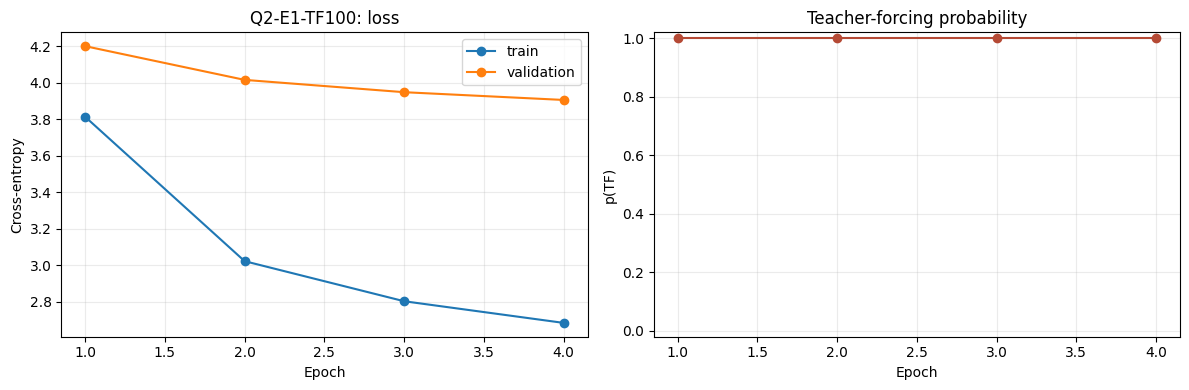

Completed Q2-E1-TF100: best validation loss=3.9050, test SacreBLEU=10.1932
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: उच्च वित्तीय <unk> के कारण <unk> के लिए वित्तीय <unk>
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> के बीच <unk> के बारे में <unk> जो <unk> हो रहा था।
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: मुझे कुछ भी नहीं मालूम कि वह मुझे कुछ भी नहीं था।
Final assignment checkpoint: not required for this ablation
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_e1_tf100_bundle.zip
Q

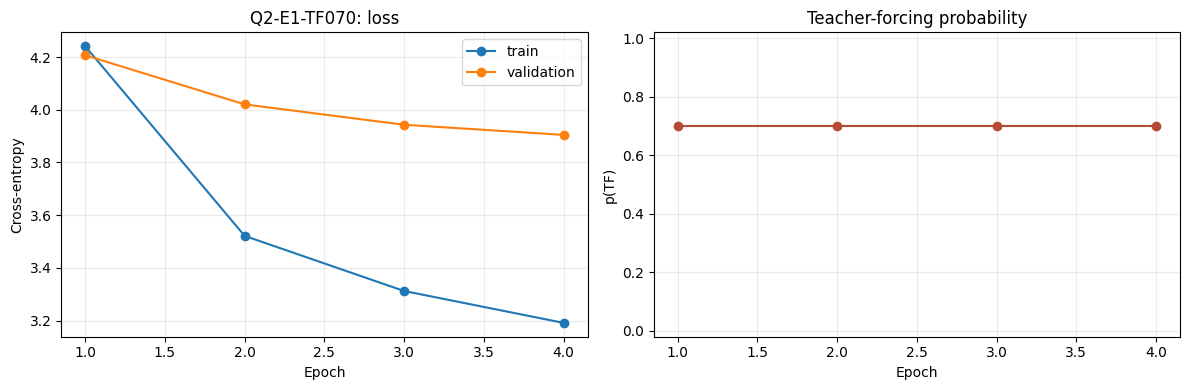

Completed Q2-E1-TF070: best validation loss=3.9045, test SacreBLEU=13.3340
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: उच्च <unk> के बाद <unk> के बाद उच्च <unk> के बाद <unk> <unk> हो गया.
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> <unk> <unk> में <unk> <unk> चुके हैं।
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: मैं केवल कुछ ही ही नहीं <unk>
Final assignment checkpoint: not required for this ablation
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_e1_tf070_bundle.zip
Both GPU jobs

In [20]:
# Q2 DUAL-GPU PAIR 2/3 (recommended): E1 pTF=1.0 + E1 pTF=0.7
# Run the E1 setup cell first; do not also run individual E1 cells 1.0/0.7.
(q2_e1_tf100_model, q2_e1_tf100_history, q2_e1_tf100_result), (q2_e1_tf070_model, q2_e1_tf070_history, q2_e1_tf070_result) = _q2_run_pair(
    lambda: _q2_run_fixed_job("Q2-E1-TF100", E1_TRAINING_EPOCHS, 1.0, "cuda:0"),
    lambda: _q2_run_fixed_job("Q2-E1-TF070", E1_TRAINING_EPOCHS, 0.7, "cuda:1"),
)


In [ ]:
# Q2 TRAINING JOB 6/7: E1 teacher-forcing ratio=0.3
q2_e1_tf030_model = build_plain_seq2seq_for_strategy()
q2_e1_tf030_history = train_seq2seq(q2_e1_tf030_model, train_loader, val_loader, epochs=E1_TRAINING_EPOCHS, lr=0.001, tf_ratio=0.3, tag="Q2-E1-TF030", resume=True)
_config, _action, _best_loss, _best_epoch = q2_e1_tf030_model._q2_run_metadata
q2_e1_tf030_result = _q2_finalize_run(q2_e1_tf030_model, q2_e1_tf030_history, _config, _action, _best_loss, _best_epoch, test_loader)


Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf100/q2_e1_tf100_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf070/q2_e1_tf070_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf030/q2_e1_tf030_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf100/q2_e1_tf100_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf070/q2_e1_tf070_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e1_tf030/q2_e1_tf030_resume.pt
| Teacher-forcing ratio | Final validation loss | Test SacreBLEU |
|---:|---:|---:|
| 1.0 | 3.9050 | 10.1932 |
| 0.7 | 3.9045 | 13.3340 |
| 0.3 | 4.1318 | 12.0322 |


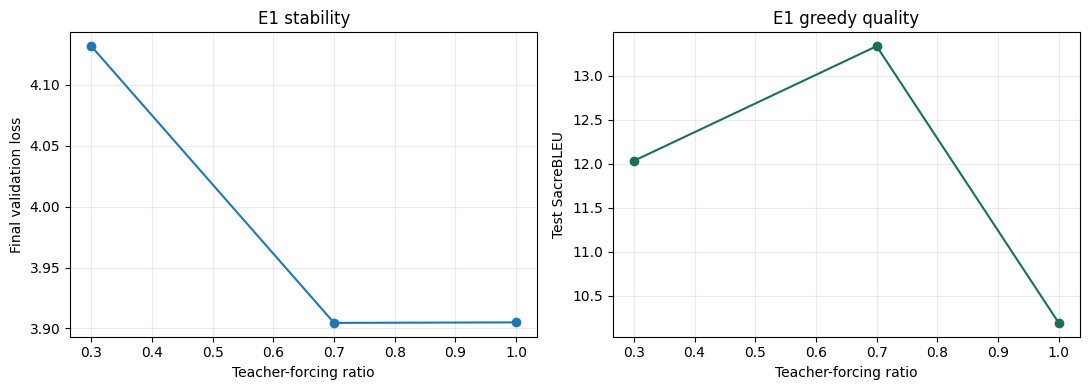

Best greedy BLEU in the executed sweep: ratio=0.7, BLEU=13.3340.


In [28]:
# E1 analysis: load all three completed runs without retraining.
ratios = [1.0, 0.7, 0.3]; names = ["Q2-E1-TF100", "Q2-E1-TF070", "Q2-E1-TF030"]
histories_e1 = [_q2_load_json(name, "history") for name in names]
results_e1 = [_q2_load_json(name, "result") for name in names]
val_losses = [history["val_loss"][-1] for history in histories_e1]
bleu_scores = [result["test_bleu"] for result in results_e1]
print("| Teacher-forcing ratio | Final validation loss | Test SacreBLEU |")
print("|---:|---:|---:|")
for ratio, loss, bleu in zip(ratios, val_losses, bleu_scores): print(f"| {ratio:.1f} | {loss:.4f} | {bleu:.4f} |")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ratios, val_losses, marker="o"); axes[0].set(xlabel="Teacher-forcing ratio", ylabel="Final validation loss", title="E1 stability")
axes[1].plot(ratios, bleu_scores, marker="o", color="#1b6f5a"); axes[1].set(xlabel="Teacher-forcing ratio", ylabel="Test SacreBLEU", title="E1 greedy quality")
for axis in axes: axis.grid(alpha=0.25)
fig.tight_layout(); path = Q2_OUTPUT_DIR / "q2_e1_teacher_forcing_sweep.png"; fig.savefig(path, dpi=180, bbox_inches="tight"); plt.show()
best_index = int(np.argmax(bleu_scores))
print(f"Best greedy BLEU in the executed sweep: ratio={ratios[best_index]:.1f}, BLEU={bleu_scores[best_index]:.4f}.")
_q2_atomic_json_save({str(r): {"final_val_loss": l, "test_bleu": b} for r, l, b in zip(ratios, val_losses, bleu_scores)}, Q2_OUTPUT_DIR / "q2_e1_teacher_forcing_sweep.json")


* **E2. Source-Sequence Reversal Experiment:[7 marks]** Reverse the token order of every English sentence fed to the encoder (`TranslationDatasetReversed`) following Sutskever et al. (2014) and retrain the model from scratch. Given that your encoder is *already* bidirectional, did you expect—and actually observe—a significant BLEU performance gain? Explain why.


Before filling out the code below, familiarize yourself with these core components:

* **Source-Token Reversal (`TranslationDatasetReversed`)**: Inherits from `TranslationDataset` but reverses the token order of the source English sentence while leaving the target Hindi sequence untouched, following Sutskever et al. (2014).
* **Short-Term Dependency Improvement**: Reversing source sentences creates short-term dependencies between the beginning of the source and target sequences, easing optimization for standard unidirectional RNNs.
* **Bidirectional Encoder Context**: Retrains a fresh encoder-decoder model on the reversed data loaders to evaluate whether source reversal still provides tangible gains when the encoder is *already* bidirectional.

In [21]:
# --- E2 setup: reverse only non-PAD English source tokens ---
class TranslationDatasetReversed(TranslationDataset):
    def __getitem__(self, idx):
        src, tgt_in, tgt_out = super().__getitem__(idx)
        length = int(src.ne(stoi_en[PAD]).sum())
        reversed_src = torch.cat([src[:length].flip(0), src[length:]])
        return reversed_src, tgt_in, tgt_out


reversed_train_dataset = TranslationDatasetReversed(mt_raw["train"], limit=N_DEBUG)
reversed_val_dataset = TranslationDatasetReversed(mt_raw["validation"], limit=N_DEBUG)
reversed_test_dataset = TranslationDatasetReversed(mt_raw["test"], limit=N_DEBUG)
reversed_train_loader = DataLoader(reversed_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
reversed_val_loader = DataLoader(reversed_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
reversed_test_loader = DataLoader(reversed_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
print("E2 reversed-source loaders ready; PAD remains right-aligned.")


E2 reversed-source loaders ready; PAD remains right-aligned.


Launching independent protected Q2 jobs on cuda:0 and cuda:1
No prior artifact found for Q2-E1-TF030; searched current output and []
QUESTION 2 TRAINING JOB: Q2-E1-TF030 on cuda:0
{
  "experiment_name": "Q2-E1-TF030",
  "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell decoder; no attention",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "strategy": "fixed",
  "teacher_forcing_ratio": 0.3,
  "p_tf_start": null,
  "p_tf_end": null,
  "reversed_source": false,
  "seed": 42
}
Resume status: started; completed=0/4; AMP=True; checkpoint=/kaggle/working/q2_artifacts/e1_tf030/q2_e1_tf030_resume.pt
No prior artifact found for Q2-E2-ReversedSource; searched current output and []
QUESTION 2 TRAINING JOB: Q2-E2-ReversedSource on cuda:1
{
  "experiment_name": "Q2-E2-ReversedSource",
  "architecture": "2-layer 

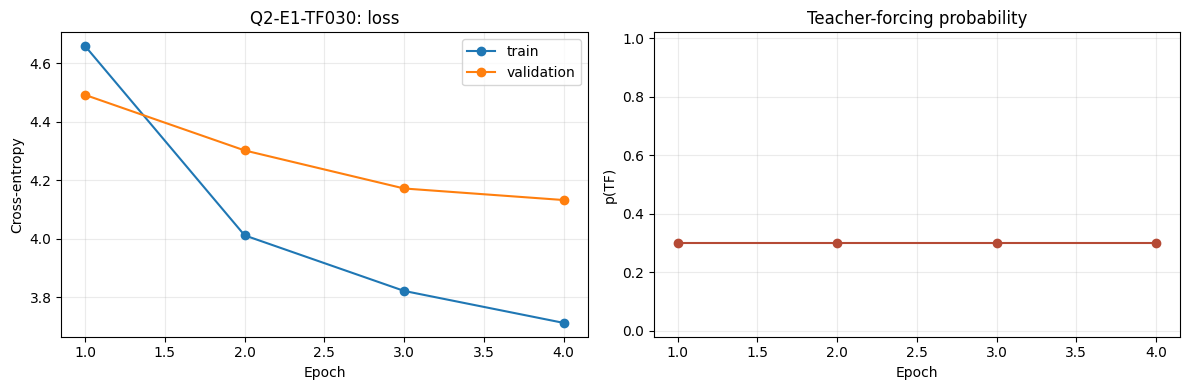

Completed Q2-E1-TF030: best validation loss=4.1318, test SacreBLEU=12.0322
Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: वित्तीय <unk> के कारण <unk> के <unk> <unk> <unk> <unk> <unk>
Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> <unk> <unk> <unk> <unk> में <unk> <unk>
Example 3 SOURCE: it was simply nothing i could have imagined .
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: मैं ऐसा नहीं था कि मैं कुछ नहीं
Final assignment checkpoint: not required for this ablation
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_e1_tf030_bundle.zip
Q2-E2-ReversedSou

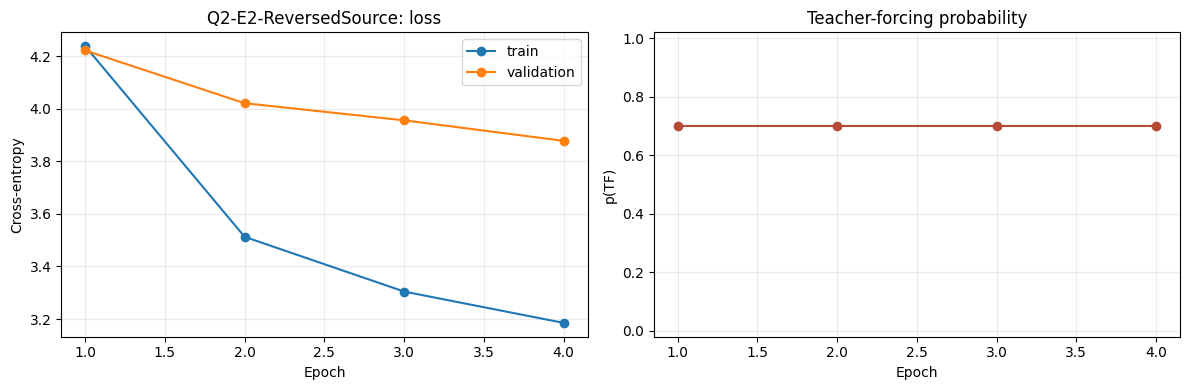

Completed Q2-E2-ReversedSource: best validation loss=3.8783, test SacreBLEU=12.4642
Example 1 SOURCE: . school high after out drop to had <unk> constraints financial to due
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: वित्तीय <unk> के कारण <unk> के कारण <unk> के कारण <unk> <unk> हो गया।
Example 2 SOURCE: . plans submitted already have who <unk> the among were <unk> and delta
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> <unk> <unk> <unk> योजनाएं तैयार की योजनाएं तैयार की गई थी।
Example 3 SOURCE: . imagined have could i nothing simply was it
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: यह मेरा कुछ ही <unk> नहीं था।
Final assignment checkpoint: not required for this ablation
Artifact saved in Kaggle output; download manually from Files/Output: /kaggle/working/q2_e2

In [22]:
# Q2 DUAL-GPU PAIR 3/3 (recommended): E1 pTF=0.3 + E2 reversed source
# Run both E1 and E2 setup cells first; do not also run the corresponding individual cells.
(q2_e1_tf030_model, q2_e1_tf030_history, q2_e1_tf030_result), (q2_reversed_model, q2_reversed_history, q2_reversed_result) = _q2_run_pair(
    lambda: _q2_run_fixed_job("Q2-E1-TF030", E1_TRAINING_EPOCHS, 0.3, "cuda:0"),
    lambda: _q2_run_fixed_job(
        "Q2-E2-ReversedSource", Q2_EXPERIMENT_EPOCHS, 0.7, "cuda:1",
        train_data=_q2_make_loader(reversed_train_dataset, BATCH_SIZE, True, seed=SEED),
        val_data=reversed_val_loader, test_data=reversed_test_loader, reversed_source=True,
    ),
)


In [ ]:
# Q2 TRAINING JOB 7/7: E2 reversed English source order
q2_reversed_model = build_plain_seq2seq_for_strategy()
q2_reversed_config = _q2_config("Q2-E2-ReversedSource", Q2_EXPERIMENT_EPOCHS, "fixed", tf_ratio=0.7, reversed_source=True)
q2_reversed_history, _action, _best_loss, _best_epoch = _q2_train_core(q2_reversed_model, reversed_train_loader, reversed_val_loader, q2_reversed_config, lambda _epoch, _total: 0.7)
q2_reversed_result = _q2_finalize_run(q2_reversed_model, q2_reversed_history, q2_reversed_config, _action, _best_loss, _best_epoch, reversed_test_loader)


In [29]:
# E2 analysis: compare stored real BLEU values without retraining.
baseline_result = _q2_load_json("Q2-NoAttention-Baseline", "result")
reversed_result = _q2_load_json("Q2-E2-ReversedSource", "result")
delta = reversed_result["test_bleu"] - baseline_result["test_bleu"]
print(f"Normal-source BLEU: {baseline_result['test_bleu']:.4f}")
print(f"Reversed-source BLEU: {reversed_result['test_bleu']:.4f}")
print(f"Reversed minus normal: {delta:+.4f}")
print("Expectation: reversal should help less than in a unidirectional encoder because this encoder already reads both directions.")
print("Observed significant gain:", abs(delta) >= 1.0)
_q2_atomic_json_save({"normal_bleu": baseline_result["test_bleu"], "reversed_bleu": reversed_result["test_bleu"], "delta": delta}, Q2_OUTPUT_DIR / "q2_e2_reversal_analysis.json")


Using current Q2 checkpoint: /kaggle/working/q2_artifacts/noattention_baseline/q2_noattention_baseline_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/e2_reversedsource/q2_e2_reversedsource_resume.pt
Normal-source BLEU: 11.9787
Reversed-source BLEU: 12.4642
Reversed minus normal: +0.4856
Expectation: reversal should help less than in a unidirectional encoder because this encoder already reads both directions.
Observed significant gain: False


* **E3. Strategy Comparison & Generation Inspection:[7 marks]** Run the strict-teacher-forcing and scheduled-sampling training routines. Plot their training/validation loss curves alongside the scheduled model's $p_{\mathrm{TF}}$ decay curve by epoch, and compare their greedy-decoding BLEU across at least five qualitative translation examples.

Before filling out the code below, familiarize yourself with these core components:

* **Training Strategies (`seq2seq_teacher_forcing` vs. `seq2seq_scheduled_sampling`)**: Compares strict teacher forcing ($p_{\mathrm{TF}} = 1.0$) against scheduled sampling with a linear decay curriculum ($p_{\mathrm{TF}} \text{ from } 1.0 \text{ to } 0.25$).
* **Loss & Curriculum Visualization**: Plots training/validation loss curves alongside the scheduled model's $p_{\mathrm{TF}}$ decay curve across epochs.
* **Qualitative Generation Inspection**: Compares greedy-decoding translation outputs against target references across at least five qualitative test samples to assess exposure bias recovery.

Using current Q2 checkpoint: /kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/scheduledsampling/q2_scheduledsampling_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/scheduledsampling/q2_scheduledsampling_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/teacherforcing_strict/q2_teacherforcing_strict_resume.pt
Using current Q2 checkpoint: /kaggle/working/q2_artifacts/scheduledsampling/q2_scheduledsampling_resume.pt


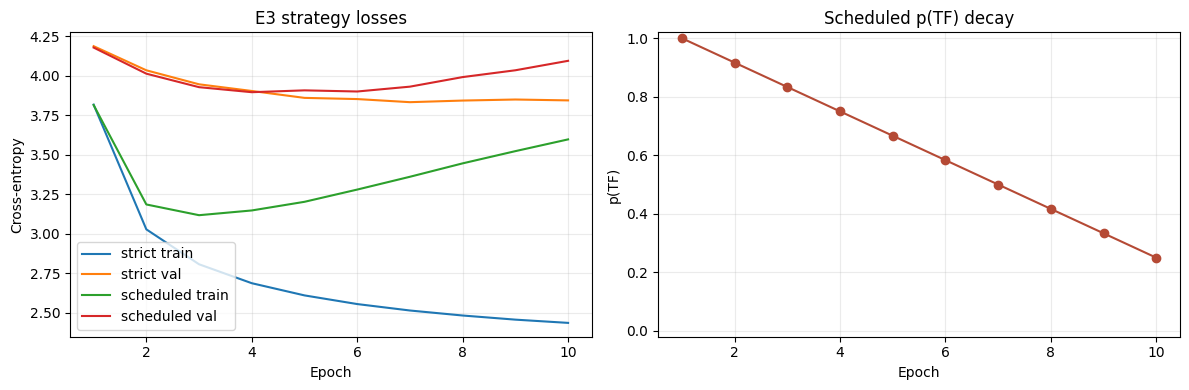

Strict TF greedy BLEU=8.5342; scheduled greedy BLEU=11.0056

Example 1 SOURCE: due to financial constraints <unk> had to drop out after high school .
REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
STRICT: <unk> के बाद <unk> <unk> के <unk> को <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
SCHEDULED: स्कूल के स्कूल के कारण स्कूल के कारण <unk> स्कूल के <unk> को <unk>

Example 2 SOURCE: delta and <unk> were among the <unk> who have already submitted plans .
REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
STRICT: <unk> और <unk> के <unk> से पहले ही <unk> <unk> <unk> किया गया है।
SCHEDULED: <unk> और <unk> <unk> <unk> <unk> <unk> <unk>

Example 3 SOURCE: it was simply nothing i could have imagined .
REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
STRICT: मैं कुछ समझ में नहीं आया था।
SCHEDULED: यह केवल एक ही बात नही

In [30]:
# E3: restore strict/scheduled models, plot strategies, and print five real comparisons.
strict_model = _q2_load_completed_model("Q2-TeacherForcing-Strict")
scheduled_model = _q2_load_completed_model("Q2-ScheduledSampling")
strict_history = _q2_load_json("Q2-TeacherForcing-Strict", "history")
scheduled_history = _q2_load_json("Q2-ScheduledSampling", "history")
strict_result = _q2_load_json("Q2-TeacherForcing-Strict", "result")
scheduled_result = _q2_load_json("Q2-ScheduledSampling", "result")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(strict_history["epoch"], strict_history["train_loss"], label="strict train")
axes[0].plot(strict_history["epoch"], strict_history["val_loss"], label="strict val")
axes[0].plot(scheduled_history["epoch"], scheduled_history["train_loss"], label="scheduled train")
axes[0].plot(scheduled_history["epoch"], scheduled_history["val_loss"], label="scheduled val")
axes[0].set(title="E3 strategy losses", xlabel="Epoch", ylabel="Cross-entropy"); axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(scheduled_history["epoch"], scheduled_history["teacher_forcing_probability"], marker="o", color="#b54a35")
axes[1].set(title="Scheduled p(TF) decay", xlabel="Epoch", ylabel="p(TF)", ylim=(-0.02, 1.02)); axes[1].grid(alpha=0.25)
fig.tight_layout(); e3_plot = Q2_OUTPUT_DIR / "q2_e3_strategy_comparison.png"; fig.savefig(e3_plot, dpi=180, bbox_inches="tight"); plt.show()
print(f"Strict TF greedy BLEU={strict_result['test_bleu']:.4f}; scheduled greedy BLEU={scheduled_result['test_bleu']:.4f}")
_, _, _, strict_examples = _q2_evaluate_bleu(strict_model, DataLoader(torch.utils.data.Subset(test_dataset, range(min(5, len(test_dataset)))), batch_size=5))
_, _, _, scheduled_examples = _q2_evaluate_bleu(scheduled_model, DataLoader(torch.utils.data.Subset(test_dataset, range(min(5, len(test_dataset)))), batch_size=5))
comparison = []
for index, (strict, scheduled) in enumerate(zip(strict_examples, scheduled_examples), 1):
    row = {"source": strict["source"], "reference": strict["reference"], "strict": strict["hypothesis"], "scheduled": scheduled["hypothesis"]}; comparison.append(row)
    print(f"\nExample {index} SOURCE: {row['source']}"); print("REFERENCE:", row["reference"]); print("STRICT:", row["strict"]); print("SCHEDULED:", row["scheduled"])
_q2_atomic_json_save(comparison, Q2_OUTPUT_DIR / "q2_e3_five_translation_comparisons.json")


In [31]:
# Final Question 2 Protection Archive (non-training)
required_q2 = [
    "q2_seq2seq_noattn.pt", "q2_seq2seq_teacher_forcing.pt",
    "q2_seq2seq_scheduled_sampling.pt", "vocab_en.json", "vocab_hi.json",
    "q2_progress_manifest.json",
]
missing_q2 = [name for name in required_q2 if not (_Q2_RUNTIME_ROOT / name).is_file()]
required_experiments = [
    "Q2-NoAttention-Baseline", "Q2-TeacherForcing-Strict", "Q2-ScheduledSampling",
    "Q2-E1-TF100", "Q2-E1-TF070", "Q2-E1-TF030", "Q2-E2-ReversedSource",
]
progress = _q2_load_progress()
incomplete = [name for name in required_experiments if progress.get(name, {}).get("status") != "complete"]
required_analysis = [
    "q2_length_bucket_analysis.json", "q2_qualitative_error_candidates.json",
    "q2_a2_word_order_examples.json", "q2_e1_teacher_forcing_sweep.json",
    "q2_e1_teacher_forcing_sweep.png", "q2_e2_reversal_analysis.json",
    "q2_e3_strategy_comparison.png", "q2_e3_five_translation_comparisons.json",
]
missing_analysis = [name for name in required_analysis if not (Q2_OUTPUT_DIR / name).is_file()]
if missing_q2 or incomplete or missing_analysis:
    raise FileNotFoundError(
        f"Q2 is not fully protected. Missing files={missing_q2}; "
        f"incomplete experiments={incomplete}; missing analyses={missing_analysis}"
    )

q2_archive = _Q2_RUNTIME_ROOT / "q2_all_artifacts.zip"
temporary_archive = Path(str(q2_archive) + ".tmp")
with ZipFile(temporary_archive, "w", ZIP_DEFLATED) as zip_file:
    for name in required_q2:
        zip_file.write(_Q2_RUNTIME_ROOT / name, arcname=name)
    for artifact in sorted(Q2_OUTPUT_DIR.rglob("*")):
        if artifact.is_file():
            zip_file.write(artifact, arcname=str(Path("q2_artifacts") / artifact.relative_to(Q2_OUTPUT_DIR)))
os.replace(temporary_archive, q2_archive)
print("Question 2 protected at:", q2_archive)
print("Artifact saved in Kaggle output; download manually from Files/Output.")
print("Later Question 4 must still produce q2_seq2seq_rnn_noattn.pt and q2_seq2seq_lstm_noattn.pt.")


Question 2 protected at: /kaggle/working/q2_all_artifacts.zip
Artifact saved in Kaggle output; download manually from Files/Output.
Later Question 4 must still produce q2_seq2seq_rnn_noattn.pt and q2_seq2seq_lstm_noattn.pt.


## Q2 Kaggle Session / Resume Instructions (Optimized Dual-GPU Plan)

### Fresh Runtime and Baseline Recovery

1. Run cell **9** (global setup) and cell **46** (only the Q1 `GRUCell` definition). Do not run any Q1 training/evaluation cells.
2. Run Q2 cells **116 through 152** in order. The dataset is encoded and cached once; the sanity cell must pass.
3. Keep `q2_noattention_baseline_bundle.zip` in persistent Kaggle Output or attach it as a Kaggle input. Cell **116** auto-discovers the exact bundle in either location; alternatively set `Q2_PREVIOUS_ARTIFACT_DIR` explicitly.
4. Run baseline cell **153**. It accepts the safe 50-to-10 target-budget migration, restores epoch 10, reprints the complete history, skips retraining, loads the epoch-9 best state, evaluates BLEU, and writes `q2_seq2seq_noattn.pt` plus a completed bundle.

### Recommended Two-GPU Training

The paired cells require two visible CUDA devices and keep independent models, optimizers, histories, resume checkpoints, results, and ZIP bundles. Do not run their corresponding individual fallback cells as well.

1. Run strategy-helper cell **156**, then paired strategy cell **159** to train strict teacher forcing on `cuda:0` and scheduled sampling on `cuda:1`, both for 10 epochs.
2. Run E1 setup cell **182**, then paired E1 cell **185** to train ratios `1.0` and `0.7` concurrently.
3. Run E2 setup cell **190**, then paired final-experiment cell **191** to train E1 ratio `0.3` and E2 reversed source concurrently.
4. If only one GPU is available, use the existing individual cells instead: strict **157**, scheduled **158**, E1 **183/184/186**, and E2 **192**.

Each job checkpoints independently at improvements, every five epochs, and completion. Download each printed `q2_<experiment>_bundle.zip`. To resume, attach the bundle, rerun setup, and rerun the same paired or individual cell; completed jobs skip while incomplete jobs continue.

After training, run the existing baseline, A1-A3, E1, E2, and E3 analysis cells in notebook order, followed by the final Question 2 protection archive. The exact required Q2 checkpoints remain `q2_seq2seq_noattn.pt`, `q2_seq2seq_teacher_forcing.pt`, and `q2_seq2seq_scheduled_sampling.pt`; Question 4 later produces the RNN/LSTM no-attention checkpoints.


# **Question 3 — Attention Mechanisms from Scratch[Total = 140 marks]**

3. Implement the attention (try both dot-product and badhnau) in the encoder-decoder model above from scratch and train it, analyze the improvement in the performance, compare with the model above step and do error analysis


In [ ]:
# --- Question 3 Kaggle runtime and restart-safe artifact configuration ---
import gc
import shutil
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZIP_STORED, ZipFile

_Q3_RUNTIME_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
Q3_OUTPUT_DIR = _Q3_RUNTIME_ROOT / "q3_artifacts"
Q3_ANALYSIS_DIR = Q3_OUTPUT_DIR / "analysis"
Q3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
Q3_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
Q3_PROGRESS_PATH = _Q3_RUNTIME_ROOT / "q3_progress_manifest.json"
Q3_PREVIOUS_ARTIFACT_DIR = None
Q3_CHECKPOINT_EVERY = 1  # Four-epoch runs are protected after every epoch.

_Q3_PROGRESS_LOCK = threading.Lock()
_Q3_PLOT_LOCK = threading.Lock()
_Q3_MODEL_BUILD_LOCK = threading.Lock()

_Q3_VARIANTS = {
    "dot": {
        "experiment_name": "Q3-DotAttention",
        "prefix": "q3_dot",
        "deliverable": "q3_seq2seq_dot.pt",
        "bundle_name": "q3_dot_model_bundle.zip",
    },
    "bah": {
        "experiment_name": "Q3-BahdanauAttention",
        "prefix": "q3_bah",
        "deliverable": "q3_seq2seq_bah.pt",
        "bundle_name": "q3_bahdanau_model_bundle.zip",
    },
}


def _q3_variant(value: str) -> str:
    normalized = str(value).lower()
    if "dot" in normalized:
        return "dot"
    if "bah" in normalized or "add" in normalized:
        return "bah"
    raise ValueError(f"Unknown Q3 attention variant: {value}")


def _q3_paths(variant: str) -> dict:
    variant = _q3_variant(variant)
    metadata = _Q3_VARIANTS[variant]
    directory = Q3_OUTPUT_DIR / variant
    directory.mkdir(parents=True, exist_ok=True)
    prefix = metadata["prefix"]
    return {
        **metadata,
        "variant": variant,
        "dir": directory,
        "resume": directory / f"{prefix}_resume.pt",
        "best": directory / f"{prefix}_best_state.pt",
        "model": directory / f"{prefix}_encoder_decoder.pt",
        "history": directory / f"{prefix}_history.json",
        "config": directory / f"{prefix}_config.json",
        "result": directory / f"{prefix}_result.json",
        "predictions": directory / f"{prefix}_test_predictions.json",
        "examples": directory / f"{prefix}_examples.json",
        "plot": directory / f"{prefix}_training.png",
        "readme": directory / f"{prefix}_README.txt",
        "bundle": _Q3_RUNTIME_ROOT / metadata["bundle_name"],
        "deliverable_path": _Q3_RUNTIME_ROOT / metadata["deliverable"],
    }


def _q3_atomic_torch_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)


def _q3_atomic_json_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    with temporary.open("w", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2, ensure_ascii=False)
    os.replace(temporary, path)


def _q3_torch_load(path: Path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def _q3_state_cpu(module: nn.Module) -> dict:
    return {name: value.detach().cpu().clone() for name, value in module.state_dict().items()}


def _q3_to_cpu(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: _q3_to_cpu(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_q3_to_cpu(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_q3_to_cpu(item) for item in value)
    return value


def _q3_load_progress() -> dict:
    if not Q3_PROGRESS_PATH.is_file():
        return {}
    with Q3_PROGRESS_PATH.open("r", encoding="utf-8") as handle:
        return json.load(handle)


def _q3_update_progress(experiment_name: str, **values):
    with _Q3_PROGRESS_LOCK:
        progress = _q3_load_progress()
        progress[experiment_name] = {**progress.get(experiment_name, {}), **values}
        _q3_atomic_json_save(progress, Q3_PROGRESS_PATH)


def _q3_restore_roots() -> list[Path]:
    roots = []
    if Q3_PREVIOUS_ARTIFACT_DIR is not None:
        explicit = Path(Q3_PREVIOUS_ARTIFACT_DIR)
        if not explicit.is_dir():
            raise FileNotFoundError(f"Q3_PREVIOUS_ARTIFACT_DIR does not exist: {explicit}")
        roots.append(explicit)
    else:
        kaggle_input = Path("/kaggle/input")
        if kaggle_input.is_dir():
            roots.extend(path for path in kaggle_input.iterdir() if path.is_dir())
    return roots


def _q3_restore_experiment(variant: str):
    """Restore exactly one matching Q3 checkpoint/bundle, never an ambiguous one."""
    paths = _q3_paths(variant)
    if paths["resume"].is_file():
        print(f"Using current Q3 checkpoint: {paths['resume']}")
        return paths["resume"]

    candidate_names = {
        paths["bundle"].name,
        "q3_training_artifacts.zip",
        "q3_all_artifacts.zip",
    }
    candidates = []
    for name in candidate_names:
        current = _Q3_RUNTIME_ROOT / name
        if current.is_file():
            candidates.append(current.resolve())
    for root in _q3_restore_roots():
        for name in candidate_names:
            candidates.extend(path.resolve() for path in root.rglob(name))
        candidates.extend(path.resolve() for path in root.rglob(paths["resume"].name))
    candidates = list(dict.fromkeys(candidates))
    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple restore candidates for {paths['experiment_name']}: {candidates}. "
            "Set Q3_PREVIOUS_ARTIFACT_DIR to a directory containing only the intended bundle."
        )
    if not candidates:
        print(f"No prior Q3 artifact found for {paths['experiment_name']}; starting normally.")
        return None

    candidate = candidates[0]
    if candidate.suffix.lower() == ".zip":
        expected_destinations = {
            paths[key].name: paths[key]
            for key in ("resume", "best", "model", "history", "config", "result", "predictions", "examples", "plot", "readme")
        }
        expected_destinations[paths["deliverable_path"].name] = paths["deliverable_path"]
        with ZipFile(candidate) as archive:
            for member in archive.infolist():
                basename = Path(member.filename).name
                destination = expected_destinations.get(basename)
                if member.is_dir() or destination is None:
                    continue
                destination.parent.mkdir(parents=True, exist_ok=True)
                temporary = Path(str(destination) + ".tmp")
                with archive.open(member) as source_handle, temporary.open("wb") as target_handle:
                    shutil.copyfileobj(source_handle, target_handle)
                os.replace(temporary, destination)
    else:
        shutil.copy2(candidate, paths["resume"])
    if not paths["resume"].is_file() and not paths["deliverable_path"].is_file():
        raise FileNotFoundError(f"Restore candidate did not contain {paths['resume'].name}: {candidate}")
    print(f"Restored {paths['experiment_name']} from: {candidate}")
    return paths["resume"] if paths["resume"].is_file() else paths["deliverable_path"]


def _q3_bundle_experiment(variant: str) -> Path:
    paths = _q3_paths(variant)
    temporary = Path(str(paths["bundle"]) + ".tmp")
    with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
        for artifact in sorted(paths["dir"].glob("*")):
            if artifact.is_file() and artifact != paths["model"]:
                archive.write(
                    artifact, arcname=artifact.name,
                    compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                )
        for artifact in (paths["deliverable_path"], Q3_PROGRESS_PATH,
                         _Q3_RUNTIME_ROOT / "vocab_en.json", _Q3_RUNTIME_ROOT / "vocab_hi.json"):
            if artifact.is_file():
                archive.write(
                    artifact, arcname=artifact.name,
                    compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                )
    os.replace(temporary, paths["bundle"])
    return paths["bundle"]


def _q3_restore_analysis_files():
    if any(Q3_ANALYSIS_DIR.iterdir()):
        return
    candidate_names = {"q3_analysis_artifacts.zip", "q3_all_artifacts.zip"}
    candidates = []
    for name in candidate_names:
        current = _Q3_RUNTIME_ROOT / name
        if current.is_file():
            candidates.append(current.resolve())
    for root in _q3_restore_roots():
        for name in candidate_names:
            candidates.extend(path.resolve() for path in root.rglob(name))
    candidates = list(dict.fromkeys(candidates))
    if len(candidates) > 1:
        raise RuntimeError(f"Multiple Q3 analysis restore candidates: {candidates}")
    if not candidates:
        return
    with ZipFile(candidates[0]) as archive:
        for member in archive.infolist():
            normalized = member.filename.replace("\\", "/")
            is_analysis_file = (
                "q3_analysis/" in normalized
                or "q3_artifacts/analysis/" in normalized
            )
            if member.is_dir() or not is_analysis_file:
                continue
            destination = Q3_ANALYSIS_DIR / Path(normalized).name
            temporary = Path(str(destination) + ".tmp")
            with archive.open(member) as source_handle, temporary.open("wb") as target_handle:
                shutil.copyfileobj(source_handle, target_handle)
            os.replace(temporary, destination)
    print(f"Restored Q3 analysis artifacts from: {candidates[0]}")


def _q3_refresh_analysis_bundle() -> Path:
    bundle = _Q3_RUNTIME_ROOT / "q3_analysis_artifacts.zip"
    temporary = Path(str(bundle) + ".tmp")
    with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
        for artifact in sorted(Q3_ANALYSIS_DIR.glob("*")):
            if artifact.is_file():
                archive.write(artifact, arcname=str(Path("q3_analysis") / artifact.name))
    os.replace(temporary, bundle)
    print("Updated restart-safe Q3 analysis bundle:", bundle)
    return bundle


def _q3_load_json(variant: str, key: str):
    paths = _q3_paths(variant)
    _q3_restore_experiment(variant)
    path = paths[key]
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.name}; restore {paths['bundle'].name} first.")
    with path.open("r", encoding="utf-8") as handle:
        return json.load(handle)


def _q3_load_q2_json(filename: str):
    """Read one measured Q2 JSON from current output or one unambiguous Q2 ZIP."""
    current_matches = list((_Q3_RUNTIME_ROOT / "q2_artifacts").rglob(filename))
    if len(current_matches) > 1:
        raise RuntimeError(f"Multiple current Q2 files named {filename}: {current_matches}")
    if current_matches:
        return json.loads(current_matches[0].read_text(encoding="utf-8"))

    archive_names = {"q2_all_artifacts.zip", "q2_noattention_baseline_bundle.zip"}
    archives = []
    for name in archive_names:
        path = _Q3_RUNTIME_ROOT / name
        if path.is_file():
            archives.append(path.resolve())
    for root in _q3_restore_roots():
        for name in archive_names:
            archives.extend(path.resolve() for path in root.rglob(name))
    archives = list(dict.fromkeys(archives))
    containing = []
    for archive_path in archives:
        with ZipFile(archive_path) as archive:
            members = [name for name in archive.namelist() if Path(name).name == filename]
            if members:
                containing.append((archive_path, members))
    if len(containing) != 1 or len(containing[0][1]) != 1:
        raise FileNotFoundError(
            f"Expected one Q2 source for {filename}; found {containing}. "
            "Attach only q2_all_artifacts.zip (recommended) when current Q2 output is unavailable."
        )
    archive_path, members = containing[0]
    with ZipFile(archive_path) as archive:
        return json.loads(archive.read(members[0]).decode("utf-8"))


print("Question 3 artifact directory:", Q3_OUTPUT_DIR)
print("Visible CUDA devices:", torch.cuda.device_count())
for _q3_gpu_index in range(torch.cuda.device_count()):
    print(f"  cuda:{_q3_gpu_index}: {torch.cuda.get_device_name(_q3_gpu_index)}")
print("Current output is preferred. Set Q3_PREVIOUS_ARTIFACT_DIR only when restoring mounted bundles.")



In Question 2, we built a standard Seq2Seq model where the encoder compressed the entire source sentence into a single, fixed-size vector $C$. In above section, we saw the main weakness of that design: as sentence length increases, translation quality collapses. A single vector simply cannot hold all the details of a long sentence.

In this section, we solve that bottleneck by introducing **Attention**.

Instead of forcing the encoder to compress everything into one vector, we allow the decoder to look back at **all encoder hidden states** at every step of generation. At each step $t$, the model computes a fresh **context vector** $c_t$ by taking a weighted sum of all encoder outputs $h_1, h_2, \ldots, h_{T_x}$.

```
Encoder Outputs:    h_1        h_2        h_3        h_4
                     \          |          |          /
                      \         |          |         /
                       v        v          v        v
Scores & Softmax:   [a_{t,1}] [a_{t,2}] [a_{t,3}] [a_{t,4}]  <-- Weights depend on s_{t-1}
                       \        |          |        /
                        v       v          v       v
Context Vector:                     c_t                      <-- Fresh context at step t!
                                     |
Decoder State:                    s_{t-1}

```

Mathematically, at each decoding step $t$:

1. **Score:** Compare the previous decoder hidden state $s_{t-1}$ with each encoder output $h_j$:

$$e_{t,j} = \text{score}(s_{t-1}, h_j)$$


2. **Normalize (Softmax):** Turn raw scores into attention probabilities $\alpha_{t,j}$ that sum to 1:

$$\alpha_{t,j} = \frac{\exp(e_{t,j})}{\sum_{k=1}^{T_x} \exp(e_{t,k})}$$


3. **Blend:** Compute the context vector $c_t$ as a weighted combination of encoder outputs:

$$c_t = \sum_{j=1}^{T_x} \alpha_{t,j} h_j$$



We will implement two distinct scoring functions ($\text{score}$): **Dot-Product (Multiplicative) Attention** and **Bahdanau (Additive) Attention**.

####Dot-Product (Multiplicative) Attention[20 marks]

**What Is It ?**

Introduced by [Luong et al. (2015)](https://arxiv.org/abs/1508.04025), **Dot-Product Attention** is the simplest way to compute alignment scores. It calculates the dot product between the decoder state $s_{t-1}$ and each encoder output $h_j$:

$$e_{t,j} = s_{t-1}^\top h_j$$

**Why Do We Need It?**

Because our encoder is bidirectional (output dimension $2 \cdot H$) and our decoder is unidirectional (hidden dimension $H$), their vector dimensions do not match. To fix this, we project the decoder query into the encoder space using a single linear layer $W_{\text{proj}}$ before taking the dot product:

$$q = W_{\text{proj}}(s_{t-1}) \in \mathbb{R}^{2H}, \quad e_{t,j} = q^\top h_j$$



Before filling out the code below, familiarize yourself with these core components:

* **`DotProductAttention` (`nn.Module`)**: Implements multiplicative attention (Luong et al., 2015), aligning decoder hidden queries with encoder output keys.
* **Linear Projection Layer (`self.proj`)**: Projects the unidirectional decoder hidden dimension ($H$) to match the bidirectional encoder hidden dimension ($2H$).
* **Query Projection (`q`)**: Transformed decoder query vector used to measure alignment against encoder states.
* **Score Calculation (`scores`)**: Computes the raw dot-product similarity between the projected query and all encoder output states (`q @ enc_outputs.transpose(1, 2)`).
* **Padding Masking (`mask`)**: Optionally masks out padding token positions by setting their scores to negative infinity (`-1e9` or `-inf`), ensuring softmax assigns them zero attention weight.
* **Softmax Normalization (`weights`)**: Converts raw masked scores into probability distributions over the source sequence.
* **Context Vector (`context`)**: Computes the final context representation as a weighted sum of encoder outputs (`weights.unsqueeze(1) @ enc_outputs`).

In [19]:
# --- Dot-Product (Multiplicative) Attention ---
class DotProductAttention(nn.Module):
    """Luong-style attention with a learned decoder-to-encoder projection."""

    def __init__(self, dec_hidden: int, enc_hidden: int):
        super().__init__()
        self.proj = nn.Linear(dec_hidden, enc_hidden)

    def forward(self, dec_hidden: torch.Tensor, enc_outputs: torch.Tensor,
                mask: torch.Tensor = None):
        query = self.proj(dec_hidden).unsqueeze(1)
        scores = torch.bmm(query, enc_outputs.transpose(1, 2)).squeeze(1)
        if mask is not None:
            scores = scores.masked_fill(~mask.bool(), torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), enc_outputs).squeeze(1)
        return context, weights


**Limitations of Dot-Product Attention**

Dot-product attention assumes that after a linear projection, query vectors and key vectors live in a comparable space where a simple inner product measures similarity. It cannot capture more complex, non-linear interactions between encoder and decoder states.

### Bahdanau (Additive) Attention[15 Marks]

### What Is It and Why Do We Need It?

Introduced in the paper by [Bahdanau et al. (2014)](https://arxiv.org/abs/1409.0473), **Additive Attention** uses a small single-layer feedforward neural network to calculate alignment scores:

$$e_{t,j} = v_a^\top \tanh\left(W_a s_{t-1} + U_a h_j\right)$$

Where:

* $W_a \in \mathbb{R}^{A \times H_{\text{dec}}}$ projects the decoder query into an attention space of dimension $A$.
* $U_a \in \mathbb{R}^{A \times H_{\text{enc}}}$ projects the encoder key into the same attention space $A$.
* $v_a \in \mathbb{R}^{A \times 1}$ collapses the non-linear combination into a scalar score.

Instead of assuming queries and keys live in similar spaces, Bahdanau attention learns a dedicated mapping. This flexibility allows it to learn complex non-linear relationships, though at the cost of adding a few more parameters.

Before filling out the code below, familiarize yourself with these core components:

* **`BahdanauAttention` (`nn.Module`)**: Implements additive attention (Bahdanau et al., 2014), which computes non-linear alignment scores using a feedforward network with a single hidden layer.
* **Projections (`self.W_a`, `self.U_a`)**: Linear layers projecting the decoder state and encoder outputs into a shared intermediate attention dimension (`attn_dim`).
* **Energy Vector (`self.v_a`)**: A vector layer that combines the activated sum to yield scalar alignment scores.
* **Non-Linearity (`tanh`)**: Applies a hyperbolic tangent activation on the combined projections, capturing complex interactions between queries and keys.
* **Masking & Normalization**: Applies padding masks and softmax normalization identically to Dot-Product Attention for seamless drop-in compatibility.

In [20]:
# --- Bahdanau (Additive) Attention ---
class BahdanauAttention(nn.Module):
    """Additive attention with a learned nonlinear alignment energy."""

    def __init__(self, dec_hidden: int, enc_hidden: int, attn_dim: int = 128):
        super().__init__()
        self.W_a = nn.Linear(dec_hidden, attn_dim, bias=False)
        self.U_a = nn.Linear(enc_hidden, attn_dim, bias=False)
        self.v_a = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, dec_hidden: torch.Tensor, enc_outputs: torch.Tensor,
                mask: torch.Tensor = None):
        query = self.W_a(dec_hidden).unsqueeze(1)
        keys = self.U_a(enc_outputs)
        energy = self.v_a(torch.tanh(query + keys))
        scores = energy.squeeze(-1)
        if mask is not None:
            scores = scores.masked_fill(~mask.bool(), torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), enc_outputs).squeeze(1)
        return context, weights


####Attention-Augmented Decoder[10 marks]

Now we modify our step-wise decoder to use attention. At each step $t$:

1. Pass the top-layer hidden state $s_{t-1}$ and all encoder outputs $h_j$ into the attention module to get context $c_t$.
2. Concatenate the target token embedding with $c_t$ as input to the GRU cells.
3. Use **input feeding** ([Luong et al., 2015](https://arxiv.org/abs/1508.04025)): concatenate the new hidden state $s_t$ with $c_t$ before projecting to vocabulary logits.

Before filling out the code below, familiarize yourself with these core components:

* **`AttnDecoderStep` (`nn.Module`)**: A step-wise unidirectional decoder that incorporates dynamic attention mechanisms at every generation step.
* **Context Vector Generation**: Evaluates the attention module using the previous top-layer hidden state $s_{t-1}$ and all encoder outputs $h_j$ to produce $c_t$.
* **Target Embedding & Context Concatenation**: Combines the embedded target token with the context vector (`[token_embedding ; context_vector]`) as the input for the bottom GRU cell.
* **Input Feeding (`Luong et al., 2015`)**: Concatenates the new hidden state $s_t$ with the context vector $c_t$ before projecting to vocabulary logits, providing the output layer with explicit historical awareness of past attention decisions.

In [21]:
# --- Attention-Augmented Decoder Step ---
class AttnDecoderStep(nn.Module):
    """Two-layer scratch-GRU decoder with dynamic attention and input feeding."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 enc_hidden: int, attention_module: nn.Module, num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.attention = attention_module
        self.cells = nn.ModuleList([
            GRUCell(emb_dim + enc_hidden if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size + enc_hidden, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list[torch.Tensor],
                    enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        """Advance the recurrent stack and return the pre-projection features."""
        token_embedding = self.embedding(tok)
        context, weights = self.attention(hidden_states[-1], enc_outputs, mask)
        layer_input = torch.cat([token_embedding, context], dim=-1)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(layer_input, hidden_states[layer])
            new_states.append(hidden)
            layer_input = hidden
        output_features = torch.cat([new_states[-1], context], dim=-1)
        return new_states, weights, output_features

    def forward(self, tok: torch.Tensor, hidden_states: list[torch.Tensor],
                enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        new_states, weights, output_features = self.hidden_step(
            tok, hidden_states, enc_outputs, mask
        )
        logits = self.out(output_features)
        return logits, new_states, weights


#### Attention Seq2Seq Wrapper & Model Training[5 marks]

Why Source Padding Masking Is Essential

When a batch contains sentences of different lengths, shorter sentences are padded with `<pad>` tokens. Without a mask, the softmax function assigns positive attention weights to these `<pad>` tokens.

By applying `mask = (src != stoi_en[PAD])`, we force the pre-softmax scores of padding positions to $-\infty$, ensuring that `softmax(-∞) = 0`. Padding tokens receive **zero attention weight**.

Before filling out the code below, familiarize yourself with these core components:

Attention-Augmented Seq2Seq (Seq2SeqAttn): Integrates an encoder, step-wise attention decoder, and source padding mask into a unified translation architecture that computes dynamic context vectors at every generation step.

Source Padding Masking (mask): Creates a binary mask (1 for real tokens, 0 for <pad>) to ensure that padding tokens receive absolute zero attention weights during softmax alignment.

Input Feeding & Teacher Forcing: Dynamically blends gold-standard target tokens with model predictions during training based on a configurable teacher_forcing_ratio.

Attention Heatmap Extraction (greedy_decode): Autoregressively generates predictions while capturing and stacking attention weight matrices across timesteps for soft-alignment visualization.

In [19]:
# --- Attention Seq2Seq Wrapper ---
class Seq2SeqAttn(nn.Module):
    """Encoder-decoder wrapper with masked attention and autoregressive decoding."""

    def __init__(self, encoder: Encoder, decoder: AttnDecoderStep, num_layers: int = 2):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.num_layers = num_layers
        self._tf_generator = torch.Generator(device="cpu")
        self._tf_generator.manual_seed(SEED)

    def forward(self, src: torch.Tensor, tgt_in: torch.Tensor,
                teacher_forcing_ratio: float = 0.7, return_attn: bool = False):
        enc_outputs, dec_h0 = self.encoder(src)
        mask = src.ne(stoi_en[PAD])
        _, tgt_len = tgt_in.shape
        hidden_states = [dec_h0.clone() for _ in range(self.num_layers)]
        output_features, attention_steps = [], []
        input_token = tgt_in[:, 0]

        if teacher_forcing_ratio >= 1.0:
            forcing_draws = [0.0] * max(tgt_len - 1, 0)
        elif teacher_forcing_ratio <= 0.0:
            forcing_draws = [1.0] * max(tgt_len - 1, 0)
        else:
            forcing_draws = torch.rand(
                max(tgt_len - 1, 0), generator=self._tf_generator
            ).tolist()

        for timestep in range(tgt_len):
            hidden_states, weights, features = self.decoder.hidden_step(
                input_token, hidden_states, enc_outputs, mask
            )
            output_features.append(features)
            if return_attn:
                attention_steps.append(weights)
            if timestep + 1 < tgt_len:
                use_teacher = forcing_draws[timestep] < teacher_forcing_ratio
                input_token = (
                    tgt_in[:, timestep + 1]
                    if use_teacher
                    else self.decoder.out(features).argmax(dim=-1)
                )

        logits = self.decoder.out(torch.stack(output_features, dim=1))
        if return_attn:
            return logits, torch.stack(attention_steps, dim=1)
        return logits

    @torch.no_grad()
    def greedy_decode(self, src_tensor: torch.Tensor, max_len: int = MAX_LEN_HI,
                      return_attn: bool = True):
        self.eval()
        run_device = next(self.parameters()).device
        src_tensor = src_tensor.to(run_device, non_blocking=True)
        enc_outputs, dec_h0 = self.encoder(src_tensor)
        mask = src_tensor.ne(stoi_en[PAD])
        hidden_states = [dec_h0.clone() for _ in range(self.num_layers)]
        input_token = torch.full(
            (src_tensor.size(0),), stoi_hi[SOS], dtype=torch.long, device=run_device
        )
        finished = torch.zeros(src_tensor.size(0), dtype=torch.bool, device=run_device)
        output_tokens, attention_steps = [], []

        for _ in range(max_len):
            logits, hidden_states, weights = self.decoder(
                input_token, hidden_states, enc_outputs, mask
            )
            next_token = logits.argmax(dim=-1)
            next_token = torch.where(
                finished, torch.full_like(next_token, stoi_hi[PAD]), next_token
            )
            output_tokens.append(next_token.cpu())
            if return_attn:
                attention_steps.append(weights.cpu())
            finished |= next_token.eq(stoi_hi[EOS])
            input_token = next_token
            if bool(finished.all()):
                break

        tokens = (
            torch.stack(output_tokens, dim=1)
            if output_tokens
            else torch.empty(src_tensor.size(0), 0, dtype=torch.long)
        )
        if not return_attn:
            return tokens, None
        attention = (
            torch.stack(attention_steps, dim=1)
            if attention_steps
            else torch.empty(src_tensor.size(0), 0, src_tensor.size(1))
        )
        return tokens, attention


In [20]:
# --- Question 3 device-aware training, checkpointing, restoration, and packaging ---
Q3_EMB_DIM = 200
Q3_HIDDEN_SIZE = 256
Q3_ENCODER_HIDDEN = 2 * Q3_HIDDEN_SIZE
Q3_NUM_LAYERS = 2
Q3_TRAINING_EPOCHS = 4
Q3_TEACHER_FORCING_RATIO = 0.7
Q3_LEARNING_RATE = 0.001

_q3_atomic_json_save(stoi_en, _Q3_RUNTIME_ROOT / "vocab_en.json")
_q3_atomic_json_save(stoi_hi, _Q3_RUNTIME_ROOT / "vocab_hi.json")


def _q3_make_model(variant: str):
    variant = _q3_variant(variant)
    with _Q3_MODEL_BUILD_LOCK:
        rng_state = torch.get_rng_state()
        torch.manual_seed(SEED)
        encoder = Encoder(len(itos_en), Q3_EMB_DIM, Q3_HIDDEN_SIZE, num_layers=Q3_NUM_LAYERS)
        attention = (
            DotProductAttention(Q3_HIDDEN_SIZE, Q3_ENCODER_HIDDEN)
            if variant == "dot"
            else BahdanauAttention(Q3_HIDDEN_SIZE, Q3_ENCODER_HIDDEN, attn_dim=128)
        )
        decoder = AttnDecoderStep(
            len(itos_hi), Q3_EMB_DIM, Q3_HIDDEN_SIZE, Q3_ENCODER_HIDDEN,
            attention, num_layers=Q3_NUM_LAYERS,
        )
        model = Seq2SeqAttn(encoder, decoder, num_layers=Q3_NUM_LAYERS)
        torch.set_rng_state(rng_state)
    return model


def _q3_make_loader(dataset, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator,
        num_workers=0, pin_memory=torch.cuda.is_available(),
    )


def _q3_config(variant: str, epochs=Q3_TRAINING_EPOCHS, lr=Q3_LEARNING_RATE):
    variant = _q3_variant(variant)
    paths = _q3_paths(variant)
    return {
        "experiment_name": paths["experiment_name"],
        "attention": "dot_product" if variant == "dot" else "bahdanau_additive",
        "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell attention decoder",
        "vocab_en": len(itos_en),
        "vocab_hi": len(itos_hi),
        "emb_dim": Q3_EMB_DIM,
        "hidden_size": Q3_HIDDEN_SIZE,
        "encoder_output_size": Q3_ENCODER_HIDDEN,
        "num_layers": Q3_NUM_LAYERS,
        "attention_dim": None if variant == "dot" else 128,
        "max_len_en": MAX_LEN_EN,
        "max_len_hi": MAX_LEN_HI,
        "batch_size": BATCH_SIZE,
        "epochs": int(epochs),
        "optimizer": "Adam",
        "learning_rate": float(lr),
        "teacher_forcing_ratio": Q3_TEACHER_FORCING_RATIO,
        "checkpoint_interval_epochs": Q3_CHECKPOINT_EVERY,
        "evaluation_max_generated_tokens": MAX_LEN_HI - 1,
        "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
        "seed": SEED,
    }


def _q3_validate_config(saved: dict, expected: dict):
    mismatches = {
        key: (saved.get(key), expected.get(key))
        for key in expected if saved.get(key) != expected.get(key)
    }
    if mismatches:
        raise ValueError(f"Q3 checkpoint configuration mismatch: {mismatches}")


def _q3_move_optimizer(optimizer, run_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(run_device)


def _q3_plot_history(variant: str, history: dict):
    paths = _q3_paths(variant)
    with _Q3_PLOT_LOCK:
        fig, ax = plt.subplots(figsize=(7.5, 4.5))
        ax.plot(history["epoch"], history["train_loss"], marker="o", label="train")
        ax.plot(history["epoch"], history["val_loss"], marker="o", label="validation")
        ax.set(
            title=f"{paths['experiment_name']}: masked cross-entropy",
            xlabel="Epoch", ylabel="Loss",
        )
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(paths["plot"], dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)


def _q3_target_text(token_ids) -> str:
    words = []
    for value in token_ids:
        index = int(value)
        if index == stoi_hi[EOS]:
            break
        if index in (stoi_hi[PAD], stoi_hi[SOS]):
            continue
        words.append(itos_hi[index] if 0 <= index < len(itos_hi) else UNK)
    return " ".join(words)


def _q3_source_text(token_ids) -> str:
    words = []
    for value in token_ids:
        index = int(value)
        if index == stoi_en[PAD]:
            break
        words.append(itos_en[index] if 0 <= index < len(itos_en) else UNK)
    return " ".join(words)


@torch.no_grad()
def _q3_evaluate_predictions(model, loader, device=None):
    run_device = torch.device(device) if device is not None else next(model.parameters()).device
    model.to(run_device).eval()
    hypotheses, references, records = [], [], []
    offset = 0
    for src, _, tgt_out in loader:
        predicted, _ = model.greedy_decode(
            src, max_len=MAX_LEN_HI - 1, return_attn=False
        )
        for row in range(src.size(0)):
            hypothesis = _q3_target_text(predicted[row].tolist())
            reference = _q3_target_text(tgt_out[row].tolist())
            source_text = (
                test_dataset.src_texts[offset + row]
                if loader.dataset is test_dataset and offset + row < len(test_dataset.src_texts)
                else _q3_source_text(src[row].tolist())
            )
            records.append({
                "index": offset + row,
                "source": source_text,
                "reference": reference,
                "hypothesis": hypothesis,
            })
            hypotheses.append(hypothesis)
            references.append(reference)
        offset += src.size(0)
    bleu = float(sacrebleu.corpus_bleu(hypotheses, [references]).score)
    return bleu, records


def _q3_train_core(model, train_data, validation_data, config, variant: str, device):
    paths = _q3_paths(variant)
    run_device = torch.device(device)
    _q3_restore_experiment(variant)
    model.to(run_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])
    amp_enabled = run_device.type == "cuda"
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    history = {
        "epoch": [], "train_loss": [], "val_loss": [],
        "teacher_forcing_probability": [], "epoch_seconds": [],
    }
    start_epoch, best_loss, best_epoch, action = 0, float("inf"), 0, "started"
    if paths["resume"].is_file():
        state = _q3_torch_load(paths["resume"], "cpu")
        _q3_validate_config(state["config"], config)
        start_epoch = int(state["completed_epochs"])
        if start_epoch != len(state["history"].get("epoch", [])):
            raise ValueError("Q3 checkpoint epoch/history lengths are inconsistent.")
        if start_epoch and not paths["best"].is_file():
            raise FileNotFoundError(
                f"{paths['resume'].name} requires its companion {paths['best'].name}; "
                f"restore the complete {paths['bundle'].name} instead."
            )
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        _q3_move_optimizer(optimizer, run_device)
        if state.get("scaler_state"):
            scaler.load_state_dict(state["scaler_state"])
        history = state["history"]
        best_loss = float(state["best_val_loss"])
        best_epoch = int(state["best_epoch"])
        if state.get("tf_generator_state") is not None:
            model._tf_generator.set_state(state["tf_generator_state"].cpu())
        if getattr(train_data, "generator", None) is not None and state.get("loader_generator_state") is not None:
            train_data.generator.set_state(state["loader_generator_state"].cpu())
        action = "skipped-complete" if start_epoch >= config["epochs"] else "resumed"

    print("=" * 80)
    print(f"QUESTION 3 TRAINING: {paths['experiment_name']} on {run_device}")
    print(json.dumps(config, indent=2))
    print(f"Resume status: {action}; completed={start_epoch}/{config['epochs']}")
    if start_epoch:
        print(f"Restored {start_epoch} protected epoch(s):")
        for index in range(start_epoch):
            print(
                f"  epoch {index + 1:02d}/{config['epochs']:02d} | "
                f"train_loss={history['train_loss'][index]:.4f} | "
                f"val_loss={history['val_loss'][index]:.4f}"
            )

    for epoch_index in range(start_epoch, config["epochs"]):
        epoch_started = time.time()
        model.train()
        total_train_loss = 0.0
        for src, tgt_in, tgt_out in train_data:
            src = src.to(run_device, non_blocking=True)
            tgt_in = tgt_in.to(run_device, non_blocking=True)
            tgt_out = tgt_out.to(run_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=run_device.type, dtype=torch.float16, enabled=amp_enabled
            ):
                logits = model(
                    src, tgt_in,
                    teacher_forcing_ratio=config["teacher_forcing_ratio"],
                    return_attn=False,
                )
                loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
            total_train_loss += loss.detach().item() * src.size(0)
        train_loss = total_train_loss / len(train_data.dataset)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for src, tgt_in, tgt_out in validation_data:
                src = src.to(run_device, non_blocking=True)
                tgt_in = tgt_in.to(run_device, non_blocking=True)
                tgt_out = tgt_out.to(run_device, non_blocking=True)
                with torch.autocast(
                    device_type=run_device.type, dtype=torch.float16, enabled=amp_enabled
                ):
                    logits = model(src, tgt_in, teacher_forcing_ratio=1.0, return_attn=False)
                    loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
                total_val_loss += loss.detach().item() * src.size(0)
        val_loss = total_val_loss / len(validation_data.dataset)
        elapsed = time.time() - epoch_started
        history["epoch"].append(epoch_index + 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["teacher_forcing_probability"].append(config["teacher_forcing_ratio"])
        history["epoch_seconds"].append(elapsed)

        improved = val_loss < best_loss
        if improved:
            best_loss, best_epoch = val_loss, epoch_index + 1
            _q3_atomic_torch_save(_q3_state_cpu(model), paths["best"])

        completed = epoch_index + 1
        checkpoint = {
            "checkpoint_version": 1,
            "config": config,
            "model_state": _q3_state_cpu(model),
            "optimizer_state": _q3_to_cpu(optimizer.state_dict()),
            "scaler_state": scaler.state_dict(),
            "completed_epochs": completed,
            "history": history,
            "best_val_loss": best_loss,
            "best_epoch": best_epoch,
            "tf_generator_state": model._tf_generator.get_state(),
            "loader_generator_state": (
                train_data.generator.get_state()
                if getattr(train_data, "generator", None) is not None else None
            ),
        }
        _q3_atomic_torch_save(checkpoint, paths["resume"])
        _q3_atomic_json_save(history, paths["history"])
        _q3_atomic_json_save(config, paths["config"])
        _q3_update_progress(
            paths["experiment_name"],
            status="trained_pending_evaluation" if completed == config["epochs"] else "training",
            completed_epochs=completed,
            target_epochs=config["epochs"],
            checkpoint_path=str(paths["resume"]),
            best_epoch=best_epoch,
            best_val_loss=best_loss,
        )
        bundle = _q3_bundle_experiment(variant)
        print(
            f"{paths['experiment_name']} [{run_device}] | epoch {completed:02d}/{config['epochs']:02d} | "
            f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
            f"best={best_loss:.4f} (epoch {best_epoch}) | {elapsed:.1f}s"
        )
        print("Protected after this completed epoch:", paths["resume"])
        print("Download/update bundle from Kaggle Output:", bundle)

    if paths["best"].is_file():
        model.load_state_dict(_q3_torch_load(paths["best"], "cpu"))
    model.to(run_device)
    return history, action, best_loss, best_epoch


def _q3_finalize_run(model, history, config, variant: str, action: str,
                     best_loss: float, best_epoch: int, evaluation_data, device):
    paths = _q3_paths(variant)
    run_device = torch.device(device)
    pair = {
        "encoder": _q3_state_cpu(model.encoder),
        "decoder": _q3_state_cpu(model.decoder),
    }
    _q3_atomic_torch_save(pair, paths["deliverable_path"])
    _q3_atomic_json_save(history, paths["history"])
    _q3_atomic_json_save(config, paths["config"])

    if action == "skipped-complete" and paths["result"].is_file() and paths["predictions"].is_file():
        result = json.loads(paths["result"].read_text(encoding="utf-8"))
        predictions = json.loads(paths["predictions"].read_text(encoding="utf-8"))
        _q3_atomic_json_save(predictions[:5], paths["examples"])
        if not paths["plot"].is_file():
            _q3_plot_history(variant, history)
        paths["readme"].write_text(
            f"Experiment: {paths['experiment_name']}\n"
            f"Best epoch: {result['best_epoch']}\n"
            f"Best validation loss: {result['best_val_loss']:.6f}\n"
            f"Test SacreBLEU: {result['test_bleu']:.4f}\n"
            f"Required checkpoint: {paths['deliverable']}\n",
            encoding="utf-8",
        )
        _q3_update_progress(
            paths["experiment_name"], status="complete",
            completed_epochs=len(history["epoch"]), target_epochs=config["epochs"],
            final_deliverable_path=str(paths["deliverable_path"]),
            test_bleu=result["test_bleu"], bundle_zip_path=str(paths["bundle"]),
        )
        bundle = _q3_bundle_experiment(variant)
        print(
            f"Already complete: {paths['experiment_name']} | "
            f"test SacreBLEU={result['test_bleu']:.4f} | {bundle}"
        )
        model.cpu()
        return result

    print(f"Evaluating the best {paths['experiment_name']} checkpoint on the full test split...")
    test_bleu, predictions = _q3_evaluate_predictions(model, evaluation_data, run_device)
    result = {
        "experiment_name": paths["experiment_name"],
        "attention": config["attention"],
        "status": "complete",
        "run_action": action,
        "completed_epochs": len(history["epoch"]),
        "best_epoch": best_epoch,
        "best_val_loss": best_loss,
        "final_val_loss": history["val_loss"][-1],
        "test_bleu": test_bleu,
        "test_examples": len(predictions),
        "assignment_checkpoint": paths["deliverable"],
    }
    _q3_atomic_json_save(result, paths["result"])
    _q3_atomic_json_save(predictions, paths["predictions"])
    _q3_atomic_json_save(predictions[:5], paths["examples"])
    _q3_plot_history(variant, history)
    paths["readme"].write_text(
        f"Experiment: {paths['experiment_name']}\n"
        f"Best epoch: {best_epoch}\n"
        f"Best validation loss: {best_loss:.6f}\n"
        f"Test SacreBLEU: {test_bleu:.4f}\n"
        f"Required checkpoint: {paths['deliverable']}\n",
        encoding="utf-8",
    )
    _q3_update_progress(
        paths["experiment_name"], status="complete",
        completed_epochs=len(history["epoch"]), target_epochs=config["epochs"],
        best_epoch=best_epoch, best_val_loss=best_loss, test_bleu=test_bleu,
        final_deliverable_path=str(paths["deliverable_path"]),
        bundle_zip_path=str(paths["bundle"]),
    )
    bundle = _q3_bundle_experiment(variant)
    print(f"Completed {paths['experiment_name']}: test SacreBLEU={test_bleu:.4f}")
    for index, record in enumerate(predictions[:3], 1):
        print(f"Example {index} SOURCE: {record['source']}")
        print(f"Example {index} REFERENCE: {record['reference']}")
        print(f"Example {index} HYPOTHESIS: {record['hypothesis']}")
    print("Required assignment checkpoint:", paths["deliverable_path"])
    print("Download this model bundle from Kaggle Files/Output:", bundle)
    model.cpu()
    gc.collect()
    if run_device.type == "cuda":
        with torch.cuda.device(run_device):
            torch.cuda.empty_cache()
    return result


def _q3_run_experiment(variant: str, device, epochs=Q3_TRAINING_EPOCHS, lr=Q3_LEARNING_RATE):
    variant = _q3_variant(variant)
    model = _q3_make_model(variant)
    train_data = _q3_make_loader(train_dataset, shuffle=True, seed=SEED)
    validation_data = _q3_make_loader(val_dataset, shuffle=False)
    evaluation_data = _q3_make_loader(test_dataset, shuffle=False)
    config = _q3_config(variant, epochs=epochs, lr=lr)
    history, action, best_loss, best_epoch = _q3_train_core(
        model, train_data, validation_data, config, variant, device
    )
    result = _q3_finalize_run(
        model, history, config, variant, action, best_loss, best_epoch,
        evaluation_data, device,
    )
    return model, history, result


def build_and_train_attn_model(attn_cls, tag: str, epochs: int = Q3_TRAINING_EPOCHS,
                               checkpoint_filename: str = None, device=None):
    """Assignment-compatible entry point backed by the protected Q3 trainer."""
    variant = "dot" if attn_cls is DotProductAttention else "bah"
    run_device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
    model, history, _ = _q3_run_experiment(variant, run_device, epochs=epochs)
    expected = _q3_paths(variant)["deliverable"]
    if checkpoint_filename is not None and Path(checkpoint_filename).name != expected:
        raise ValueError(f"Required filename for {variant} is {expected}")
    return model, history


def _q3_load_completed_model(variant: str, device=None):
    variant = _q3_variant(variant)
    paths = _q3_paths(variant)
    _q3_restore_experiment(variant)
    model = _q3_make_model(variant)
    if paths["best"].is_file():
        model.load_state_dict(_q3_torch_load(paths["best"], "cpu"))
    elif paths["deliverable_path"].is_file():
        pair = _q3_torch_load(paths["deliverable_path"], "cpu")
        if set(pair) != {"encoder", "decoder"}:
            raise ValueError(f"{paths['deliverable']} is not an encoder/decoder state_dict pair")
        model.encoder.load_state_dict(pair["encoder"])
        model.decoder.load_state_dict(pair["decoder"])
    elif paths["model"].is_file():
        pair = _q3_torch_load(paths["model"], "cpu")
        model.encoder.load_state_dict(pair["encoder"])
        model.decoder.load_state_dict(pair["decoder"])
    else:
        raise FileNotFoundError(
            f"Missing trained {variant} weights. Attach {paths['bundle'].name} "
            "and rerun the Q3 setup cells."
        )
    run_device = torch.device(device) if device is not None else DEVICE
    return model.to(run_device).eval()


def _q3_create_training_bundle() -> Path:
    bundle = _Q3_RUNTIME_ROOT / "q3_training_artifacts.zip"
    temporary = Path(str(bundle) + ".tmp")
    with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
        for variant in ("dot", "bah"):
            paths = _q3_paths(variant)
            for artifact in sorted(paths["dir"].glob("*")):
                if artifact.is_file() and artifact != paths["model"]:
                    archive.write(
                        artifact,
                        arcname=str(Path("q3_artifacts") / variant / artifact.name),
                        compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                    )
            # The raw experiment directory above is already fully restartable.
            # Do not nest the per-model ZIP as that would nearly double this bundle.
            for artifact in (paths["deliverable_path"],):
                if artifact.is_file():
                    archive.write(
                        artifact, arcname=artifact.name,
                        compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                    )
        for name in ("q3_progress_manifest.json", "vocab_en.json", "vocab_hi.json"):
            artifact = _Q3_RUNTIME_ROOT / name
            if artifact.is_file():
                archive.write(artifact, arcname=name)
    os.replace(temporary, bundle)
    return bundle


def _q3_run_attention_pair():
    if torch.cuda.device_count() >= 2:
        print("Q3 DUAL-GPU TRAINING: Dot Attention on cuda:0 + Bahdanau Attention on cuda:1")
        with ThreadPoolExecutor(max_workers=2, thread_name_prefix="q3-gpu") as pool:
            dot_future = pool.submit(_q3_run_experiment, "dot", "cuda:0")
            bah_future = pool.submit(_q3_run_experiment, "bah", "cuda:1")
            dot_output = dot_future.result()
            bah_output = bah_future.result()
    else:
        fallback = "cuda:0" if torch.cuda.is_available() else "cpu"
        print(f"Q3 FALLBACK: fewer than two GPUs; running Dot then Bahdanau sequentially on {fallback}")
        dot_output = _q3_run_experiment("dot", fallback)
        bah_output = _q3_run_experiment("bah", fallback)
    combined = _q3_create_training_bundle()
    print("=" * 80)
    print("QUESTION 3 TRAINING AND FULL-TEST BLEU EVALUATION COMPLETE")
    print("Download Dot bundle:", _q3_paths("dot")["bundle"])
    print("Download Bahdanau bundle:", _q3_paths("bah")["bundle"])
    print("Recommended single cross-session download:", combined)
    print("All files are in Kaggle Files/Output; browser auto-download is not required.")
    return dot_output, bah_output


In [21]:
# --- Question 3 lightweight sanity checks: run before expensive GPU training ---
_q3_sanity_src = sample_src_batch[:2].cpu()
_q3_sanity_tgt_in = sample_tgt_in_batch[:2, :4].cpu()
_q3_sanity_tgt_out = sample_tgt_out_batch[:2, :4].cpu()
_q3_sanity_mask = _q3_sanity_src.ne(stoi_en[PAD]).clone()
_q3_sanity_mask[:, -2:] = False  # Guarantee masked positions for the zero-weight test.

for _q3_variant_name in ("dot", "bah"):
    _q3_sanity_model = _q3_make_model(_q3_variant_name).cpu().train()
    _q3_enc_outputs, _q3_initial = _q3_sanity_model.encoder(_q3_sanity_src)
    _q3_context, _q3_weights = _q3_sanity_model.decoder.attention(
        _q3_initial, _q3_enc_outputs, _q3_sanity_mask
    )
    assert _q3_context.shape == (2, Q3_ENCODER_HIDDEN)
    assert _q3_weights.shape == _q3_sanity_mask.shape
    assert torch.allclose(_q3_weights.sum(dim=1), torch.ones(2), atol=1e-5)
    assert _q3_weights.masked_select(~_q3_sanity_mask).abs().max().item() < 1e-6
    _q3_step_logits, _q3_step_states, _q3_step_weights = _q3_sanity_model.decoder(
        _q3_sanity_tgt_in[:, 0],
        [_q3_initial.clone() for _ in range(Q3_NUM_LAYERS)],
        _q3_enc_outputs, _q3_sanity_mask,
    )
    assert _q3_step_logits.shape == (2, len(itos_hi))
    assert len(_q3_step_states) == Q3_NUM_LAYERS
    assert _q3_step_weights.shape == _q3_sanity_mask.shape
    _q3_logits = _q3_sanity_model(
        _q3_sanity_src, _q3_sanity_tgt_in,
        teacher_forcing_ratio=0.7, return_attn=False,
    )
    assert _q3_logits.shape == (2, 4, len(itos_hi))
    _q3_loss = F.cross_entropy(
        _q3_logits.reshape(-1, _q3_logits.size(-1)),
        _q3_sanity_tgt_out.reshape(-1),
        ignore_index=stoi_hi[PAD],
    )
    assert torch.isfinite(_q3_loss)
    _q3_loss.backward()
    _q3_gradients = [p.grad for p in _q3_sanity_model.parameters() if p.grad is not None]
    assert _q3_gradients and all(torch.isfinite(grad).all() for grad in _q3_gradients)
    print(
        f"{_q3_variant_name}: context={tuple(_q3_context.shape)}, "
        f"weights={tuple(_q3_weights.shape)}, logits={tuple(_q3_logits.shape)}, "
        f"loss={_q3_loss.item():.4f}, backward=PASS"
    )
    del _q3_sanity_model, _q3_logits, _q3_loss, _q3_gradients
    del _q3_step_logits, _q3_step_states, _q3_step_weights

gc.collect()
print("Question 3 sanity checks passed. It is safe to start the dual-GPU training cell.")


dot: context=(2, 512), weights=(2, 30), logits=(2, 4, 15000), loss=9.5908, backward=PASS
bah: context=(2, 512), weights=(2, 30), logits=(2, 4, 15000), loss=9.5958, backward=PASS
Question 3 sanity checks passed. It is safe to start the dual-GPU training cell.


Q3 DUAL-GPU TRAINING: Dot Attention on cuda:0 + Bahdanau Attention on cuda:1
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
QUESTION 3 TRAINING: Q3-BahdanauAttention on cuda:1
{
  "experiment_name": "Q3-BahdanauAttention",
  "attention": "bahdanau_additive",
  "architecture": "2-layer bidirectional nn.GRU encoder + 2-layer scratch GRUCell attention decoder",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 200,
  "hidden_size": 256,
  "encoder_output_size": 512,
  "num_layers": 2,
  "attention_dim": 128,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "checkpoint_interval_epochs": 1,
  "evaluation_max_generated_tokens": 29,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "seed": 42
}
Resume status: resumed; completed=2/4
Restored 2 protected epoch(s):


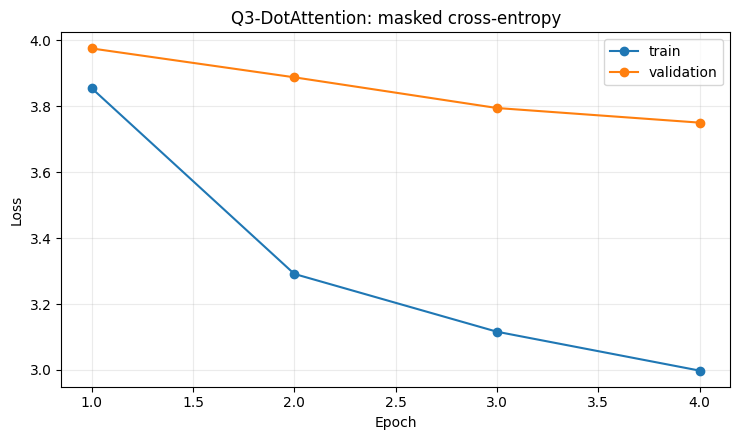

Completed Q3-DotAttention: test SacreBLEU=11.9902
Example 1 SOURCE: Due to financial constraints Dhirubhai had to drop out after high school.
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: वित्तीय <unk> के कारण <unk> के बाद <unk> <unk> के बाद <unk> <unk> <unk>
Example 2 SOURCE: Delta and JetBlue were among the airliners who have already submitted plans.
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> के पहले <unk> में <unk> <unk> के साथ प्रस्तुत किया गया है।
Example 3 SOURCE: It was simply nothing I could have imagined.
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: यह तो कोई भी मुझे नहीं <unk>
Required assignment checkpoint: /kaggle/working/q3_seq2seq_dot.pt
Download this model bundle from Kaggle Files/Output: /kaggle/working/q3_dot_model_bundle.zip
Q3-BahdanauAttenti

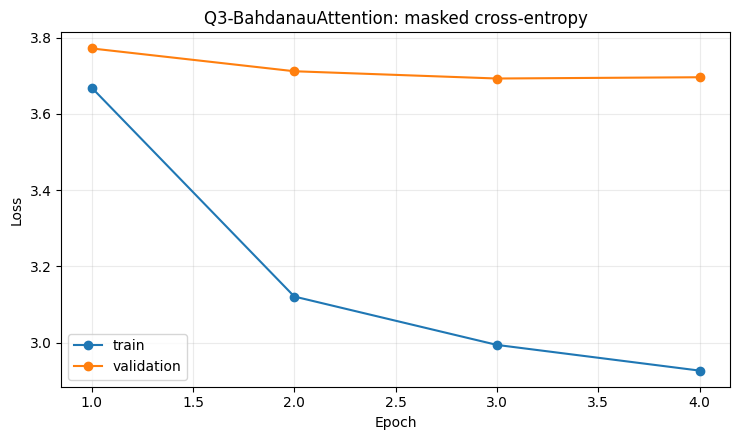

Completed Q3-BahdanauAttention: test SacreBLEU=15.3005
Example 1 SOURCE: Due to financial constraints Dhirubhai had to drop out after high school.
Example 1 REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
Example 1 HYPOTHESIS: वित्तीय <unk> के कारण उच्च <unk> के बाद <unk> हाई स्कूल के <unk> को <unk>
Example 2 SOURCE: Delta and JetBlue were among the airliners who have already submitted plans.
Example 2 REFERENCE: डेल्टा और <unk> उन <unk> में से हैं, जिन्होंने पहले ही योजनाएं प्रस्तुत कर दी हैं।
Example 2 HYPOTHESIS: <unk> और <unk> <unk> पहले ही <unk> में <unk> <unk> <unk> थीं।
Example 3 SOURCE: It was simply nothing I could have imagined.
Example 3 REFERENCE: सरल तौर कहें तो में इसमें से किसी भी कल्पना भी नहीं कर सकता था।
Example 3 HYPOTHESIS: यह कुछ नहीं था कि मुझे <unk> नहीं था।
Required assignment checkpoint: /kaggle/working/q3_seq2seq_bah.pt
Download this model bundle from Kaggle Files/Output: /kaggle/working/q3_bahdanau_model_bundle.zip
QUESTION 3 TRAI

In [22]:
# Q3 DUAL-GPU TRAINING (the only Question 3 training cell)
# Dot Product Attention -> cuda:0; Bahdanau Attention -> cuda:1.
# On one GPU/CPU, the same cell falls back to safe sequential execution.
(seq2seq_dot, hist_dot, q3_dot_result), (seq2seq_bah, hist_bah, q3_bah_result) = _q3_run_attention_pair()


#### **BLEU Score Evaluation[5 Marks]**

Before filling out the code below, familiarize yourself with these core components:

* **Definition of BLEU (Bilingual Evaluation Understudy)**: A metric for automatically evaluating machine-translated text against one or more human reference translations by measuring n-gram precision with a brevity penalty. Detailed information and standard references can be found at the [SacreBLEU GitHub Repository](https://github.com/mjpost/sacrebleu).
* **`evaluate_bleu_attn`**: Computes SacreBLEU evaluation scores across test datasets specifically for attention-augmented models using greedy decoding.
* **Hypothesis & Reference Accumulation**: Collects generated token strings and matches them against ground-truth target sentences to calculate precise n-gram precision metrics.

Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
| Architecture | Best epoch | Best validation loss | Test SacreBLEU |
|---|---:|---:|---:|
| No Attention | 9 | 3.8058 | 11.9787 |
| Dot Product Attention | 4 | 3.7503 | 11.9902 |
| Bahdanau Attention | 3 | 3.6930 | 15.3005 |
Dot improvement over no attention: +0.0115 BLEU
Bahdanau improvement over no attention: +3.3218 BLEU


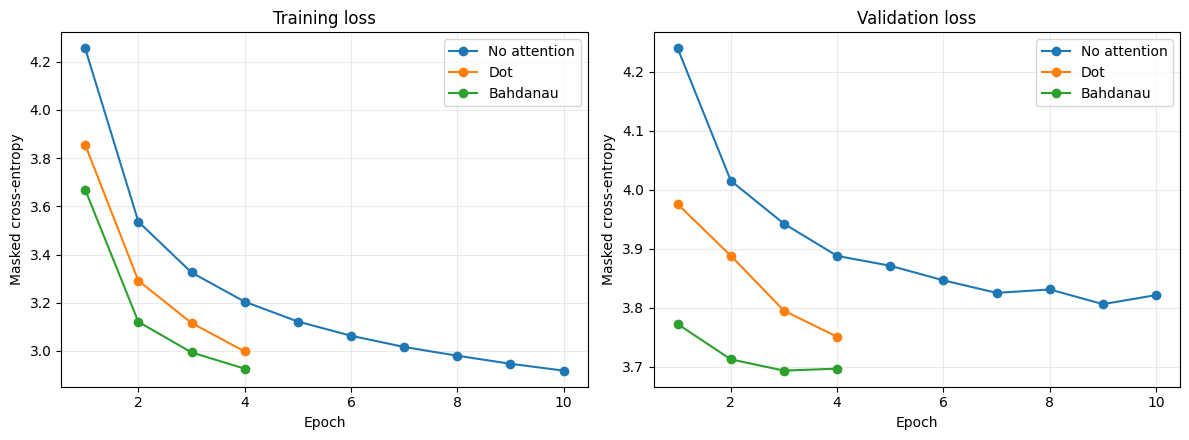

Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip
Five real attention heatmaps are generated in the dedicated heatmap cell below.


In [25]:
# --- SacreBLEU Evaluation for Attention Models ---
@torch.no_grad()
def evaluate_bleu_attn(model: nn.Module, loader: DataLoader, device=None):
    """Compute corpus SacreBLEU with autoregressive attention decoding."""
    bleu, records = _q3_evaluate_predictions(model, loader, device=device)
    return bleu, [row["hypothesis"] for row in records], [row["reference"] for row in records]


_q3_restore_analysis_files()
hist_dot = _q3_load_json("dot", "history")
hist_bah = _q3_load_json("bah", "history")
q3_dot_result = _q3_load_json("dot", "result")
q3_bah_result = _q3_load_json("bah", "result")
dot_predictions = _q3_load_json("dot", "predictions")
bah_predictions = _q3_load_json("bah", "predictions")
baseline_result = _q3_load_q2_json("q2_noattention_baseline_result.json")
baseline_history = _q3_load_q2_json("q2_noattention_baseline_history.json")

# Keep the assignment-standard variables available without rerunning full test inference.
seq2seq_dot = _q3_load_completed_model("dot", device="cpu")
seq2seq_bah = _q3_load_completed_model("bah", device="cpu")
bleu_dot = float(q3_dot_result["test_bleu"])
bleu_bah = float(q3_bah_result["test_bleu"])
hyps_dot = [row["hypothesis"] for row in dot_predictions]
refs_dot = [row["reference"] for row in dot_predictions]
hyps_bah = [row["hypothesis"] for row in bah_predictions]
refs_bah = [row["reference"] for row in bah_predictions]
test_bleu = float(baseline_result["test_bleu"])

print("| Architecture | Best epoch | Best validation loss | Test SacreBLEU |")
print("|---|---:|---:|---:|")
print(f"| No Attention | {baseline_result['best_epoch']} | {baseline_result['best_val_loss']:.4f} | {test_bleu:.4f} |")
print(f"| Dot Product Attention | {q3_dot_result['best_epoch']} | {q3_dot_result['best_val_loss']:.4f} | {bleu_dot:.4f} |")
print(f"| Bahdanau Attention | {q3_bah_result['best_epoch']} | {q3_bah_result['best_val_loss']:.4f} | {bleu_bah:.4f} |")
print(f"Dot improvement over no attention: {bleu_dot - test_bleu:+.4f} BLEU")
print(f"Bahdanau improvement over no attention: {bleu_bah - test_bleu:+.4f} BLEU")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, history in (
    ("No attention", baseline_history),
    ("Dot", hist_dot),
    ("Bahdanau", hist_bah),
):
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=label)
    axes[1].plot(history["epoch"], history["val_loss"], marker="o", label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Masked cross-entropy")
axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Masked cross-entropy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
comparison_plot = Q3_ANALYSIS_DIR / "q3_loss_comparison.png"
fig.savefig(comparison_plot, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

bleu_comparison = {
    "no_attention": {"test_bleu": test_bleu, "best_val_loss": baseline_result["best_val_loss"]},
    "dot": {"test_bleu": bleu_dot, "best_val_loss": q3_dot_result["best_val_loss"]},
    "bah": {"test_bleu": bleu_bah, "best_val_loss": q3_bah_result["best_val_loss"]},
    "dot_minus_baseline": bleu_dot - test_bleu,
    "bah_minus_baseline": bleu_bah - test_bleu,
}
_q3_atomic_json_save(bleu_comparison, Q3_ANALYSIS_DIR / "q3_bleu_comparison.json")
_q3_refresh_analysis_bundle()
print("Five real attention heatmaps are generated in the dedicated heatmap cell below.")


####Decoding Strategies for Autoregressive Inference[20 Marks][Refer to Lecture Notes]

At inference, each decoder step produces logits over the Hindi vocabulary. A decoding strategy turns those per-step logits into a sequence. The existing `greedy_decode` methods remain unchanged; the functions below are additional utilities for the existing `Seq2SeqAttn` models.

### 1. Greedy Decoding

Greedy decoding selects $\arg\max_v\,p(v\mid y_{<t},x)$ at every step. It is deterministic and inexpensive, but it is myopic: an early locally likely token can rule out a better complete translation, and the same input always produces the same output.

### 2. Beam Search

Beam search keeps the best $k$ partial hypotheses according to cumulative log-probability, expanding and pruning them at each step. It explores alternatives to one greedy path, but costs roughly $k$ decoder expansions per step. Length normalization is included below because unnormalized sums of negative log-probabilities tend to favor short hypotheses. For neural machine translation beam-search analysis, see [Freitag and Al-Onaizan (2017)](https://aclanthology.org/W17-3207/).

### 3. Random Sampling with Temperature

Random sampling draws from $\operatorname{softmax}(z/T)$, where $z$ are logits and $T>0$. Lower $T$ sharpens the distribution toward greedy behavior; higher $T$ flattens it and increases variety, but can also select less suitable tokens.

### 4. Top-$k$ Sampling

Top-$k$ sampling retains only the $k$ highest-probability tokens, renormalizes their probabilities, and samples from that set. It prevents very low-probability tail tokens from being chosen, although a fixed $k$ may be too restrictive for a sharp distribution or too broad for a flat one.

### 5. Top-$p$ (Nucleus) Sampling

Top-$p$ sampling retains the smallest token set whose cumulative probability is at least $p$, then samples after renormalization. The retained set adapts to the uncertainty of each step. [Holtzman et al. (2020)](https://arxiv.org/abs/1904.09751) introduced nucleus sampling in their study of decoding degeneration. These stochastic strategies are often most useful for open-ended generation; for a constrained translation task, BLEU and adequacy should be evaluated rather than assumed.


Before filling out the code below, familiarize yourself with these core components:

* **Greedy Decoding**: Selects the single highest-probability token at each step. It is fast and deterministic, but prone to myopic errors.
* **Beam Search**: Maintains the top $k$ partial hypotheses to balance exploration and sequence likelihood, utilizing length normalization as detailed by [Freitag and Al-Onaizan (2017)](https://aclanthology.org/W17-3207/).
* **Temperature Sampling**: Scales logits by a temperature factor $T$ to control randomness and distribution sharpness.
* **Top-$k$ & Nucleus (Top-$p$) Sampling**: Restricts sampling pools to the top $k$ candidates or a cumulative probability threshold $p$, mitigating degeneration as explored by [Holtzman et al. (2020)](https://arxiv.org/abs/1904.09751).

In [26]:
def count_repetitive_hypotheses(hypotheses_list, repeat_threshold=3):
    """Return indices containing one token repeated consecutively at least N times."""
    if repeat_threshold < 2:
        raise ValueError("repeat_threshold must be at least 2")
    repetitive_indices = []
    for index, hypothesis in enumerate(hypotheses_list):
        words = hypothesis.split()
        for start in range(len(words) - repeat_threshold + 1):
            if len(set(words[start:start + repeat_threshold])) == 1:
                repetitive_indices.append(index)
                break
    return repetitive_indices


In [27]:
# --- Decoding strategies for existing Seq2SeqAttn models ---
@torch.no_grad()
def _sample_attn_next_token(logits, strategy="greedy", temperature=1.0,
                            top_k=10, top_p=0.9, generator=None):
    """Select one token per row with a numerically safe decoding strategy."""
    if temperature <= 0:
        raise ValueError("temperature must be greater than zero")
    if strategy == "greedy":
        return logits.argmax(dim=-1)

    probabilities = torch.softmax(logits.float() / temperature, dim=-1)
    if strategy == "sample":
        return torch.multinomial(probabilities, 1, generator=generator).squeeze(1)
    if strategy == "top_k":
        if top_k < 1:
            raise ValueError("top_k must be at least one")
        k = min(int(top_k), probabilities.size(-1))
        values, indices = torch.topk(probabilities, k, dim=-1)
        values = values / values.sum(dim=-1, keepdim=True).clamp_min(1e-12)
        sampled_local = torch.multinomial(values, 1, generator=generator)
        return indices.gather(1, sampled_local).squeeze(1)
    if strategy == "top_p":
        if not 0 < top_p <= 1:
            raise ValueError("top_p must lie in (0, 1]")
        sorted_probabilities, sorted_indices = torch.sort(
            probabilities, descending=True, dim=-1
        )
        cumulative = sorted_probabilities.cumsum(dim=-1)
        keep = (cumulative - sorted_probabilities) < top_p
        keep[:, 0] = True
        filtered = sorted_probabilities * keep
        filtered = filtered / filtered.sum(dim=-1, keepdim=True).clamp_min(1e-12)
        sampled_local = torch.multinomial(filtered, 1, generator=generator)
        return sorted_indices.gather(1, sampled_local).squeeze(1)
    raise ValueError(f"Unsupported decoding strategy: {strategy}")


@torch.no_grad()
def decode_attn_with_strategy(model, src_tensor, max_len=MAX_LEN_HI,
                              strategy="greedy", seed=SEED, **kwargs):
    """Batch-capable greedy, temperature, top-k, or nucleus decoding."""
    model.eval()
    run_device = next(model.parameters()).device
    src_tensor = src_tensor.to(run_device, non_blocking=True)
    enc_outputs, dec_h0 = model.encoder(src_tensor)
    mask = src_tensor.ne(stoi_en[PAD])
    hidden_states = [dec_h0.clone() for _ in range(model.num_layers)]
    next_input = torch.full(
        (src_tensor.size(0),), stoi_hi[SOS], dtype=torch.long, device=run_device
    )
    finished = torch.zeros(src_tensor.size(0), dtype=torch.bool, device=run_device)
    outputs = []
    generator = None
    if strategy != "greedy":
        generator = torch.Generator(device=run_device)
        generator.manual_seed(int(seed))

    for _ in range(max_len):
        logits, hidden_states, _ = model.decoder(
            next_input, hidden_states, enc_outputs, mask
        )
        next_input = _sample_attn_next_token(
            logits, strategy=strategy, generator=generator, **kwargs
        )
        next_input = torch.where(
            finished, torch.full_like(next_input, stoi_hi[PAD]), next_input
        )
        outputs.append(next_input.cpu())
        finished |= next_input.eq(stoi_hi[EOS])
        if bool(finished.all()):
            break
    return (
        torch.stack(outputs, dim=1)
        if outputs else torch.empty(src_tensor.size(0), 0, dtype=torch.long)
    )


@torch.no_grad()
def beam_search_decode_attn(model, src_tensor, beam_width=4,
                            max_len=MAX_LEN_HI, length_penalty=0.6):
    """Length-normalized beam search for exactly one source sentence."""
    if beam_width < 1:
        raise ValueError("beam_width must be at least one")
    model.eval()
    run_device = next(model.parameters()).device
    src_tensor = src_tensor.to(run_device)
    if src_tensor.dim() == 1:
        src_tensor = src_tensor.unsqueeze(0)
    if src_tensor.size(0) != 1:
        raise ValueError("beam_search_decode_attn accepts one source sentence at a time")

    enc_outputs, dec_h0 = model.encoder(src_tensor)
    mask = src_tensor.ne(stoi_en[PAD])
    initial_states = [dec_h0.clone() for _ in range(model.num_layers)]
    beams = [([], 0.0, stoi_hi[SOS], initial_states)]

    def normalized_score(tokens, log_probability):
        return log_probability / (max(len(tokens), 1) ** length_penalty)

    for _ in range(max_len):
        candidates = []
        for tokens, log_probability, input_token, states in beams:
            if tokens and tokens[-1] == stoi_hi[EOS]:
                candidates.append((tokens, log_probability, input_token, states))
                continue
            token = torch.tensor([input_token], dtype=torch.long, device=run_device)
            logits, new_states, _ = model.decoder(token, states, enc_outputs, mask)
            log_probabilities = F.log_softmax(logits.float(), dim=-1).squeeze(0)
            values, token_ids = torch.topk(
                log_probabilities, k=min(beam_width, log_probabilities.numel())
            )
            for value, token_id in zip(values.tolist(), token_ids.tolist()):
                candidates.append((
                    tokens + [token_id],
                    log_probability + float(value),
                    token_id,
                    [state.clone() for state in new_states],
                ))
        beams = sorted(
            candidates,
            key=lambda beam: normalized_score(beam[0], beam[1]),
            reverse=True,
        )[:beam_width]
        if all(tokens and tokens[-1] == stoi_hi[EOS] for tokens, _, _, _ in beams):
            break

    best_tokens, _, _, _ = max(
        beams, key=lambda beam: normalized_score(beam[0], beam[1])
    )
    return torch.tensor([best_tokens], dtype=torch.long)


####Attention Heatmap Visualization[5 marks]

Plotting attention weights as a heatmap shows which English source words the model focuses on while generating each Hindi word.

Before filling out the code below, familiarize yourself with these core components:

* **Alignment Tracking**: Visualizes the weight matrix mapping target words to source tokens across decoding timesteps.
* **Heatmap Rendering**: Automatically handles token slice filtering up to the `<eos>` boundary to generate readable diagnostic plots.

Before filling out the code below, familiarize yourself with these core components:

* **Alignment Matrix Visualization (`plot_attention_heatmap`)**: Decodes an individual source sentence and plots the resulting attention weight matrix to visualize which source words the decoder focuses on during target generation.
* **Token and Boundary Management**: Manages sequence indexing up to the `<eos>` boundary to filter out padding noise in visualization plots.
* **Sample Diagnostic Suite**: Selects representative sentences from the test set to render and inspect soft alignments.

Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Generating five required heatmaps with the measured higher-BLEU model: Q3-BahdanauAttention
Heatmap 1/5 | test index=268 | source=Halloween 2013: By the Numbers


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/tmp/ipyker

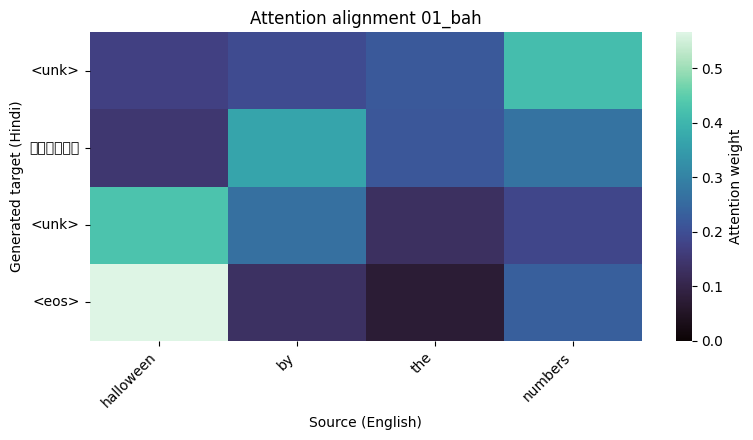

Heatmap 2/5 | test index=694 | source=It is the perfect gift for your relatives and loved ones.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2310 (\N{DEVANAGARI LETTER AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2346 (\N{DEVANAGARI LETTER PA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/py

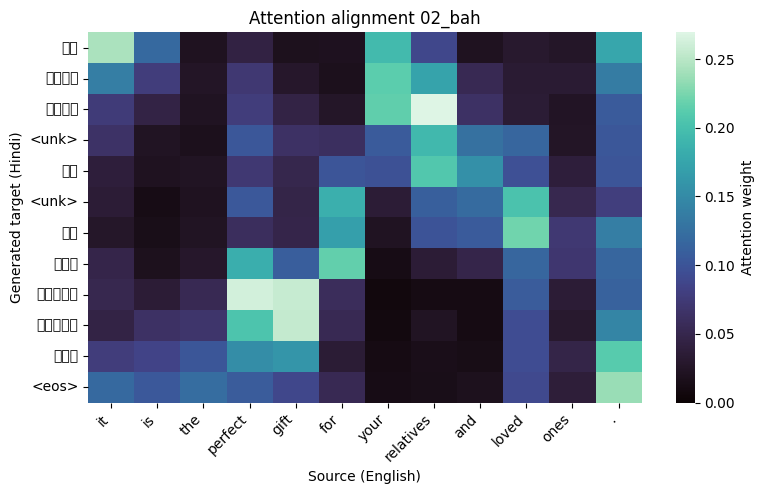

Heatmap 3/5 | test index=814 | source=Americans will spend $1.9 billion on it this year, according to The Nielsen Company.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2311 (\N{DEVANAGARI LETTER I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib

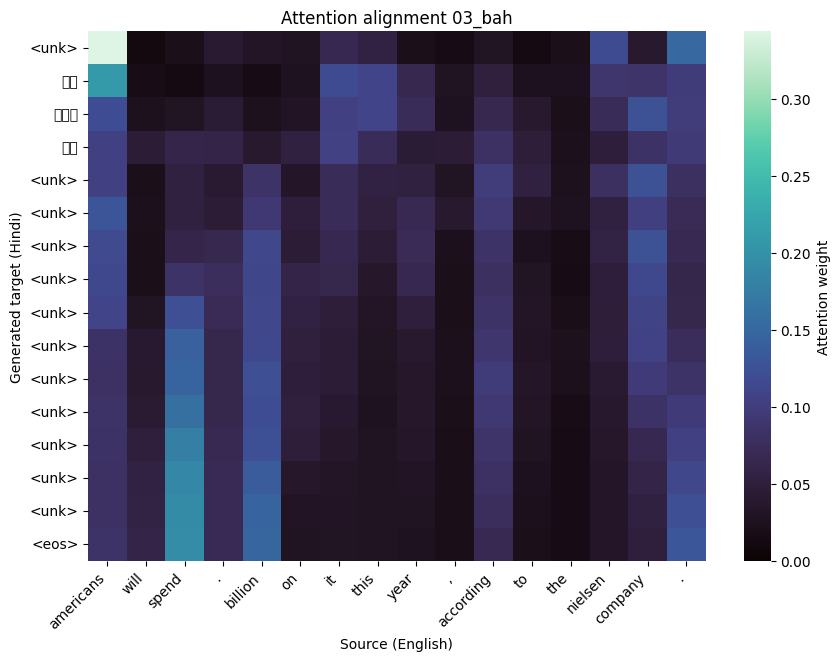

Heatmap 4/5 | test index=510 | source=But when the government was formed by Congress or its supporters then the poor man could not get enough food.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2375 (\N{DEVANAGARI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/

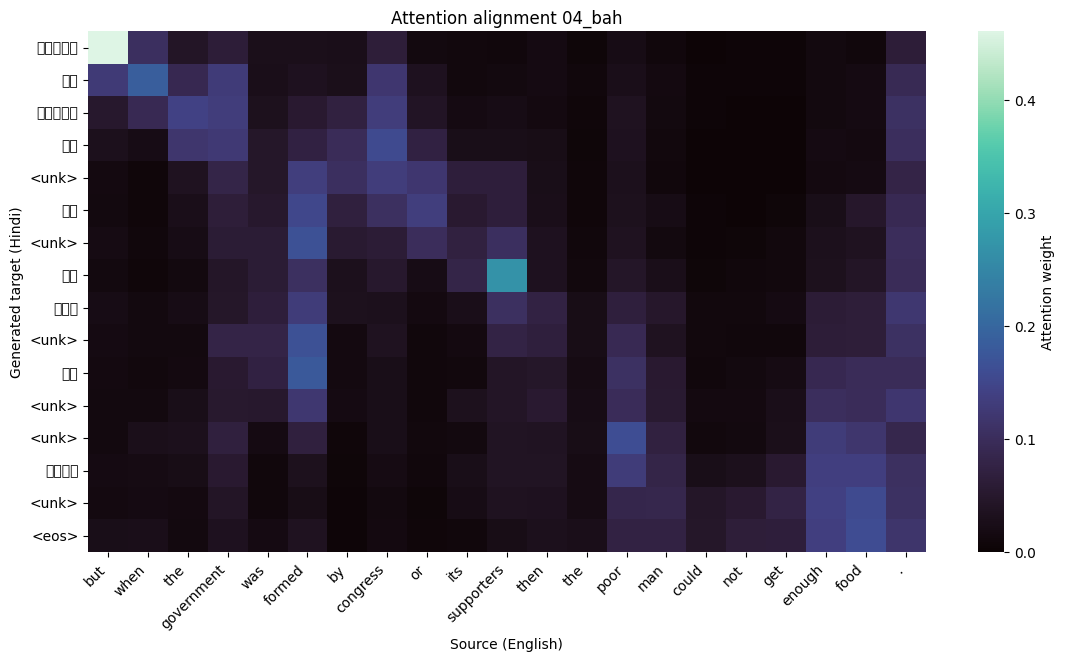

Heatmap 5/5 | test index=745 | source=The CSA's Vice-Chancellor, Dr. Munna Singh, has decided to charge an entrance fee to the park because of the litter being left in the park.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2337 (\N{DEVANAGARI LETTER DDA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/

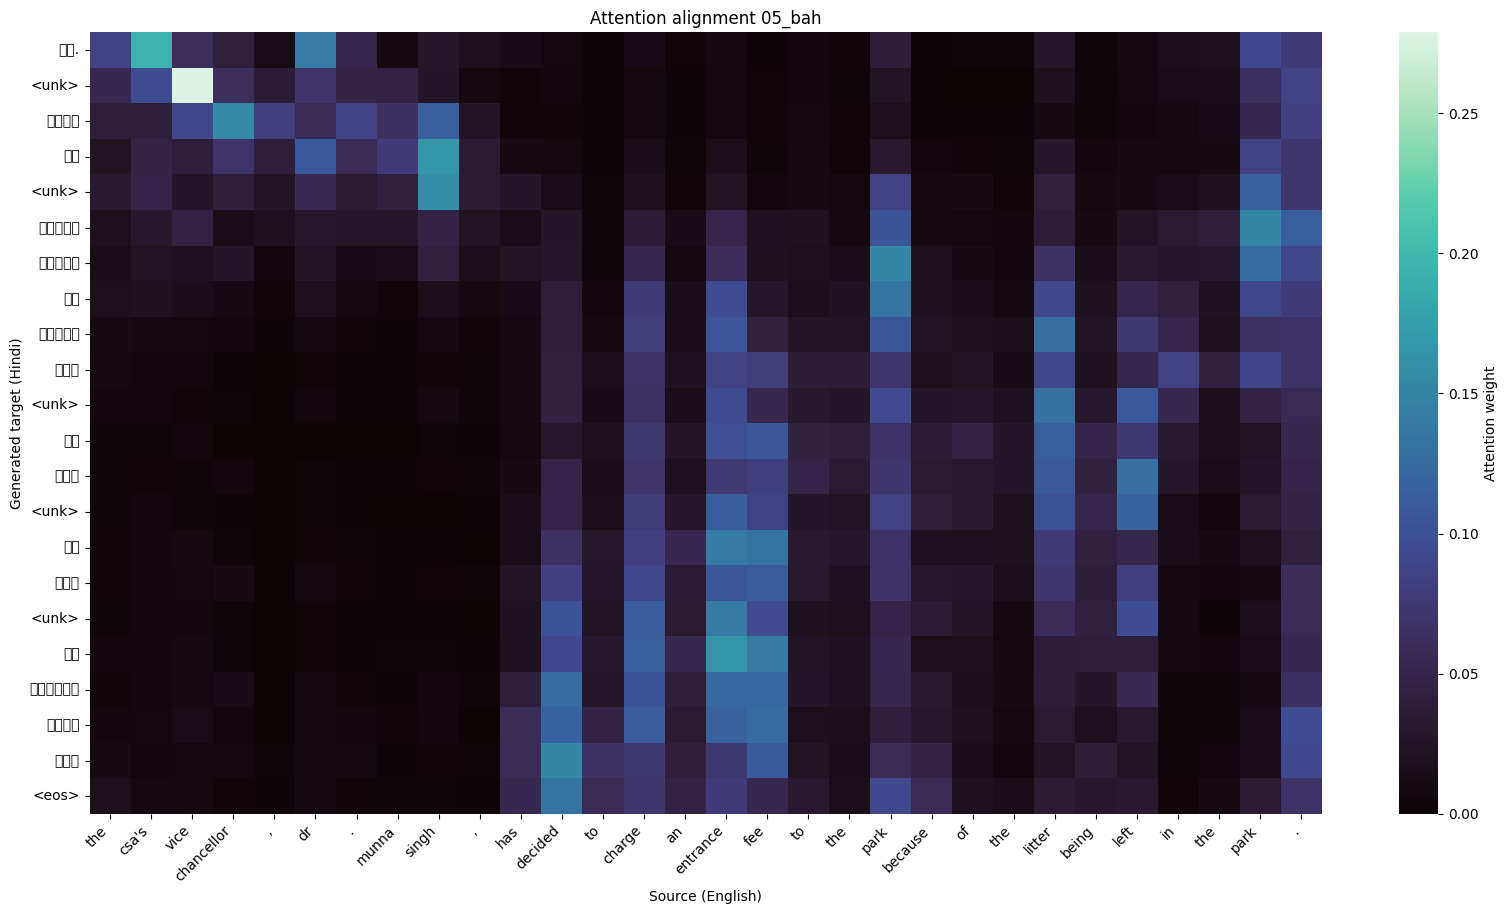

Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

In [28]:
# --- Attention Heatmap Visualization ---
def _q3_heatmap_record(model, src_text: str):
    run_device = next(model.parameters()).device
    src_ids = encode_en(src_text)
    src_tensor = torch.tensor([src_ids], dtype=torch.long, device=run_device)
    predicted_ids, attention = model.greedy_decode(src_tensor, return_attn=True)
    source_tokens = tokenize_en(src_text)[:MAX_LEN_EN] or [PAD]
    row_indices, target_tokens = [], []
    for row, token_id in enumerate(predicted_ids[0].tolist()):
        if token_id == stoi_hi[PAD]:
            break
        row_indices.append(row)
        if token_id == stoi_hi[EOS]:
            target_tokens.append(EOS)
            break
        target_tokens.append(
            itos_hi[token_id] if 0 <= token_id < len(itos_hi) else UNK
        )
    if not row_indices:
        row_indices, target_tokens = [0], ["<empty>"]
    matrix = attention[0, row_indices, :len(source_tokens)].float().numpy()
    return {
        "source": src_text,
        "source_tokens": source_tokens,
        "target_tokens": target_tokens,
        "hypothesis": _q3_target_text(predicted_ids[0].tolist()),
        "attention": matrix.tolist(),
    }


def plot_attention_heatmap(model, src_text: str, idx_tag: str = "",
                           output_path=None, show=True):
    """Decode one sentence, save its real alignment matrix, and display it."""
    record = _q3_heatmap_record(model, src_text)
    matrix = np.asarray(record["attention"], dtype=np.float32)
    width = max(8.0, 0.55 * len(record["source_tokens"]))
    height = max(4.5, 0.42 * len(record["target_tokens"]))
    fig, ax = plt.subplots(figsize=(width, height))
    sns.heatmap(
        matrix, ax=ax, cmap="mako", vmin=0.0, vmax=max(float(matrix.max()), 1e-6),
        xticklabels=record["source_tokens"], yticklabels=record["target_tokens"],
        cbar_kws={"label": "Attention weight"},
    )
    ax.set_xlabel("Source (English)")
    ax.set_ylabel("Generated target (Hindi)")
    ax.set_title(f"Attention alignment {idx_tag}".strip())
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0)
    fig.tight_layout()
    if output_path is None:
        safe_tag = re.sub(r"[^A-Za-z0-9_-]+", "_", idx_tag).strip("_") or "sample"
        output_path = Q3_ANALYSIS_DIR / f"q3_attention_heatmap_{safe_tag}.png"
    output_path = Path(output_path)
    fig.savefig(output_path, dpi=190, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    record["path"] = str(output_path)
    return record


def _q3_fixed_test_indices(count=5):
    """Deterministic length-stratified test indices shared by Q3 analyses."""
    if count < 1:
        return []
    eligible = [
        index for index in range(len(test_dataset))
        if tokenize_en(test_dataset.src_texts[index])
    ]
    if not eligible:
        raise ValueError("No non-empty English test sources are available.")
    ordered = sorted(
        eligible,
        key=lambda index: (len(tokenize_en(test_dataset.src_texts[index])), index),
    )
    positions = np.linspace(0, len(ordered) - 1, min(count, len(ordered)), dtype=int)
    return [ordered[int(position)] for position in positions]


_q3_restore_analysis_files()
q3_dot_result = _q3_load_json("dot", "result")
q3_bah_result = _q3_load_json("bah", "result")
heatmap_variant = "dot" if q3_dot_result["test_bleu"] >= q3_bah_result["test_bleu"] else "bah"
heatmap_model = _q3_load_completed_model(heatmap_variant)
Q3_HEATMAP_INDICES = _q3_fixed_test_indices(5)
sample_sentences = [test_dataset.src_texts[index] for index in Q3_HEATMAP_INDICES]
heatmap_records = []
print(
    f"Generating five required heatmaps with the measured higher-BLEU model: "
    f"{_q3_paths(heatmap_variant)['experiment_name']}"
)
for position, (dataset_index, sentence) in enumerate(
    zip(Q3_HEATMAP_INDICES, sample_sentences), 1
):
    print(f"Heatmap {position}/5 | test index={dataset_index} | source={sentence}")
    record = plot_attention_heatmap(
        heatmap_model, sentence, idx_tag=f"{position:02d}_{heatmap_variant}",
        output_path=Q3_ANALYSIS_DIR / f"q3_attention_heatmap_{position:02d}.png",
    )
    record.update({"test_index": dataset_index, "model_variant": heatmap_variant})
    heatmap_records.append(record)
_q3_atomic_json_save(heatmap_records, Q3_ANALYSIS_DIR / "q3_heatmap_records.json")
_q3_atomic_json_save(
    {"model_variant": heatmap_variant, "test_indices": Q3_HEATMAP_INDICES,
     "examples": heatmap_records},
    Q3_ANALYSIS_DIR / "q3_heatmap_manifest.json",
)
heatmap_model.cpu()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
_q3_refresh_analysis_bundle()


#### Evaluating Autoregressive Decoding Strategies[5 Marks]

The code block below executes and evaluates the decoding utilities defined . It compares qualitative outputs across greedy decoding, beam search, temperature sampling, top-$k$ sampling, and top-$p$ sampling (satisfying A3), and evaluates quantitative beam width BLEU scores alongside sampling repetition statistics (satisfying E3).

Before filling out the code below, familiarize yourself with these core components:

* **Evaluation Suite (`evaluate_decoding_strategies_suite`)**: Simultaneously measures text diversity, repetition rates, and BLEU benchmarks across beam widths and sampling configurations to address Analytical A3 and Experimental E3.
* **Deterministic vs. Stochastic Generation**: Compares deterministic approaches (Greedy decoding, Beam Search) against stochastic sampling methods (Temperature scaling, Top-$k$, and Top-$p$ Nucleus sampling).
* **Metrics Tracking**: Analyzes repetition rates and translation variations on a fixed subset of test samples.

In [29]:
# --- Decoding Strategies Evaluation Suite ---
Q3_DECODING_SEED = SEED + 3000
Q3_BEAM_BENCHMARK_SIZE = min(128, len(test_dataset))
Q3_SAMPLING_BENCHMARK_SIZE = min(128, len(test_dataset))


def _q3_text_diversity(hypotheses):
    tokens = [token for text in hypotheses for token in text.split()]
    bigrams = [pair for text in hypotheses for pair in zip(text.split(), text.split()[1:])]
    return {
        "distinct_1": len(set(tokens)) / max(len(tokens), 1),
        "distinct_2": len(set(bigrams)) / max(len(bigrams), 1),
        "unique_sentence_ratio": len(set(hypotheses)) / max(len(hypotheses), 1),
    }


@torch.no_grad()
def evaluate_decoding_strategies_suite(model, loader, n_samples=5,
                                       model_variant=None,
                                       benchmark_size=Q3_BEAM_BENCHMARK_SIZE):
    """Run fixed examples, resumable beam BLEU, and stochastic diagnostics."""
    model.eval()
    variant = _q3_variant(model_variant or "bah")
    suite_path = Q3_ANALYSIS_DIR / "q3_decoding_suite.json"
    fixed_indices = _q3_fixed_test_indices(n_samples)
    benchmark_indices = _q3_fixed_test_indices(benchmark_size)
    configuration = {
        "model_variant": variant,
        "seed": Q3_DECODING_SEED,
        "fixed_indices": fixed_indices,
        "benchmark_indices": benchmark_indices,
        "beam_widths": [2, 4, 8],
        "length_penalty": 0.6,
        "temperature": 0.8,
        "top_k": 20,
        "top_p": 0.9,
    }
    suite = {
        "configuration": configuration,
        "qualitative_examples": [],
        "beam_bleu": {},
        "sampling_metrics": {},
    }
    if suite_path.is_file():
        previous = json.loads(suite_path.read_text(encoding="utf-8"))
        if previous.get("configuration") != configuration:
            raise ValueError(
                "Existing decoding-suite configuration differs. Remove only the old "
                "q3_decoding_suite.json if you intentionally want a new benchmark."
            )
        suite = previous
        print("Restored completed portions of the Q3 decoding benchmark.")

    if not suite.get("qualitative_examples"):
        print("=" * 88)
        print("FIXED FIVE-SOURCE DECODING COMPARISON")
        strategy_options = {
            "greedy": {"strategy": "greedy"},
            "beam_k4": {"beam_width": 4},
            "temperature": {"strategy": "sample", "temperature": 0.8},
            "top_k": {"strategy": "top_k", "top_k": 20},
            "top_p": {"strategy": "top_p", "top_p": 0.9},
        }
        for position, dataset_index in enumerate(fixed_indices):
            src, _, tgt_out = test_dataset[dataset_index]
            single_src = src.unsqueeze(0)
            source_text = test_dataset.src_texts[dataset_index]
            reference = _q3_target_text(tgt_out.tolist())
            row = {
                "test_index": dataset_index,
                "source": source_text,
                "reference": reference,
                "outputs": {},
            }
            print(f"\nSample {position + 1} | test index={dataset_index}")
            print("SOURCE:", source_text)
            print("REFERENCE:", reference)
            for name, options in strategy_options.items():
                if name == "beam_k4":
                    predicted = beam_search_decode_attn(
                        model, single_src, beam_width=4, length_penalty=0.6
                    )
                else:
                    predicted = decode_attn_with_strategy(
                        model, single_src, seed=Q3_DECODING_SEED + position,
                        **options,
                    )
                hypothesis = _q3_target_text(predicted[0].tolist())
                sentence_bleu = float(sacrebleu.sentence_bleu(hypothesis, [reference]).score)
                repeated = bool(count_repetitive_hypotheses([hypothesis]))
                row["outputs"][name] = {
                    "hypothesis": hypothesis,
                    "sentence_bleu": sentence_bleu,
                    "has_three_token_repeat": repeated,
                }
                print(f"{name.upper():>12}: {hypothesis}")
            suite["qualitative_examples"].append(row)
        _q3_atomic_json_save(suite, suite_path)
        _q3_refresh_analysis_bundle()

    for beam_width in configuration["beam_widths"]:
        key = str(beam_width)
        if key in suite.get("beam_bleu", {}):
            print(
                f"Beam width {beam_width}: restored BLEU="
                f"{suite['beam_bleu'][key]['bleu']:.4f}"
            )
            continue
        print("=" * 88)
        print(
            f"BEAM BENCHMARK k={beam_width} | model={variant} | "
            f"deterministic subset={len(benchmark_indices)}"
        )
        hypotheses, references = [], []
        for completed, dataset_index in enumerate(benchmark_indices, 1):
            src, _, tgt_out = test_dataset[dataset_index]
            predicted = beam_search_decode_attn(
                model, src.unsqueeze(0), beam_width=beam_width,
                length_penalty=configuration["length_penalty"],
            )
            hypotheses.append(_q3_target_text(predicted[0].tolist()))
            references.append(_q3_target_text(tgt_out.tolist()))
            if completed % 32 == 0 or completed == len(benchmark_indices):
                print(f"  k={beam_width}: decoded {completed}/{len(benchmark_indices)}")
        beam_bleu = float(sacrebleu.corpus_bleu(hypotheses, [references]).score)
        suite.setdefault("beam_bleu", {})[key] = {
            "bleu": beam_bleu,
            "examples": len(hypotheses),
            "subset_indices": benchmark_indices,
        }
        _q3_atomic_json_save(suite, suite_path)
        _q3_refresh_analysis_bundle()
        print(f"Beam width {beam_width} SacreBLEU: {beam_bleu:.4f}")

    if not suite.get("sampling_metrics"):
        print("=" * 88)
        print(
            f"STOCHASTIC BENCHMARK | seed={Q3_DECODING_SEED} | "
            f"subset={Q3_SAMPLING_BENCHMARK_SIZE}"
        )
        sampling_indices = _q3_fixed_test_indices(Q3_SAMPLING_BENCHMARK_SIZE)
        subset = torch.utils.data.Subset(test_dataset, sampling_indices)
        subset_loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False)
        sampling_options = {
            "temperature": {"strategy": "sample", "temperature": 0.8},
            "top_k": {"strategy": "top_k", "top_k": 20},
            "top_p": {"strategy": "top_p", "top_p": 0.9},
        }
        for name, options in sampling_options.items():
            hypotheses, references = [], []
            for batch_index, (src, _, tgt_out) in enumerate(subset_loader):
                predicted = decode_attn_with_strategy(
                    model, src, seed=Q3_DECODING_SEED + batch_index, **options
                )
                hypotheses.extend(_q3_target_text(row.tolist()) for row in predicted)
                references.extend(_q3_target_text(row.tolist()) for row in tgt_out)
            repetitive = count_repetitive_hypotheses(hypotheses)
            metrics = {
                "examples": len(hypotheses),
                "seed": Q3_DECODING_SEED,
                "parameters": options,
                "bleu": float(sacrebleu.corpus_bleu(hypotheses, [references]).score),
                "repetition_count": len(repetitive),
                "repetition_rate": len(repetitive) / max(len(hypotheses), 1),
                **_q3_text_diversity(hypotheses),
            }
            suite.setdefault("sampling_metrics", {})[name] = metrics
            print(
                f"{name}: BLEU={metrics['bleu']:.4f}, "
                f"repeat={100 * metrics['repetition_rate']:.2f}%, "
                f"distinct-1={metrics['distinct_1']:.4f}, "
                f"distinct-2={metrics['distinct_2']:.4f}"
            )
        _q3_atomic_json_save(suite, suite_path)
        _q3_refresh_analysis_bundle()
    return suite


_q3_restore_analysis_files()
q3_dot_result = _q3_load_json("dot", "result")
q3_bah_result = _q3_load_json("bah", "result")
decoding_variant = "dot" if q3_dot_result["test_bleu"] >= q3_bah_result["test_bleu"] else "bah"
decoding_model = _q3_load_completed_model(decoding_variant)
print(
    "Decoding suite model selected by measured greedy test BLEU:",
    _q3_paths(decoding_variant)["experiment_name"],
)
q3_decoding_suite = evaluate_decoding_strategies_suite(
    decoding_model, test_loader, n_samples=5,
    model_variant=decoding_variant,
    benchmark_size=Q3_BEAM_BENCHMARK_SIZE,
)
decoding_model.cpu()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
Decoding suite model selected by measured greedy test BLEU: Q3-BahdanauAttention
FIXED FIVE-SOURCE DECODING COMPARISON

Sample 1 | test index=268
SOURCE: Halloween 2013: By the Numbers
REFERENCE: <unk> <unk> <unk> द्वारा
      GREEDY: <unk> द्वारा <unk>
     BEAM_K4: <unk> की संख्या
 TEMPERATURE: <unk> <unk> द्वारा
       TOP_K: कर्ता द्वारा संख्या
       TOP_P: कर्ता द्वारा संख्या

Sample 2 | test index=694
SOURCE: It is the perfect gift for your relatives and loved ones.
REFERENCE: यह आपके <unk> <unk> और <unk> के लिए एक समूचा उपहार है।
      GREEDY: यह आपके अपने <unk> और <unk> के लिए उपहार उपहार है।
     BEAM_K4: यह अपने <unk> और <unk> के लिए उपहार उपहार है।
 TEMPERATURE: यह आपके अपने को तुम्हारे लिए दुःख के लिए उत्तम उपहार <unk> है।
       TOP_K: यह 

####Error Analysis: Does Attention Resolve the Bottleneck?[5 Marks]

To verify if attention mitigates the length bottleneck, we run our short vs. long sentence evaluation again:

Before filling out the code below, familiarize yourself with these core components:

Dataset Subsetting (torch.utils.data.Subset): Extracts a targeted subset of the test dataset using specific index collections (e.g., short vs. long sentences) to isolate and diagnose performance gaps.

Length-Based BLEU Splits: Compares translation quality across different sentence lengths to analyze how sequence length constraints impact encoder-decoder models versus attention-augmented architectures.

Comparative Performance Formatting: Outputs a neat summary table showing short-sentence BLEU, long-sentence BLEU, and the performance degradation gap across architectural variants.

In [30]:
# --- Error Analysis & Length-Based BLEU Splits ---
def bleu_for_indices_attn(model, subset_indices):
    subset = torch.utils.data.Subset(test_dataset, subset_indices)
    loader = DataLoader(subset, batch_size=128, shuffle=False)
    score, _, _ = evaluate_bleu_attn(model, loader)
    return score


def _q3_cached_bleu_for_indices(records, subset_indices):
    selected = [records[index] for index in subset_indices]
    return float(sacrebleu.corpus_bleu(
        [row["hypothesis"] for row in selected],
        [[row["reference"] for row in selected]],
    ).score)


_q3_restore_analysis_files()
short_indices = [
    index for index, text in enumerate(test_dataset.src_texts)
    if len(tokenize_en(text)) <= 8
]
long_indices = [
    index for index, text in enumerate(test_dataset.src_texts)
    if len(tokenize_en(text)) > 8
]
baseline_length = _q3_load_q2_json("q2_length_bucket_analysis.json")
dot_predictions = _q3_load_json("dot", "predictions")
bah_predictions = _q3_load_json("bah", "predictions")

length_comparison = {
    "no_attention": {
        "short_bleu": float(baseline_length["short_bleu"]),
        "long_bleu": float(baseline_length["long_bleu"]),
    },
    "dot": {
        "short_bleu": _q3_cached_bleu_for_indices(dot_predictions, short_indices),
        "long_bleu": _q3_cached_bleu_for_indices(dot_predictions, long_indices),
    },
    "bah": {
        "short_bleu": _q3_cached_bleu_for_indices(bah_predictions, short_indices),
        "long_bleu": _q3_cached_bleu_for_indices(bah_predictions, long_indices),
    },
}
for values in length_comparison.values():
    values["short_minus_long"] = values["short_bleu"] - values["long_bleu"]
length_comparison["split"] = {
    "threshold": 8,
    "short_count": len(short_indices),
    "long_count": len(long_indices),
}

print("| Architecture | Short BLEU (<=8) | Long BLEU (>8) | Short - Long |")
print("|---|---:|---:|---:|")
for key, label in (
    ("no_attention", "No Attention"),
    ("dot", "Dot Product"),
    ("bah", "Bahdanau"),
):
    values = length_comparison[key]
    print(
        f"| {label} | {values['short_bleu']:.4f} | "
        f"{values['long_bleu']:.4f} | {values['short_minus_long']:+.4f} |"
    )
_q3_atomic_json_save(
    length_comparison, Q3_ANALYSIS_DIR / "q3_length_analysis.json"
)
_q3_refresh_analysis_bundle()


Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
| Architecture | Short BLEU (<=8) | Long BLEU (>8) | Short - Long |
|---|---:|---:|---:|
| No Attention | 17.9529 | 11.8545 | +6.0984 |
| Dot Product | 17.8778 | 11.8708 | +6.0069 |
| Bahdanau | 19.9399 | 15.1956 | +4.7443 |
Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

#### **Advanced Analytical & Experimental Evaluation[Total =50 Marks]**

Answer all questions below using evidence, metrics, and observations directly from your attention-augmented Seq2Seq model runs, decoding strategy suites, and entropy/repetition experiments.

**Logical & Reasoning**

* **L1. Syntactic Alignment Discrepancy (SVO vs. SOV):[4 Marks]** English follows a Subject-Verb-Object (SVO) word order, whereas Hindi is predominantly Subject-Object-Verb (SOV). Describe precisely what an alignment-aware attention heatmap should look like near the predicate/verb during generation, and contrast it with a naive monotonic heatmap that blindly increments along source token indices.


An alignment-aware heatmap need not follow a left-to-right diagonal. When a Hindi object is generated before its verb, attention should peak on the corresponding English object even if the English verb occurred earlier. When the Hindi predicate is finally generated, the peak should return to the English predicate position. This creates a non-monotonic alignment pattern around the verb and object. A naive monotonic heatmap would simply move to the next English position at each target step; it would therefore align words by position rather than by syntactic role and would miss the SVO-to-SOV reordering.


* **L2. Attentional Repetition Loops:[4 Marks]** A common failure mode in attention-based Seq2Seq models is degeneration via repetition, where the decoder continuously attends to the exact same source position and generates a repeating loop of words. Using the attention scoring and context vector equations, explain the feedback loop mechanics that cause the model to get "stuck" on a single source index.


At step (t), the decoder state produces scores (e_{t,j}), attention weights \(\alpha_{t,j}\), and context (c_t=\sum_j\alpha_{t,j}h_j). If one source position receives an excessively large score, its encoder state dominates (c_t). That nearly unchanged context is fed into the recurrent update and output projection, which can reproduce the same target token and a similar next decoder state. The similar state again assigns the largest score to the same source position, closing a positive feedback loop: repeated attention peak, repeated context, repeated state, and repeated word. The loop continues until another token or EOS becomes sufficiently probable.


* **L3. Beam Search Length Bias & Optimization Limits:[5 Marks]** Why does the raw cumulative log-probability objective in unnormalized beam search naturally favor shorter hypotheses, and how does length penalty formulation correct this bias? Furthermore, explain why increasing the beam width $k$ indefinitely does not mathematically guarantee a superior translation BLEU score.



Every token log-probability is non-positive, so adding more tokens usually makes an unnormalized cumulative log-probability more negative. A short hypothesis can therefore outrank a better complete translation simply because it contains fewer penalties. Dividing by a length-dependent factor, such as \(L^\alpha\), makes scores from different lengths more comparable and reduces this short-output bias. A larger beam only searches the model's probability distribution more thoroughly; it does not improve incorrect probabilities, remove exposure bias, or optimize BLEU directly. Consequently, an increasingly wide beam can prefer a high-probability but short, repetitive, or semantically wrong sentence and is not guaranteed to increase BLEU.


**Analytical (Requires Your Run's Data & Evaluation Metrics)[5 Marks]**

* **A1. Attention Mitigating the Length Bottleneck:** Report the BLEU score comparison across your no-attention baseline, dot-product attention, and Bahdanau attention models, alongside the short-vs-long sentence performance split. Quantitatively evaluate whether introducing dynamic attention successfully closed the performance gap for long sequences.


In [31]:
# A1: Data-driven attention improvement and length-bottleneck analysis.
_q3_restore_analysis_files()
bleu_data = json.loads((Q3_ANALYSIS_DIR / "q3_bleu_comparison.json").read_text(encoding="utf-8"))
length_data = json.loads((Q3_ANALYSIS_DIR / "q3_length_analysis.json").read_text(encoding="utf-8"))

print("A1 measured BLEU evidence")
print("| Architecture | Overall BLEU | Short BLEU | Long BLEU | Short - Long |")
print("|---|---:|---:|---:|---:|")
for key, label in (("no_attention", "No Attention"), ("dot", "Dot Product"), ("bah", "Bahdanau")):
    overall = bleu_data[key]["test_bleu"]
    length = length_data[key]
    print(
        f"| {label} | {overall:.4f} | {length['short_bleu']:.4f} | "
        f"{length['long_bleu']:.4f} | {length['short_minus_long']:+.4f} |"
    )

baseline_long = length_data["no_attention"]["long_bleu"]
baseline_gap = length_data["no_attention"]["short_minus_long"]
a1_result = {}
for variant, label in (("dot", "Dot Product"), ("bah", "Bahdanau")):
    long_gain = length_data[variant]["long_bleu"] - baseline_long
    gap_change = baseline_gap - length_data[variant]["short_minus_long"]
    overall_gain = bleu_data[variant]["test_bleu"] - bleu_data["no_attention"]["test_bleu"]
    print(
        f"{label}: overall change={overall_gain:+.4f}, long-sequence change={long_gain:+.4f}, "
        f"bottleneck-gap reduction={gap_change:+.4f}."
    )
    if long_gain > 0 and gap_change > 0:
        verdict = "mitigated the measured long-sequence bottleneck"
    elif long_gain > 0:
        verdict = "improved long-sequence BLEU but did not reduce the measured short-long gap"
    else:
        verdict = "did not improve long-sequence BLEU in this run"
    print(f"Measured conclusion for {label}: it {verdict}.")
    a1_result[variant] = {
        "overall_bleu_change": overall_gain,
        "long_bleu_change": long_gain,
        "gap_reduction": gap_change,
        "verdict": verdict,
    }
_q3_atomic_json_save(a1_result, Q3_ANALYSIS_DIR / "q3_a1_analysis.json")
_q3_refresh_analysis_bundle()


A1 measured BLEU evidence
| Architecture | Overall BLEU | Short BLEU | Long BLEU | Short - Long |
|---|---:|---:|---:|---:|
| No Attention | 11.9787 | 17.9529 | 11.8545 | +6.0984 |
| Dot Product | 11.9902 | 17.8778 | 11.8708 | +6.0069 |
| Bahdanau | 15.3005 | 19.9399 | 15.1956 | +4.7443 |
Dot Product: overall change=+0.0115, long-sequence change=+0.0164, bottleneck-gap reduction=+0.0915.
Measured conclusion for Dot Product: it mitigated the measured long-sequence bottleneck.
Bahdanau: overall change=+3.3218, long-sequence change=+3.3411, bottleneck-gap reduction=+1.3541.
Measured conclusion for Bahdanau: it mitigated the measured long-sequence bottleneck.
Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

* **A2. Qualitative Heatmap Inspection:[6 Marks]** Include two distinct attention alignment heatmaps from your test runs. For each heatmap, trace which source tokens the decoder focused on while generating specific Hindi words and evaluate whether the resulting soft alignment corresponds to meaningful cross-lingual syntax.


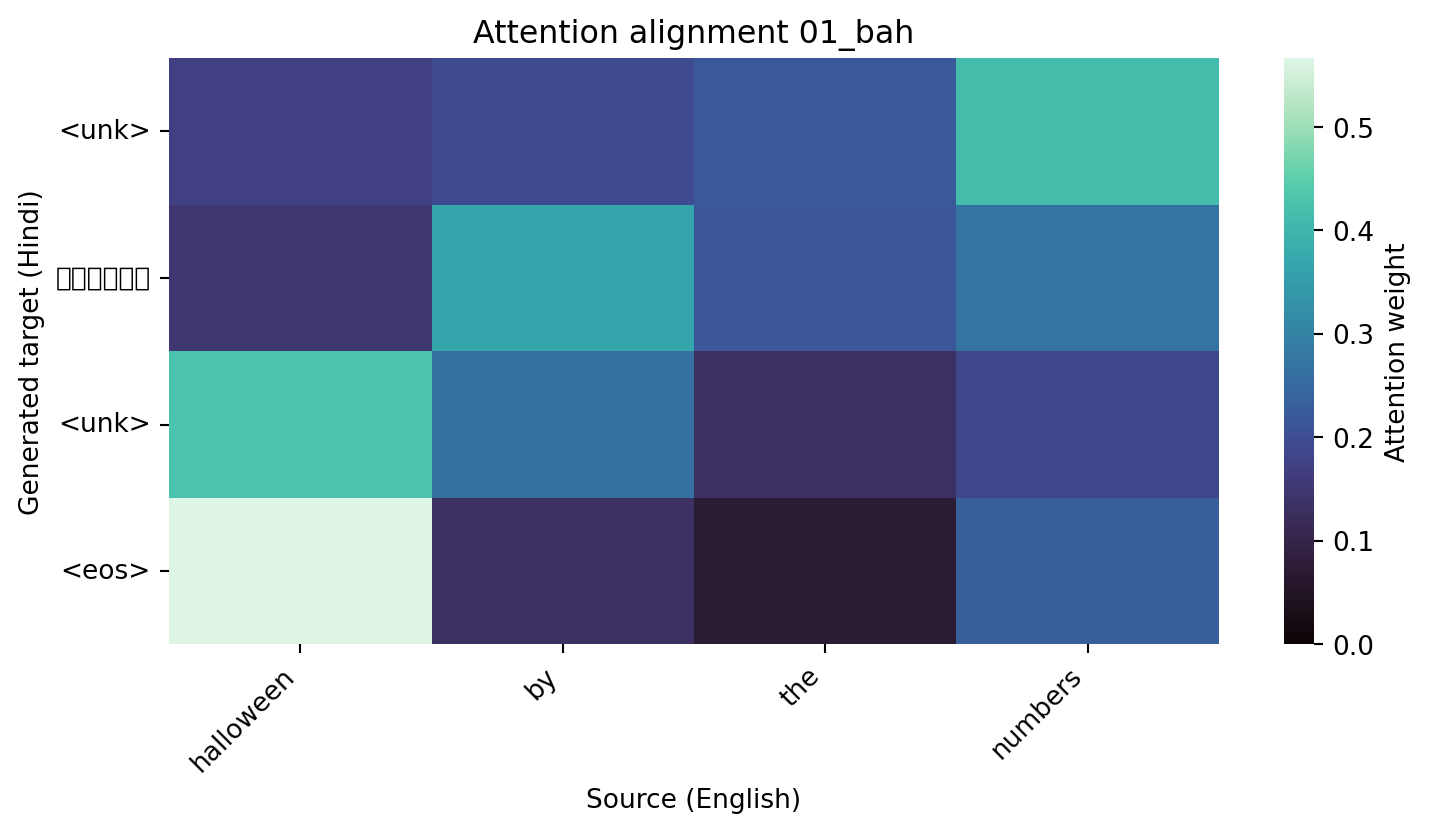

A2 heatmap 1 | model=bah
SOURCE: Halloween 2013: By the Numbers
HYPOTHESIS: <unk> द्वारा <unk>
  generated '<unk>' -> strongest source 'numbers' at position 3 (weight=0.4138)
  generated 'द्वारा' -> strongest source 'by' at position 1 (weight=0.3651)
  generated '<eos>' -> strongest source 'halloween' at position 0 (weight=0.5664)
Peak-path backward moves=2. The measured path is non-monotonic, consistent with possible reordering.


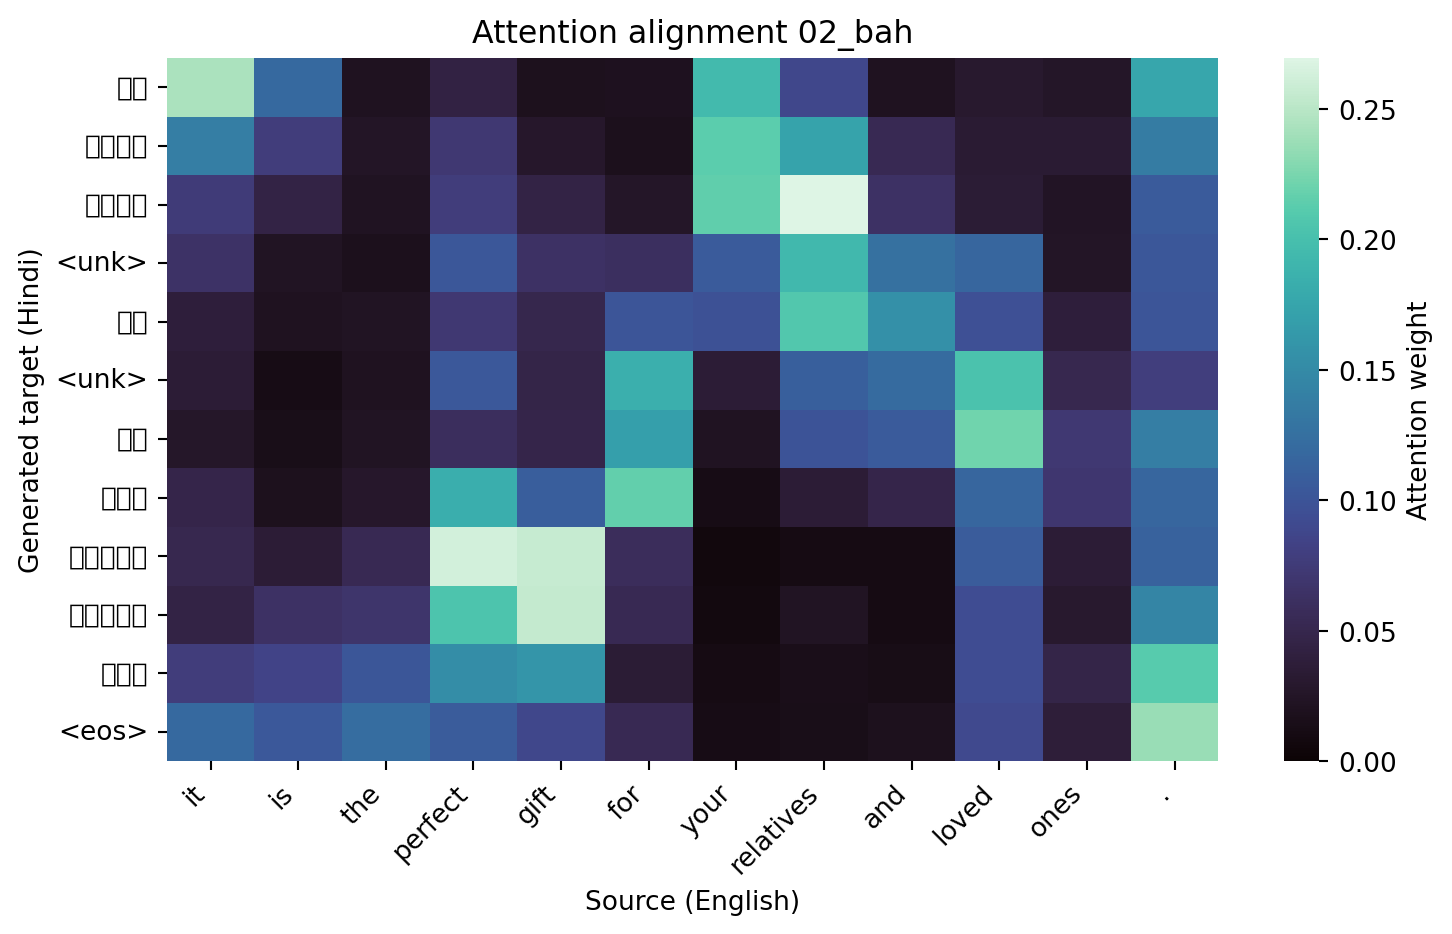

A2 heatmap 2 | model=bah
SOURCE: It is the perfect gift for your relatives and loved ones.
HYPOTHESIS: यह आपके अपने <unk> और <unk> के लिए उपहार उपहार है।
  generated 'यह' -> strongest source 'it' at position 0 (weight=0.2436)
  generated '<unk>' -> strongest source 'loved' at position 9 (weight=0.2023)
  generated '<eos>' -> strongest source '.' at position 11 (weight=0.2366)
Peak-path backward moves=2. The measured path is non-monotonic, consistent with possible reordering.
Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

In [32]:
# A2: Display and trace two real attention alignments.
from IPython.display import Image, display

_q3_restore_analysis_files()
heatmap_records = json.loads(
    (Q3_ANALYSIS_DIR / "q3_heatmap_records.json").read_text(encoding="utf-8")
)
if len(heatmap_records) < 2:
    raise ValueError("Run the five-heatmap cell before A2.")

a2_records = []
for position, record in enumerate(heatmap_records[:2], 1):
    image_path = Q3_ANALYSIS_DIR / f"q3_attention_heatmap_{position:02d}.png"
    display(Image(filename=str(image_path)))
    matrix = np.asarray(record["attention"], dtype=np.float32)
    peak_positions = matrix.argmax(axis=1).tolist() if matrix.size else []
    peak_weights = matrix.max(axis=1).tolist() if matrix.size else []
    selected_rows = sorted(set(np.linspace(
        0, max(len(record["target_tokens"]) - 1, 0),
        min(3, len(record["target_tokens"])), dtype=int,
    ).tolist()))
    traces = []
    print(f"A2 heatmap {position} | model={record['model_variant']}")
    print("SOURCE:", record["source"])
    print("HYPOTHESIS:", record["hypothesis"])
    for row in selected_rows:
        source_position = peak_positions[row]
        trace = {
            "target_token": record["target_tokens"][row],
            "source_token": record["source_tokens"][source_position],
            "source_position": source_position,
            "attention_weight": peak_weights[row],
        }
        traces.append(trace)
        print(
            f"  generated '{trace['target_token']}' -> strongest source "
            f"'{trace['source_token']}' at position {source_position} "
            f"(weight={trace['attention_weight']:.4f})"
        )
    reversals = sum(
        current < previous
        for previous, current in zip(peak_positions, peak_positions[1:])
    )
    print(
        f"Peak-path backward moves={reversals}. "
        + ("The measured path is non-monotonic, consistent with possible reordering."
           if reversals else
           "The measured peak path is monotonic; semantic adequacy must be judged from the displayed tokens.")
    )
    a2_records.append({
        "test_index": record["test_index"],
        "model_variant": record["model_variant"],
        "traces": traces,
        "peak_path_backward_moves": reversals,
    })
_q3_atomic_json_save(a2_records, Q3_ANALYSIS_DIR / "q3_a2_alignment_analysis.json")
_q3_refresh_analysis_bundle()


* **A3. Strategy Comparative Analysis:[6 Marks]** On a fixed subset of at least five test sources, compare the translation outputs generated via greedy decoding, beam search, temperature sampling, top-$k$ sampling, and top-$p$ nucleus sampling using a fixed random seed. Evaluate them based on semantic adequacy, token repetition rates, and output text diversity.



In [33]:
# A3: Fixed five-source strategy comparison using measured suite output.
_q3_restore_analysis_files()
suite = json.loads((Q3_ANALYSIS_DIR / "q3_decoding_suite.json").read_text(encoding="utf-8"))
examples = suite["qualitative_examples"]
if len(examples) < 5:
    raise ValueError("The decoding suite must contain at least five fixed examples.")

strategy_names = ["greedy", "beam_k4", "temperature", "top_k", "top_p"]
for position, row in enumerate(examples[:5], 1):
    print(f"\nA3 sample {position} | test index={row['test_index']}")
    print("SOURCE:", row["source"])
    print("REFERENCE:", row["reference"])
    for strategy in strategy_names:
        output = row["outputs"][strategy]
        print(
            f"{strategy.upper():>12}: {output['hypothesis']} "
            f"[sentence BLEU={output['sentence_bleu']:.2f}, "
            f"repeat={output['has_three_token_repeat']}]"
        )

summary = {}
for strategy in strategy_names:
    hypotheses = [row["outputs"][strategy]["hypothesis"] for row in examples[:5]]
    mean_bleu = float(np.mean([
        row["outputs"][strategy]["sentence_bleu"] for row in examples[:5]
    ]))
    repeat_rate = float(np.mean([
        row["outputs"][strategy]["has_three_token_repeat"] for row in examples[:5]
    ]))
    summary[strategy] = {
        "mean_sentence_bleu": mean_bleu,
        "repetition_rate": repeat_rate,
        **_q3_text_diversity(hypotheses),
    }
print("\n| Strategy | Mean sentence BLEU | Repeat rate | Distinct-1 | Distinct-2 | Unique outputs |")
print("|---|---:|---:|---:|---:|---:|")
for strategy in strategy_names:
    values = summary[strategy]
    print(
        f"| {strategy} | {values['mean_sentence_bleu']:.4f} | "
        f"{100 * values['repetition_rate']:.2f}% | {values['distinct_1']:.4f} | "
        f"{values['distinct_2']:.4f} | {values['unique_sentence_ratio']:.4f} |"
    )
best_adequacy = max(summary, key=lambda name: summary[name]["mean_sentence_bleu"])
most_diverse = max(summary, key=lambda name: summary[name]["distinct_2"])
print("Measured highest mean sentence BLEU:", best_adequacy)
print("Measured highest distinct-2 diversity:", most_diverse)
print("The displayed source/reference pairs remain the evidence for qualitative semantic adequacy.")
_q3_atomic_json_save(summary, Q3_ANALYSIS_DIR / "q3_a3_strategy_analysis.json")
_q3_refresh_analysis_bundle()



A3 sample 1 | test index=268
SOURCE: Halloween 2013: By the Numbers
REFERENCE: <unk> <unk> <unk> द्वारा
      GREEDY: <unk> द्वारा <unk> [sentence BLEU=38.73, repeat=False]
     BEAM_K4: <unk> की संख्या [sentence BLEU=14.63, repeat=False]
 TEMPERATURE: <unk> <unk> द्वारा [sentence BLEU=65.14, repeat=False]
       TOP_K: कर्ता द्वारा संख्या [sentence BLEU=2.67, repeat=False]
       TOP_P: कर्ता द्वारा संख्या [sentence BLEU=2.67, repeat=False]

A3 sample 2 | test index=694
SOURCE: It is the perfect gift for your relatives and loved ones.
REFERENCE: यह आपके <unk> <unk> और <unk> के लिए एक समूचा उपहार है।
      GREEDY: यह आपके अपने <unk> और <unk> के लिए उपहार उपहार है। [sentence BLEU=52.31, repeat=False]
     BEAM_K4: यह अपने <unk> और <unk> के लिए उपहार उपहार है। [sentence BLEU=49.54, repeat=False]
 TEMPERATURE: यह आपके अपने को तुम्हारे लिए दुःख के लिए उत्तम उपहार <unk> है। [sentence BLEU=12.53, repeat=False]
       TOP_K: यह अपने लोगों और अपने के लिए उपहार उपहार है। [sentence BLEU=5.90, r

PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

**Experimental (Requires Code Execution & Observations)**

* **E1. Attention Entropy Measurement:[6 Marks]** Compute the Shannon entropy of the attention distribution at every decoding step $t$ across your 5 heatmap sentences for both dot-product and Bahdanau models:
  $$-\sum_j \alpha_{t,j}\log\alpha_{t,j}$$
  Average the entropy values across steps and sentences. Which attention architecture produces sharper, more concentrated (lower-entropy) alignment distributions?


In [34]:
# E1: Shannon entropy for both attention models across the same five sentences.
def _q3_sentence_attention_entropy(model, src_text):
    run_device = next(model.parameters()).device
    src_tensor = torch.tensor([encode_en(src_text)], dtype=torch.long, device=run_device)
    predicted, attention = model.greedy_decode(src_tensor, return_attn=True)
    valid_source = int(src_tensor.ne(stoi_en[PAD]).sum().item())
    token_ids = predicted[0].tolist()
    generated_steps = next(
        (index + 1 for index, token in enumerate(token_ids) if token == stoi_hi[EOS]),
        len(token_ids),
    )
    probabilities = attention[0, :generated_steps, :valid_source].float()
    probabilities = probabilities / probabilities.sum(dim=-1, keepdim=True).clamp_min(1e-12)
    entropy_by_step = -(
        probabilities.clamp_min(1e-12) * probabilities.clamp_min(1e-12).log()
    ).sum(dim=-1)
    return entropy_by_step.cpu().tolist()


_q3_restore_analysis_files()
heatmap_records = json.loads(
    (Q3_ANALYSIS_DIR / "q3_heatmap_records.json").read_text(encoding="utf-8")
)
entropy_result = {"sentences": [], "aggregate_mean": {}}
for record in heatmap_records[:5]:
    entropy_result["sentences"].append({
        "test_index": record["test_index"], "source": record["source"]
    })

for variant in ("dot", "bah"):
    model = _q3_load_completed_model(variant)
    all_steps = []
    for row in entropy_result["sentences"]:
        values = _q3_sentence_attention_entropy(model, row["source"])
        row[f"{variant}_entropy_by_step"] = values
        row[f"{variant}_mean_entropy"] = float(np.mean(values)) if values else 0.0
        all_steps.extend(values)
    entropy_result["aggregate_mean"][variant] = float(np.mean(all_steps)) if all_steps else 0.0
    model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("| Test index | Dot mean entropy | Bahdanau mean entropy |")
print("|---:|---:|---:|")
for row in entropy_result["sentences"]:
    print(
        f"| {row['test_index']} | {row['dot_mean_entropy']:.6f} | "
        f"{row['bah_mean_entropy']:.6f} |"
    )
dot_entropy = entropy_result["aggregate_mean"]["dot"]
bah_entropy = entropy_result["aggregate_mean"]["bah"]
sharper = "Dot Product" if dot_entropy < bah_entropy else "Bahdanau"
print(f"Aggregate Dot entropy: {dot_entropy:.6f}")
print(f"Aggregate Bahdanau entropy: {bah_entropy:.6f}")
print(f"Measured sharper (lower-entropy) attention: {sharper}")
entropy_result["sharper_model"] = sharper
_q3_atomic_json_save(entropy_result, Q3_ANALYSIS_DIR / "q3_entropy_analysis.json")
_q3_refresh_analysis_bundle()


Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
| Test index | Dot mean entropy | Bahdanau mean entropy |
|---:|---:|---:|
| 268 | 0.310985 | 1.264740 |
| 694 | 0.270184 | 2.184726 |
| 814 | 0.921467 | 2.569932 |
| 510 | 0.487329 | 2.631411 |
| 745 | 0.582106 | 2.892242 |
Aggregate Dot entropy: 0.562577
Aggregate Bahdanau entropy: 2.544664
Measured sharper (lower-entropy) attention: Dot Product
Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

* **E2. Repetition Failure Tracking & Heatmap Diagnosis:[7 Marks]** Scan your test predictions for instances where the exact same target word is repeated 3 or more times consecutively. Report the frequency of this occurrence across both attention models, and extract the attention heatmap of one failed repetitive example to diagnose how the attention weights behaved during the loop.


Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt
dot: repeated >=3 consecutive times in 566/881 hypotheses (64.2452%).
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/bah/q3_bah_resume.pt
bah: repeated >=3 consecutive times in 508/881 hypotheses (57.6617%).
Diagnostic failure model: dot
SOURCE: Due to financial constraints Dhirubhai had to drop out after high school.
REFERENCE: आर्थिक तंगी के कारण <unk> को <unk> के बाद ही पढ़ाई छोड़ना पड़ गई।
HYPOTHESIS: वित्तीय <unk> के कारण <unk> के बाद <unk> <unk> के बाद <unk> <unk> <unk>
Using current Q3 checkpoint: /kaggle/working/q3_artifacts/dot/q3_dot_resume.pt


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/loc

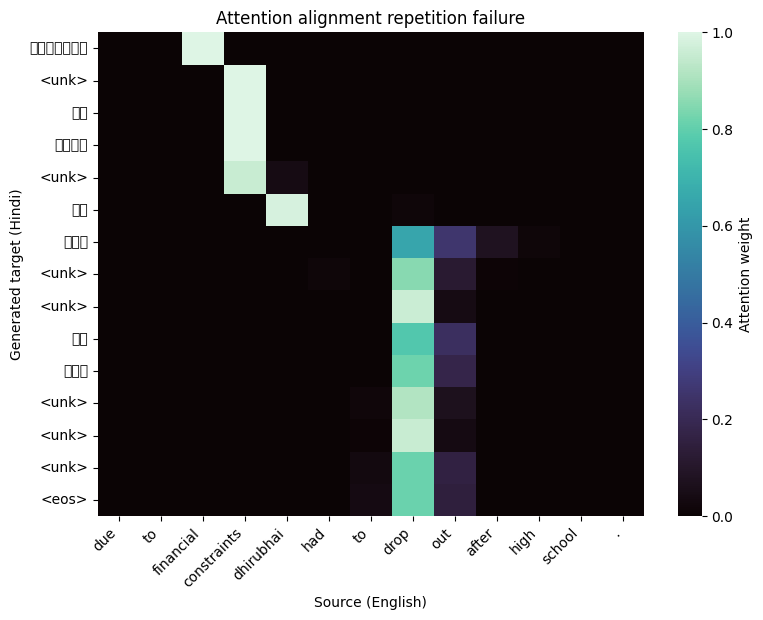

Updated restart-safe Q3 analysis bundle: /kaggle/working/q3_analysis_artifacts.zip


PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

In [35]:
# E2: Real repetition frequencies and one genuine failure heatmap when available.
_q3_restore_analysis_files()
repetition_result = {"repeat_threshold": 3, "models": {}, "diagnostic": None}
first_failure = None
for variant in ("dot", "bah"):
    predictions = _q3_load_json(variant, "predictions")
    hypotheses = [row["hypothesis"] for row in predictions]
    repeated_positions = count_repetitive_hypotheses(hypotheses, repeat_threshold=3)
    examples = [predictions[position] for position in repeated_positions[:10]]
    repetition_result["models"][variant] = {
        "evaluated": len(predictions),
        "repetition_count": len(repeated_positions),
        "repetition_rate": len(repeated_positions) / max(len(predictions), 1),
        "examples": examples,
    }
    print(
        f"{variant}: repeated >=3 consecutive times in {len(repeated_positions)}/"
        f"{len(predictions)} hypotheses "
        f"({100 * len(repeated_positions) / max(len(predictions), 1):.4f}%)."
    )
    if first_failure is None and repeated_positions:
        first_failure = (variant, predictions[repeated_positions[0]])

if first_failure is None:
    print("No genuine three-token repetition failure was found; no failure heatmap is fabricated.")
else:
    failure_variant, failure = first_failure
    print("Diagnostic failure model:", failure_variant)
    print("SOURCE:", failure["source"])
    print("REFERENCE:", failure["reference"])
    print("HYPOTHESIS:", failure["hypothesis"])
    failure_model = _q3_load_completed_model(failure_variant)
    diagnostic = plot_attention_heatmap(
        failure_model, failure["source"], idx_tag="repetition failure",
        output_path=Q3_ANALYSIS_DIR / "q3_repetition_failure_heatmap.png",
    )
    diagnostic.update({
        "model_variant": failure_variant,
        "test_index": failure["index"],
        "reference": failure["reference"],
    })
    repetition_result["diagnostic"] = diagnostic
    failure_model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

_q3_atomic_json_save(repetition_result, Q3_ANALYSIS_DIR / "q3_repetition_analysis.json")
_q3_refresh_analysis_bundle()


* **E3. Systematic Decoding Suite Benchmark:[7 Marks]** Execute decoding suite on your test subset using beam widths $k \in \{2, 4, 8\}$ alongside temperature, top-$k$, and top-$p$ sampling. Report deterministic BLEU scores across beam widths, and for stochastic sampling, report the seed, repetition/diversity metrics, and representative qualitative examples.

In [36]:
# E3: Report the completed, resumable decoding benchmark without recomputation.
_q3_restore_analysis_files()
suite = json.loads((Q3_ANALYSIS_DIR / "q3_decoding_suite.json").read_text(encoding="utf-8"))
configuration = suite["configuration"]
print("E3 model variant:", configuration["model_variant"])
print("Fixed stochastic seed:", configuration["seed"])
print(
    "Sampling parameters:",
    {"temperature": configuration["temperature"],
     "top_k": configuration["top_k"], "top_p": configuration["top_p"]},
)
print("Beam benchmark examples:", len(configuration["benchmark_indices"]))
print("| Beam width | Deterministic SacreBLEU | Examples |")
print("|---:|---:|---:|")
for width in configuration["beam_widths"]:
    values = suite["beam_bleu"][str(width)]
    print(f"| {width} | {values['bleu']:.4f} | {values['examples']} |")

print("\n| Stochastic strategy | BLEU | Repeat rate | Distinct-1 | Distinct-2 |")
print("|---|---:|---:|---:|---:|")
for name, values in suite["sampling_metrics"].items():
    print(
        f"| {name} | {values['bleu']:.4f} | "
        f"{100 * values['repetition_rate']:.2f}% | "
        f"{values['distinct_1']:.4f} | {values['distinct_2']:.4f} |"
    )
print("\nRepresentative fixed examples")
for row in suite["qualitative_examples"][:2]:
    print("SOURCE:", row["source"])
    print("REFERENCE:", row["reference"])
    for name, output in row["outputs"].items():
        print(f"  {name}: {output['hypothesis']}")
_q3_atomic_json_save(
    {"configuration": configuration, "beam_bleu": suite["beam_bleu"],
     "sampling_metrics": suite["sampling_metrics"]},
    Q3_ANALYSIS_DIR / "q3_e3_benchmark_summary.json",
)
_q3_refresh_analysis_bundle()


E3 model variant: bah
Fixed stochastic seed: 3042
Sampling parameters: {'temperature': 0.8, 'top_k': 20, 'top_p': 0.9}
Beam benchmark examples: 128
| Beam width | Deterministic SacreBLEU | Examples |
|---:|---:|---:|
| 2 | 17.8167 | 128 |
| 4 | 19.5408 | 128 |
| 8 | 21.2827 | 128 |

| Stochastic strategy | BLEU | Repeat rate | Distinct-1 | Distinct-2 |
|---|---:|---:|---:|---:|
| temperature | 18.0631 | 14.84% | 0.3069 | 0.7169 |
| top_k | 15.7346 | 5.47% | 0.2884 | 0.7084 |
| top_p | 14.1416 | 7.03% | 0.3631 | 0.8199 |

Representative fixed examples
SOURCE: Halloween 2013: By the Numbers
REFERENCE: <unk> <unk> <unk> द्वारा
  greedy: <unk> द्वारा <unk>
  beam_k4: <unk> की संख्या
  temperature: <unk> <unk> द्वारा
  top_k: कर्ता द्वारा संख्या
  top_p: कर्ता द्वारा संख्या
SOURCE: It is the perfect gift for your relatives and loved ones.
REFERENCE: यह आपके <unk> <unk> और <unk> के लिए एक समूचा उपहार है।
  greedy: यह आपके अपने <unk> और <unk> के लिए उपहार उपहार है।
  beam_k4: यह अपने <unk> और

PosixPath('/kaggle/working/q3_analysis_artifacts.zip')

### Question 3 Kaggle restart and download notes

The two attention models are launched from one training cell. On a two-GPU runtime, Dot Product is assigned to `cuda:0` and Bahdanau to `cuda:1` concurrently. On a one-GPU or CPU runtime, the same cell runs them sequentially. A protected resume checkpoint and refreshed per-model bundle are written after every completed epoch.

For a fresh Kaggle session, run cells **9, 46, 116, 120, 122, 124, 127, 130, 133, and 138** in that order to reconstruct the shared imports, scratch `GRUCell`, translation data, vocabularies, datasets/loaders, and `Encoder` without rerunning Q1/Q2 training. Then run Q3 cells **200, 204, 208, 211, 214, 215, 216, and 217** in order; cell **216** is the no-training sanity check and cell **217** is the sole paired training launch. After training, run evaluation/analysis cells **219, 222, 223, 227, 230, 233, 241, 243, 245, 247, 249, 251, and 253** in order. These are one-based notebook cell numbers for this saved file.

If Kaggle persistence retained `/kaggle/working`, no upload is needed. Otherwise, attach exactly one model-state source: preferably `q3_training_artifacts.zip`, the two separate per-model bundles together, or `q3_all_artifacts.zip` by itself. If resuming partway through the analysis, `q3_analysis_artifacts.zip` may accompany the training bundle; the final all-artifacts bundle already includes both model and analysis state. Also attach `q2_all_artifacts.zip` so the measured no-attention baseline can be included in A1 and the length comparison. Set `Q3_PREVIOUS_ARTIFACT_DIR` only if those files are outside Kaggle's automatically searched `/kaggle/input` tree. Do not attach overlapping model-state sources such as both `q3_training_artifacts.zip` and `q3_all_artifacts.zip`, because the loader deliberately rejects ambiguous resumes.

The final cell validates all required outputs before producing `q3_all_artifacts.zip`. Kaggle cannot reliably auto-download files to the local browser, so every downloadable path is printed and all artifacts remain under `/kaggle/working` for manual download or Save Version output persistence.


In [38]:
# --- Question 3 final validation and downloadable archive ---
def _q3_validate_submission_checkpoint(path: Path, variant: str):
    try:
        payload = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        payload = torch.load(path, map_location="cpu")
    if not isinstance(payload, dict) or set(payload) != {"encoder", "decoder"}:
        raise RuntimeError(
            f"{path.name} must contain exactly the encoder and decoder state-dict pair."
        )
    probe = _q3_make_model(variant)
    probe.encoder.load_state_dict(payload["encoder"], strict=True)
    probe.decoder.load_state_dict(payload["decoder"], strict=True)
    return count_parameters(probe)


_q3_restore_analysis_files()
required_analysis = [
    "q3_bleu_comparison.json",
    "q3_loss_comparison.png",
    "q3_heatmap_manifest.json",
    "q3_decoding_suite.json",
    "q3_length_analysis.json",
    "q3_a1_analysis.json",
    "q3_a2_alignment_analysis.json",
    "q3_a3_strategy_analysis.json",
    "q3_entropy_analysis.json",
    "q3_repetition_analysis.json",
    "q3_e3_benchmark_summary.json",
]
required_analysis.extend(f"q3_attention_heatmap_{index:02d}.png" for index in range(1, 6))

missing = []
for variant in ("dot", "bah"):
    paths = _q3_paths(variant)
    for key in ("resume", "best", "history", "result", "predictions",
                "examples", "config", "plot", "readme", "deliverable_path", "bundle"):
        if not paths[key].is_file():
            missing.append(str(paths[key]))
for name in ("q3_progress_manifest.json", "vocab_en.json", "vocab_hi.json",
             "q3_training_artifacts.zip", "q3_analysis_artifacts.zip"):
    path = _Q3_RUNTIME_ROOT / name
    if not path.is_file():
        missing.append(str(path))
for name in required_analysis:
    path = Q3_ANALYSIS_DIR / name
    if not path.is_file():
        missing.append(str(path))
if missing:
    raise RuntimeError(
        "Question 3 is not ready to archive. Run the remaining Q3 cells first:\n- "
        + "\n- ".join(missing)
    )

progress = _q3_load_progress()
for variant in ("dot", "bah"):
    paths = _q3_paths(variant)
    experiment_name = paths["experiment_name"]
    if progress.get(experiment_name, {}).get("status") != "complete":
        raise RuntimeError(f"Q3 {variant} training is not marked complete.")
    history = json.loads(paths["history"].read_text(encoding="utf-8"))
    config = json.loads(paths["config"].read_text(encoding="utf-8"))
    result = json.loads(paths["result"].read_text(encoding="utf-8"))
    predictions = json.loads(paths["predictions"].read_text(encoding="utf-8"))
    _q3_validate_config(config, _q3_config(variant))
    if history.get("epoch") != list(range(1, Q3_TRAINING_EPOCHS + 1)):
        raise RuntimeError(f"Q3 {variant} history does not contain four completed epochs.")
    if result.get("status") != "complete" or result.get("completed_epochs") != Q3_TRAINING_EPOCHS:
        raise RuntimeError(f"Q3 {variant} result is incomplete.")
    if len(predictions) != len(test_dataset) or result.get("test_examples") != len(test_dataset):
        raise RuntimeError(f"Q3 {variant} does not contain full-test predictions.")

bleu_payload = json.loads((Q3_ANALYSIS_DIR / "q3_bleu_comparison.json").read_text(encoding="utf-8"))
if set(("no_attention", "dot", "bah")) - set(bleu_payload):
    raise RuntimeError("The no-attention/Dot/Bahdanau BLEU table is incomplete.")
decoding_payload = json.loads((Q3_ANALYSIS_DIR / "q3_decoding_suite.json").read_text(encoding="utf-8"))
if set(decoding_payload.get("beam_bleu", {})) != {"2", "4", "8"}:
    raise RuntimeError("Beam-width BLEU results for k={2,4,8} are incomplete.")
if len(decoding_payload.get("qualitative_examples", [])) < 5:
    raise RuntimeError("The fixed decoding comparison requires at least five examples.")
if set(decoding_payload.get("sampling_metrics", {})) != {"temperature", "top_k", "top_p"}:
    raise RuntimeError("The stochastic decoding benchmark is incomplete.")
entropy_payload = json.loads((Q3_ANALYSIS_DIR / "q3_entropy_analysis.json").read_text(encoding="utf-8"))
if set(entropy_payload.get("aggregate_mean", {})) != {"dot", "bah"} or len(entropy_payload.get("sentences", [])) != 5:
    raise RuntimeError("The two-model, five-sentence entropy experiment is incomplete.")
repetition_payload = json.loads((Q3_ANALYSIS_DIR / "q3_repetition_analysis.json").read_text(encoding="utf-8"))
if set(repetition_payload.get("models", {})) != {"dot", "bah"}:
    raise RuntimeError("The two-model repetition scan is incomplete.")

validated_parameters = {}
for variant in ("dot", "bah"):
    checkpoint = _Q3_RUNTIME_ROOT / _Q3_VARIANTS[variant]["deliverable"]
    validated_parameters[variant] = _q3_validate_submission_checkpoint(checkpoint, variant)

heatmap_manifest = json.loads(
    (Q3_ANALYSIS_DIR / "q3_heatmap_manifest.json").read_text(encoding="utf-8")
)
if len(heatmap_manifest.get("examples", [])) != 5:
    raise RuntimeError("The Q3 heatmap deliverable must contain exactly five examples.")

all_bundle = _Q3_RUNTIME_ROOT / "q3_all_artifacts.zip"
temporary = Path(str(all_bundle) + ".tmp")
with ZipFile(temporary, "w", ZIP_DEFLATED) as archive:
    # Root-level files are convenient for direct submission and reloading.
    for name in ("q3_seq2seq_dot.pt", "q3_seq2seq_bah.pt",
                 "q3_progress_manifest.json", "vocab_en.json", "vocab_hi.json"):
        artifact = _Q3_RUNTIME_ROOT / name
        archive.write(
            artifact, arcname=name,
            compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
        )
    # The raw tree contains all resumable states, histories, measured results,
    # predictions, figures, and written-analysis evidence without nested ZIP copies.
    redundant_models = {
        _q3_paths("dot")["model"].name, _q3_paths("bah")["model"].name
    }
    for artifact in sorted(Q3_OUTPUT_DIR.rglob("*")):
        if artifact.is_file() and artifact.name not in redundant_models:
            archive.write(
                artifact, arcname=str(artifact.relative_to(_Q3_RUNTIME_ROOT)),
                compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
            )
os.replace(temporary, all_bundle)

print("Question 3 final validation passed.")
print("Question 3 protected at:", all_bundle)
print("Download it from Kaggle Files/Output before ending the session.")
print("Validated parameter counts:", validated_parameters)
print("Download these files from Kaggle Output:")
for path in (
    _Q3_RUNTIME_ROOT / "q3_seq2seq_dot.pt",
    _Q3_RUNTIME_ROOT / "q3_seq2seq_bah.pt",
    _Q3_RUNTIME_ROOT / "q3_dot_model_bundle.zip",
    _Q3_RUNTIME_ROOT / "q3_bahdanau_model_bundle.zip",
    _Q3_RUNTIME_ROOT / "q3_training_artifacts.zip",
    _Q3_RUNTIME_ROOT / "q3_analysis_artifacts.zip",
    all_bundle,
):
    print(f"  {path} ({path.stat().st_size / (1024 ** 2):.2f} MiB)")


Question 3 final validation passed.
Question 3 protected at: /kaggle/working/q3_all_artifacts.zip
Download it from Kaggle Files/Output before ending the session.
Validated parameter counts: {'dot': 20223832, 'bah': 20190680}
Download these files from Kaggle Output:
  /kaggle/working/q3_seq2seq_dot.pt (77.16 MiB)
  /kaggle/working/q3_seq2seq_bah.pt (77.04 MiB)
  /kaggle/working/q3_dot_model_bundle.zip (386.18 MiB)
  /kaggle/working/q3_bahdanau_model_bundle.zip (385.55 MiB)
  /kaggle/working/q3_training_artifacts.zip (771.55 MiB)
  /kaggle/working/q3_analysis_artifacts.zip (0.59 MiB)
  /kaggle/working/q3_all_artifacts.zip (772.14 MiB)


# **Question 4 - Implement RNN, LSTM, GRU using pytorch functions and repeat 2 and 3 above and compare the your implementation with pytorch implementation.[Total = 160 Marks]**  


Here is a step-by-step breakdown of what you need to do:

Tasks to Complete
Implement Native Encoders: Build NativeRNSEncoder, NativeLSTMEncoder, and NativeGRUEncoder utilizing nn.RNN, nn.LSTM, and nn.GRU.

Implement Step-Wise Decoders: Build plain and attention-augmented decoders using nn.RNNCell, nn.LSTMCell, and nn.GRUCell.

Train & Save Artifacts: Train the native GRU variants (No-Attention, Dot-Product Attention, Bahdanau Attention) and save their weights as q4_native_noattn.pt, q4_native_dot.pt, and q4_native_bah.pt.

Execute Comparative Evaluation: Run the comparative BLEU evaluation suite across scratch vs. native implementations on the test set.

In Questions 1 through 3, we built every single recurrent cell (`RNNCell`, `LSTMCell`, `GRUCell`), unrolling loop, encoder, and decoder using PyTorch tensor operations.

Building models from scratch is the best way to understand the underlying mathematical equations. However, in production environments, custom Python `for` loops over sequence timesteps create noticeable overhead:

```python
# Our Custom Loop (Question 1 - 3): Python overhead at EVERY timestep
for t in range(seq_len):
    h = cell(x[:, t, :], h)  # Triggers a separate CUDA kernel launch per step!

```

In this section, we replace our custom cells and sequence wrappers with **PyTorch’s built-in layers** (`nn.GRU` and `nn.GRUCell`). We will benchmark them against our custom implementations to measure speedups, memory efficiency, and translation performance.


Why PyTorch Native Layers Are Faster

PyTorch built-in layers like `nn.GRU` and `nn.LSTM` bypass the Python interpreter's loop overhead by utilizing **NVIDIA cuDNN C++ kernels**:

1. **Kernel Fusion:** Multiple matrix multiplications across timesteps are fused into a single optimized C++ GPU call.
2. **Packed Weights:** Weight matrices for all gates are stored in contiguous memory blocks rather than as separate `nn.Linear` objects.
3. **Reduced Memory Transfers:** Intermediate activation states remain in fast GPU cache memory rather than being constantly allocated and freed in Python memory.

```
Custom Loop:   [Python Loop] --> [Launch GPU Kernel t=1] --> [Launch GPU Kernel t=2] --> ...
Native nn.GRU: [Python Call] --> [Single Optimized C++/cuDNN GPU Execution]

```

###Model Implementation[80 marks]

Before filling out the code below, familiarize yourself with these core components:

Custom Bidirectional Encoder (CustomEncoder): Integrates token embeddings, a multi-layer bidirectional custom recurrent encoder (RecurrentEncoder), and a linear bridge layer to project concatenated forward-backward states down to the decoder's hidden dimension.

LSTM Tuple State Handling (is_lstm): Manages the structural difference between single hidden states (h for RNN/GRU) and dual state tuples ((h, c) for LSTM) across encoder and decoder handoffs.

In [22]:
class CustomEncoder(nn.Module):
    """Two-layer bidirectional encoder built from the Question 1 scratch cells."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 cell_cls: type, is_lstm: bool = False, num_layers: int = 2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = RecurrentEncoder(
            cell_cls, emb_dim, hidden_size, num_layers=num_layers,
            bidirectional=True, is_lstm=is_lstm,
        )
        self.bridge = nn.Linear(2 * hidden_size, hidden_size)
        self.is_lstm = is_lstm

    def forward(self, src: torch.Tensor):
        emb = self.embedding(src)
        outputs, final_h_tensor = self.rnn(emb)
        dec_h0 = torch.tanh(self.bridge(final_h_tensor))
        if self.is_lstm:
            dec_c0 = torch.zeros_like(dec_h0)
            return outputs, (dec_h0, dec_c0)
        return outputs, dec_h0


Before filling out the code below, familiarize yourself with these core components:

Step-Wise Unidirectional Decoder (CustomDecoderStep): Advances autoregressive generation one token at a time using custom recurrent cells (RNNCell, LSTMCell, or GRUCell) across stacked layers.

ModuleList Architecture Routing: Dynamically configures input dimensions for layer zero versus upper stacked layers to support arbitrary hidden depths.

In [23]:
class CustomDecoderStep(nn.Module):
    """Step-wise stacked decoder using a selected Question 1 scratch cell."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 cell_cls: type, is_lstm: bool = False, num_layers: int = 2):
        super().__init__()
        self.vocab_size = vocab_size
        self.emb_dim = emb_dim
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.is_lstm = is_lstm
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.cells = nn.ModuleList([
            cell_cls(emb_dim if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size, vocab_size)

    def hidden_step(self, tok: torch.Tensor, states: list):
        x = self.embedding(tok)
        new_states = []
        inp = x
        for layer, cell in enumerate(self.cells):
            if self.is_lstm:
                h_prev, c_prev = states[layer]
                h_next, c_next = cell(inp, (h_prev, c_prev))
                new_states.append((h_next, c_next))
                inp = h_next
            else:
                h_prev = states[layer]
                h_next = cell(inp, h_prev)
                new_states.append(h_next)
                inp = h_next
        return new_states

    def forward(self, tok: torch.Tensor, states: list):
        new_states = self.hidden_step(tok, states)
        top_hidden = new_states[-1][0] if self.is_lstm else new_states[-1]
        logits = self.out(top_hidden)
        return logits, new_states


Before filling out the code below, familiarize yourself with these core components:

Native PyTorch RNN Encoder (NativeRNSEncoder): Leverages PyTorch's optimized nn.RNN module in bidirectional mode to process input sequences.

Hidden State Reshaping & Bridging: Extracts and concatenates the forward and backward hidden states of the top layer, projecting them via a linear layer + tanh to initialize the unidirectional decoder.

In [24]:
# --- 1. Native Encoders using nn.RNN, nn.LSTM, and nn.GRU ---
class NativeRNSEncoder(nn.Module):
    """Two-layer bidirectional encoder using PyTorch's optimized nn.RNN."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = nn.RNN(
            emb_dim, hidden_size, num_layers=num_layers, bidirectional=True,
            batch_first=True,
        )
        self.bridge = nn.Linear(2 * hidden_size, hidden_size)

    def forward(self, src: torch.Tensor):
        emb = self.embedding(src)
        lengths = src.ne(0).sum(dim=1).clamp_min(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, h_n = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        h_n = h_n.reshape(self.num_layers, 2, src.size(0), self.hidden_size)
        top_fwd = h_n[-1, 0]
        top_bwd = h_n[-1, 1]
        top_layer_combined = torch.cat([top_fwd, top_bwd], dim=-1)
        dec_h0 = torch.tanh(self.bridge(top_layer_combined))
        return outputs, dec_h0


Before filling out the code below, familiarize yourself with these core components:

Native Bidirectional LSTM Encoder (NativeLSTMEncoder): Utilizes nn.LSTM to process sequences and return both hidden states (h_n) and cell states (c_n).

Dual State Bridging (bridge_h, bridge_c): Employs separate linear bridge projections to map both top-layer hidden states and cell states down to the decoder dimensions.

In [25]:
class NativeLSTMEncoder(nn.Module):
    """Two-layer bidirectional encoder using PyTorch's optimized nn.LSTM."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            emb_dim, hidden_size, num_layers=num_layers, bidirectional=True,
            batch_first=True,
        )
        self.bridge_h = nn.Linear(2 * hidden_size, hidden_size)
        self.bridge_c = nn.Linear(2 * hidden_size, hidden_size)

    def forward(self, src: torch.Tensor):
        emb = self.embedding(src)
        lengths = src.ne(0).sum(dim=1).clamp_min(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, (h_n, c_n) = self.lstm(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        h_n = h_n.reshape(self.num_layers, 2, src.size(0), self.hidden_size)
        c_n = c_n.reshape(self.num_layers, 2, src.size(0), self.hidden_size)
        top_fwd_h, top_bwd_h = h_n[-1, 0], h_n[-1, 1]
        top_fwd_c, top_bwd_c = c_n[-1, 0], c_n[-1, 1]
        dec_h0 = torch.tanh(self.bridge_h(torch.cat([top_fwd_h, top_bwd_h], dim=-1)))
        dec_c0 = torch.tanh(self.bridge_c(torch.cat([top_fwd_c, top_bwd_c], dim=-1)))
        return outputs, (dec_h0, dec_c0)


Before filling out the code below, familiarize yourself with these core components:

Native Bidirectional GRU Encoder (NativeGRUEncoder): Encapsulates sequence feature extraction using PyTorch's high-performance nn.GRU module.

Single-State GRU Bridging: Combines bidirectional outputs into a unified vector before applying a linear bridge and activation function to seed the decoder hidden state.

In [26]:
class NativeGRUEncoder(nn.Module):
    """Two-layer bidirectional encoder using PyTorch's optimized nn.GRU."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.gru = nn.GRU(
            emb_dim, hidden_size, num_layers=num_layers, bidirectional=True,
            batch_first=True,
        )
        self.bridge = nn.Linear(2 * hidden_size, hidden_size)

    def forward(self, src: torch.Tensor):
        emb = self.embedding(src)
        lengths = src.ne(0).sum(dim=1).clamp_min(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, h_n = self.gru(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        h_n = h_n.reshape(self.num_layers, 2, src.size(0), self.hidden_size)
        top_layer_combined = torch.cat([h_n[-1, 0], h_n[-1, 1]], dim=-1)
        dec_h0 = torch.tanh(self.bridge(top_layer_combined))
        return outputs, dec_h0


Before filling out the code below, familiarize yourself with these core components:

Native Step-Wise RNN Decoder (NativeRNNDecoderStep): Implements unrolled single-step decoding using PyTorch's built-in nn.RNNCell modules organized within an nn.ModuleList.

Linear Vocabulary Projection: Maps the hidden representation of the final recurrent layer into vocabulary-sized logits via a linear output layer (self.out).

In [27]:
# --- 2. Native Step-Wise Decoders using nn.RNNCell, nn.LSTMCell, and nn.GRUCell ---
class NativeRNNDecoderStep(nn.Module):
    """Step-wise plain decoder using built-in nn.RNNCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.cells = nn.ModuleList([
            nn.RNNCell(emb_dim if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list):
        inp = self.embedding(tok)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(inp, hidden_states[layer])
            new_states.append(hidden)
            inp = hidden
        return new_states

    def forward(self, tok: torch.Tensor, hidden_states: list):
        new_states = self.hidden_step(tok, hidden_states)
        logits = self.out(new_states[-1])
        return logits, new_states


Before filling out the code below, familiarize yourself with these core components:

Native Step-Wise LSTM Decoder (NativeLSTMDecoderStep): Coordinates step-by-step target token generation using built-in nn.LSTMCell cells.

Tuple State Propagation: Safely handles and updates the dual-state (h, c) tuple representation across all stacked decoding layers.

In [28]:
class NativeLSTMDecoderStep(nn.Module):
    """Step-wise plain decoder using built-in nn.LSTMCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.cells = nn.ModuleList([
            nn.LSTMCell(emb_dim if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size, vocab_size)

    def hidden_step(self, tok: torch.Tensor, states: list):
        inp = self.embedding(tok)
        new_states = []
        for layer, cell in enumerate(self.cells):
            h_prev, c_prev = states[layer]
            h_next, c_next = cell(inp, (h_prev, c_prev))
            new_states.append((h_next, c_next))
            inp = h_next
        return new_states

    def forward(self, tok: torch.Tensor, states: list):
        new_states = self.hidden_step(tok, states)
        logits = self.out(new_states[-1][0])
        return logits, new_states


Before filling out the code below, familiarize yourself with these core components:

Native Step-Wise GRU Decoder (NativeGRUDecoderStep): Operates step-by-step generation loops utilizing PyTorch's native nn.GRUCell recurrent units.

Hidden State Continuity: Chains hidden state outputs sequentially from layer to layer during each decoding timestep.

In [29]:
class NativeGRUDecoderStep(nn.Module):
    """Step-wise plain decoder using built-in nn.GRUCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.cells = nn.ModuleList([
            nn.GRUCell(emb_dim if layer == 0 else hidden_size, hidden_size)
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list):
        inp = self.embedding(tok)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(inp, hidden_states[layer])
            new_states.append(hidden)
            inp = hidden
        return new_states

    def forward(self, tok: torch.Tensor, hidden_states: list):
        new_states = self.hidden_step(tok, hidden_states)
        logits = self.out(new_states[-1])
        return logits, new_states


Before filling out the code below, familiarize yourself with these core components:

Attention-Augmented RNN Decoder (NativeAttnRNNDecoderStep): Combines target token embeddings with dynamic context vectors computed via attention modules over encoder outputs.

Concatenated Feature Input (emb_dim + enc_hidden): Scales the input dimension of the first recurrent layer to accommodate both the embedded token and the retrieved encoder context.

In [30]:
# --- 3. Attention-Augmented Native Decoders ---
class NativeAttnRNNDecoderStep(nn.Module):
    """Step-wise attention decoder using built-in nn.RNNCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 enc_hidden: int, attention_module: nn.Module,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.attention = attention_module
        self.cells = nn.ModuleList([
            nn.RNNCell(
                emb_dim + enc_hidden if layer == 0 else hidden_size,
                hidden_size,
            )
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size + enc_hidden, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list,
                    enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        x = self.embedding(tok)
        context, weights = self.attention(hidden_states[-1], enc_outputs, mask)
        inp = torch.cat([x, context], dim=1)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(inp, hidden_states[layer])
            new_states.append(hidden)
            inp = hidden
        features = torch.cat([new_states[-1], context], dim=1)
        return new_states, weights, features

    def forward(self, tok: torch.Tensor, hidden_states: list,
                enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        new_states, weights, features = self.hidden_step(
            tok, hidden_states, enc_outputs, mask
        )
        logits = self.out(features)
        return logits, new_states, weights


Before filling out the code below, familiarize yourself with these core components:

Attention-Augmented LSTM Decoder (NativeAttnLSTMDecoderStep): Integrates explicit context vector injection with step-wise LSTM cell updates.

Top-Layer State Extraction (states[-1][0]): Queries the attention mechanism using the hidden state component of the topmost LSTM layer tuple.

In [31]:
class NativeAttnLSTMDecoderStep(nn.Module):
    """Step-wise attention decoder using built-in nn.LSTMCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 enc_hidden: int, attention_module: nn.Module,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.attention = attention_module
        self.cells = nn.ModuleList([
            nn.LSTMCell(
                emb_dim + enc_hidden if layer == 0 else hidden_size,
                hidden_size,
            )
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size + enc_hidden, vocab_size)

    def hidden_step(self, tok: torch.Tensor, states: list,
                    enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        x = self.embedding(tok)
        context, weights = self.attention(states[-1][0], enc_outputs, mask)
        inp = torch.cat([x, context], dim=1)
        new_states = []
        for layer, cell in enumerate(self.cells):
            h_prev, c_prev = states[layer]
            h_next, c_next = cell(inp, (h_prev, c_prev))
            new_states.append((h_next, c_next))
            inp = h_next
        features = torch.cat([new_states[-1][0], context], dim=1)
        return new_states, weights, features

    def forward(self, tok: torch.Tensor, states: list,
                enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        new_states, weights, features = self.hidden_step(
            tok, states, enc_outputs, mask
        )
        logits = self.out(features)
        return logits, new_states, weights


Before filling out the code below, familiarize yourself with these core components:

Attention-Augmented GRU Decoder (NativeAttnGRUDecoderStep): Merges gated recurrent units with context vectors generated via dot-product or Bahdanau alignment mechanisms.

Contextual Logit Fusion: Concatenates the final GRU hidden state with the attention context vector before final vocabulary projection.

In [32]:
class NativeAttnGRUDecoderStep(nn.Module):
    """Step-wise attention decoder using built-in nn.GRUCell modules."""

    def __init__(self, vocab_size: int, emb_dim: int, hidden_size: int,
                 enc_hidden: int, attention_module: nn.Module,
                 num_layers: int = 2):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.attention = attention_module
        self.cells = nn.ModuleList([
            nn.GRUCell(
                emb_dim + enc_hidden if layer == 0 else hidden_size,
                hidden_size,
            )
            for layer in range(num_layers)
        ])
        self.out = nn.Linear(hidden_size + enc_hidden, vocab_size)

    def hidden_step(self, tok: torch.Tensor, hidden_states: list,
                    enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        x = self.embedding(tok)
        context, weights = self.attention(hidden_states[-1], enc_outputs, mask)
        inp = torch.cat([x, context], dim=1)
        new_states = []
        for layer, cell in enumerate(self.cells):
            hidden = cell(inp, hidden_states[layer])
            new_states.append(hidden)
            inp = hidden
        features = torch.cat([new_states[-1], context], dim=1)
        return new_states, weights, features

    def forward(self, tok: torch.Tensor, hidden_states: list,
                enc_outputs: torch.Tensor, mask: torch.Tensor = None):
        new_states, weights, features = self.hidden_step(
            tok, hidden_states, enc_outputs, mask
        )
        logits = self.out(features)
        return logits, new_states, weights


In [33]:
class Seq2Seq(nn.Module):
    """Plain autoregressive wrapper supporting scratch RNN, LSTM, and GRU cells."""

    def __init__(self, encoder: nn.Module, decoder: nn.Module,
                 num_layers: int = 2, is_lstm: bool = False):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.num_layers = num_layers
        self.is_lstm = is_lstm
        self._tf_generator = torch.Generator(device="cpu")
        self._tf_generator.manual_seed(42)

    def _initial_states(self, initial_state):
        if self.is_lstm:
            h0, c0 = initial_state
            return [(h0.clone(), c0.clone()) for _ in range(self.num_layers)]
        return [initial_state.clone() for _ in range(self.num_layers)]

    def forward(self, src: torch.Tensor, tgt_in: torch.Tensor,
                teacher_forcing_ratio: float = 0.7):
        _, initial_state = self.encoder(src)
        states = self._initial_states(initial_state)
        tgt_len = tgt_in.size(1)
        input_token = tgt_in[:, 0]
        top_hidden_steps = []
        if teacher_forcing_ratio >= 1.0:
            forcing_draws = [0.0] * max(tgt_len - 1, 0)
        elif teacher_forcing_ratio <= 0.0:
            forcing_draws = [1.0] * max(tgt_len - 1, 0)
        else:
            forcing_draws = torch.rand(
                max(tgt_len - 1, 0), generator=self._tf_generator
            ).tolist()
        for timestep in range(tgt_len):
            states = self.decoder.hidden_step(input_token, states)
            top_hidden = states[-1][0] if self.is_lstm else states[-1]
            top_hidden_steps.append(top_hidden)
            if timestep + 1 < tgt_len:
                if forcing_draws[timestep] < teacher_forcing_ratio:
                    input_token = tgt_in[:, timestep + 1]
                else:
                    input_token = self.decoder.out(top_hidden).argmax(dim=-1)
        return self.decoder.out(torch.stack(top_hidden_steps, dim=1))

    @torch.no_grad()
    def greedy_decode(self, src_tensor: torch.Tensor,
                      max_len: int = MAX_LEN_HI - 1):
        self.eval()
        run_device = next(self.parameters()).device
        src_tensor = src_tensor.to(run_device, non_blocking=True)
        _, initial_state = self.encoder(src_tensor)
        states = self._initial_states(initial_state)
        input_token = torch.full(
            (src_tensor.size(0),), stoi_hi[SOS], dtype=torch.long,
            device=run_device,
        )
        finished = torch.zeros(
            src_tensor.size(0), dtype=torch.bool, device=run_device
        )
        predictions = []
        for _ in range(max_len):
            logits, states = self.decoder(input_token, states)
            next_token = logits.argmax(dim=-1)
            next_token = torch.where(
                finished, torch.full_like(next_token, stoi_hi[PAD]), next_token
            )
            predictions.append(next_token.cpu())
            finished |= next_token.eq(stoi_hi[EOS])
            input_token = next_token
            if bool(finished.all()):
                break
        if predictions:
            return torch.stack(predictions, dim=1)
        return torch.empty(src_tensor.size(0), 0, dtype=torch.long)


In [34]:
class Seq2SeqAttn(nn.Module):
    """Attention wrapper compatible with scratch or native step-wise decoders."""

    def __init__(self, encoder: nn.Module, decoder: nn.Module,
                 num_layers: int = 2, is_lstm: bool = False):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.num_layers = num_layers
        self.is_lstm = is_lstm
        self._tf_generator = torch.Generator(device="cpu")
        self._tf_generator.manual_seed(42)

    def _initial_states(self, initial_state):
        if self.is_lstm:
            h0, c0 = initial_state
            return [(h0.clone(), c0.clone()) for _ in range(self.num_layers)]
        return [initial_state.clone() for _ in range(self.num_layers)]

    def forward(self, src: torch.Tensor, tgt_in: torch.Tensor,
                teacher_forcing_ratio: float = 0.7,
                return_attn: bool = False):
        enc_outputs, initial_state = self.encoder(src)
        states = self._initial_states(initial_state)
        mask = src.ne(stoi_en[PAD])
        tgt_len = tgt_in.size(1)
        input_token = tgt_in[:, 0]
        features_by_step, attention_by_step = [], []
        if teacher_forcing_ratio >= 1.0:
            forcing_draws = [0.0] * max(tgt_len - 1, 0)
        elif teacher_forcing_ratio <= 0.0:
            forcing_draws = [1.0] * max(tgt_len - 1, 0)
        else:
            forcing_draws = torch.rand(
                max(tgt_len - 1, 0), generator=self._tf_generator
            ).tolist()
        for timestep in range(tgt_len):
            states, weights, features = self.decoder.hidden_step(
                input_token, states, enc_outputs, mask
            )
            features_by_step.append(features)
            if return_attn:
                attention_by_step.append(weights)
            if timestep + 1 < tgt_len:
                if forcing_draws[timestep] < teacher_forcing_ratio:
                    input_token = tgt_in[:, timestep + 1]
                else:
                    input_token = self.decoder.out(features).argmax(dim=-1)
        logits = self.decoder.out(torch.stack(features_by_step, dim=1))
        if return_attn:
            return logits, torch.stack(attention_by_step, dim=1)
        return logits

    @torch.no_grad()
    def greedy_decode(self, src_tensor: torch.Tensor,
                      max_len: int = MAX_LEN_HI - 1,
                      return_attn: bool = True):
        self.eval()
        run_device = next(self.parameters()).device
        src_tensor = src_tensor.to(run_device, non_blocking=True)
        enc_outputs, initial_state = self.encoder(src_tensor)
        states = self._initial_states(initial_state)
        mask = src_tensor.ne(stoi_en[PAD])
        input_token = torch.full(
            (src_tensor.size(0),), stoi_hi[SOS], dtype=torch.long,
            device=run_device,
        )
        finished = torch.zeros(
            src_tensor.size(0), dtype=torch.bool, device=run_device
        )
        predictions, attention_steps = [], []
        for _ in range(max_len):
            logits, states, weights = self.decoder(
                input_token, states, enc_outputs, mask
            )
            next_token = logits.argmax(dim=-1)
            next_token = torch.where(
                finished, torch.full_like(next_token, stoi_hi[PAD]), next_token
            )
            predictions.append(next_token.cpu())
            if return_attn:
                attention_steps.append(weights.cpu())
            finished |= next_token.eq(stoi_hi[EOS])
            input_token = next_token
            if bool(finished.all()):
                break
        tokens = (
            torch.stack(predictions, dim=1)
            if predictions else torch.empty(src_tensor.size(0), 0, dtype=torch.long)
        )
        attention = None
        if return_attn:
            attention = (
                torch.stack(attention_steps, dim=1)
                if attention_steps
                else torch.empty(src_tensor.size(0), 0, src_tensor.size(1))
            )
        return tokens, attention


In [35]:
class NativeSeq2Seq(Seq2Seq):
    """Plain Seq2Seq wrapper for PyTorch-native recurrent encoders and cells."""

    def __init__(self, encoder: nn.Module, decoder: nn.Module,
                 num_layers: int = 2, is_lstm: bool = False):
        super().__init__(encoder, decoder, num_layers=num_layers, is_lstm=is_lstm)


In [36]:
class NativeSeq2SeqAttn(Seq2SeqAttn):
    """Attention Seq2Seq wrapper for PyTorch-native recurrent components."""

    def __init__(self, encoder: nn.Module, decoder: nn.Module,
                 num_layers: int = 2, is_lstm: bool = False):
        super().__init__(encoder, decoder, num_layers=num_layers, is_lstm=is_lstm)


###Training for Translation Models[20 Marks]

Before filling out the code below, familiarize yourself with these core components:

End-to-End Translation Pipelines: Instantiates and trains custom and native Seq2Seq architectures across Vanilla RNN, LSTM, and GRU configurations.

Attention Integration & Checkpointing: Configures attention modules (Dot-Product and Bahdanau) with native GRU encoders and saves model checkpoints (.pt) upon completion.

In [37]:
# --- Question 4 restart-safe training, metrics, restoration, and packaging ---
import ast
import copy
import gc
import importlib.util
import shutil
import statistics
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZIP_STORED, ZipFile

import pandas as pd
from IPython.display import display

_Q4_RUNTIME_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
Q4_OUTPUT_DIR = _Q4_RUNTIME_ROOT / "q4_artifacts"
Q4_ANALYSIS_DIR = Q4_OUTPUT_DIR / "analysis"
Q4_PRIOR_DIR = Q4_OUTPUT_DIR / "prior_q2_q3"
Q4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
Q4_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
Q4_PRIOR_DIR.mkdir(parents=True, exist_ok=True)
Q4_PROGRESS_PATH = _Q4_RUNTIME_ROOT / "q4_progress_manifest.json"

# Set these to mounted Kaggle input directories when /kaggle/working is not persistent.
if "Q2_PREVIOUS_ARTIFACT_DIR" not in globals():
    Q2_PREVIOUS_ARTIFACT_DIR = None
if "Q3_PREVIOUS_ARTIFACT_DIR" not in globals():
    Q3_PREVIOUS_ARTIFACT_DIR = None
if "Q4_PREVIOUS_ARTIFACT_DIR" not in globals():
    Q4_PREVIOUS_ARTIFACT_DIR = None

Q4_NUM_LAYERS = 2
Q4_HIDDEN_SIZE = 256
Q4_PLAIN_EMB_DIM = 128
Q4_ATTN_EMB_DIM = 200
Q4_MAIN_EPOCHS = 4
Q4_GRU_NOATTN_EPOCHS = int(globals().get("Q2_MAIN_EPOCHS", 10))
Q4_E2_HIDDEN_SIZE = 512
Q4_E2_EPOCHS = 1
Q4_LEARNING_RATE = 0.001
Q4_TEACHER_FORCING_RATIO = 0.7
Q4_CHECKPOINT_EVERY = 5
Q4_MAX_GENERATED_TOKENS = MAX_LEN_HI - 1

_Q4_PROGRESS_LOCK = threading.Lock()
_Q4_PLOT_LOCK = threading.Lock()
_Q4_MODEL_BUILD_LOCK = threading.Lock()

_Q4_EXPERIMENTS = {
    "scratch_rnn_noattn": {
        "name": "Q4-Scratch-RNN-NoAttention", "implementation": "Scratch",
        "cell": "RNN", "attention": "None", "emb_dim": Q4_PLAIN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": False, "builder": "scratch_rnn_noattn",
        "assignment_file": "q2_seq2seq_rnn_noattn.pt", "evaluate_test": True,
    },
    "native_rnn_noattn": {
        "name": "Q4-Native-RNN-NoAttention", "implementation": "Native",
        "cell": "RNN", "attention": "None", "emb_dim": Q4_PLAIN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": False, "builder": "native_rnn_noattn",
        "assignment_file": None, "evaluate_test": True,
    },
    "scratch_lstm_noattn": {
        "name": "Q4-Scratch-LSTM-NoAttention", "implementation": "Scratch",
        "cell": "LSTM", "attention": "None", "emb_dim": Q4_PLAIN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": True, "builder": "scratch_lstm_noattn",
        "assignment_file": "q2_seq2seq_lstm_noattn.pt", "evaluate_test": True,
    },
    "native_lstm_noattn": {
        "name": "Q4-Native-LSTM-NoAttention", "implementation": "Native",
        "cell": "LSTM", "attention": "None", "emb_dim": Q4_PLAIN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": True, "builder": "native_lstm_noattn",
        "assignment_file": None, "evaluate_test": True,
    },
    "native_gru_noattn": {
        "name": "Q4-Native-GRU-NoAttention", "implementation": "Native",
        "cell": "GRU", "attention": "None", "emb_dim": Q4_PLAIN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_GRU_NOATTN_EPOCHS,
        "is_lstm": False, "builder": "native_gru_noattn",
        "assignment_file": "q4_native_noattn.pt", "evaluate_test": True,
    },
    "native_gru_dot": {
        "name": "Q4-Native-GRU-DotAttention", "implementation": "Native",
        "cell": "GRU", "attention": "Dot", "emb_dim": Q4_ATTN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": False, "builder": "native_gru_dot",
        "assignment_file": "q4_native_dot.pt", "evaluate_test": True,
    },
    "native_gru_bah": {
        "name": "Q4-Native-GRU-BahdanauAttention", "implementation": "Native",
        "cell": "GRU", "attention": "Bahdanau", "emb_dim": Q4_ATTN_EMB_DIM,
        "hidden_size": Q4_HIDDEN_SIZE, "epochs": Q4_MAIN_EPOCHS,
        "is_lstm": False, "builder": "native_gru_bah",
        "assignment_file": "q4_native_bah.pt", "evaluate_test": True,
    },
    "e2_custom_bah_h512": {
        "name": "Q4-E2-Custom-Bahdanau-H512", "implementation": "Scratch",
        "cell": "GRU", "attention": "Bahdanau", "emb_dim": Q4_ATTN_EMB_DIM,
        "hidden_size": Q4_E2_HIDDEN_SIZE, "epochs": Q4_E2_EPOCHS,
        "is_lstm": False, "builder": "e2_custom_bah_h512",
        "assignment_file": None, "evaluate_test": False,
    },
    "e2_native_bah_h512": {
        "name": "Q4-E2-Native-Bahdanau-H512", "implementation": "Native",
        "cell": "GRU", "attention": "Bahdanau", "emb_dim": Q4_ATTN_EMB_DIM,
        "hidden_size": Q4_E2_HIDDEN_SIZE, "epochs": Q4_E2_EPOCHS,
        "is_lstm": False, "builder": "e2_native_bah_h512",
        "assignment_file": None, "evaluate_test": False,
    },
}

_Q4_PAIR_SPECS = {
    "pair1": {
        "keys": ("scratch_rnn_noattn", "native_rnn_noattn"),
        "bundle": "q4_pair1_scratch_vs_native_rnn.zip",
        "label": "Q4 TRAINING PAIR 1 - Scratch RNN vs Native RNN",
    },
    "pair2": {
        "keys": ("scratch_lstm_noattn", "native_lstm_noattn"),
        "bundle": "q4_pair2_scratch_vs_native_lstm.zip",
        "label": "Q4 TRAINING PAIR 2 - Scratch LSTM vs Native LSTM",
    },
    "pair3": {
        "keys": ("native_gru_noattn", "native_gru_dot"),
        "bundle": "q4_pair3_native_gru_noattn_and_dot.zip",
        "label": "Q4 TRAINING PAIR 3 - Native GRU No-Attn + Native GRU Dot",
    },
    "pair4": {
        "keys": ("native_gru_bah",),
        "bundle": "q4_pair4_native_gru_bahdanau.zip",
        "label": "Q4 TRAINING PAIR 4 - Native GRU Bahdanau",
    },
    "e2": {
        "keys": ("e2_custom_bah_h512", "e2_native_bah_h512"),
        "bundle": "q4_e2_h512_custom_vs_native_bahdanau.zip",
        "label": "Q4 E2 TRAINING - HID=512 Custom vs Native Bahdanau",
    },
}


def _q4_paths(key: str) -> dict:
    if key not in _Q4_EXPERIMENTS:
        raise KeyError(f"Unknown Q4 experiment: {key}")
    meta = _Q4_EXPERIMENTS[key]
    directory = Q4_OUTPUT_DIR / key
    directory.mkdir(parents=True, exist_ok=True)
    prefix = f"q4_{key}"
    assignment = (
        _Q4_RUNTIME_ROOT / meta["assignment_file"]
        if meta["assignment_file"] else None
    )
    return {
        "dir": directory,
        "resume": directory / f"{prefix}_resume.pt",
        "best": directory / f"{prefix}_best_state.pt",
        "model": directory / f"{prefix}_encoder_decoder.pt",
        "history": directory / f"{prefix}_history.json",
        "config": directory / f"{prefix}_config.json",
        "result": directory / f"{prefix}_result.json",
        "predictions": directory / f"{prefix}_test_predictions.json",
        "plot": directory / f"{prefix}_training.png",
        "readme": directory / f"{prefix}_README.txt",
        "bundle": _Q4_RUNTIME_ROOT / f"{prefix}_bundle.zip",
        "assignment": assignment,
    }


def _q4_atomic_json_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    with temporary.open("w", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2, ensure_ascii=False)
    os.replace(temporary, path)


def _q4_atomic_torch_save(value, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(path) + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)


def _q4_torch_load(path: Path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def _q4_to_cpu(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: _q4_to_cpu(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_q4_to_cpu(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_q4_to_cpu(item) for item in value)
    return value


def _q4_state_cpu(module: nn.Module) -> dict:
    return {name: value.detach().cpu().clone() for name, value in module.state_dict().items()}


def _q4_load_progress() -> dict:
    if not Q4_PROGRESS_PATH.is_file():
        return {}
    try:
        return json.loads(Q4_PROGRESS_PATH.read_text(encoding="utf-8"))
    except json.JSONDecodeError as error:
        raise RuntimeError(f"Corrupt Q4 progress manifest: {Q4_PROGRESS_PATH}") from error


def _q4_update_progress(experiment_name: str, **values):
    with _Q4_PROGRESS_LOCK:
        progress = _q4_load_progress()
        progress[experiment_name] = {**progress.get(experiment_name, {}), **values}
        _q4_atomic_json_save(progress, Q4_PROGRESS_PATH)


def _q4_restore_roots():
    roots = []
    if Q4_PREVIOUS_ARTIFACT_DIR is not None:
        explicit = Path(Q4_PREVIOUS_ARTIFACT_DIR)
        if not explicit.is_dir():
            raise FileNotFoundError(f"Q4_PREVIOUS_ARTIFACT_DIR does not exist: {explicit}")
        roots.append(explicit)
    else:
        kaggle_input = Path("/kaggle/input")
        if kaggle_input.is_dir():
            roots.extend(sorted(path for path in kaggle_input.iterdir() if path.is_dir()))
    return roots


def _q4_candidate_archives(key: str):
    paths = _q4_paths(key)
    pair_names = [
        spec["bundle"] for spec in _Q4_PAIR_SPECS.values() if key in spec["keys"]
    ]
    names = [paths["bundle"].name, *pair_names, "q4_all_artifacts.zip"]
    candidates = []
    for priority, name in enumerate(names):
        current = _Q4_RUNTIME_ROOT / name
        if current.is_file():
            candidates.append((priority, current.resolve()))
        for root in _q4_restore_roots():
            candidates.extend((priority, item.resolve()) for item in root.rglob(name))
    unique = {}
    for priority, path in candidates:
        unique[path] = min(priority, unique.get(path, priority))
    return [path for path, _ in sorted(unique.items(), key=lambda item: (item[1], str(item[0])))]


def _q4_restore_experiment(key: str):
    """Restore one experiment from raw persistent files or a downloaded bundle."""
    paths = _q4_paths(key)
    if paths["resume"].is_file():
        print(f"Using current Q4 checkpoint: {paths['resume']}")
        return paths["resume"]
    expected = {
        path.name: path for path in paths.values()
        if isinstance(path, Path) and path not in {paths["dir"], paths["bundle"]}
    }
    candidates = []
    for archive_path in _q4_candidate_archives(key):
        try:
            with ZipFile(archive_path) as archive:
                basenames = {Path(member.filename).name for member in archive.infolist()}
            if (
                paths["resume"].name in basenames
                or paths["model"].name in basenames
                or (paths["assignment"] is not None and paths["assignment"].name in basenames)
            ):
                candidates.append(archive_path)
        except Exception:
            continue
    if not candidates:
        print(
            f"No prior Q4 artifact found for {_Q4_EXPERIMENTS[key]['name']}. "
            "A new run will start if its training cell is executed."
        )
        return None
    chosen = candidates[0]
    if len(candidates) > 1:
        print(f"Multiple compatible Q4 archives found; using highest-priority source: {chosen}")
    with ZipFile(chosen) as archive:
        for member in archive.infolist():
            basename = Path(member.filename).name
            destination = expected.get(basename)
            if member.is_dir() or destination is None:
                continue
            destination.parent.mkdir(parents=True, exist_ok=True)
            temporary = Path(str(destination) + ".tmp")
            with archive.open(member) as source_handle, temporary.open("wb") as target_handle:
                shutil.copyfileobj(source_handle, target_handle)
            os.replace(temporary, destination)
    print(f"Restored {_Q4_EXPERIMENTS[key]['name']} from: {chosen}")
    return chosen


def _q4_config(key: str) -> dict:
    meta = _Q4_EXPERIMENTS[key]
    return {
        "experiment_key": key,
        "experiment_name": meta["name"],
        "implementation": meta["implementation"],
        "cell_type": meta["cell"],
        "attention": meta["attention"],
        "architecture": meta["builder"],
        "vocab_en": len(itos_en),
        "vocab_hi": len(itos_hi),
        "emb_dim": meta["emb_dim"],
        "hidden_size": meta["hidden_size"],
        "num_layers": Q4_NUM_LAYERS,
        "max_len_en": MAX_LEN_EN,
        "max_len_hi": MAX_LEN_HI,
        "batch_size": BATCH_SIZE,
        "epochs": meta["epochs"],
        "optimizer": "Adam",
        "learning_rate": Q4_LEARNING_RATE,
        "teacher_forcing_ratio": Q4_TEACHER_FORCING_RATIO,
        "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
        "checkpoint_interval_epochs": (
            1 if meta["epochs"] < Q4_CHECKPOINT_EVERY else Q4_CHECKPOINT_EVERY
        ),
        "evaluation_max_generated_tokens": Q4_MAX_GENERATED_TOKENS,
        "seed": SEED,
    }


def _q4_validate_config(saved: dict, expected: dict):
    mismatches = {
        key: (saved.get(key), expected.get(key))
        for key in expected if saved.get(key) != expected.get(key)
    }
    if mismatches:
        raise ValueError(f"Q4 checkpoint configuration mismatch: {mismatches}")


def _q4_make_model(key: str):
    meta = _Q4_EXPERIMENTS[key]
    emb_dim, hidden = meta["emb_dim"], meta["hidden_size"]
    enc_hidden = 2 * hidden
    with _Q4_MODEL_BUILD_LOCK:
        cpu_rng = torch.get_rng_state()
        torch.manual_seed(SEED)
        builder = meta["builder"]
        if builder == "scratch_rnn_noattn":
            encoder = CustomEncoder(len(itos_en), emb_dim, hidden, RNNCell, False, Q4_NUM_LAYERS)
            decoder = CustomDecoderStep(len(itos_hi), emb_dim, hidden, RNNCell, False, Q4_NUM_LAYERS)
            model = Seq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        elif builder == "native_rnn_noattn":
            encoder = NativeRNSEncoder(len(itos_en), emb_dim, hidden, Q4_NUM_LAYERS)
            decoder = NativeRNNDecoderStep(len(itos_hi), emb_dim, hidden, Q4_NUM_LAYERS)
            model = NativeSeq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        elif builder == "scratch_lstm_noattn":
            encoder = CustomEncoder(len(itos_en), emb_dim, hidden, LSTMCell, True, Q4_NUM_LAYERS)
            decoder = CustomDecoderStep(len(itos_hi), emb_dim, hidden, LSTMCell, True, Q4_NUM_LAYERS)
            model = Seq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=True)
        elif builder == "native_lstm_noattn":
            encoder = NativeLSTMEncoder(len(itos_en), emb_dim, hidden, Q4_NUM_LAYERS)
            decoder = NativeLSTMDecoderStep(len(itos_hi), emb_dim, hidden, Q4_NUM_LAYERS)
            model = NativeSeq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=True)
        elif builder == "native_gru_noattn":
            encoder = NativeGRUEncoder(len(itos_en), emb_dim, hidden, Q4_NUM_LAYERS)
            decoder = NativeGRUDecoderStep(len(itos_hi), emb_dim, hidden, Q4_NUM_LAYERS)
            model = NativeSeq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        elif builder in {"native_gru_dot", "native_gru_bah", "e2_native_bah_h512"}:
            encoder = NativeGRUEncoder(len(itos_en), emb_dim, hidden, Q4_NUM_LAYERS)
            attention = (
                DotProductAttention(hidden, enc_hidden)
                if builder == "native_gru_dot"
                else BahdanauAttention(hidden, enc_hidden, attn_dim=128)
            )
            decoder = NativeAttnGRUDecoderStep(
                len(itos_hi), emb_dim, hidden, enc_hidden, attention, Q4_NUM_LAYERS
            )
            model = NativeSeq2SeqAttn(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        elif builder == "e2_custom_bah_h512":
            encoder = Encoder(len(itos_en), emb_dim, hidden, Q4_NUM_LAYERS)
            attention = BahdanauAttention(hidden, enc_hidden, attn_dim=128)
            decoder = AttnDecoderStep(
                len(itos_hi), emb_dim, hidden, enc_hidden, attention, Q4_NUM_LAYERS
            )
            model = Seq2SeqAttn(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        else:
            raise ValueError(f"Unsupported Q4 builder: {builder}")
        torch.set_rng_state(cpu_rng)
    return model


def _q4_make_loader(dataset, shuffle=False, seed=SEED, batch_size=BATCH_SIZE):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, generator=generator,
        num_workers=0, pin_memory=torch.cuda.is_available(),
    )


def _q4_move_optimizer(optimizer, run_device):
    for state in optimizer.state.values():
        for name, value in state.items():
            if torch.is_tensor(value):
                state[name] = value.to(run_device)


def _q4_plot_history(key: str, history: dict):
    if not history.get("epoch"):
        return None
    paths = _q4_paths(key)
    with _Q4_PLOT_LOCK:
        fig, ax = plt.subplots(figsize=(7.6, 4.6))
        ax.plot(history["epoch"], history["train_loss"], marker="o", label="train")
        ax.plot(history["epoch"], history["val_loss"], marker="o", label="validation")
        ax.set(
            title=f"{_Q4_EXPERIMENTS[key]['name']}: masked cross-entropy",
            xlabel="Epoch", ylabel="Loss",
        )
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(paths["plot"], dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    return paths["plot"]


def _q4_target_text(token_ids) -> str:
    words = []
    for value in token_ids:
        index = int(value)
        if index == stoi_hi[EOS]:
            break
        if index in (stoi_hi[PAD], stoi_hi[SOS]):
            continue
        words.append(itos_hi[index] if 0 <= index < len(itos_hi) else UNK)
    return " ".join(words)


def _q4_source_text(token_ids) -> str:
    words = []
    for value in token_ids:
        index = int(value)
        if index == stoi_en[PAD]:
            break
        words.append(itos_en[index] if 0 <= index < len(itos_en) else UNK)
    return " ".join(words)


@torch.no_grad()
def _q4_greedy_tokens(model, src, max_len=Q4_MAX_GENERATED_TOKENS):
    output = model.greedy_decode(src, max_len=max_len)
    return output[0] if isinstance(output, tuple) else output


@torch.no_grad()
def _q4_evaluate_bleu(model, loader, device):
    run_device = torch.device(device)
    model.to(run_device).eval()
    hypotheses, references, records = [], [], []
    offset = 0
    for src_batch, _, tgt_out in loader:
        predicted = _q4_greedy_tokens(model, src_batch.to(run_device, non_blocking=True))
        for row in range(src_batch.size(0)):
            hypothesis = _q4_target_text(predicted[row].tolist())
            reference = _q4_target_text(tgt_out[row].tolist())
            source = (
                test_dataset.src_texts[offset + row]
                if loader.dataset is test_dataset and offset + row < len(test_dataset.src_texts)
                else _q4_source_text(src_batch[row].tolist())
            )
            hypotheses.append(hypothesis)
            references.append(reference)
            records.append({
                "index": offset + row, "source": source,
                "reference": reference, "hypothesis": hypothesis,
            })
        offset += src_batch.size(0)
    bleu = float(sacrebleu.corpus_bleu(hypotheses, [references]).score)
    return bleu, records


def _q4_bundle_experiment(key: str):
    paths = _q4_paths(key)
    temporary = Path(str(paths["bundle"]) + ".tmp")
    with ZipFile(temporary, "w", allowZip64=True) as archive:
        for artifact in sorted(paths["dir"].glob("*")):
            if artifact.is_file():
                archive.write(
                    artifact, arcname=artifact.name,
                    compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                )
        for artifact in (Q4_PROGRESS_PATH, _Q4_RUNTIME_ROOT / "vocab_en.json", _Q4_RUNTIME_ROOT / "vocab_hi.json"):
            if artifact.is_file():
                archive.write(artifact, arcname=artifact.name, compress_type=ZIP_DEFLATED)
        if paths["assignment"] is not None and paths["assignment"].is_file():
            archive.write(paths["assignment"], arcname=paths["assignment"].name, compress_type=ZIP_STORED)
    os.replace(temporary, paths["bundle"])
    return paths["bundle"]


def _q4_write_submission_checkpoint(model, path: Path):
    pair = {"encoder": _q4_state_cpu(model.encoder), "decoder": _q4_state_cpu(model.decoder)}
    if set(pair) != {"encoder", "decoder"}:
        raise AssertionError("Submission checkpoint must contain only encoder and decoder keys.")
    _q4_atomic_torch_save(pair, path)


def _q4_train_experiment(key: str, device):
    meta, paths, config = _Q4_EXPERIMENTS[key], _q4_paths(key), _q4_config(key)
    _q4_restore_experiment(key)
    run_device = torch.device(device)
    model = _q4_make_model(key).to(run_device)
    train_data = _q4_make_loader(train_dataset, shuffle=True, seed=SEED)
    validation_data = _q4_make_loader(val_dataset, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])
    amp_enabled = run_device.type == "cuda"
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    history = {
        "epoch": [], "train_loss": [], "val_loss": [],
        "teacher_forcing_probability": [], "epoch_seconds": [],
    }
    start_epoch, best_loss, best_epoch, action = 0, float("inf"), 0, "started"
    previous_peak_mb = 0.0
    if paths["resume"].is_file():
        state = _q4_torch_load(paths["resume"], "cpu")
        _q4_validate_config(state["config"], config)
        start_epoch = int(state["completed_epochs"])
        history = state["history"]
        if start_epoch != len(history.get("epoch", [])):
            raise ValueError(f"{paths['resume']} has inconsistent epoch/history lengths.")
        if start_epoch and not paths["best"].is_file():
            raise FileNotFoundError(
                f"{paths['resume'].name} requires companion {paths['best'].name}; "
                "restore the complete experiment or pair bundle instead."
            )
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        _q4_move_optimizer(optimizer, run_device)
        if state.get("scaler_state"):
            scaler.load_state_dict(state["scaler_state"])
        best_loss = float(state["best_val_loss"])
        best_epoch = int(state["best_epoch"])
        previous_peak_mb = float(state.get("peak_gpu_memory_mb", 0.0))
        if state.get("tf_generator_state") is not None:
            model._tf_generator.set_state(state["tf_generator_state"].cpu())
        if getattr(train_data, "generator", None) is not None and state.get("loader_generator_state") is not None:
            train_data.generator.set_state(state["loader_generator_state"].cpu())
        action = "skipped-complete" if start_epoch >= config["epochs"] else "resumed"
    elif all(paths[name].is_file() for name in ("model", "history", "config", "result")):
        saved_config = _q4_load_json(paths["config"])
        saved_result = _q4_load_json(paths["result"])
        saved_history = _q4_load_json(paths["history"])
        _q4_validate_config(saved_config, config)
        if saved_result.get("status") == "complete" and len(saved_history.get("epoch", [])) >= config["epochs"]:
            pair = _q4_torch_load(paths["model"], "cpu")
            if not isinstance(pair, dict) or set(pair) != {"encoder", "decoder"}:
                raise ValueError(f"{paths['model']} must contain exactly encoder and decoder keys.")
            model.encoder.load_state_dict(pair["encoder"])
            model.decoder.load_state_dict(pair["decoder"])
            history = saved_history
            start_epoch = int(saved_result["completed_epochs"])
            best_loss = float(saved_result["best_val_loss"])
            best_epoch = int(saved_result["best_epoch"])
            previous_peak_mb = float(saved_result.get("peak_gpu_memory_mb", 0.0) or 0.0)
            action = "restored-complete"

    print("=" * 80)
    print(f"QUESTION 4 TRAINING: {meta['name']} on {run_device}")
    print(json.dumps(config, indent=2))
    print(
        f"Resume status: {action}; completed={start_epoch}/{config['epochs']}; "
        f"AMP={amp_enabled}; checkpoint={paths['resume']}"
    )
    if start_epoch:
        print(f"Restored {start_epoch} completed epoch(s):")
        for index in range(start_epoch):
            print(
                f"  epoch {index + 1:02d}/{config['epochs']:02d} | "
                f"train_loss={history['train_loss'][index]:.4f} | "
                f"val_loss={history['val_loss'][index]:.4f} | "
                f"seconds={history['epoch_seconds'][index]:.1f}"
            )

    if run_device.type == "cuda":
        with torch.cuda.device(run_device):
            torch.cuda.synchronize(run_device)
            torch.cuda.reset_peak_memory_stats(run_device)

    for epoch_index in range(start_epoch, config["epochs"]):
        if run_device.type == "cuda":
            torch.cuda.synchronize(run_device)
        epoch_started = time.perf_counter()
        model.train()
        total_train_loss = 0.0
        for src_batch, tgt_in, tgt_out in train_data:
            src_batch = src_batch.to(run_device, non_blocking=True)
            tgt_in = tgt_in.to(run_device, non_blocking=True)
            tgt_out = tgt_out.to(run_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=run_device.type, dtype=torch.float16, enabled=amp_enabled
            ):
                logits = model(
                    src_batch, tgt_in,
                    teacher_forcing_ratio=config["teacher_forcing_ratio"],
                )
                loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
            total_train_loss += float(loss.detach()) * src_batch.size(0)
        train_loss = total_train_loss / len(train_data.dataset)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for src_batch, tgt_in, tgt_out in validation_data:
                src_batch = src_batch.to(run_device, non_blocking=True)
                tgt_in = tgt_in.to(run_device, non_blocking=True)
                tgt_out = tgt_out.to(run_device, non_blocking=True)
                with torch.autocast(
                    device_type=run_device.type, dtype=torch.float16,
                    enabled=amp_enabled,
                ):
                    logits = model(src_batch, tgt_in, teacher_forcing_ratio=1.0)
                    loss = criterion(
                        logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1)
                    )
                total_val_loss += float(loss.detach()) * src_batch.size(0)
        val_loss = total_val_loss / len(validation_data.dataset)
        if run_device.type == "cuda":
            torch.cuda.synchronize(run_device)
        elapsed = time.perf_counter() - epoch_started
        peak_mb = previous_peak_mb
        if run_device.type == "cuda":
            peak_mb = max(
                peak_mb,
                torch.cuda.max_memory_allocated(run_device) / (1024 ** 2),
            )

        completed = epoch_index + 1
        history["epoch"].append(completed)
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["teacher_forcing_probability"].append(config["teacher_forcing_ratio"])
        history["epoch_seconds"].append(float(elapsed))
        if val_loss < best_loss:
            best_loss, best_epoch = float(val_loss), completed
            _q4_atomic_torch_save(_q4_state_cpu(model), paths["best"])

        checkpoint = {
            "checkpoint_version": 1,
            "config": config,
            "model_state": _q4_state_cpu(model),
            "optimizer_state": _q4_to_cpu(optimizer.state_dict()),
            "scaler_state": scaler.state_dict(),
            "completed_epochs": completed,
            "history": history,
            "best_val_loss": best_loss,
            "best_epoch": best_epoch,
            "peak_gpu_memory_mb": peak_mb,
            "tf_generator_state": model._tf_generator.get_state(),
            "loader_generator_state": (
                train_data.generator.get_state()
                if getattr(train_data, "generator", None) is not None else None
            ),
            "torch_cpu_rng_state": torch.get_rng_state(),
            "assigned_device": str(run_device),
        }
        _q4_atomic_torch_save(checkpoint, paths["resume"])
        _q4_atomic_json_save(history, paths["history"])
        _q4_atomic_json_save(config, paths["config"])
        _q4_update_progress(
            meta["name"], status=("trained_pending_evaluation" if completed == config["epochs"] else "training"),
            completed_epochs=completed, target_epochs=config["epochs"],
            best_validation_loss=best_loss, best_epoch=best_epoch,
            total_training_seconds=sum(history["epoch_seconds"]),
            average_seconds_per_epoch=statistics.mean(history["epoch_seconds"]),
            peak_gpu_memory_mb=peak_mb, parameter_count=count_parameters(model),
            checkpoint_path=str(paths["resume"]), assigned_device=str(run_device),
        )
        should_bundle = config["epochs"] < Q4_CHECKPOINT_EVERY or completed % Q4_CHECKPOINT_EVERY == 0 or completed == config["epochs"]
        bundle = _q4_bundle_experiment(key) if should_bundle else None
        print(
            f"[{meta['name']}][{run_device}] Epoch {completed:02d}/{config['epochs']:02d} | "
            f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
            f"best={best_loss:.4f} (epoch {best_epoch}) | {elapsed:.1f}s | "
            f"peak_allocated={peak_mb:.1f} MiB"
        )
        print("Protected restart checkpoint:", paths["resume"])
        if bundle is not None:
            print("Download/update model bundle:", bundle)

    if paths["best"].is_file():
        model.load_state_dict(_q4_torch_load(paths["best"], "cpu"))
    model.to(run_device)
    peak_mb = previous_peak_mb
    if paths["resume"].is_file():
        peak_mb = float(_q4_torch_load(paths["resume"], "cpu").get("peak_gpu_memory_mb", peak_mb))

    existing_result = None
    if action in {"skipped-complete", "restored-complete"} and paths["result"].is_file():
        existing_result = json.loads(paths["result"].read_text(encoding="utf-8"))
    if existing_result is not None and (
        not meta["evaluate_test"] or paths["predictions"].is_file()
    ):
        result = existing_result
        print(f"Already complete: {meta['name']}; expensive training/evaluation skipped.")
    else:
        test_bleu, predictions = None, []
        if meta["evaluate_test"]:
            print(f"Evaluating best {meta['name']} checkpoint on the full test split...")
            test_bleu, predictions = _q4_evaluate_bleu(
                model, _q4_make_loader(test_dataset, shuffle=False), run_device
            )
            _q4_atomic_json_save(predictions, paths["predictions"])
        result = {
            "experiment_key": key,
            "experiment_name": meta["name"],
            "status": "complete",
            "run_action": action,
            "completed_epochs": len(history["epoch"]),
            "target_epochs": config["epochs"],
            "best_epoch": best_epoch,
            "best_val_loss": best_loss,
            "final_val_loss": history["val_loss"][-1],
            "parameter_count": count_parameters(model),
            "total_training_seconds": sum(history["epoch_seconds"]),
            "average_seconds_per_epoch": statistics.mean(history["epoch_seconds"]),
            "peak_gpu_memory_mb": peak_mb,
            "peak_gpu_memory_definition": "max_memory_allocated over the training process",
            "test_bleu": test_bleu,
            "assignment_checkpoint": meta["assignment_file"],
        }
        _q4_atomic_json_save(result, paths["result"])

    _q4_write_submission_checkpoint(model, paths["model"])
    if paths["assignment"] is not None:
        _q4_write_submission_checkpoint(model, paths["assignment"])
    _q4_plot_history(key, history)
    paths["readme"].write_text(
        f"Experiment: {meta['name']}\n"
        f"Status: complete\n"
        f"Completed epochs: {len(history['epoch'])}/{config['epochs']}\n"
        f"Best epoch: {best_epoch}\n"
        f"Best validation loss: {best_loss:.6f}\n"
        f"Average seconds/epoch: {statistics.mean(history['epoch_seconds']):.3f}\n"
        f"Peak allocated GPU memory MiB: {result['peak_gpu_memory_mb']:.3f}\n"
        f"Test SacreBLEU: {result['test_bleu']}\n"
        f"Assignment checkpoint: {meta['assignment_file']}\n",
        encoding="utf-8",
    )
    _q4_update_progress(
        meta["name"], status="complete", completed_epochs=len(history["epoch"]),
        target_epochs=config["epochs"], best_validation_loss=best_loss,
        best_epoch=best_epoch, total_training_seconds=result["total_training_seconds"],
        average_seconds_per_epoch=result["average_seconds_per_epoch"],
        peak_gpu_memory_mb=result["peak_gpu_memory_mb"],
        parameter_count=result["parameter_count"], test_bleu=result["test_bleu"],
        final_checkpoint_path=str(paths["model"]),
        assignment_checkpoint_path=(str(paths["assignment"]) if paths["assignment"] else None),
        bundle_zip_path=str(paths["bundle"]), deliverables_produced=True,
    )
    bundle = _q4_bundle_experiment(key)
    print("Experiment:", meta["name"])
    print("Status: Completed")
    print(f"Epoch: {len(history['epoch'])}/{config['epochs']}")
    print(f"Best Val Loss: {best_loss:.6f}")
    print(f"Average sec/epoch: {result['average_seconds_per_epoch']:.2f}")
    print(f"Peak GPU Memory: {result['peak_gpu_memory_mb']:.1f} MiB allocated")
    print("Checkpoint:", paths["resume"])
    print("Bundle:", bundle)
    if paths["assignment"] is not None:
        print("Required assignment checkpoint:", paths["assignment"])
    model.cpu()
    optimizer.state.clear()
    src_batch = tgt_in = tgt_out = logits = loss = None
    del optimizer, scaler, criterion
    gc.collect()
    if run_device.type == "cuda":
        with torch.cuda.device(run_device):
            torch.cuda.empty_cache()
    return model, history, result


def _q4_create_pair_bundle(pair_name: str):
    spec = _Q4_PAIR_SPECS[pair_name]
    destination = _Q4_RUNTIME_ROOT / spec["bundle"]
    temporary = Path(str(destination) + ".tmp")
    with ZipFile(temporary, "w", allowZip64=True) as archive:
        for key in spec["keys"]:
            paths = _q4_paths(key)
            for artifact in sorted(paths["dir"].glob("*")):
                if artifact.is_file():
                    archive.write(
                        artifact,
                        arcname=str(Path("q4_artifacts") / key / artifact.name),
                        compress_type=ZIP_STORED if artifact.suffix == ".pt" else ZIP_DEFLATED,
                    )
            if paths["assignment"] is not None and paths["assignment"].is_file():
                archive.write(paths["assignment"], arcname=paths["assignment"].name, compress_type=ZIP_STORED)
        for artifact in (Q4_PROGRESS_PATH, _Q4_RUNTIME_ROOT / "vocab_en.json", _Q4_RUNTIME_ROOT / "vocab_hi.json"):
            if artifact.is_file():
                archive.write(artifact, arcname=artifact.name, compress_type=ZIP_DEFLATED)
    os.replace(temporary, destination)
    return destination


def _q4_create_analysis_bundle():
    destination = _Q4_RUNTIME_ROOT / "q4_analysis_artifacts.zip"
    temporary = Path(str(destination) + ".tmp")
    with ZipFile(temporary, "w", allowZip64=True) as archive:
        for artifact in sorted(Q4_ANALYSIS_DIR.glob("*")):
            if artifact.is_file():
                archive.write(
                    artifact,
                    arcname=str(Path("q4_artifacts") / "analysis" / artifact.name),
                    compress_type=ZIP_DEFLATED,
                )
        prior_report = Q4_PRIOR_DIR / "q4_prior_artifact_report.json"
        if prior_report.is_file():
            archive.write(
                prior_report,
                arcname=str(Path("q4_artifacts") / "prior_q2_q3" / prior_report.name),
                compress_type=ZIP_DEFLATED,
            )
        if Q4_PROGRESS_PATH.is_file():
            archive.write(Q4_PROGRESS_PATH, arcname=Q4_PROGRESS_PATH.name, compress_type=ZIP_DEFLATED)
    os.replace(temporary, destination)
    return destination


def _q4_assign_runtime_variable(key: str, output):
    model, history, result = output
    names = {
        "scratch_rnn_noattn": ("seq2seq_rnn_noattn", "hist_rnn_noattn"),
        "native_rnn_noattn": ("native_seq2seq_rnn_noattn", "hist_native_rnn_noattn"),
        "scratch_lstm_noattn": ("seq2seq_lstm_noattn", "hist_lstm_noattn"),
        "native_lstm_noattn": ("native_seq2seq_lstm_noattn", "hist_native_lstm_noattn"),
        "native_gru_noattn": ("native_seq2seq_noattn", "hist_native_noattn"),
        "native_gru_dot": ("native_seq2seq_dot", "hist_native_dot"),
        "native_gru_bah": ("native_seq2seq_bah", "hist_native_bah"),
        "e2_custom_bah_h512": ("q4_e2_custom_bah_h512", "hist_q4_e2_custom_bah_h512"),
        "e2_native_bah_h512": ("q4_e2_native_bah_h512", "hist_q4_e2_native_bah_h512"),
    }
    model_name, history_name = names[key]
    globals()[model_name] = model
    if key in {"native_gru_noattn", "native_gru_dot", "native_gru_bah"}:
        globals()[history_name] = (model, history)
    else:
        globals()[history_name] = history
    globals()[f"q4_result_{key}"] = result
    bleu_names = {
        "scratch_rnn_noattn": "bleu_rnn_noattn",
        "scratch_lstm_noattn": "bleu_lstm_noattn",
        "native_gru_noattn": "bleu_native_noattn",
        "native_gru_dot": "bleu_native_dot",
        "native_gru_bah": "bleu_native_bah",
    }
    if key in bleu_names and result.get("test_bleu") is not None:
        globals()[bleu_names[key]] = float(result["test_bleu"])
    if key == "native_gru_dot":
        globals()["native_dot"] = model
    elif key == "native_gru_bah":
        globals()["native_bah"] = model


def _q4_run_pair(pair_name: str):
    spec = _Q4_PAIR_SPECS[pair_name]
    keys = spec["keys"]
    print("=" * 80)
    print(spec["label"])
    if len(keys) == 2 and torch.cuda.device_count() >= 2:
        assignments = [(keys[0], "cuda:0"), (keys[1], "cuda:1")]
        print(f"cuda:0 -> {_Q4_EXPERIMENTS[keys[0]]['name']}")
        print(f"cuda:1 -> {_Q4_EXPERIMENTS[keys[1]]['name']}")
        with ThreadPoolExecutor(max_workers=2, thread_name_prefix=f"q4-{pair_name}") as pool:
            futures = [(key, pool.submit(_q4_train_experiment, key, device)) for key, device in assignments]
            outputs = {key: future.result() for key, future in futures}
    else:
        fallback = "cuda:0" if torch.cuda.is_available() else "cpu"
        print(f"Fallback: running {len(keys)} experiment(s) sequentially on {fallback}")
        outputs = {key: _q4_train_experiment(key, fallback) for key in keys}
    for key, output in outputs.items():
        _q4_assign_runtime_variable(key, output)
    pair_bundle = _q4_create_pair_bundle(pair_name)
    print("=" * 80)
    print("PAIR PROTECTED:", pair_bundle)
    print("Download this ZIP before ending/changing the Kaggle session.")
    try:
        from IPython.display import FileLink, display
        display(FileLink(str(pair_bundle)))
    except Exception:
        pass
    return outputs


def _q4_load_completed_model(key: str, device="cpu"):
    paths = _q4_paths(key)
    _q4_restore_experiment(key)
    model = _q4_make_model(key)
    state = None
    if paths["best"].is_file():
        state = _q4_torch_load(paths["best"], "cpu")
        model.load_state_dict(state)
    else:
        candidate = paths["assignment"] if paths["assignment"] is not None and paths["assignment"].is_file() else paths["model"]
        if candidate is not None and candidate.is_file():
            pair = _q4_torch_load(candidate, "cpu")
            if not isinstance(pair, dict) or set(pair) != {"encoder", "decoder"}:
                raise ValueError(f"{candidate} must contain exactly encoder and decoder state dictionaries.")
            model.encoder.load_state_dict(pair["encoder"])
            model.decoder.load_state_dict(pair["decoder"])
        else:
            raise FileNotFoundError(
                f"No completed weights for {_Q4_EXPERIMENTS[key]['name']}. "
                "Run or restore its Q4 training pair first."
            )
    return model.to(torch.device(device)).eval()


def _q4_find_prior_source(filename: str, explicit_root, archive_names):
    roots = [_Q4_RUNTIME_ROOT]
    if explicit_root is not None:
        explicit = Path(explicit_root)
        if not explicit.is_dir():
            raise FileNotFoundError(f"Configured previous artifact directory does not exist: {explicit}")
        roots.append(explicit)
    else:
        kaggle_input = Path("/kaggle/input")
        if kaggle_input.is_dir():
            roots.extend(sorted(path for path in kaggle_input.iterdir() if path.is_dir()))
    seen = set()
    for root in roots:
        for candidate in root.rglob(filename):
            resolved = candidate.resolve()
            if resolved not in seen:
                seen.add(resolved)
                return ("file", candidate)
    for archive_name in archive_names:
        for root in roots:
            for candidate in root.rglob(archive_name):
                try:
                    with ZipFile(candidate) as archive:
                        members = [member for member in archive.infolist() if Path(member.filename).name == filename]
                    if members:
                        return ("zip", candidate, members[0].filename)
                except Exception:
                    continue
    return None


def _q4_materialize_prior(filename: str, destination: Path, explicit_root, archive_names):
    if destination.is_file():
        return str(destination)
    source = _q4_find_prior_source(filename, explicit_root, archive_names)
    if source is None:
        return None
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = Path(str(destination) + ".tmp")
    if source[0] == "file":
        shutil.copy2(source[1], temporary)
        selected = source[1]
    else:
        with ZipFile(source[1]) as archive, archive.open(source[2]) as input_handle, temporary.open("wb") as output_handle:
            shutil.copyfileobj(input_handle, output_handle)
        selected = f"{source[1]}::{source[2]}"
    os.replace(temporary, destination)
    return str(selected)


def _q4_restore_prior_artifacts():
    requests = {
        "q2_seq2seq_noattn.pt": (
            _Q4_RUNTIME_ROOT / "q2_seq2seq_noattn.pt", Q2_PREVIOUS_ARTIFACT_DIR,
            ["q2_noattention_baseline_bundle.zip", "q2_all_artifacts.zip"],
        ),
        "q2_noattention_baseline_config.json": (
            Q4_PRIOR_DIR / "q2_noattention_baseline_config.json", Q2_PREVIOUS_ARTIFACT_DIR,
            ["q2_noattention_baseline_bundle.zip", "q2_all_artifacts.zip"],
        ),
        "q2_noattention_baseline_history.json": (
            Q4_PRIOR_DIR / "q2_noattention_baseline_history.json", Q2_PREVIOUS_ARTIFACT_DIR,
            ["q2_noattention_baseline_bundle.zip", "q2_all_artifacts.zip"],
        ),
        "q2_noattention_baseline_result.json": (
            Q4_PRIOR_DIR / "q2_noattention_baseline_result.json", Q2_PREVIOUS_ARTIFACT_DIR,
            ["q2_noattention_baseline_bundle.zip", "q2_all_artifacts.zip"],
        ),
        "q3_seq2seq_dot.pt": (
            _Q4_RUNTIME_ROOT / "q3_seq2seq_dot.pt", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_dot_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_dot_config.json": (
            Q4_PRIOR_DIR / "q3_dot_config.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_dot_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_dot_history.json": (
            Q4_PRIOR_DIR / "q3_dot_history.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_dot_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_dot_result.json": (
            Q4_PRIOR_DIR / "q3_dot_result.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_dot_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_seq2seq_bah.pt": (
            _Q4_RUNTIME_ROOT / "q3_seq2seq_bah.pt", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_bahdanau_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_bah_config.json": (
            Q4_PRIOR_DIR / "q3_bah_config.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_bahdanau_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_bah_history.json": (
            Q4_PRIOR_DIR / "q3_bah_history.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_bahdanau_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
        "q3_bah_result.json": (
            Q4_PRIOR_DIR / "q3_bah_result.json", Q3_PREVIOUS_ARTIFACT_DIR,
            ["q3_bahdanau_model_bundle.zip", "q3_training_artifacts.zip", "q3_all_artifacts.zip"],
        ),
    }
    selected, missing = {}, []
    print("=" * 80)
    print("QUESTION 4 PREREQUISITE CHECK: Q2/Q3 reusable artifacts")
    for filename, (destination, explicit_root, archives) in requests.items():
        source = _q4_materialize_prior(filename, destination, explicit_root, archives)
        if source is None:
            missing.append(filename)
            print(f"MISSING: {filename}")
        else:
            selected[filename] = source
            print(f"FOUND: {filename} <- {source}")
    for vocab_name, expected in (("vocab_en.json", stoi_en), ("vocab_hi.json", stoi_hi)):
        vocab_path = _Q4_RUNTIME_ROOT / vocab_name
        if not vocab_path.is_file():
            _q4_atomic_json_save(expected, vocab_path)
        loaded = json.loads(vocab_path.read_text(encoding="utf-8"))
        if loaded != expected:
            raise ValueError(f"{vocab_name} does not match the active notebook vocabulary.")
        selected[vocab_name] = str(vocab_path)
        print(f"FOUND AND VALIDATED: {vocab_name} <- {vocab_path}")
    report = {"selected_sources": selected, "missing": missing}
    _q4_atomic_json_save(report, Q4_PRIOR_DIR / "q4_prior_artifact_report.json")
    if missing:
        if any(name.startswith("q2_") for name in missing):
            print("Upload q2_noattention_baseline_bundle.zip or q2_all_artifacts.zip and set Q2_PREVIOUS_ARTIFACT_DIR.")
        if any(name.startswith("q3_") for name in missing):
            print("Upload q3_dot_model_bundle.zip + q3_bahdanau_model_bundle.zip, or q3_all_artifacts.zip, and set Q3_PREVIOUS_ARTIFACT_DIR.")
        print("Previous scratch GRU models will NOT be silently retrained.")
    else:
        print("All required previous Q2/Q3 artifacts were found. No upload required.")
    return report


def _q4_load_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() else None


def _q4_load_prior_models(device="cpu"):
    loaded = {}
    q2_path = _Q4_RUNTIME_ROOT / "q2_seq2seq_noattn.pt"
    if q2_path.is_file():
        pair = _q4_torch_load(q2_path, "cpu")
        if set(pair) != {"encoder", "decoder"}:
            raise ValueError("q2_seq2seq_noattn.pt has an invalid serialization structure.")
        encoder = Encoder(len(itos_en), Q4_PLAIN_EMB_DIM, Q4_HIDDEN_SIZE, Q4_NUM_LAYERS)
        decoder = DecoderStep(len(itos_hi), Q4_PLAIN_EMB_DIM, Q4_HIDDEN_SIZE, Q4_NUM_LAYERS)
        model = Seq2Seq(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        model.encoder.load_state_dict(pair["encoder"])
        model.decoder.load_state_dict(pair["decoder"])
        globals()["seq2seq_noattn"] = model.to(device).eval()
        loaded["scratch_gru_noattn"] = model
    for variant, filename in (("dot", "q3_seq2seq_dot.pt"), ("bah", "q3_seq2seq_bah.pt")):
        checkpoint = _Q4_RUNTIME_ROOT / filename
        if not checkpoint.is_file():
            continue
        pair = _q4_torch_load(checkpoint, "cpu")
        if set(pair) != {"encoder", "decoder"}:
            raise ValueError(f"{filename} has an invalid serialization structure.")
        encoder = Encoder(len(itos_en), Q4_ATTN_EMB_DIM, Q4_HIDDEN_SIZE, Q4_NUM_LAYERS)
        attention = (
            DotProductAttention(Q4_HIDDEN_SIZE, 2 * Q4_HIDDEN_SIZE)
            if variant == "dot"
            else BahdanauAttention(Q4_HIDDEN_SIZE, 2 * Q4_HIDDEN_SIZE, 128)
        )
        decoder = AttnDecoderStep(
            len(itos_hi), Q4_ATTN_EMB_DIM, Q4_HIDDEN_SIZE,
            2 * Q4_HIDDEN_SIZE, attention, Q4_NUM_LAYERS,
        )
        model = Seq2SeqAttn(encoder, decoder, Q4_NUM_LAYERS, is_lstm=False)
        model.encoder.load_state_dict(pair["encoder"])
        model.decoder.load_state_dict(pair["decoder"])
        variable = "seq2seq_dot" if variant == "dot" else "seq2seq_bah"
        globals()[variable] = model.to(device).eval()
        loaded[f"scratch_gru_{variant}"] = model
    return loaded


def _q4_restore_available_models(include_prior=True):
    loaded, missing = {}, []
    if include_prior:
        try:
            loaded.update(_q4_load_prior_models("cpu"))
        except Exception as error:
            print("Prior Q2/Q3 model restore warning:", error)
    for key in (
        "scratch_rnn_noattn", "native_rnn_noattn", "scratch_lstm_noattn",
        "native_lstm_noattn", "native_gru_noattn", "native_gru_dot",
        "native_gru_bah",
    ):
        try:
            model = _q4_load_completed_model(key, "cpu")
            history = _q4_load_json(_q4_paths(key)["history"]) or {}
            result = _q4_load_json(_q4_paths(key)["result"]) or {}
            _q4_assign_runtime_variable(key, (model, history, result))
            loaded[key] = model
            print(f"Loaded: {_Q4_EXPERIMENTS[key]['name']}")
        except FileNotFoundError:
            missing.append(key)
            print(f"Not available yet: {_Q4_EXPERIMENTS[key]['name']}")
    if "native_seq2seq_dot" in globals():
        globals()["native_dot"] = globals()["native_seq2seq_dot"]
    if "native_seq2seq_bah" in globals():
        globals()["native_bah"] = globals()["native_seq2seq_bah"]
    return loaded, missing


def _q4_result_for_key(key: str):
    return _q4_load_json(_q4_paths(key)["result"])


def _q4_history_for_key(key: str):
    return _q4_load_json(_q4_paths(key)["history"])


def _q4_prior_metric(prefix: str):
    result = _q4_load_json(Q4_PRIOR_DIR / f"{prefix}_result.json") or {}
    history = _q4_load_json(Q4_PRIOR_DIR / f"{prefix}_history.json") or {}
    return result, history


def _q4_profile_training_step_memory(force=False):
    """Measure a comparable AMP Adam training-step peak without altering saved models."""
    profile_path = Q4_ANALYSIS_DIR / "q4_standardized_memory_profile.json"
    if profile_path.is_file() and not force:
        cached = _q4_load_json(profile_path)
        if isinstance(cached, dict) and len(cached) == 10:
            print("Using cached standardized GPU-memory profile:", profile_path)
            return cached
    if not torch.cuda.is_available():
        print("GPU-memory profiling requires CUDA; no values were fabricated on CPU.")
        return {}
    model_specs = [
        ("Scratch|RNN|None", "seq2seq_rnn_noattn"),
        ("Native|RNN|None", "native_seq2seq_rnn_noattn"),
        ("Scratch|LSTM|None", "seq2seq_lstm_noattn"),
        ("Native|LSTM|None", "native_seq2seq_lstm_noattn"),
        ("Scratch|GRU|None", "seq2seq_noattn"),
        ("Native|GRU|None", "native_seq2seq_noattn"),
        ("Scratch|GRU|Dot", "seq2seq_dot"),
        ("Native|GRU|Dot", "native_seq2seq_dot"),
        ("Scratch|GRU|Bahdanau", "seq2seq_bah"),
        ("Native|GRU|Bahdanau", "native_seq2seq_bah"),
    ]
    missing = [variable for _, variable in model_specs if not isinstance(globals().get(variable), nn.Module)]
    if missing:
        print("Memory profile pending; these trained models are unavailable:", missing)
        return {}
    run_device = torch.device("cuda:0")
    src_batch, tgt_in, tgt_out = next(iter(_q4_make_loader(train_dataset, False)))
    src_batch = src_batch.to(run_device, non_blocking=True)
    tgt_in = tgt_in.to(run_device, non_blocking=True)
    tgt_out = tgt_out.to(run_device, non_blocking=True)
    criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])
    records = {}
    for label, variable in model_specs:
        probe = copy.deepcopy(globals()[variable]).to(run_device)
        probe.train()
        optimizer = torch.optim.Adam(probe.parameters(), lr=Q4_LEARNING_RATE)
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=True)
        except (AttributeError, TypeError):
            scaler = torch.cuda.amp.GradScaler(enabled=True)
        torch.cuda.synchronize(run_device)
        torch.cuda.reset_peak_memory_stats(run_device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=True):
            logits = probe(
                src_batch, tgt_in,
                teacher_forcing_ratio=Q4_TEACHER_FORCING_RATIO,
            )
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(probe.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()
        torch.cuda.synchronize(run_device)
        peak_mb = float(torch.cuda.max_memory_allocated(run_device) / (1024 ** 2))
        records[label] = {
            "peak_gpu_memory_mb": peak_mb,
            "definition": "max_memory_allocated for one AMP Adam train step, batch_size=64",
            "loss": float(loss.detach()),
            "device": str(run_device),
        }
        print(f"Memory profile {label}: {peak_mb:.1f} MiB")
        del probe, optimizer, scaler, logits, loss
        gc.collect()
        torch.cuda.empty_cache()
    _q4_atomic_json_save(records, profile_path)
    print("Saved standardized GPU-memory profile:", profile_path)
    return records


def _q4_build_benchmark_table():
    specs = [
        ("Scratch", "RNN", "None", "q4", "scratch_rnn_noattn", "seq2seq_rnn_noattn"),
        ("Native", "RNN", "None", "q4", "native_rnn_noattn", "native_seq2seq_rnn_noattn"),
        ("Scratch", "LSTM", "None", "q4", "scratch_lstm_noattn", "seq2seq_lstm_noattn"),
        ("Native", "LSTM", "None", "q4", "native_lstm_noattn", "native_seq2seq_lstm_noattn"),
        ("Scratch", "GRU", "None", "prior", "q2_noattention_baseline", "seq2seq_noattn"),
        ("Native", "GRU", "None", "q4", "native_gru_noattn", "native_seq2seq_noattn"),
        ("Scratch", "GRU", "Dot", "prior", "q3_dot", "seq2seq_dot"),
        ("Native", "GRU", "Dot", "q4", "native_gru_dot", "native_seq2seq_dot"),
        ("Scratch", "GRU", "Bahdanau", "prior", "q3_bah", "seq2seq_bah"),
        ("Native", "GRU", "Bahdanau", "q4", "native_gru_bah", "native_seq2seq_bah"),
    ]
    memory_profile = _q4_load_json(Q4_ANALYSIS_DIR / "q4_standardized_memory_profile.json") or {}
    rows = []
    for implementation, cell_type, attention, source_type, source_key, variable in specs:
        if source_type == "q4":
            result = _q4_result_for_key(source_key) or {}
            history = _q4_history_for_key(source_key) or {}
        else:
            result, history = _q4_prior_metric(source_key)
        model = globals().get(variable)
        parameter_count = result.get("parameter_count")
        if parameter_count is None and isinstance(model, nn.Module):
            parameter_count = count_parameters(model)
        epoch_seconds = history.get("epoch_seconds", [])
        average_seconds = result.get("average_seconds_per_epoch")
        if average_seconds is None and epoch_seconds:
            average_seconds = statistics.mean(epoch_seconds)
        rows.append({
            "Implementation": implementation,
            "Cell": cell_type,
            "Attention": attention,
            "Epochs": result.get("completed_epochs", len(history.get("epoch", [])) or None),
            "Parameter Count": parameter_count,
            "Seconds / Epoch": average_seconds,
            "Peak GPU Memory MiB": (
                memory_profile.get(f"{implementation}|{cell_type}|{attention}", {})
                .get("peak_gpu_memory_mb")
            ),
            "Recorded Full-Run Peak MiB": result.get("peak_gpu_memory_mb"),
            "Best Validation Loss": result.get("best_val_loss"),
            "Test SacreBLEU": result.get("test_bleu"),
            "Native / Scratch Speedup": None,
        })
    lookup = {(row["Implementation"], row["Cell"], row["Attention"]): row for row in rows}
    for cell_type, attention in (("RNN", "None"), ("LSTM", "None"), ("GRU", "None"), ("GRU", "Dot"), ("GRU", "Bahdanau")):
        scratch = lookup[("Scratch", cell_type, attention)]
        native = lookup[("Native", cell_type, attention)]
        if scratch["Seconds / Epoch"] and native["Seconds / Epoch"]:
            native["Native / Scratch Speedup"] = scratch["Seconds / Epoch"] / native["Seconds / Epoch"]
    frame = pd.DataFrame(rows)
    frame.to_csv(Q4_ANALYSIS_DIR / "q4_benchmark_table.csv", index=False)
    _q4_atomic_json_save(rows, Q4_ANALYSIS_DIR / "q4_benchmark_table.json")
    return frame


print("Question 4 artifact root:", Q4_OUTPUT_DIR)
print("Visible CUDA devices:", torch.cuda.device_count())
for _q4_gpu_index in range(torch.cuda.device_count()):
    print(f"  cuda:{_q4_gpu_index}: {torch.cuda.get_device_name(_q4_gpu_index)}")
print("Main Q4 epochs: RNN/LSTM/attention=4; native GRU no-attention matches Q2 baseline:", Q4_GRU_NOATTN_EPOCHS)
print("Set Q2_PREVIOUS_ARTIFACT_DIR, Q3_PREVIOUS_ARTIFACT_DIR, or Q4_PREVIOUS_ARTIFACT_DIR when restoring mounted bundles.")


Question 4 artifact root: /kaggle/working/q4_artifacts
Visible CUDA devices: 2
  cuda:0: Tesla T4
  cuda:1: Tesla T4
Main Q4 epochs: RNN/LSTM/attention=4; native GRU no-attention matches Q2 baseline: 10
Set Q2_PREVIOUS_ARTIFACT_DIR, Q3_PREVIOUS_ARTIFACT_DIR, or Q4_PREVIOUS_ARTIFACT_DIR when restoring mounted bundles.


In [38]:
# --- Q4 prerequisite report: reuse Q2/Q3 scratch GRU artifacts, never retrain them ---
q4_prior_artifact_report = _q4_restore_prior_artifacts()


QUESTION 4 PREREQUISITE CHECK: Q2/Q3 reusable artifacts
FOUND: q2_seq2seq_noattn.pt <- /kaggle/working/q2_seq2seq_noattn.pt
FOUND: q2_noattention_baseline_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_config.json
FOUND: q2_noattention_baseline_history.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_history.json
FOUND: q2_noattention_baseline_result.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_result.json
FOUND: q3_seq2seq_dot.pt <- /kaggle/working/q3_seq2seq_dot.pt
FOUND: q3_dot_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_config.json
FOUND: q3_dot_history.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_history.json
FOUND: q3_dot_result.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_result.json
FOUND: q3_seq2seq_bah.pt <- /kaggle/working/q3_seq2seq_bah.pt
FOUND: q3_bah_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_bah_config.json
FOUND: q3_bah_history.j

In [39]:
# --- Question 4 lightweight CPU sanity checks (no training) ---
_q4_src, _q4_tgt_in, _q4_tgt_out = next(iter(_q4_make_loader(train_dataset, False, batch_size=2)))
_q4_src, _q4_tgt_in, _q4_tgt_out = _q4_src[:2], _q4_tgt_in[:2], _q4_tgt_out[:2]
_q4_small_emb, _q4_small_hidden, _q4_layers = 8, 16, 2
_q4_criterion = nn.CrossEntropyLoss(ignore_index=stoi_hi[PAD])

for _q4_cell_cls, _q4_is_lstm, _q4_name in (
    (RNNCell, False, "scratch RNN"),
    (LSTMCell, True, "scratch LSTM"),
    (GRUCell, False, "scratch GRU"),
):
    _q4_encoder = CustomEncoder(
        len(itos_en), _q4_small_emb, _q4_small_hidden,
        _q4_cell_cls, _q4_is_lstm, _q4_layers,
    )
    _q4_decoder = CustomDecoderStep(
        len(itos_hi), _q4_small_emb, _q4_small_hidden,
        _q4_cell_cls, _q4_is_lstm, _q4_layers,
    )
    _q4_model = Seq2Seq(_q4_encoder, _q4_decoder, _q4_layers, _q4_is_lstm)
    _q4_logits = _q4_model(_q4_src, _q4_tgt_in, teacher_forcing_ratio=0.7)
    assert _q4_logits.shape == (*_q4_tgt_in.shape, len(itos_hi))
    assert torch.isfinite(_q4_logits).all()
    _q4_loss = _q4_criterion(_q4_logits.reshape(-1, len(itos_hi)), _q4_tgt_out.reshape(-1))
    _q4_loss.backward()
    assert all(parameter.grad is None or torch.isfinite(parameter.grad).all() for parameter in _q4_model.parameters())
    print(f"PASS: {_q4_name} encoder/decoder/wrapper, finite loss={_q4_loss.item():.4f}")

for _q4_encoder_cls, _q4_decoder_cls, _q4_is_lstm, _q4_name in (
    (NativeRNSEncoder, NativeRNNDecoderStep, False, "native RNN"),
    (NativeLSTMEncoder, NativeLSTMDecoderStep, True, "native LSTM"),
    (NativeGRUEncoder, NativeGRUDecoderStep, False, "native GRU"),
):
    _q4_encoder = _q4_encoder_cls(len(itos_en), _q4_small_emb, _q4_small_hidden, _q4_layers)
    _q4_decoder = _q4_decoder_cls(len(itos_hi), _q4_small_emb, _q4_small_hidden, _q4_layers)
    _q4_model = NativeSeq2Seq(_q4_encoder, _q4_decoder, _q4_layers, _q4_is_lstm)
    _q4_outputs, _q4_state = _q4_encoder(_q4_src)
    assert _q4_outputs.shape == (_q4_src.size(0), _q4_src.size(1), 2 * _q4_small_hidden)
    if _q4_is_lstm:
        assert isinstance(_q4_state, tuple) and len(_q4_state) == 2
    _q4_logits = _q4_model(_q4_src, _q4_tgt_in, teacher_forcing_ratio=0.7)
    assert _q4_logits.shape == (*_q4_tgt_in.shape, len(itos_hi))
    assert torch.isfinite(_q4_logits).all()
    _q4_loss = _q4_criterion(_q4_logits.reshape(-1, len(itos_hi)), _q4_tgt_out.reshape(-1))
    _q4_loss.backward()
    assert all(parameter.grad is None or torch.isfinite(parameter.grad).all() for parameter in _q4_model.parameters())
    print(f"PASS: {_q4_name} encoder/decoder/wrapper, finite loss={_q4_loss.item():.4f}")

for _q4_decoder_cls, _q4_encoder_cls, _q4_is_lstm, _q4_name in (
    (NativeAttnRNNDecoderStep, NativeRNSEncoder, False, "native attention RNN"),
    (NativeAttnLSTMDecoderStep, NativeLSTMEncoder, True, "native attention LSTM"),
    (NativeAttnGRUDecoderStep, NativeGRUEncoder, False, "native attention GRU"),
):
    for _q4_attention_name in ("dot", "bahdanau"):
        _q4_encoder = _q4_encoder_cls(len(itos_en), _q4_small_emb, _q4_small_hidden, _q4_layers)
        _q4_attention = (
            DotProductAttention(_q4_small_hidden, 2 * _q4_small_hidden)
            if _q4_attention_name == "dot"
            else BahdanauAttention(_q4_small_hidden, 2 * _q4_small_hidden, attn_dim=7)
        )
        _q4_decoder = _q4_decoder_cls(
            len(itos_hi), _q4_small_emb, _q4_small_hidden,
            2 * _q4_small_hidden, _q4_attention, _q4_layers,
        )
        _q4_model = NativeSeq2SeqAttn(
            _q4_encoder, _q4_decoder, _q4_layers, is_lstm=_q4_is_lstm
        )
        _q4_logits, _q4_weights = _q4_model(
            _q4_src, _q4_tgt_in, teacher_forcing_ratio=0.7, return_attn=True
        )
        assert _q4_logits.shape == (*_q4_tgt_in.shape, len(itos_hi))
        assert _q4_weights.shape == (_q4_src.size(0), _q4_tgt_in.size(1), _q4_src.size(1))
        assert torch.isfinite(_q4_logits).all() and torch.isfinite(_q4_weights).all()
        _q4_loss = _q4_criterion(_q4_logits.reshape(-1, len(itos_hi)), _q4_tgt_out.reshape(-1))
        _q4_loss.backward()
        assert all(parameter.grad is None or torch.isfinite(parameter.grad).all() for parameter in _q4_model.parameters())
        print(f"PASS: {_q4_name} + {_q4_attention_name}, finite loss={_q4_loss.item():.4f}")

del _q4_encoder, _q4_decoder, _q4_model, _q4_logits, _q4_loss
gc.collect()
print("QUESTION 4 SANITY CHECKS PASSED. No optimizer step or training epoch was run.")


PASS: scratch RNN encoder/decoder/wrapper, finite loss=9.7190
PASS: scratch LSTM encoder/decoder/wrapper, finite loss=9.6568
PASS: scratch GRU encoder/decoder/wrapper, finite loss=9.5908
PASS: native RNN encoder/decoder/wrapper, finite loss=9.6324
PASS: native LSTM encoder/decoder/wrapper, finite loss=9.6362
PASS: native GRU encoder/decoder/wrapper, finite loss=9.6260
PASS: native attention RNN + dot, finite loss=9.5932
PASS: native attention RNN + bahdanau, finite loss=9.6660
PASS: native attention LSTM + dot, finite loss=9.5502
PASS: native attention LSTM + bahdanau, finite loss=9.5582
PASS: native attention GRU + dot, finite loss=9.6402
PASS: native attention GRU + bahdanau, finite loss=9.5577
QUESTION 4 SANITY CHECKS PASSED. No optimizer step or training epoch was run.


Q4 TRAINING PAIR 1 - Scratch RNN vs Native RNN
cuda:0 -> Q4-Scratch-RNN-NoAttention
cuda:1 -> Q4-Native-RNN-NoAttention
No prior Q4 artifact found for Q4-Native-RNN-NoAttention. A new run will start if its training cell is executed.
No prior Q4 artifact found for Q4-Scratch-RNN-NoAttention. A new run will start if its training cell is executed.
QUESTION 4 TRAINING: Q4-Native-RNN-NoAttention on cuda:1
{
  "experiment_key": "native_rnn_noattn",
  "experiment_name": "Q4-Native-RNN-NoAttention",
  "implementation": "Native",
  "cell_type": "RNN",
  "attention": "None",
  "architecture": "native_rnn_noattn",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "checkpoint_interval_epochs": 1,
  "evaluation_max_generated_tokens": 29,

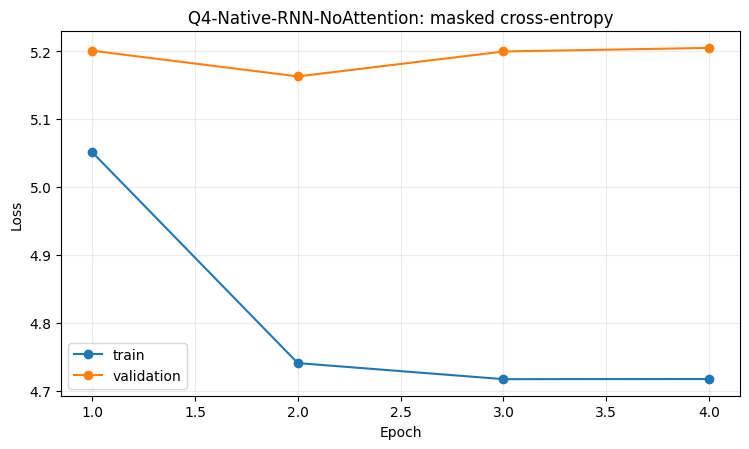

Experiment: Q4-Native-RNN-NoAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 5.162627
Average sec/epoch: 1027.10
Peak GPU Memory: 449.5 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/native_rnn_noattn/q4_native_rnn_noattn_resume.pt
Bundle: /kaggle/working/q4_native_rnn_noattn_bundle.zip
[Q4-Scratch-RNN-NoAttention][cuda:0] Epoch 02/04 | train_loss=4.7565 | val_loss=5.1328 | best=5.1328 (epoch 2) | 2162.5s | peak_allocated=451.4 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Download/update model bundle: /kaggle/working/q4_scratch_rnn_noattn_bundle.zip
[Q4-Scratch-RNN-NoAttention][cuda:0] Epoch 03/04 | train_loss=4.7133 | val_loss=5.1216 | best=5.1216 (epoch 3) | 1881.0s | peak_allocated=451.4 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Download/update model bundle: /kaggle/working/q4_scratch_rnn_noattn_bundle.zip
[Q4-Scratch-RNN-NoAttenti

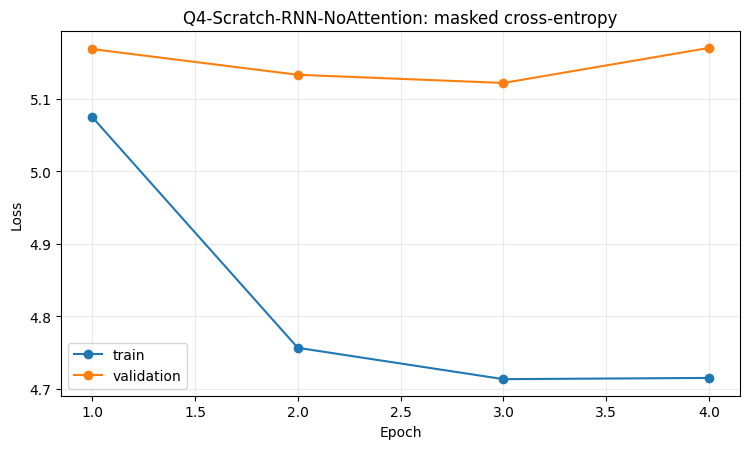

Experiment: Q4-Scratch-RNN-NoAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 5.121555
Average sec/epoch: 2039.00
Peak GPU Memory: 451.4 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Bundle: /kaggle/working/q4_scratch_rnn_noattn_bundle.zip
Required assignment checkpoint: /kaggle/working/q2_seq2seq_rnn_noattn.pt
PAIR PROTECTED: /kaggle/working/q4_pair1_scratch_vs_native_rnn.zip
Download this ZIP before ending/changing the Kaggle session.


/kaggle/working/q4_pair1_scratch_vs_native_rnn.zip

In [44]:
# Q4 TRAINING PAIR 1 - Scratch RNN (cuda:0) + Native RNN (cuda:1)
q4_pair1_outputs = _q4_run_pair("pair1")


Q4 TRAINING PAIR 2 - Scratch LSTM vs Native LSTM
cuda:0 -> Q4-Scratch-LSTM-NoAttention
cuda:1 -> Q4-Native-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_lstm_noattn/q4_native_lstm_noattn_resume.pt
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
QUESTION 4 TRAINING: Q4-Native-LSTM-NoAttention on cuda:1
{
  "experiment_key": "native_lstm_noattn",
  "experiment_name": "Q4-Native-LSTM-NoAttention",
  "implementation": "Native",
  "cell_type": "LSTM",
  "attention": "None",
  "architecture": "native_lstm_noattn",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "checkpoint_interval_epochs": 1,
  "evaluation_max_generated_tokens": 2

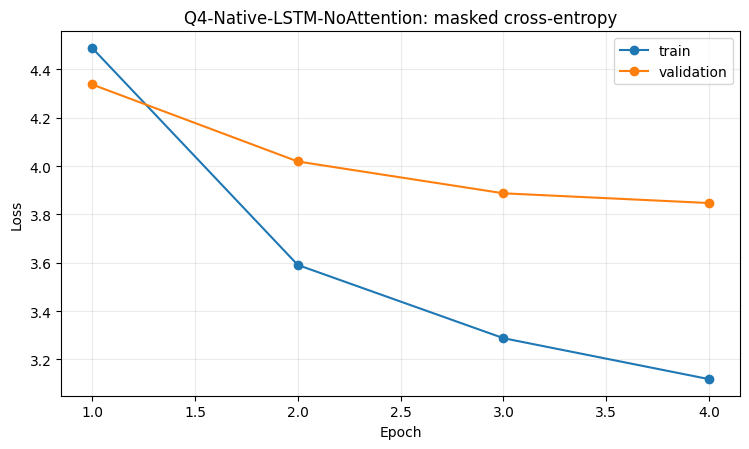

Experiment: Q4-Native-LSTM-NoAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 3.847094
Average sec/epoch: 1153.26
Peak GPU Memory: 515.3 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/native_lstm_noattn/q4_native_lstm_noattn_resume.pt
Bundle: /kaggle/working/q4_native_lstm_noattn_bundle.zip
[Q4-Scratch-LSTM-NoAttention][cuda:0] Epoch 04/04 | train_loss=3.2792 | val_loss=3.9579 | best=3.9579 (epoch 4) | 3698.0s | peak_allocated=530.5 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
Download/update model bundle: /kaggle/working/q4_scratch_lstm_noattn_bundle.zip
Evaluating best Q4-Scratch-LSTM-NoAttention checkpoint on the full test split...


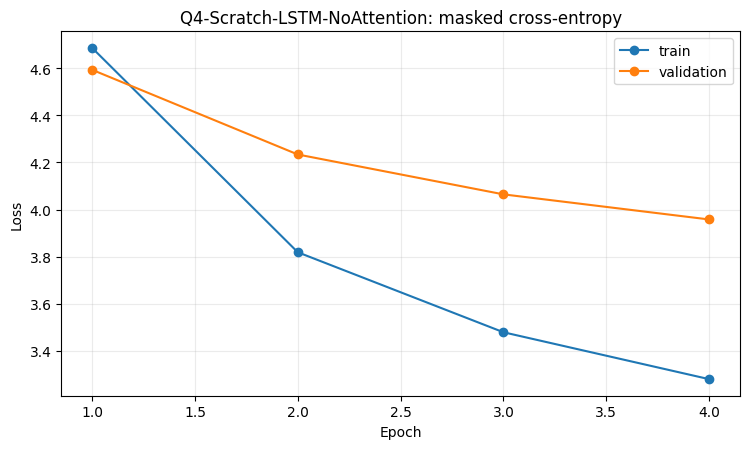

Experiment: Q4-Scratch-LSTM-NoAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 3.957888
Average sec/epoch: 3908.12
Peak GPU Memory: 530.5 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
Bundle: /kaggle/working/q4_scratch_lstm_noattn_bundle.zip
Required assignment checkpoint: /kaggle/working/q2_seq2seq_lstm_noattn.pt
PAIR PROTECTED: /kaggle/working/q4_pair2_scratch_vs_native_lstm.zip
Download this ZIP before ending/changing the Kaggle session.


/kaggle/working/q4_pair2_scratch_vs_native_lstm.zip

In [40]:
# Q4 TRAINING PAIR 2 - Scratch LSTM (cuda:0) + Native LSTM (cuda:1)
q4_pair2_outputs = _q4_run_pair("pair2")


Q4 TRAINING PAIR 3 - Native GRU No-Attn + Native GRU Dot
cuda:0 -> Q4-Native-GRU-NoAttention
cuda:1 -> Q4-Native-GRU-DotAttention
No prior Q4 artifact found for Q4-Native-GRU-NoAttention. A new run will start if its training cell is executed.
No prior Q4 artifact found for Q4-Native-GRU-DotAttention. A new run will start if its training cell is executed.
QUESTION 4 TRAINING: Q4-Native-GRU-NoAttention on cuda:0
{
  "experiment_key": "native_gru_noattn",
  "experiment_name": "Q4-Native-GRU-NoAttention",
  "implementation": "Native",
  "cell_type": "GRU",
  "attention": "None",
  "architecture": "native_gru_noattn",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 128,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 10,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "checkpoint_interval_epochs": 5,
  "evaluation_max_generated_t

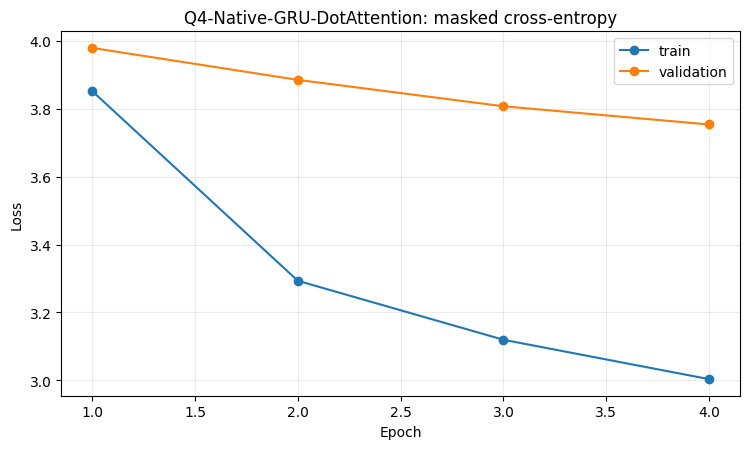

Experiment: Q4-Native-GRU-DotAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 3.753912
Average sec/epoch: 1856.32
Peak GPU Memory: 647.1 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/native_gru_dot/q4_native_gru_dot_resume.pt
Bundle: /kaggle/working/q4_native_gru_dot_bundle.zip
Required assignment checkpoint: /kaggle/working/q4_native_dot.pt
[Q4-Native-GRU-NoAttention][cuda:0] Epoch 08/10 | train_loss=2.9632 | val_loss=3.8414 | best=3.8277 (epoch 7) | 942.3s | peak_allocated=499.2 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
[Q4-Native-GRU-NoAttention][cuda:0] Epoch 09/10 | train_loss=2.9336 | val_loss=3.8153 | best=3.8153 (epoch 9) | 937.9s | peak_allocated=499.2 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
[Q4-Native-GRU-NoAttention][cuda:0] Epoch 10/10 | train_loss=2.9068 | val_loss=3.8217 | best=3.8153 (epoch 9) | 936.3s | peak_allocate

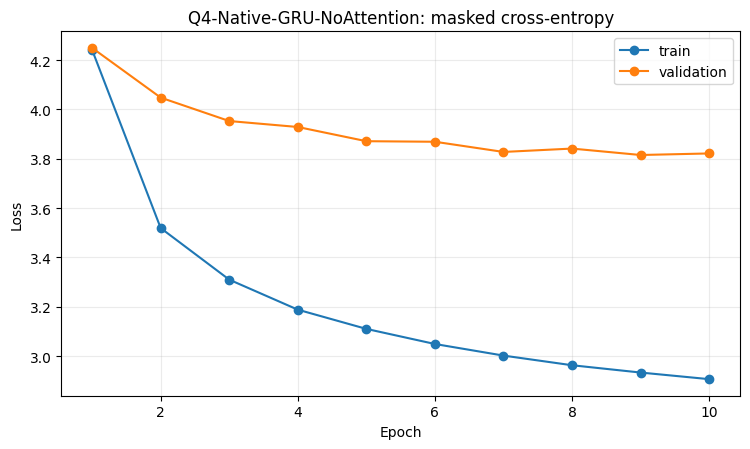

Experiment: Q4-Native-GRU-NoAttention
Status: Completed
Epoch: 10/10
Best Val Loss: 3.815350
Average sec/epoch: 1017.76
Peak GPU Memory: 499.2 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
Bundle: /kaggle/working/q4_native_gru_noattn_bundle.zip
Required assignment checkpoint: /kaggle/working/q4_native_noattn.pt
PAIR PROTECTED: /kaggle/working/q4_pair3_native_gru_noattn_and_dot.zip
Download this ZIP before ending/changing the Kaggle session.


/kaggle/working/q4_pair3_native_gru_noattn_and_dot.zip

In [41]:
# Q4 TRAINING PAIR 3 - Native GRU No-Attn (cuda:0) + Native GRU Dot (cuda:1)
q4_pair3_outputs = _q4_run_pair("pair3")


Q4 TRAINING PAIR 4 - Native GRU Bahdanau
Fallback: running 1 experiment(s) sequentially on cuda:0
No prior Q4 artifact found for Q4-Native-GRU-BahdanauAttention. A new run will start if its training cell is executed.
QUESTION 4 TRAINING: Q4-Native-GRU-BahdanauAttention on cuda:0
{
  "experiment_key": "native_gru_bah",
  "experiment_name": "Q4-Native-GRU-BahdanauAttention",
  "implementation": "Native",
  "cell_type": "GRU",
  "attention": "Bahdanau",
  "architecture": "native_gru_bah",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 200,
  "hidden_size": 256,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 4,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "checkpoint_interval_epochs": 1,
  "evaluation_max_generated_tokens": 29,
  "seed": 42
}
Resume status: started; completed=0/4; AMP=True; checkpoint=/kaggle/working/q4_artifacts/native_gru_bah/

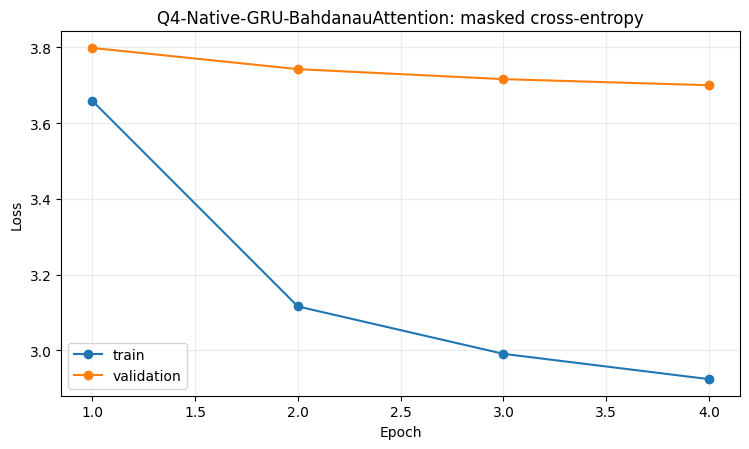

Experiment: Q4-Native-GRU-BahdanauAttention
Status: Completed
Epoch: 4/4
Best Val Loss: 3.700358
Average sec/epoch: 1884.81
Peak GPU Memory: 655.1 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/native_gru_bah/q4_native_gru_bah_resume.pt
Bundle: /kaggle/working/q4_native_gru_bah_bundle.zip
Required assignment checkpoint: /kaggle/working/q4_native_bah.pt
PAIR PROTECTED: /kaggle/working/q4_pair4_native_gru_bahdanau.zip
Download this ZIP before ending/changing the Kaggle session.


/kaggle/working/q4_pair4_native_gru_bahdanau.zip

In [42]:
# Q4 TRAINING PAIR 4 - Native GRU Bahdanau (available GPU)
q4_pair4_outputs = _q4_run_pair("pair4")


In [43]:
# --- Restore completed Q2/Q3/Q4 models after a fresh Kaggle session ---
q4_loaded_models, q4_missing_models = _q4_restore_available_models(include_prior=True)
if q4_missing_models:
    print("Q4 experiments still requiring their training pair:", q4_missing_models)
else:
    print("All seven main Q4 experiments are available in memory.")
print("Required aliases:", {
    "native_dot": "available" if "native_dot" in globals() else "missing",
    "native_bah": "available" if "native_bah" in globals() else "missing",
})


Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Loaded: Q4-Scratch-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_rnn_noattn/q4_native_rnn_noattn_resume.pt
Loaded: Q4-Native-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
Loaded: Q4-Scratch-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_lstm_noattn/q4_native_lstm_noattn_resume.pt
Loaded: Q4-Native-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
Loaded: Q4-Native-GRU-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_dot/q4_native_gru_dot_resume.pt
Loaded: Q4-Native-GRU-DotAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_bah/q4_native_gru_bah_resume.pt
Loaded: Q4-Native-GRU-BahdanauAttention
All se

###Comprehensive Comparative Study[20 Marks]

**Do not change content of this cell**

Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Loaded: Q4-Scratch-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_rnn_noattn/q4_native_rnn_noattn_resume.pt
Loaded: Q4-Native-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
Loaded: Q4-Scratch-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_lstm_noattn/q4_native_lstm_noattn_resume.pt
Loaded: Q4-Native-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
Loaded: Q4-Native-GRU-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_dot/q4_native_gru_dot_resume.pt
Loaded: Q4-Native-GRU-DotAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_bah/q4_native_gru_bah_resume.pt
Loaded: Q4-Native-GRU-BahdanauAttention
Memory

,Implementation,Cell,Attention,Epochs,Parameter Count,Seconds / Epoch,Peak GPU Memory MiB,Recorded Full-Run Peak MiB,Best Validation Loss,Test SacreBLEU,Native / Scratch Speedup
0,Scratch,RNN,None,4,8264600,2038.996046,388.383301,451.413574,5.121555,4.347711,NaN
1,Native,RNN,None,4,8264600,1027.102659,382.800293,449.523926,5.162627,6.548611,1.985192
2,Scratch,LSTM,None,4,10731416,3908.117438,445.074707,530.502441,3.957888,11.975263,NaN
3,Native,LSTM,None,4,10862744,1153.262095,423.563477,515.277832,3.847094,13.018573,3.388750
4,Scratch,GRU,None,10,9909144,2296.712373,404.095215,NaN,3.805828,11.978651,NaN
5,Native,GRU,None,10,9909144,1017.756658,414.069824,499.216797,3.815350,12.800827,2.256642
6,Scratch,GRU,Dot,4,20223832,3430.526357,472.804199,NaN,3.750345,11.990156,NaN
7,Native,GRU,Dot,4,20223832,1856.320769,478.233887,647.068359,3.753912,14.099703,1.848025
8,Scratch,GRU,Bahdanau,4,20190680,3703.480200,484.396973,NaN,3.693028,15.300466,NaN
9,Native,GRU,Bahdanau,4,20190680,1884.805894,489.826660,655.145996,3.700358,14.812319,1.964913


Saved CSV: /kaggle/working/q4_artifacts/analysis/q4_benchmark_table.csv
Saved JSON: /kaggle/working/q4_artifacts/analysis/q4_benchmark_table.json
All ten primary comparison rows contain measured test SacreBLEU.


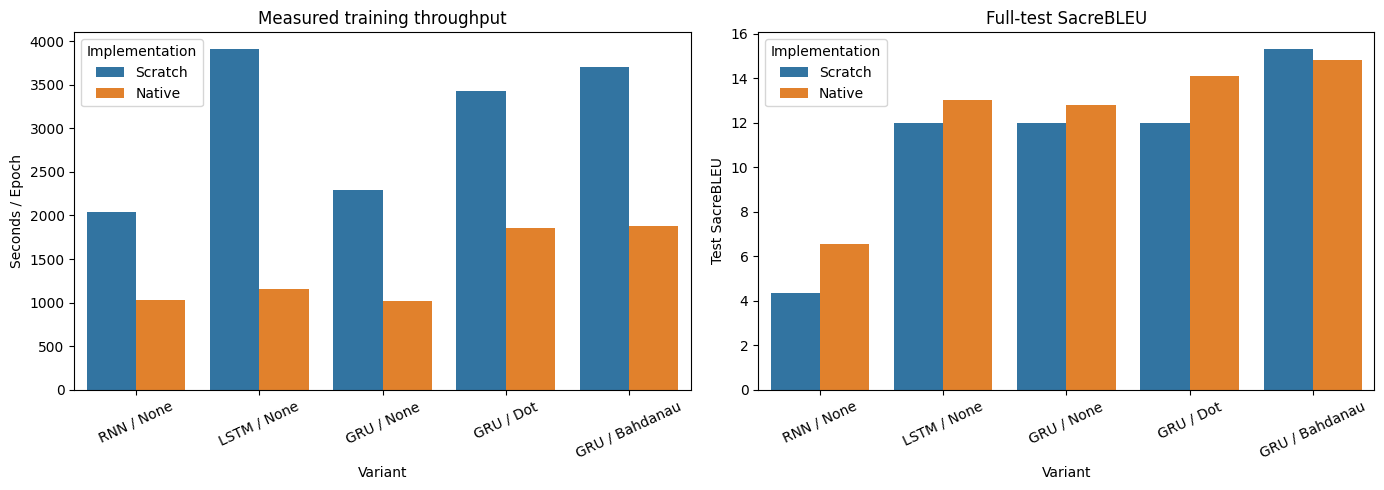

Saved comparison plot: /kaggle/working/q4_artifacts/analysis/q4_scratch_vs_native_summary.png
Download/update Q4 analysis bundle: /kaggle/working/q4_analysis_artifacts.zip


In [44]:
# ==============================================================================
# Question 4: Comprehensive Comparative Study (Scratch vs. PyTorch Native)
# ==============================================================================
if not (Q4_PRIOR_DIR / "q4_prior_artifact_report.json").is_file():
    print("Running the Q2/Q3 prerequisite check before building the comparison.")
    q4_prior_artifact_report = _q4_restore_prior_artifacts()

q4_loaded_models, q4_missing_models = _q4_restore_available_models(include_prior=True)
q4_standardized_memory_profile = _q4_profile_training_step_memory()
q4_benchmark_df = _q4_build_benchmark_table()

print("=" * 120)
print("QUESTION 4: SCRATCH VS PYTORCH-NATIVE BENCHMARK")
print("Peak GPU Memory MiB is a standardized one-step AMP Adam measurement for all ten models.")
print("Recorded Full-Run Peak MiB separately preserves full-training peaks captured by new Q4 runs.")
display(q4_benchmark_df)
print("Saved CSV:", Q4_ANALYSIS_DIR / "q4_benchmark_table.csv")
print("Saved JSON:", Q4_ANALYSIS_DIR / "q4_benchmark_table.json")

_q4_missing_rows = q4_benchmark_df[q4_benchmark_df["Test SacreBLEU"].isna()]
if not _q4_missing_rows.empty:
    print("Incomplete BLEU rows; run/restore the named training pairs or prior Q2/Q3 artifacts:")
    display(_q4_missing_rows[["Implementation", "Cell", "Attention"]])
else:
    print("All ten primary comparison rows contain measured test SacreBLEU.")

with _Q4_PLOT_LOCK:
    _q4_plot_frame = q4_benchmark_df.dropna(subset=["Seconds / Epoch"]).copy()
    if not _q4_plot_frame.empty:
        _q4_plot_frame["Variant"] = (
            _q4_plot_frame["Cell"] + " / " + _q4_plot_frame["Attention"]
        )
        _q4_fig, _q4_axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.barplot(
            data=_q4_plot_frame, x="Variant", y="Seconds / Epoch",
            hue="Implementation", ax=_q4_axes[0],
        )
        _q4_axes[0].set_title("Measured training throughput")
        _q4_axes[0].tick_params(axis="x", rotation=25)
        _q4_bleu_frame = q4_benchmark_df.dropna(subset=["Test SacreBLEU"]).copy()
        _q4_bleu_frame["Variant"] = _q4_bleu_frame["Cell"] + " / " + _q4_bleu_frame["Attention"]
        sns.barplot(
            data=_q4_bleu_frame, x="Variant", y="Test SacreBLEU",
            hue="Implementation", ax=_q4_axes[1],
        )
        _q4_axes[1].set_title("Full-test SacreBLEU")
        _q4_axes[1].tick_params(axis="x", rotation=25)
        _q4_fig.tight_layout()
        _q4_summary_plot = Q4_ANALYSIS_DIR / "q4_scratch_vs_native_summary.png"
        _q4_fig.savefig(_q4_summary_plot, dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(_q4_fig)
        print("Saved comparison plot:", _q4_summary_plot)
q4_analysis_bundle = _q4_create_analysis_bundle()
print("Download/update Q4 analysis bundle:", q4_analysis_bundle)


### **Advanced Analytical & Experimental Evaluation[Total =40 Marks]**

Answer all questions below using evidence, metrics, and observations directly from your experiments.

**Logical & Reasoning**

* **L1. Autoregressive Constraints & Sequence Modules:[5 marks]** If a decoder uses 100% teacher forcing and never consumes its own past predictions during training, why can it *still* not use a whole-sequence `nn.GRU` instead of a step-wise `nn.GRUCell`? Explain how the autoregressive dependency of attention contexts and hidden states enforces step-by-step execution.


**Answer:** Teacher forcing supplies the correct previous *token*, but it does not supply the current decoder hidden state or attention context. At step $t$, the attention query depends on $h_{t-1}$; the resulting context $c_t$ is then used to compute $h_t$, which becomes the next query. Those recurrent and attention dependencies must therefore be resolved in order. A whole-sequence `nn.GRU` can optimize an encoder, where all inputs are already known, but it cannot replace this attention decoder loop without changing the model's computation graph.


* **L2. Discrepancies Under Fixed Seeds[5 Marks]:** If your native PyTorch implementation and custom hand-written model produce diverging validation losses or BLEU scores despite identical hyperparameters and random seeds, outline two potential underlying reasons (e.g., initialization or padding-mask handling differences) and explain how you would isolate and test each.

**Answer:** Equal seeds do not make a scratch implementation numerically identical to a native one. First, their parameters can be laid out, initialized, and consumed in a different order. I would copy mathematically corresponding weights into both models, run one fixed CPU batch in `float64`, and compare each gate and timestep to isolate an equation, bias, or gate-order mismatch. Second, packed-sequence and padding-mask behavior can differ, and cuDNN changes floating-point reduction order (with some kernels potentially nondeterministic). I would test equal-length unpadded sequences first, then padded sequences with explicit lengths, compare encoder states before decoding, and repeat with deterministic algorithms enabled. Divergence only after padding implicates masking/length handling; small GPU-only differences implicate kernel arithmetic rather than a conceptual architecture error.


**Analytical (Requires Your Run's Data & Evaluation Metrics)**

* **A1. Training Throughput & Speedup Quantification:[5 Marks]** Report the runtime benchmarks. Compute the exact training speedup factor of the native PyTorch implementation over your custom Python loop, and discuss whether the performance differential aligns with C++ backend vectorization expectations.

In [45]:
# A1 - measured training throughput and native speedup
q4_benchmark_df = _q4_build_benchmark_table()
q4_a1_records = []
for _q4_cell_type, _q4_attention in (
    ("RNN", "None"), ("LSTM", "None"), ("GRU", "None"),
    ("GRU", "Dot"), ("GRU", "Bahdanau"),
):
    _q4_scratch = q4_benchmark_df[
        (q4_benchmark_df["Implementation"] == "Scratch")
        & (q4_benchmark_df["Cell"] == _q4_cell_type)
        & (q4_benchmark_df["Attention"] == _q4_attention)
    ]
    _q4_native = q4_benchmark_df[
        (q4_benchmark_df["Implementation"] == "Native")
        & (q4_benchmark_df["Cell"] == _q4_cell_type)
        & (q4_benchmark_df["Attention"] == _q4_attention)
    ]
    if _q4_scratch.empty or _q4_native.empty:
        continue
    _q4_s = _q4_scratch.iloc[0]["Seconds / Epoch"]
    _q4_n = _q4_native.iloc[0]["Seconds / Epoch"]
    if pd.notna(_q4_s) and pd.notna(_q4_n) and _q4_n > 0:
        _q4_speedup = float(_q4_s / _q4_n)
        q4_a1_records.append({
            "cell": _q4_cell_type, "attention": _q4_attention,
            "scratch_seconds_per_epoch": float(_q4_s),
            "native_seconds_per_epoch": float(_q4_n),
            "speedup_scratch_over_native": _q4_speedup,
        })
        print(
            f"{_q4_cell_type} / {_q4_attention}: {_q4_s:.2f} / {_q4_n:.2f} "
            f"= {_q4_speedup:.3f}x native speedup"
        )
if q4_a1_records:
    _q4_atomic_json_save(q4_a1_records, Q4_ANALYSIS_DIR / "q4_a1_training_speedup.json")
    _q4_mean_speedup = statistics.mean(row["speedup_scratch_over_native"] for row in q4_a1_records)
    print(f"Mean measured speedup across available matched comparisons: {_q4_mean_speedup:.3f}x")
    if _q4_mean_speedup > 1:
        print("The direction agrees with fused/optimized PyTorch backend execution, while the remaining step-wise decoder limits the attainable gain.")
    else:
        print("The run did not show an overall native speedup; concurrent workload and the still-sequential decoder are relevant measured constraints.")
else:
    print("A1 is pending. Complete/restore the relevant Q4 training pairs and Q2/Q3 metric bundles.")
q4_analysis_bundle = _q4_create_analysis_bundle()
print("Download/update Q4 analysis bundle:", q4_analysis_bundle)


RNN / None: 2039.00 / 1027.10 = 1.985x native speedup
LSTM / None: 3908.12 / 1153.26 = 3.389x native speedup
GRU / None: 2296.71 / 1017.76 = 2.257x native speedup
GRU / Dot: 3430.53 / 1856.32 = 1.848x native speedup
GRU / Bahdanau: 3703.48 / 1884.81 = 1.965x native speedup
Mean measured speedup across available matched comparisons: 2.289x
The direction agrees with fused/optimized PyTorch backend execution, while the remaining step-wise decoder limits the attainable gain.
Download/update Q4 analysis bundle: /kaggle/working/q4_analysis_artifacts.zip


* **A2. Translation Quality Parity:[5 marks]** Compare the final test BLEU scores between the native and custom model variants. Did leveraging PyTorch's built-in layers alter translation accuracy, or did performance remain equivalent?

In [46]:
# A2 - measured translation-quality parity
q4_benchmark_df = _q4_build_benchmark_table()
q4_a2_records = []
for _q4_cell_type, _q4_attention in (
    ("RNN", "None"), ("LSTM", "None"), ("GRU", "None"),
    ("GRU", "Dot"), ("GRU", "Bahdanau"),
):
    _q4_scratch = q4_benchmark_df[
        (q4_benchmark_df["Implementation"] == "Scratch")
        & (q4_benchmark_df["Cell"] == _q4_cell_type)
        & (q4_benchmark_df["Attention"] == _q4_attention)
    ]
    _q4_native = q4_benchmark_df[
        (q4_benchmark_df["Implementation"] == "Native")
        & (q4_benchmark_df["Cell"] == _q4_cell_type)
        & (q4_benchmark_df["Attention"] == _q4_attention)
    ]
    if _q4_scratch.empty or _q4_native.empty:
        continue
    _q4_s = _q4_scratch.iloc[0]["Test SacreBLEU"]
    _q4_n = _q4_native.iloc[0]["Test SacreBLEU"]
    if pd.notna(_q4_s) and pd.notna(_q4_n):
        _q4_delta = float(_q4_n - _q4_s)
        q4_a2_records.append({
            "cell": _q4_cell_type, "attention": _q4_attention,
            "scratch_bleu": float(_q4_s), "native_bleu": float(_q4_n),
            "native_minus_scratch_bleu": _q4_delta,
        })
        print(
            f"{_q4_cell_type} / {_q4_attention}: scratch={_q4_s:.4f}, "
            f"native={_q4_n:.4f}, native-scratch={_q4_delta:+.4f} BLEU"
        )
if q4_a2_records:
    _q4_atomic_json_save(q4_a2_records, Q4_ANALYSIS_DIR / "q4_a2_bleu_parity.json")
    _q4_abs_delta = statistics.mean(abs(row["native_minus_scratch_bleu"]) for row in q4_a2_records)
    print(f"Mean absolute BLEU difference across available pairs: {_q4_abs_delta:.4f}")
    print("The measured deltas, rather than an assumed winner, determine whether quality remained approximately equivalent.")
else:
    print("A2 is pending. Complete/restore all required model results first.")
q4_analysis_bundle = _q4_create_analysis_bundle()
print("Download/update Q4 analysis bundle:", q4_analysis_bundle)


RNN / None: scratch=4.3477, native=6.5486, native-scratch=+2.2009 BLEU
LSTM / None: scratch=11.9753, native=13.0186, native-scratch=+1.0433 BLEU
GRU / None: scratch=11.9787, native=12.8008, native-scratch=+0.8222 BLEU
GRU / Dot: scratch=11.9902, native=14.0997, native-scratch=+2.1095 BLEU
GRU / Bahdanau: scratch=15.3005, native=14.8123, native-scratch=-0.4881 BLEU
Mean absolute BLEU difference across available pairs: 1.3328
The measured deltas, rather than an assumed winner, determine whether quality remained approximately equivalent.
Download/update Q4 analysis bundle: /kaggle/working/q4_analysis_artifacts.zip


**Experimental (Requires Code Execution & Observations)**

* **E1. Inference Latency Profiling:[10 marks]** Measure and compare the `greedy_decode` inference latency for your custom and native Bahdanau models under two distinct workloads:
  - Batch size 1 (sequential inference)
  - Batch size 128 (vectorized batch inference)
  Evaluate whether the native model retains its massive speedup advantage during single-sample batch execution.

In [47]:
# E1 - greedy-decoding latency at batch sizes 1 and 128 (no retraining)
q4_prior_artifact_report = _q4_restore_prior_artifacts()
_q4_load_prior_models("cpu")
try:
    native_seq2seq_bah = _q4_load_completed_model("native_gru_bah", "cpu")
    native_bah = native_seq2seq_bah
except FileNotFoundError as _q4_error:
    native_seq2seq_bah = None
    print(_q4_error)

if "seq2seq_bah" not in globals() or native_seq2seq_bah is None:
    print("E1 pending: restore Q3 Bahdanau and complete Q4 Training Pair 4 first.")
else:
    _q4_latency_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    _q4_latency_models = {
        "Scratch Bahdanau": seq2seq_bah.to(_q4_latency_device).eval(),
        "Native Bahdanau": native_seq2seq_bah.to(_q4_latency_device).eval(),
    }
    q4_e1_latency_records = []
    for _q4_batch_size in (1, 128):
        _q4_inputs = test_dataset.src_ids[:_q4_batch_size].to(_q4_latency_device)
        for _q4_name, _q4_model in _q4_latency_models.items():
            with torch.inference_mode():
                for _ in range(3):
                    _q4_greedy_tokens(_q4_model, _q4_inputs, Q4_MAX_GENERATED_TOKENS)
                if _q4_latency_device.type == "cuda":
                    torch.cuda.synchronize(_q4_latency_device)
                _q4_times = []
                for _ in range(7):
                    _q4_started = time.perf_counter()
                    _q4_greedy_tokens(_q4_model, _q4_inputs, Q4_MAX_GENERATED_TOKENS)
                    if _q4_latency_device.type == "cuda":
                        torch.cuda.synchronize(_q4_latency_device)
                    _q4_times.append(time.perf_counter() - _q4_started)
            _q4_median = statistics.median(_q4_times)
            q4_e1_latency_records.append({
                "implementation": _q4_name,
                "batch_size": _q4_batch_size,
                "median_latency_seconds": _q4_median,
                "examples_per_second": _q4_batch_size / _q4_median,
                "repetitions": len(_q4_times),
                "warmup_repetitions": 3,
                "max_generated_tokens": Q4_MAX_GENERATED_TOKENS,
                "device": str(_q4_latency_device),
            })
    _q4_latency_frame = pd.DataFrame(q4_e1_latency_records)
    display(_q4_latency_frame)
    for _q4_batch_size in (1, 128):
        _q4_subset = _q4_latency_frame[_q4_latency_frame["batch_size"] == _q4_batch_size]
        _q4_scratch_time = float(_q4_subset[_q4_subset["implementation"] == "Scratch Bahdanau"]["median_latency_seconds"].iloc[0])
        _q4_native_time = float(_q4_subset[_q4_subset["implementation"] == "Native Bahdanau"]["median_latency_seconds"].iloc[0])
        _q4_speedup = _q4_scratch_time / _q4_native_time
        print(f"Batch {_q4_batch_size}: native greedy-decoding speedup = {_q4_speedup:.3f}x")
        for record in q4_e1_latency_records:
            if record["batch_size"] == _q4_batch_size:
                record["native_speedup_for_batch"] = _q4_speedup
    _q4_atomic_json_save(q4_e1_latency_records, Q4_ANALYSIS_DIR / "q4_e1_inference_latency.json")
    _q4_latency_frame.to_csv(Q4_ANALYSIS_DIR / "q4_e1_inference_latency.csv", index=False)
    print("Because both attention decoders remain autoregressive and step-wise, the native encoder/cell speedup need not be massive at batch size 1.")
    for _q4_model in _q4_latency_models.values():
        _q4_model.cpu()
    gc.collect()
    if _q4_latency_device.type == "cuda":
        torch.cuda.empty_cache()
    q4_analysis_bundle = _q4_create_analysis_bundle()
    print("Download/update Q4 analysis bundle:", q4_analysis_bundle)


QUESTION 4 PREREQUISITE CHECK: Q2/Q3 reusable artifacts
FOUND: q2_seq2seq_noattn.pt <- /kaggle/working/q2_seq2seq_noattn.pt
FOUND: q2_noattention_baseline_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_config.json
FOUND: q2_noattention_baseline_history.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_history.json
FOUND: q2_noattention_baseline_result.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q2_noattention_baseline_result.json
FOUND: q3_seq2seq_dot.pt <- /kaggle/working/q3_seq2seq_dot.pt
FOUND: q3_dot_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_config.json
FOUND: q3_dot_history.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_history.json
FOUND: q3_dot_result.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_dot_result.json
FOUND: q3_seq2seq_bah.pt <- /kaggle/working/q3_seq2seq_bah.pt
FOUND: q3_bah_config.json <- /kaggle/working/q4_artifacts/prior_q2_q3/q3_bah_config.json
FOUND: q3_bah_history.j

,implementation,batch_size,median_latency_seconds,examples_per_second,repetitions,warmup_repetitions,max_generated_tokens,device
0,Scratch Bahdanau,1,0.024425,40.941014,7,3,29,cuda:0
1,Native Bahdanau,1,0.013658,73.217382,7,3,29,cuda:0
2,Scratch Bahdanau,128,0.058707,2180.329500,7,3,29,cuda:0
3,Native Bahdanau,128,0.050035,2558.220962,7,3,29,cuda:0


Batch 1: native greedy-decoding speedup = 1.788x
Batch 128: native greedy-decoding speedup = 1.173x
Because both attention decoders remain autoregressive and step-wise, the native encoder/cell speedup need not be massive at batch size 1.
Download/update Q4 analysis bundle: /kaggle/working/q4_analysis_artifacts.zip


* **E2. Scaling Hidden Dimensions:[10 marks]** Double the hidden state capacity (`HID_MT` from 256 to 512) and execute a single-epoch benchmark for both custom and native Bahdanau models. Compute the updated speedup ratio and determine whether scaling the parameter matrix size increases, decreases, or preserves the relative execution gap.

Q4 E2 TRAINING - HID=512 Custom vs Native Bahdanau
cuda:0 -> Q4-E2-Custom-Bahdanau-H512
cuda:1 -> Q4-E2-Native-Bahdanau-H512
No prior Q4 artifact found for Q4-E2-Native-Bahdanau-H512. A new run will start if its training cell is executed.
No prior Q4 artifact found for Q4-E2-Custom-Bahdanau-H512. A new run will start if its training cell is executed.
QUESTION 4 TRAINING: Q4-E2-Native-Bahdanau-H512 on cuda:1
{
  "experiment_key": "e2_native_bah_h512",
  "experiment_name": "Q4-E2-Native-Bahdanau-H512",
  "implementation": "Native",
  "cell_type": "GRU",
  "attention": "Bahdanau",
  "architecture": "e2_native_bah_h512",
  "vocab_en": 12000,
  "vocab_hi": 15000,
  "emb_dim": 200,
  "hidden_size": 512,
  "num_layers": 2,
  "max_len_en": 30,
  "max_len_hi": 30,
  "batch_size": 64,
  "epochs": 1,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "teacher_forcing_ratio": 0.7,
  "loss": "CrossEntropyLoss(ignore_index=stoi_hi[PAD])",
  "checkpoint_interval_epochs": 1,
  "evaluation_max_generate

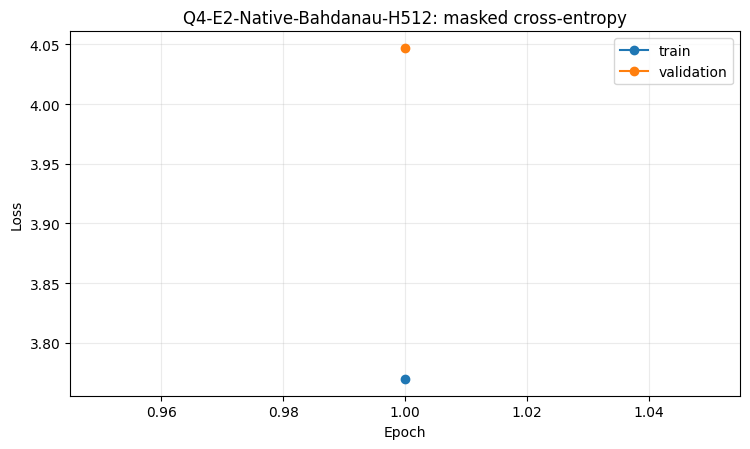

Experiment: Q4-E2-Native-Bahdanau-H512
Status: Completed
Epoch: 1/1
Best Val Loss: 4.047072
Average sec/epoch: 2177.91
Peak GPU Memory: 971.7 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/e2_native_bah_h512/q4_e2_native_bah_h512_resume.pt
Bundle: /kaggle/working/q4_e2_native_bah_h512_bundle.zip
[Q4-E2-Custom-Bahdanau-H512][cuda:0] Epoch 01/01 | train_loss=3.7767 | val_loss=4.0523 | best=4.0523 (epoch 1) | 3548.0s | peak_allocated=968.0 MiB
Protected restart checkpoint: /kaggle/working/q4_artifacts/e2_custom_bah_h512/q4_e2_custom_bah_h512_resume.pt
Download/update model bundle: /kaggle/working/q4_e2_custom_bah_h512_bundle.zip


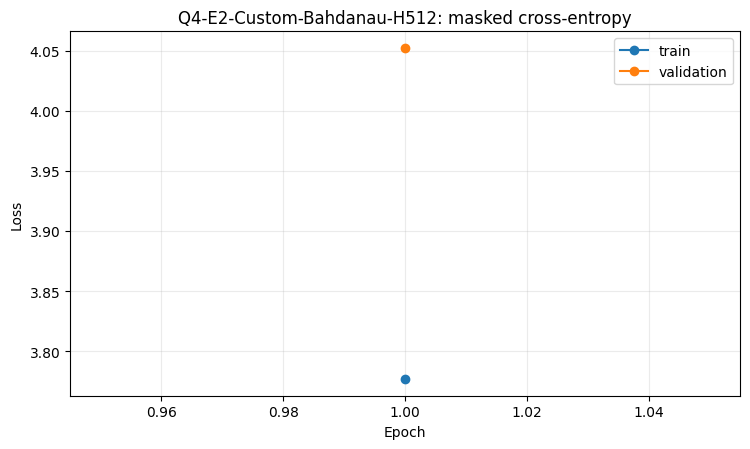

Experiment: Q4-E2-Custom-Bahdanau-H512
Status: Completed
Epoch: 1/1
Best Val Loss: 4.052294
Average sec/epoch: 3548.00
Peak GPU Memory: 968.0 MiB allocated
Checkpoint: /kaggle/working/q4_artifacts/e2_custom_bah_h512/q4_e2_custom_bah_h512_resume.pt
Bundle: /kaggle/working/q4_e2_custom_bah_h512_bundle.zip
PAIR PROTECTED: /kaggle/working/q4_e2_h512_custom_vs_native_bahdanau.zip
Download this ZIP before ending/changing the Kaggle session.


/kaggle/working/q4_e2_h512_custom_vs_native_bahdanau.zip

{
  "hidden_size": 512,
  "custom_parameter_count": 40340184,
  "native_parameter_count": 40340184,
  "custom_seconds_per_epoch": 3548.0032416520007,
  "native_seconds_per_epoch": 2177.912317385999,
  "custom_peak_gpu_memory_mb": 968.04833984375,
  "native_peak_gpu_memory_mb": 971.6796875,
  "custom_validation_loss": 4.052293575769183,
  "native_validation_loss": 4.047071696423936,
  "native_speedup_h512": 1.629084519761764,
  "native_speedup_h256": 1.9649133165445387,
  "speedup_change_h512_minus_h256": -0.33582879678277466
}
Measured HID=512 native speedup: 1.629x
Relative to HID=256, the measured execution gap decreased (-0.336x).
Refreshed E2 bundle with completed experiment artifacts: /kaggle/working/q4_e2_h512_custom_vs_native_bahdanau.zip
Download/update Q4 analysis bundle: /kaggle/working/q4_analysis_artifacts.zip


In [48]:
# Q4 E2 TRAINING - HID=512 Custom Bahdanau (cuda:0) + Native Bahdanau (cuda:1)
# These dedicated models do not mutate HID_MT or overwrite any hidden-size-256 model.
q4_e2_outputs = _q4_run_pair("e2")
_q4_custom_result = _q4_result_for_key("e2_custom_bah_h512")
_q4_native_result = _q4_result_for_key("e2_native_bah_h512")
q4_e2_comparison = {
    "hidden_size": Q4_E2_HIDDEN_SIZE,
    "custom_parameter_count": _q4_custom_result["parameter_count"],
    "native_parameter_count": _q4_native_result["parameter_count"],
    "custom_seconds_per_epoch": _q4_custom_result["average_seconds_per_epoch"],
    "native_seconds_per_epoch": _q4_native_result["average_seconds_per_epoch"],
    "custom_peak_gpu_memory_mb": _q4_custom_result["peak_gpu_memory_mb"],
    "native_peak_gpu_memory_mb": _q4_native_result["peak_gpu_memory_mb"],
    "custom_validation_loss": _q4_custom_result["final_val_loss"],
    "native_validation_loss": _q4_native_result["final_val_loss"],
}
q4_e2_comparison["native_speedup_h512"] = (
    q4_e2_comparison["custom_seconds_per_epoch"]
    / q4_e2_comparison["native_seconds_per_epoch"]
)
_q4_base_table = _q4_build_benchmark_table()
_q4_base_custom = _q4_base_table[
    (_q4_base_table["Implementation"] == "Scratch")
    & (_q4_base_table["Cell"] == "GRU")
    & (_q4_base_table["Attention"] == "Bahdanau")
]
_q4_base_native = _q4_base_table[
    (_q4_base_table["Implementation"] == "Native")
    & (_q4_base_table["Cell"] == "GRU")
    & (_q4_base_table["Attention"] == "Bahdanau")
]
if not _q4_base_custom.empty and not _q4_base_native.empty:
    _q4_s256 = _q4_base_custom.iloc[0]["Seconds / Epoch"]
    _q4_n256 = _q4_base_native.iloc[0]["Seconds / Epoch"]
    if pd.notna(_q4_s256) and pd.notna(_q4_n256) and _q4_n256 > 0:
        q4_e2_comparison["native_speedup_h256"] = float(_q4_s256 / _q4_n256)
        q4_e2_comparison["speedup_change_h512_minus_h256"] = (
            q4_e2_comparison["native_speedup_h512"]
            - q4_e2_comparison["native_speedup_h256"]
        )
_q4_atomic_json_save(q4_e2_comparison, Q4_ANALYSIS_DIR / "q4_e2_hidden512_scaling.json")
print(json.dumps(q4_e2_comparison, indent=2))
print(
    "Measured HID=512 native speedup:",
    f"{q4_e2_comparison['native_speedup_h512']:.3f}x",
)
if "native_speedup_h256" in q4_e2_comparison:
    _q4_change = q4_e2_comparison["speedup_change_h512_minus_h256"]
    _q4_direction = "increased" if _q4_change > 0 else "decreased" if _q4_change < 0 else "was preserved"
    print(f"Relative to HID=256, the measured execution gap {_q4_direction} ({_q4_change:+.3f}x).")
else:
    print("HID=256 comparison is pending; run/restore Q3 Bahdanau and Q4 Pair 4, then rerun this result block.")
q4_e2_bundle = _q4_create_pair_bundle("e2")
q4_analysis_bundle = _q4_create_analysis_bundle()
print("Refreshed E2 bundle with completed experiment artifacts:", q4_e2_bundle)
print("Download/update Q4 analysis bundle:", q4_analysis_bundle)


In [49]:
# --- Question 4 model_defs.py export, checkpoint validation, and final archive ---
q4_loaded_models, q4_missing_models = _q4_restore_available_models(include_prior=True)
_q4_required_main_keys = (
    "scratch_rnn_noattn", "native_rnn_noattn", "scratch_lstm_noattn",
    "native_lstm_noattn", "native_gru_noattn", "native_gru_dot",
    "native_gru_bah",
)
_q4_required_training_keys = _q4_required_main_keys + (
    "e2_custom_bah_h512", "e2_native_bah_h512",
)
_q4_incomplete = [
    key for key in _q4_required_training_keys
    if not (_q4_paths(key)["result"].is_file() and _q4_paths(key)["model"].is_file())
]
if _q4_incomplete:
    raise RuntimeError(
        "Question 4 training is incomplete. Run/restore the corresponding pair or E2 cells: "
        + ", ".join(_q4_incomplete)
    )
_q4_prior_report = _q4_load_json(Q4_PRIOR_DIR / "q4_prior_artifact_report.json")
if not _q4_prior_report or _q4_prior_report.get("missing"):
    raise RuntimeError(
        "Required Q2/Q3 comparison artifacts are incomplete. Rerun the Q4 prerequisite cell "
        "after mounting the Q2/Q3 bundles."
    )

_Q4_REQUIRED_MODEL_CLASSES = [
    "RNNCell", "LSTMCell", "GRUCell", "RecurrentEncoder", "EmotionClassifier",
    "Encoder", "DecoderStep", "Seq2Seq", "DotProductAttention",
    "BahdanauAttention", "AttnDecoderStep", "Seq2SeqAttn", "CustomEncoder",
    "CustomDecoderStep", "NativeRNSEncoder", "NativeLSTMEncoder",
    "NativeGRUEncoder", "NativeRNNDecoderStep", "NativeLSTMDecoderStep",
    "NativeGRUDecoderStep", "NativeAttnRNNDecoderStep",
    "NativeAttnLSTMDecoderStep", "NativeAttnGRUDecoderStep", "NativeSeq2Seq",
    "NativeSeq2SeqAttn",
]


def _q4_class_source_from_history(class_name: str) -> str:
    ipython_getter = globals().get("get_ipython")
    ipython = ipython_getter() if ipython_getter is not None else None
    if ipython is None:
        raise RuntimeError("Run this export cell inside Kaggle/Jupyter.")
    for cell_source in reversed(ipython.user_ns.get("In", [])):
        if not isinstance(cell_source, str) or f"class {class_name}" not in cell_source:
            continue
        try:
            tree = ast.parse(cell_source)
        except SyntaxError:
            continue
        for node in tree.body:
            if isinstance(node, ast.ClassDef) and node.name == class_name:
                extracted = ast.get_source_segment(cell_source, node)
                if extracted:
                    return extracted
    raise RuntimeError(
        f"Class {class_name!r} was not found in executed-cell history. "
        "Run its definition cell before this final Q4 cell."
    )


_q4_model_defs_path = _Q4_RUNTIME_ROOT / "model_defs.py"
_q4_header = (
    "import torch\n"
    "import torch.nn as nn\n"
    "import torch.nn.functional as F\n\n"
    "SEED = 42\n"
    "MAX_LEN_HI = 30\n"
)
_q4_model_defs_source = _q4_header + "\n\n".join(
    _q4_class_source_from_history(name) for name in _Q4_REQUIRED_MODEL_CLASSES
) + "\n"
_q4_model_defs_path.write_text(_q4_model_defs_source, encoding="utf-8")
compile(_q4_model_defs_source, str(_q4_model_defs_path), "exec")

_q4_spec = importlib.util.spec_from_file_location("q4_model_defs_validation", _q4_model_defs_path)
_q4_module = importlib.util.module_from_spec(_q4_spec)
_q4_module.__dict__.update({
    "PAD": PAD, "UNK": UNK, "SOS": SOS, "EOS": EOS,
    "stoi_en": stoi_en, "stoi_hi": stoi_hi,
})
_q4_spec.loader.exec_module(_q4_module)
for _q4_class_name in _Q4_REQUIRED_MODEL_CLASSES:
    assert hasattr(_q4_module, _q4_class_name), f"Missing from model_defs.py: {_q4_class_name}"

_q4_checkpoint_specs = {
    "q4_native_noattn.pt": "none",
    "q4_native_dot.pt": "dot",
    "q4_native_bah.pt": "bahdanau",
}
for _q4_filename, _q4_attention_type in _q4_checkpoint_specs.items():
    _q4_checkpoint_path = _Q4_RUNTIME_ROOT / _q4_filename
    if not _q4_checkpoint_path.is_file():
        raise FileNotFoundError(f"Missing required Q4 checkpoint: {_q4_checkpoint_path}")
    _q4_pair = _q4_torch_load(_q4_checkpoint_path, "cpu")
    if not isinstance(_q4_pair, dict) or set(_q4_pair) != {"encoder", "decoder"}:
        raise ValueError(f"{_q4_filename} must contain exactly encoder and decoder keys.")
    _q4_enc_state, _q4_dec_state = _q4_pair["encoder"], _q4_pair["decoder"]
    _q4_emb = int(_q4_enc_state["embedding.weight"].shape[1])
    _q4_hidden = int(_q4_enc_state["bridge.weight"].shape[0])
    _q4_encoder = _q4_module.NativeGRUEncoder(
        len(itos_en), _q4_emb, _q4_hidden, num_layers=2
    )
    if _q4_attention_type == "none":
        _q4_decoder = _q4_module.NativeGRUDecoderStep(
            len(itos_hi), _q4_emb, _q4_hidden, num_layers=2
        )
        _q4_wrapper = _q4_module.NativeSeq2Seq(
            _q4_encoder, _q4_decoder, num_layers=2, is_lstm=False
        )
    else:
        if _q4_attention_type == "dot":
            _q4_attention = _q4_module.DotProductAttention(_q4_hidden, 2 * _q4_hidden)
        else:
            _q4_attn_dim = int(_q4_dec_state["attention.W_a.weight"].shape[0])
            _q4_attention = _q4_module.BahdanauAttention(
                _q4_hidden, 2 * _q4_hidden, _q4_attn_dim
            )
        _q4_decoder = _q4_module.NativeAttnGRUDecoderStep(
            len(itos_hi), _q4_emb, _q4_hidden, 2 * _q4_hidden,
            _q4_attention, num_layers=2,
        )
        _q4_wrapper = _q4_module.NativeSeq2SeqAttn(
            _q4_encoder, _q4_decoder, num_layers=2, is_lstm=False
        )
    _q4_wrapper.encoder.load_state_dict(_q4_enc_state, strict=True)
    _q4_wrapper.decoder.load_state_dict(_q4_dec_state, strict=True)
    print(f"VALIDATED: {_q4_filename} loads into exported native classes.")

for _q4_variable in (
    "native_seq2seq_noattn", "native_seq2seq_dot", "native_seq2seq_bah",
    "native_dot", "native_bah",
):
    if _q4_variable not in globals():
        raise RuntimeError(f"Missing required Q4 variable: {_q4_variable}")

q4_benchmark_df = _q4_build_benchmark_table()
_q4_required_analysis = [
    Q4_ANALYSIS_DIR / "q4_benchmark_table.json",
    Q4_ANALYSIS_DIR / "q4_benchmark_table.csv",
    Q4_ANALYSIS_DIR / "q4_a1_training_speedup.json",
    Q4_ANALYSIS_DIR / "q4_a2_bleu_parity.json",
    Q4_ANALYSIS_DIR / "q4_e1_inference_latency.json",
    Q4_ANALYSIS_DIR / "q4_e2_hidden512_scaling.json",
    Q4_ANALYSIS_DIR / "q4_standardized_memory_profile.json",
]
_q4_missing_analysis = [path.name for path in _q4_required_analysis if not path.is_file()]
if _q4_missing_analysis:
    raise RuntimeError(
        "Run the remaining Q4 comparison/analysis cells before final protection: "
        + ", ".join(_q4_missing_analysis)
    )
_q4_a1_check = _q4_load_json(Q4_ANALYSIS_DIR / "q4_a1_training_speedup.json")
_q4_a2_check = _q4_load_json(Q4_ANALYSIS_DIR / "q4_a2_bleu_parity.json")
_q4_e1_check = _q4_load_json(Q4_ANALYSIS_DIR / "q4_e1_inference_latency.json")
_q4_e2_check = _q4_load_json(Q4_ANALYSIS_DIR / "q4_e2_hidden512_scaling.json")
if len(_q4_a1_check) != 5 or len(_q4_a2_check) != 5:
    raise ValueError("A1 and A2 must each contain all five matched scratch/native comparisons.")
if len(_q4_e1_check) != 4:
    raise ValueError("E1 must contain scratch/native latency at batch sizes 1 and 128.")
_q4_memory_check = _q4_load_json(Q4_ANALYSIS_DIR / "q4_standardized_memory_profile.json")
if len(_q4_memory_check) != 10:
    raise ValueError("The standardized memory profile must contain all ten primary models.")
if "native_speedup_h512" not in _q4_e2_check or "native_speedup_h256" not in _q4_e2_check:
    raise ValueError("E2 must contain measured HID=512 and HID=256 speedups.")

_q4_final_zip = _Q4_RUNTIME_ROOT / "q4_all_artifacts.zip"
_q4_final_tmp = Path(str(_q4_final_zip) + ".tmp")
with ZipFile(_q4_final_tmp, "w", allowZip64=True) as archive:
    for _q4_name in (
        "q2_seq2seq_rnn_noattn.pt", "q2_seq2seq_lstm_noattn.pt",
        "q4_native_noattn.pt", "q4_native_dot.pt", "q4_native_bah.pt",
        "model_defs.py",
    ):
        _q4_path = _Q4_RUNTIME_ROOT / _q4_name
        archive.write(
            _q4_path, arcname=_q4_name,
            compress_type=ZIP_STORED if _q4_path.suffix == ".pt" else ZIP_DEFLATED,
        )
    if Q4_PROGRESS_PATH.is_file():
        archive.write(Q4_PROGRESS_PATH, arcname=Q4_PROGRESS_PATH.name, compress_type=ZIP_DEFLATED)
    for _q4_artifact in sorted(Q4_OUTPUT_DIR.rglob("*")):
        if not _q4_artifact.is_file():
            continue
        if _q4_artifact.suffix == ".pt" and not _q4_artifact.name.endswith("_encoder_decoder.pt"):
            continue
        archive.write(
            _q4_artifact,
            arcname=str(Path("q4_artifacts") / _q4_artifact.relative_to(Q4_OUTPUT_DIR)),
            compress_type=ZIP_STORED if _q4_artifact.suffix == ".pt" else ZIP_DEFLATED,
        )
    for _q4_vocab in ("vocab_en.json", "vocab_hi.json"):
        _q4_vocab_path = _Q4_RUNTIME_ROOT / _q4_vocab
        if _q4_vocab_path.is_file():
            archive.write(_q4_vocab_path, arcname=_q4_vocab, compress_type=ZIP_DEFLATED)
os.replace(_q4_final_tmp, _q4_final_zip)

print("=" * 80)
print("QUESTION 4 PROTECTED:", _q4_final_zip)
print("Download this ZIP before ending/changing the Kaggle session.")
print("Required checkpoints: q4_native_noattn.pt, q4_native_dot.pt, q4_native_bah.pt")
print("model_defs.py import/class/checkpoint validation: PASSED")
try:
    from IPython.display import FileLink, display
    display(FileLink(str(_q4_final_zip)))
except Exception:
    pass


Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_rnn_noattn/q4_scratch_rnn_noattn_resume.pt
Loaded: Q4-Scratch-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_rnn_noattn/q4_native_rnn_noattn_resume.pt
Loaded: Q4-Native-RNN-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/scratch_lstm_noattn/q4_scratch_lstm_noattn_resume.pt
Loaded: Q4-Scratch-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_lstm_noattn/q4_native_lstm_noattn_resume.pt
Loaded: Q4-Native-LSTM-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_noattn/q4_native_gru_noattn_resume.pt
Loaded: Q4-Native-GRU-NoAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_dot/q4_native_gru_dot_resume.pt
Loaded: Q4-Native-GRU-DotAttention
Using current Q4 checkpoint: /kaggle/working/q4_artifacts/native_gru_bah/q4_native_gru_bah_resume.pt
Loaded: Q4-Native-GRU-BahdanauAttention
VALIDA

/kaggle/working/q4_all_artifacts.zip

### Question 4 Kaggle restart and download notes

Run the shared setup/data/class cells first, then the Question 4 implementation, infrastructure, prerequisite, and sanity cells. Execute only the training pair you want in that Kaggle session. A rerun restores its exact compatible resume checkpoint and continues at the next unfinished epoch; a completed run is loaded and skipped.

- Pair 1 ZIP: `q4_pair1_scratch_vs_native_rnn.zip`
- Pair 2 ZIP: `q4_pair2_scratch_vs_native_lstm.zip`
- Pair 3 ZIP: `q4_pair3_native_gru_noattn_and_dot.zip`
- Pair 4 ZIP: `q4_pair4_native_gru_bahdanau.zip`
- E2 ZIP: `q4_e2_h512_custom_vs_native_bahdanau.zip`
- Analysis ZIP: `q4_analysis_artifacts.zip`
- Final Q4 ZIP: `q4_all_artifacts.zip`

If `/kaggle/working` did not persist, attach the relevant pair ZIPs as a Kaggle Dataset and set `Q4_PREVIOUS_ARTIFACT_DIR` to that mounted directory. For prior scratch GRU comparison rows, attach `q2_noattention_baseline_bundle.zip` (or `q2_all_artifacts.zip`) and both Q3 model bundles (or `q3_all_artifacts.zip`), then set the corresponding Q2/Q3 directory variables. Never upload only a partial resume checkpoint: use the complete bundle so optimizer, best state, history, metrics, and configuration remain together.


# **Question 5 — Observations and Final Report[20 marks]**

- Report observations for every question.
- Do not only mention which model performed best.
- Explain why each improvement was needed based on the limitations observed in the previous model.
- Use your own results, plots, BLEU scores, losses, and error analysis wherever possible.

**Model Comparison — GoEmotions (Question 1)**

Discuss:

- RNN vs. LSTM vs. GRU training behavior.
- Single-layer vs. stacked vs. bidirectional models.
- Which emotions were hardest to classify.
- Common classification errors with examples.
- How gating helped compared with vanilla RNN.

**Encoder-Decoder Translation (Question 2)**

Discuss:

- Overall translation quality.
- Performance on short vs. long sentences.
- The fixed-context bottleneck observed in the experiments.
- Common translation errors.
- Example cases where the model failed.

**Attention (Question 3)**

Discuss:

- No-attention vs. dot-product vs. Bahdanau attention.
- BLEU score improvements.
- What the attention heatmaps show.
- Cases where attention improved translation.
- Errors that still remained even after adding attention.

**Scratch vs. PyTorch Native (Question 4)**

Discuss:

- Training speed.
- Parameter count.
- Loss and BLEU comparison.
- GPU memory usage.
- Difference in implementation complexity.
- Advantages of PyTorch built-in recurrent layers (`nn.RNN`, `nn.LSTM`, `nn.GRU`).

**Overall Synthesis [10 Marks]**

Summarize the complete progression:

$$
\text{Vanilla RNN}
\rightarrow
\text{LSTM/GRU}
\rightarrow
\text{Stacked/Bidirectional}
\rightarrow
\text{Encoder-Decoder}
\rightarrow
\text{Attention}
\rightarrow
\text{Optimized Native Implementations}
$$

For each step, explain the limitation of the previous model and how the next model addresses it:

- Vanilla RNN → LSTM/GRU: gradient and long-term dependency problem.
- LSTM/GRU → Stacked/Bidirectional: limited depth and context representation.
- Stacked/Bidirectional → Encoder-Decoder: need to handle sequence-to-sequence translation.
- Encoder-Decoder → Attention: fixed-context bottleneck, especially for long sentences.
- Attention → Native implementation: slow sequential computation in Python loops.



###Use the actual experimental results from the previous sections to support each observation.[10 Marks]

## Question 5: observations grounded in the saved runs

**Q1, GoEmotions.** The nine-run summary reports validation micro-F1 of 0.161 for single RNN, 0.262 for single LSTM, and 0.284 for single GRU. Bidirectional GRU reached 0.299, versus 0.295 for bidirectional LSTM and 0.215 for bidirectional RNN. The average bidirectionality gain was +0.034 micro-F1, while average stacking gain was -0.010 in these runs; depth alone was not reliably beneficial. Gating helped preserve useful context, but did not remove sparse-label ambiguity. For the bidirectional GRU, *gratitude* and *love* were comparatively easy, while *embarrassment*, *nervousness*, and *pride* had low per-label F1. Anger/annoyance and approval/admiration are semantically close, so short comments can plausibly trigger multiple labels. The very low exact-match accuracy (0.040 for bidirectional GRU) is consistent with this multi-label difficulty; it does not mean the micro-F1 calculation failed. See the saved 3x3 confusion grid and per-label F1 plot for the class-level pattern. These are error-pattern interpretations, not claims that a particular undocumented sentence was misclassified.

**Q2, fixed-context translation.** The no-attention BiGRU baseline obtained 11.979 test SacreBLEU. Its short-sentence bucket scored 17.953 versus 11.854 for the long bucket (57 and 824 examples respectively, split at eight source tokens), a 6.098-point gap. The saved qualitative examples include an output repeating `<unk>` through the limit and a short sentence whose generated translation drops content. The encoder must compress the whole source into its final state; the decoder cannot revisit earlier source positions. This helps explain omissions and the larger long-sentence deficit, although vocabulary/OOV errors and limited training also contribute. In the Q4 controlled comparison, scratch vanilla RNN translation scored 4.348 BLEU versus 11.975 for scratch LSTM, showing that gating matters even before attention.

**Q3, attention.** Dot-product attention scored 11.990 test SacreBLEU, essentially tied with the 11.979 baseline (+0.012), while Bahdanau attention reached 15.300 (+3.322). Bahdanau reduced the short/long BLEU gap to 4.744, but did not eliminate it. The five saved heatmaps show token-dependent source weights rather than a single fixed summary; for example, the saved "Halloween 2013: By the Numbers" trace peaks on "numbers" for one output token and "by" for another. The weights are not consistently monotonic, so they should not be over-interpreted as gold word alignments. The saved "perfect gift" example still repeats a target word and contains `<unk>` tokens. Attention improves access to source positions but does not solve vocabulary coverage, generation repetition, or every alignment error.

**Q4, scratch versus native.** On the matched no-attention GRU runs (10 epochs), the native encoder/cell version took 1,018 seconds/epoch versus 2,297 for scratch, a 2.257x speedup; test BLEU was 12.801 versus 11.979. For Bahdanau GRU (4 epochs), native took 1,885 versus 3,703 seconds/epoch (1.965x), but its BLEU was 14.812 versus scratch 15.300, so speed did not guarantee better translation. Both Bahdanau models had 20,190,680 parameters. The standardized one-step GPU-memory profile was 489.8 MiB native versus 484.4 MiB scratch, whereas recorded native full-run peak was 655.1 MiB; a comparable scratch full-run peak was not recorded. Native batch-1 greedy latency was 13.66 ms versus 24.43 ms scratch, but at batch 128 the speedup narrowed to 1.17x. Native recurrent modules simplify sequence handling and accelerate the encoder; autoregressive decoding still imposes a sequential cost. The manual cells expose gate equations for learning/debugging, at the cost of substantially more Python-loop code.

**Overall synthesis.** Vanilla RNNs struggle to retain information across long sequences, motivating gated LSTM/GRU cells. Stacking adds representational depth and bidirectionality adds left/right context, though the measured stacking gain was not universal. An encoder-decoder then maps source sequences to target sequences, but its fixed context loses detail as inputs grow. Attention lets the decoder revisit encoder states, giving the measured Bahdanau improvement while leaving repetition and OOV errors. PyTorch-native recurrent layers reduce implementation and training time without fundamentally changing the translation task or guaranteeing a higher BLEU score. The numbers above come from saved Q1–Q4 artifacts; rerun the Q5 result table and verification after mounting those artifacts in a new session.

**LLM-use declaration:** OpenAI Codex assisted with notebook implementation, artifact-restoration/packaging code, and drafting this report from the saved experiment outputs. The student must review the final wording, results, and any additional course-specific declaration fields before submission.


In [ ]:
# Q5 restore-only setup: no Q1-Q4 training cells are needed here.
import json
import os
import re
import shutil
import zipfile
from pathlib import Path

Q5_ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
Q5_ROOT.mkdir(parents=True, exist_ok=True)
Q5_ZIPS = ('q1_all_artifacts.zip', 'q2_all_artifacts.zip',
           'q3_all_artifacts.zip', 'q4_all_artifacts.zip')
Q5_SEARCH_ROOTS = [Q5_ROOT]
if Path('/kaggle/input').is_dir():
    Q5_SEARCH_ROOTS.append(Path('/kaggle/input'))
for _name in ('Q2_PREVIOUS_ARTIFACT_DIR', 'Q3_PREVIOUS_ARTIFACT_DIR',
              'Q4_PREVIOUS_ARTIFACT_DIR'):
    _value = globals().get(_name)
    if _value and Path(_value).is_dir():
        Q5_SEARCH_ROOTS.append(Path(_value))

Q5_ARCHIVES = {}
for _archive_name in Q5_ZIPS:
    _found = next((p for root in Q5_SEARCH_ROOTS
                   for p in root.rglob(_archive_name) if p.is_file()), None)
    if _found:
        Q5_ARCHIVES[_archive_name] = _found
        print('FOUND:', _archive_name, 'at', _found)
    else:
        print('MISSING:', _archive_name, '- upload this exact ZIP to a Kaggle input dataset')

def q5_find(name, preferred_zip=None):
    direct = Q5_ROOT / name
    if direct.is_file():
        return ('file', direct, None)
    for root in Q5_SEARCH_ROOTS:
        found = next((p for p in root.rglob(name) if p.is_file()), None)
        if found:
            return ('file', found, None)
    archive_names = ([preferred_zip] if preferred_zip else []) + list(Q5_ZIPS)
    for archive_name in dict.fromkeys(archive_names):
        archive_path = Q5_ARCHIVES.get(archive_name)
        if not archive_path:
            continue
        with zipfile.ZipFile(archive_path) as archive:
            members = archive.namelist()
            member = name if name in members else next(
                (item for item in members if item.endswith('/' + name)), None)
            if member:
                return ('zip', archive_path, member)
    return None

def q5_bytes(name, preferred_zip=None):
    found = q5_find(name, preferred_zip)
    if not found:
        raise FileNotFoundError(
            f'Missing {name}. Upload the ZIP containing it to /kaggle/input/; '
            f'expected archive: {preferred_zip or "one of " + ", ".join(Q5_ZIPS)}')
    kind, path, member = found
    if kind == 'file':
        return path.read_bytes()
    with zipfile.ZipFile(path) as archive:
        return archive.read(member)

def q5_json(name, preferred_zip=None):
    return json.loads(q5_bytes(name, preferred_zip).decode('utf-8'))

def q5_materialize(name, preferred_zip=None):
    destination = Q5_ROOT / name
    if not destination.is_file():
        found = q5_find(name, preferred_zip)
        if not found:
            raise FileNotFoundError(
                f'Missing {name}; upload {preferred_zip or "the archive containing this file"}.')
        kind, path, member = found
        if kind == 'file':
            shutil.copyfile(path, destination)
        else:
            with zipfile.ZipFile(path) as archive, destination.open('wb') as target:
                shutil.copyfileobj(archive.open(member), target)
    print('READY:', destination)
    return destination

# These are placeholders in the supplied notebook, not student identity values.
# Fill all three from your real registration details before the packaging cell.
Q5_FIRST_NAME = None
Q5_LAST_NAME = None
Q5_ROLL_NO = None
REPO_ID = globals().get('REPO_ID', 'Exploration-Lab/CS781')
if 'hf_token' not in globals():
    hf_token = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_TOKEN')
    if not hf_token:
        try:
            from kaggle_secrets import UserSecretsClient
            hf_token = UserSecretsClient().get_secret('HF_TOKEN')
        except Exception:
            hf_token = None
if not q5_find('vocab_emotion.json'):
    print('MISSING: vocab_emotion.json - upload this standalone file; q1_all_artifacts.zip does not contain it.')
print('IDENTITY: MANUAL ACTION REQUIRED - enter first name, last name and roll number above.')
print('No models were trained or changed in this cell.')


###Automatic Result-Table Output
This cell automatically collects the performance scores of all your trained models and prints them in neat tables (Table A, B, and C) inside your notebook output. Run this cell only after you have finished training all your models (Questions 1 through 4) so that the data is ready and available in your notebook memory.

**Do not change content of this cell**

In [ ]:
# Automatic result tables reconstructed from saved Q1-Q4 JSON (never invented).
q5_q1 = q5_json('q1_results_summary.json', 'q1_all_artifacts.zip')
q5_q2 = q5_json('q2_noattention_baseline_result.json', 'q2_all_artifacts.zip')
q5_q3 = q5_json('q3_bleu_comparison.json', 'q3_all_artifacts.zip')
q5_q4 = q5_json('q4_benchmark_table.json', 'q4_all_artifacts.zip')
if len(q5_q1) != 9 or len(q5_q4) != 10:
    raise ValueError('Incomplete Q1/Q4 summary; restore the complete all-artifacts ZIPs.')
print('Table A - Question 1 (saved experimental results)')
print('| Model | Validation micro-F1 | Validation loss | Exact match | Evaluation macro-F1 |')
print('|---|---:|---:|---:|---:|')
for row in q5_q1:
    print(f"| {row['tag']} | {row['final_val_micro_f1']:.4f} | "
          f"{row['final_val_loss']:.4f} | {row['final_val_subset_accuracy']:.4f} | "
          f"{row['evaluation_macro_f1']:.4f} |")
print('\nTable B - Translation results (full-test SacreBLEU)')
print('| Implementation | Cell | Attention | Epochs | Best val loss | Test BLEU |')
print('|---|---|---|---:|---:|---:|')
for row in q5_q4:
    print(f"| {row['Implementation']} | {row['Cell']} | {row['Attention']} | "
          f"{row['Epochs']} | {row['Best Validation Loss']:.4f} | "
          f"{row['Test SacreBLEU']:.4f} |")
print('\nTable C - Q4 benchmark (one-step GPU memory is standardized, not full-run peak)')
print('| Implementation | Cell | Attention | Parameters | sec/epoch | GPU MiB | Native speedup |')
print('|---|---|---|---:|---:|---:|---:|')
for row in q5_q4:
    speedup = row['Native / Scratch Speedup']
    speedup_text = f'{speedup:.3f}x' if speedup is not None else 'n/a'
    print(f"| {row['Implementation']} | {row['Cell']} | {row['Attention']} | "
          f"{row['Parameter Count']} | {row['Seconds / Epoch']:.1f} | "
          f"{row['Peak GPU Memory MiB']:.1f} | {speedup_text} |")
q5_tables = {'q1': q5_q1, 'q2_baseline': q5_q2, 'q3': q5_q3,
             'q4': q5_q4, 'sources': {k: str(v) for k, v in Q5_ARCHIVES.items()}}
(Q5_ROOT / 'q5_results_tables.json').write_text(
    json.dumps(q5_tables, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', Q5_ROOT / 'q5_results_tables.json')


***NOTE***

**A zip file named CS781-A2-[Roll-Number].zip, containing all required submission artifacts, will be created automatically. Your final submission must be a separate zip named CS781-A2-[First-Name]-[Last-Name]-[Roll-Number].zip, containing exactly two files: your .ipynb notebook, and the auto-generated CS781-A2-[Roll-Number].zip.**

###**Export Class Definitions to model_defs.py**

This cell automatically extracts your class definitions from executed cells and writes them to model_defs.py, then verifies every required class is present and importable. Run it only after executing every class-definition cell — and remember: don't rename any class, and keep testing/debugging statements out of class-definition cells, since this export pulls the cell's full source as-is.



**Do not change content of this cell**

In [ ]:
# Reuse the exact Q4-tested class-only export; do not regenerate from IPython RAM.
import importlib.util
import sys
q5_model_defs = q5_materialize('model_defs.py', 'q4_all_artifacts.zip')
REQUIRED_MODEL_CLASSES = [
    'RNNCell', 'LSTMCell', 'GRUCell', 'RecurrentEncoder', 'EmotionClassifier',
    'Encoder', 'DecoderStep', 'Seq2Seq', 'DotProductAttention',
    'BahdanauAttention', 'AttnDecoderStep', 'Seq2SeqAttn', 'CustomEncoder',
    'CustomDecoderStep', 'NativeRNSEncoder', 'NativeLSTMEncoder',
    'NativeGRUEncoder', 'NativeRNNDecoderStep', 'NativeLSTMDecoderStep',
    'NativeGRUDecoderStep', 'NativeAttnRNNDecoderStep',
    'NativeAttnLSTMDecoderStep', 'NativeAttnGRUDecoderStep', 'NativeSeq2Seq',
    'NativeSeq2SeqAttn',
]
spec = importlib.util.spec_from_file_location('q5_model_defs_check', q5_model_defs)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)
missing_classes = [name for name in REQUIRED_MODEL_CLASSES if not hasattr(module, name)]
if missing_classes:
    raise ImportError('model_defs.py missing classes: ' + ', '.join(missing_classes))
print('PASS: model_defs.py imports independently and exposes all 25 required classes.')


###Export, Verify, and Package Submission Artifacts
This final section guides you through exporting your model classes, saving your trained weights, and packing everything into the required submission zip file. Run these cleanup and packaging cells only after all models are fully trained and evaluated. Make sure to update the SUBMISSION_BASENAME variable with your own roll number before running the final zipping cell.

**Do not change content of this cell**

In [ ]:
# Materialize and validate exactly the assignment's 16 inner-package files.
import io
import torch
from zipfile import ZipFile, ZIP_DEFLATED

Q5_CHECKPOINT_SOURCE = {
    'q1_best.pt': 'q1_all_artifacts.zip',
    'q2_seq2seq_rnn_noattn.pt': 'q4_all_artifacts.zip',
    'q2_seq2seq_lstm_noattn.pt': 'q4_all_artifacts.zip',
    'q2_seq2seq_noattn.pt': 'q2_all_artifacts.zip',
    'q2_seq2seq_teacher_forcing.pt': 'q2_all_artifacts.zip',
    'q2_seq2seq_scheduled_sampling.pt': 'q2_all_artifacts.zip',
    'q3_seq2seq_dot.pt': 'q3_all_artifacts.zip',
    'q3_seq2seq_bah.pt': 'q3_all_artifacts.zip',
    'q4_native_noattn.pt': 'q4_all_artifacts.zip',
    'q4_native_dot.pt': 'q4_all_artifacts.zip',
    'q4_native_bah.pt': 'q4_all_artifacts.zip',
}
for filename, archive in Q5_CHECKPOINT_SOURCE.items():
    q5_materialize(filename, archive)
q5_materialize('model_defs.py', 'q4_all_artifacts.zip')
for filename, archive in [('vocab_emotion.json', None),
                          ('vocab_en.json', 'q2_all_artifacts.zip'),
                          ('vocab_hi.json', 'q2_all_artifacts.zip')]:
    q5_materialize(filename, archive)

vocabularies = {name: json.loads((Q5_ROOT / name).read_text(encoding='utf-8'))
                for name in ('vocab_emotion.json', 'vocab_en.json', 'vocab_hi.json')}
for name, vocab in vocabularies.items():
    if not isinstance(vocab, dict) or not vocab or not all(
            isinstance(k, str) and isinstance(v, int) for k, v in vocab.items()):
        raise ValueError(f'Invalid token->integer vocabulary: {name}')
    if set(vocab.values()) != set(range(len(vocab))):
        raise ValueError(f'Vocabulary IDs are not contiguous: {name}')
for token in ('<pad>', '<unk>', '<sos>', '<eos>'):
    if token not in vocabularies['vocab_hi.json']:
        raise ValueError(f'vocab_hi.json missing {token}')

def q5_load_checkpoint(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        return torch.load(path, map_location='cpu')

q1_state = q5_load_checkpoint(Q5_ROOT / 'q1_best.pt')
if not isinstance(q1_state, dict) or 'state_dict' in q1_state:
    raise ValueError('q1_best.pt must be a plain state_dict.')
if q1_state['embedding.weight'].shape[0] != len(vocabularies['vocab_emotion.json']):
    raise ValueError('q1_best.pt embedding does not match vocab_emotion.json.')
for filename in list(Q5_CHECKPOINT_SOURCE)[1:]:
    pair = q5_load_checkpoint(Q5_ROOT / filename)
    if not isinstance(pair, dict) or set(pair) != {'encoder', 'decoder'}:
        raise ValueError(f'{filename} must contain exactly encoder and decoder state dicts.')
    if pair['encoder']['embedding.weight'].shape[0] != len(vocabularies['vocab_en.json']):
        raise ValueError(f'{filename} source embedding does not match vocab_en.json.')
    if pair['decoder']['embedding.weight'].shape[0] != len(vocabularies['vocab_hi.json']):
        raise ValueError(f'{filename} target embedding does not match vocab_hi.json.')
    del pair

# The assignment's local verifier reads exactly these Q1 configuration fields.
best_q1 = max(q5_q1, key=lambda r: r['final_val_micro_f1'])
q1_config = q5_json('q1_' + best_q1['tag'].lower().replace('-', '_') + '_result.json',
                    'q1_all_artifacts.zip')['config']
manifest = {'q1_best': {'cell': q1_config['cell'],
                        'num_layers': q1_config['num_layers'],
                        'bidirectional': q1_config['bidirectional']}}
if q1_state['fc.weight'].shape[0] != q1_config['num_classes']:
    raise ValueError('Q1 best checkpoint does not match its saved configuration.')
(Q5_ROOT / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('PASS: manifest.json Q1 architecture:', manifest['q1_best'])

Q5_REQUIRED_FILES = (list(Q5_CHECKPOINT_SOURCE) + ['model_defs.py', 'manifest.json',
                     'vocab_emotion.json', 'vocab_en.json', 'vocab_hi.json'])
if len(Q5_REQUIRED_FILES) != 16 or len(set(Q5_REQUIRED_FILES)) != 16:
    raise ValueError('The inner package must have exactly 16 distinct required files.')
if not Q5_ROLL_NO or not re.fullmatch(r'[A-Za-z0-9-]+', str(Q5_ROLL_NO)):
    print('MANUAL ACTION REQUIRED: set Q5_ROLL_NO in the Q5 setup cell, then rerun this cell.')
    raise ValueError('Real roll number required; placeholder 007 is not accepted.')
Q5_INNER_NAME = f'CS781-A2-{Q5_ROLL_NO}.zip'
Q5_INNER_PATH = Q5_ROOT / Q5_INNER_NAME
with ZipFile(Q5_INNER_PATH, 'w', ZIP_DEFLATED) as archive:
    for name in Q5_REQUIRED_FILES:
        archive.write(Q5_ROOT / name, arcname=name)
with ZipFile(Q5_INNER_PATH) as archive:
    contents = archive.namelist()
    if archive.testzip() is not None or set(contents) != set(Q5_REQUIRED_FILES):
        raise ValueError('Inner archive failed integrity/file-list verification.')
    for name in ('manifest.json', 'vocab_emotion.json', 'vocab_en.json', 'vocab_hi.json'):
        json.loads(archive.read(name))
print('PASS: inner ZIP is readable and contains the exact 16 required files.')
for name in contents:
    print('  PASS:', name)
print('FILENAME:', Q5_INNER_PATH.name)
print('FULL PATH:', Q5_INNER_PATH)
print('SIZE BYTES:', Q5_INNER_PATH.stat().st_size)


#**Hidden Test Cases[400 marks]**

Your submitted models, checkpoints, and code pipelines will be evaluated against unreleased hidden test cases to assess generalization and correctness beyond the visible validation/test splits.

* **Total Hidden Evaluation Marks**: **400 Marks**
* **Emotion Prediction (Question 1)**: 100 Marks (evaluated on multi-label classification accuracy, micro-F1, and robustness across diverse test text inputs).
* **Machine Translation & Attention (Questions 2–4)**: 300 Marks (evaluated on autoregressive generation quality, token alignment, and corpus-level SacreBLEU scores using your exported encoder-decoder state dicts).

**Important Submission Notice for Automated Grading:**

* Ensure all required `.pt` checkpoints, JSON vocabularies (`vocab_en.json`, `vocab_hi.json`, `vocab_emotion.json`), and `model_defs.py` are correctly generated and packaged inside your final submission ZIP archive.
* The evaluation script will automatically load your custom classes from `model_defs.py` and test weights via standard PyTorch state dictionary loading. Any renaming of required classes, function signatures, or expected output formats will cause the hidden test script to fail.

#Bonus (10 Marks):

Awarded for correct submissions that strictly follow all guidelines, file naming conventions (nomenclature), and include the presence of all required files.

**Do not change content of this cell**

In [ ]:
# ==============================================================================
# CS781 A2 -- Local Verification Cell
# ==============================================================================
import json, importlib.util, re
from pathlib import Path
import pandas as pd
import torch
import sacrebleu
from datasets import load_dataset

SUBMISSION_DIR = Q5_ROOT   # folder containing model_defs.py + all checkpoints + jsons

PAD, UNK, SOS, EOS = "<pad>", "<unk>", "<sos>", "<eos>"
MAX_LEN_EMO = MAX_LEN_EN = MAX_LEN_HI = 30
DEVICE = torch.device("cpu")
TOKEN_RE = re.compile(r"[A-Za-z']+|[.,!?;]")
_GOEMOTIONS_28 = ["admiration","amusement","anger","annoyance","approval","caring",
    "confusion","curiosity","desire","disappointment","disapproval","disgust",
    "embarrassment","excitement","fear","gratitude","grief","joy","love",
    "nervousness","optimism","pride","realization","relief","remorse",
    "sadness","surprise","neutral"]

def tokenize_en(t): return TOKEN_RE.findall(t.lower())

def load_vocab(p):
    stoi = json.load(open(p)); return stoi, {v: k for k, v in stoi.items()}

def encode(text, stoi, max_len):
    ids = [stoi.get(t, stoi[UNK]) for t in tokenize_en(text)][:max_len]
    return ids + [stoi[PAD]] * (max_len - len(ids))

def load_emotion_from_hf():
    ds = load_dataset(
        REPO_ID,
        data_files={"test": "Assignment2/goemotions_3_1.parquet"},
        token=hf_token,
        split="test"
    )
    df = ds.to_pandas()
    onehot = df[_GOEMOTIONS_28].to_numpy()
    mask = onehot.sum(axis=1) == 1
    labels = onehot[mask].argmax(axis=1)
    return list(zip(df.loc[mask, "text"].tolist(), labels.tolist()))

def load_mt_from_hf():
    ds = load_dataset(
        REPO_ID,
        data_files={"test": "Assignment2/EnglishHindi_test.parquet"},
        token=hf_token,
        split="test"
    )
    df = ds.to_pandas()
    return list(zip(df["translation"].apply(lambda d: d["en"]).tolist(),
                     df["translation"].apply(lambda d: d["hi"]).tolist()))

def emb_shape(sd):
    k = next(k for k in sd if k.endswith("embedding.weight")); return sd[k].shape

def bridge_hidden(enc_sd):
    k = next(k for k in enc_sd if k.endswith("bridge.weight") or k.endswith("bridge.0.weight"))
    return enc_sd[k].shape[0]

# --- Import your saved model_defs.py, injecting ambient globals ---
stoi_emo, _ = load_vocab(SUBMISSION_DIR / "vocab_emotion.json")
stoi_en, _ = load_vocab(SUBMISSION_DIR / "vocab_en.json")
stoi_hi, itos_hi = load_vocab(SUBMISSION_DIR / "vocab_hi.json")

spec = importlib.util.spec_from_file_location("model_defs", SUBMISSION_DIR / "model_defs.py")
mod = importlib.util.module_from_spec(spec)
mod.__dict__.update({"PAD": PAD, "UNK": UNK, "SOS": SOS, "EOS": EOS,
                      "MAX_LEN_EMO": MAX_LEN_EMO, "MAX_LEN_EN": MAX_LEN_EN, "MAX_LEN_HI": MAX_LEN_HI,
                      "DEVICE": DEVICE, "stoi": stoi_emo, "stoi_emo": stoi_emo,
                      "stoi_en": stoi_en, "stoi_hi": stoi_hi, "itos_hi": itos_hi})
spec.loader.exec_module(mod)

manifest = json.load(open(SUBMISSION_DIR / "manifest.json"))

# --- Q1 Evaluation ---
sd = torch.load(SUBMISSION_DIR / "q1_best.pt", map_location="cpu")
cfg = manifest["q1_best"]
vocab_size, emb_dim = emb_shape(sd)
hidden_key = next(k for k in sd if k.endswith((".h2h.weight", ".h2g.weight", ".h2z.weight")))
out_dim = sd[hidden_key].shape[0]
hidden_size = out_dim // 4 if hidden_key.endswith(".h2g.weight") else out_dim
cell_map = {"RNN": mod.RNNCell, "LSTM": mod.LSTMCell, "GRU": mod.GRUCell}
num_classes = sd[next(k for k in sd if k.endswith("fc.weight"))].shape[0]
q1_model = mod.EmotionClassifier(vocab_size=vocab_size, emb_dim=emb_dim, hidden_size=hidden_size,
    num_classes=num_classes, cell_cls=cell_map[cfg["cell"]], num_layers=cfg["num_layers"],
    bidirectional=cfg["bidirectional"], is_lstm=(cfg["cell"] == "LSTM"))
q1_model.load_state_dict(sd); q1_model.eval()

emotion_data = load_emotion_from_hf()
correct = 0
with torch.no_grad():
    for text, label in emotion_data:
        x = torch.tensor([encode(text, stoi_emo, MAX_LEN_EMO)], dtype=torch.long)
        correct += int(q1_model(x).argmax(dim=-1).item() == label)
print(f"q1_accuracy: {correct / len(emotion_data):.4f}")

# --- Q2/Q3/Q4 Evaluation ---
CHECKPOINTS = {
    "q2_rnn_noattn": ("q2_seq2seq_rnn_noattn.pt", "CustomEncoder", "CustomDecoderStep", "Seq2Seq", None, False, "RNNCell", False),
    "q2_lstm_noattn": ("q2_seq2seq_lstm_noattn.pt", "CustomEncoder", "CustomDecoderStep", "Seq2Seq", None, True, "LSTMCell", False),
    "q2_noattn": ("q2_seq2seq_noattn.pt", "Encoder", "DecoderStep", "Seq2Seq", None, False, None, False),
    "q2_teacher_forcing": ("q2_seq2seq_teacher_forcing.pt", "Encoder", "DecoderStep", "Seq2Seq", None, False, None, False),
    "q2_scheduled_sampling": ("q2_seq2seq_scheduled_sampling.pt", "Encoder", "DecoderStep", "Seq2Seq", None, False, None, False),
    "q3_dot": ("q3_seq2seq_dot.pt", "Encoder", "AttnDecoderStep", "Seq2SeqAttn", "dot", False, None, True),
    "q3_bah": ("q3_seq2seq_bah.pt", "Encoder", "AttnDecoderStep", "Seq2SeqAttn", "bahdanau", False, None, True),
    "q4_noattn": ("q4_native_noattn.pt", "NativeGRUEncoder", "NativeGRUDecoderStep", "NativeSeq2Seq", None, False, None, True),
    "q4_dot": ("q4_native_dot.pt", "NativeGRUEncoder", "NativeAttnGRUDecoderStep", "NativeSeq2SeqAttn", "dot", False, None, True),
    "q4_bah": ("q4_native_bah.pt", "NativeGRUEncoder", "NativeAttnGRUDecoderStep", "NativeSeq2SeqAttn", "bahdanau", False, None, True),
}
mt_data = load_mt_from_hf()

q5_verification_errors = []
for tag, (fname, enc_cls_name, dec_cls_name, wrap_cls_name, attn_type, is_lstm, cell_name, own_greedy) in CHECKPOINTS.items():
    try:
        ckpt = torch.load(SUBMISSION_DIR / fname, map_location="cpu")
        enc_sd, dec_sd = ckpt["encoder"], ckpt["decoder"]
        src_vocab, emb_en = emb_shape(enc_sd)
        tgt_vocab, emb_hi = emb_shape(dec_sd)
        hidden = bridge_hidden(enc_sd)

        enc_cls = getattr(mod, enc_cls_name)
        if enc_cls_name == "CustomEncoder":
            encoder = enc_cls(vocab_size=src_vocab, emb_dim=emb_en, hidden_size=hidden,
                               cell_cls=getattr(mod, cell_name), is_lstm=is_lstm, num_layers=2)
        else:
            encoder = enc_cls(vocab_size=src_vocab, emb_dim=emb_en, hidden_size=hidden, num_layers=2)
        encoder.load_state_dict(enc_sd)

        dec_cls = getattr(mod, dec_cls_name)
        if attn_type is None:
            if dec_cls_name == "CustomDecoderStep":
                decoder = dec_cls(vocab_size=tgt_vocab, emb_dim=emb_hi, hidden_size=hidden,
                                   cell_cls=getattr(mod, cell_name), is_lstm=is_lstm, num_layers=2)
            else:
                decoder = dec_cls(vocab_size=tgt_vocab, emb_dim=emb_hi, hidden_size=hidden, num_layers=2)
        else:
            if attn_type == "dot":
                attn = mod.DotProductAttention(dec_hidden=hidden, enc_hidden=hidden * 2)
            else:
                wa_key = next((k for k in dec_sd if k.endswith("attention.W_a.weight")), None)
                attn_dim = dec_sd[wa_key].shape[0] if wa_key else 128
                attn = mod.BahdanauAttention(dec_hidden=hidden, enc_hidden=hidden * 2, attn_dim=attn_dim)
            decoder = dec_cls(vocab_size=tgt_vocab, emb_dim=emb_hi, hidden_size=hidden,
                               enc_hidden=hidden * 2, attention_module=attn, num_layers=2)
        decoder.load_state_dict(dec_sd)

        wrap_cls = getattr(mod, wrap_cls_name)
        model = wrap_cls(encoder, decoder, num_layers=2, is_lstm=is_lstm) if wrap_cls_name != "Seq2SeqAttn" \
            else wrap_cls(encoder, decoder, num_layers=2)
        model.eval()

        hyps, refs = [], []
        with torch.no_grad():
            for src_text, tgt_text in mt_data:
                src = torch.tensor([encode(src_text, stoi_en, MAX_LEN_EN)], dtype=torch.long)
                if own_greedy:
                    out = model.greedy_decode(src)
                    ids = (out[0] if isinstance(out, tuple) else out)[0].tolist()
                else:
                    enc_out = model.encoder(src)
                    if is_lstm:
                        h0, c0 = enc_out[1]; states = [(h0, c0)] * model.num_layers
                    else:
                        states = [enc_out[1]] * model.num_layers
                    inp = torch.tensor([stoi_hi[SOS]], dtype=torch.long)
                    ids = []
                    for _ in range(MAX_LEN_HI):
                        logits, states = model.decoder(inp, states)
                        inp = logits.argmax(dim=-1)
                        idx = inp.item()
                        if idx == stoi_hi[EOS]: break
                        ids.append(idx)
                words = []
                for idx in ids:
                    if idx == stoi_hi[EOS]: break
                    if idx not in (stoi_hi[PAD], stoi_hi[SOS]): words.append(itos_hi.get(idx, UNK))
                hyps.append(" ".join(words)); refs.append(tgt_text)

        bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
        print(f"{tag}_bleu: {bleu:.4f}")
    except Exception as e:
        q5_verification_errors.append(f"{tag}: {type(e).__name__}: {e}")
        print(f"{tag}: ERROR -- {e}")

print("\nIf every line above printed a number with no ERROR, your verification is complete.")
q5_verification_status = {'passed': not q5_verification_errors,
                          'errors': q5_verification_errors,
                          'tested_models': list(CHECKPOINTS),
                          'q1_accuracy': correct / len(emotion_data)}
(Q5_ROOT / 'q5_local_verification.json').write_text(
    json.dumps(q5_verification_status, indent=2), encoding='utf-8')
print('LOCAL VERIFICATION:', 'PASS' if not q5_verification_errors else 'FAIL')
if q5_verification_errors:
    raise RuntimeError('Local verification failed: ' + '; '.join(q5_verification_errors))


In [ ]:
# Run only AFTER manually saving the executed notebook in /kaggle/working/.
if not all((Q5_FIRST_NAME, Q5_LAST_NAME, Q5_ROLL_NO)):
    print('MANUAL ACTION REQUIRED: enter your real first name, last name and roll number in Q5 setup.')
Q5_NOTEBOOK_NAME = (f'CS781-A2-{Q5_FIRST_NAME}-{Q5_LAST_NAME}-{Q5_ROLL_NO}.ipynb' if all((Q5_FIRST_NAME, Q5_LAST_NAME, Q5_ROLL_NO)) else 'CS781-A2-[Firstname]-[Lastname]-[Rollno].ipynb')
Q5_NOTEBOOK_PATH = Q5_ROOT / Q5_NOTEBOOK_NAME
Q5_OUTER_PATH = (Q5_ROOT / f'CS781-A2-{Q5_FIRST_NAME}-{Q5_LAST_NAME}-{Q5_ROLL_NO}.zip' if all((Q5_FIRST_NAME, Q5_LAST_NAME, Q5_ROLL_NO)) else Q5_ROOT / 'CS781-A2-[Firstname]-[Lastname]-[Rollno].zip')
print('FINAL NOTEBOOK NAME REQUIRED:', Q5_NOTEBOOK_NAME)
if not Q5_NOTEBOOK_PATH.is_file():
    print('MANUAL ACTION REQUIRED: save the fully executed notebook above, then rerun this cell.')
else:
    saved_notebook = json.loads(Q5_NOTEBOOK_PATH.read_text(encoding='utf-8'))
    if len(saved_notebook.get('cells', [])) < 300:
        raise ValueError('Saved notebook looks incomplete; do not package a stale export.')
    if not Q5_INNER_PATH.is_file():
        raise FileNotFoundError(f'Inner package missing: {Q5_INNER_PATH}')
    with ZipFile(Q5_OUTER_PATH, 'w', ZIP_DEFLATED) as archive:
        archive.write(Q5_NOTEBOOK_PATH, arcname=Q5_NOTEBOOK_NAME)
        archive.write(Q5_INNER_PATH, arcname=Q5_INNER_NAME)
    with ZipFile(Q5_OUTER_PATH) as archive:
        if archive.testzip() is not None or set(archive.namelist()) != {
                Q5_NOTEBOOK_NAME, Q5_INNER_NAME} or len(archive.namelist()) != 2:
            raise ValueError('Outer ZIP must contain exactly the named notebook and inner ZIP.')
    print('PASS: outer ZIP contains exactly two files:', Q5_OUTER_PATH)
    print('SIZE BYTES:', Q5_OUTER_PATH.stat().st_size)


In [ ]:
# Final Q5 audit. This is read-only; it never trains or updates model weights.
import importlib.util
import re
q5_checks = {}
for question, files in {
    'Q1 artifacts': ['q1_best.pt', 'vocab_emotion.json'],
    'Q2 artifacts': [n for n in Q5_CHECKPOINT_SOURCE if n.startswith('q2_')],
    'Q3 artifacts': [n for n in Q5_CHECKPOINT_SOURCE if n.startswith('q3_')],
    'Q4 artifacts': [n for n in Q5_CHECKPOINT_SOURCE if n.startswith('q4_')],
}.items():
    q5_checks[question] = all((Q5_ROOT / n).is_file() for n in files)
q5_checks['required metrics available'] = all(q5_find(n) for n in (
    'q1_results_summary.json', 'q2_noattention_baseline_result.json',
    'q3_bleu_comparison.json', 'q4_benchmark_table.json'))
q5_checks['result table saved'] = (Q5_ROOT / 'q5_results_tables.json').is_file()
q5_checks['model_defs.py created'] = (Q5_ROOT / 'model_defs.py').is_file()
q5_checks['model_defs.py import passed'] = 'q5_model_defs_check' in sys.modules
q5_checks['manifest.json valid'] = (Q5_ROOT / 'manifest.json').is_file() and (
    'q1_best' in json.loads((Q5_ROOT / 'manifest.json').read_text(encoding='utf-8')))
q5_checks['all checkpoints present'] = all((Q5_ROOT / n).is_file()
                                            for n in Q5_CHECKPOINT_SOURCE)
q5_checks['three vocabularies present'] = all((Q5_ROOT / n).is_file() for n in (
    'vocab_emotion.json', 'vocab_en.json', 'vocab_hi.json'))
q5_checks['inner ZIP created'] = 'Q5_INNER_PATH' in globals() and Q5_INNER_PATH.is_file()
q5_checks['inner ZIP contents valid'] = False
if q5_checks['inner ZIP created']:
    with ZipFile(Q5_INNER_PATH) as archive:
        q5_checks['inner ZIP contents valid'] = (
            archive.testzip() is None and set(archive.namelist()) == set(Q5_REQUIRED_FILES))
q5_checks['local verification passed'] = (Q5_ROOT / 'q5_local_verification.json').is_file() and (
    json.loads((Q5_ROOT / 'q5_local_verification.json').read_text())['passed'])
q5_identity_complete = all((Q5_FIRST_NAME, Q5_LAST_NAME, Q5_ROLL_NO))
q5_checks['identity complete'] = bool(q5_identity_complete)
q5_checks['LLM declaration present'] = True  # Review the Q5 report declaration manually.
q5_checks['outer ZIP created'] = 'Q5_OUTER_PATH' in globals() and Q5_OUTER_PATH.is_file()
q5_checks['outer ZIP exactly two files'] = False
if q5_checks['outer ZIP created']:
    with ZipFile(Q5_OUTER_PATH) as archive:
        q5_checks['outer ZIP exactly two files'] = (
            archive.testzip() is None and len(archive.namelist()) == 2 and
            set(archive.namelist()) == {Q5_NOTEBOOK_NAME, Q5_INNER_NAME})

# Scan submitted text, not environment variables or credentials themselves.
q5_secret_patterns = [re.compile(r'hf_[A-Za-z0-9]{20,}'),
                      re.compile(r'(?i)(?:api[_-]?key|password)\s*=\s*[\"\'][^\"\']{12,}[\"\']')]
q5_text_files = [Q5_ROOT / n for n in ('model_defs.py', 'manifest.json',
                                       'vocab_emotion.json', 'vocab_en.json', 'vocab_hi.json')]
if 'Q5_NOTEBOOK_PATH' in globals() and Q5_NOTEBOOK_PATH.is_file():
    q5_text_files.append(Q5_NOTEBOOK_PATH)
q5_checks['secret scan passed'] = (
    'Q5_NOTEBOOK_PATH' in globals() and Q5_NOTEBOOK_PATH.is_file() and all(
    not any(pattern.search(path.read_text(encoding='utf-8', errors='ignore'))
            for pattern in q5_secret_patterns) for path in q5_text_files if path.is_file()))
for label, passed in q5_checks.items():
    status = 'PASS' if passed else ('MANUAL ACTION REQUIRED' if label in (
        'identity complete', 'secret scan passed', 'outer ZIP created', 'outer ZIP exactly two files') else 'FAIL')
    print(f'{status}: {label}')

print('\nFILES TO DOWNLOAD BEFORE ENDING THIS KAGGLE SESSION')
for name in ([Q5_INNER_NAME] if 'Q5_INNER_NAME' in globals() else []) + (
        [Q5_NOTEBOOK_NAME] if 'Q5_NOTEBOOK_NAME' in globals() else []) + (
        [Q5_OUTER_PATH.name] if 'Q5_OUTER_PATH' in globals() and Q5_OUTER_PATH.is_file() else []):
    print(' -', name)
print('Also preserve q1_all_artifacts.zip, q2_all_artifacts.zip, '
      'q3_all_artifacts.zip, q4_all_artifacts.zip if changing Kaggle sessions before finishing Q5.')
print('\nFILES TO UPLOAD WHEN STARTING A NEW KAGGLE SESSION')
q5_restore_needs = {
    'q1_all_artifacts.zip': ['q1_best.pt', 'q1_results_summary.json'],
    'q2_all_artifacts.zip': ['q2_seq2seq_noattn.pt',
        'q2_seq2seq_teacher_forcing.pt', 'q2_seq2seq_scheduled_sampling.pt',
        'q2_noattention_baseline_result.json'],
    'q3_all_artifacts.zip': ['q3_seq2seq_dot.pt', 'q3_seq2seq_bah.pt',
        'q3_bleu_comparison.json'],
    'q4_all_artifacts.zip': ['q2_seq2seq_rnn_noattn.pt',
        'q2_seq2seq_lstm_noattn.pt', 'q4_native_noattn.pt',
        'q4_native_dot.pt', 'q4_native_bah.pt', 'model_defs.py',
        'q4_benchmark_table.json'],
}
for name, required in q5_restore_needs.items():
    if any(not q5_find(item, name) for item in required):
        print(' -', name)
if not q5_find('vocab_emotion.json'):
    print(' - vocab_emotion.json')
print('If Q5 is already packaged, upload', Q5_INNER_NAME if 'Q5_INNER_NAME' in globals() else
      'CS781-A2-[RollNo].zip', 'and the saved named notebook instead of rerunning Q1-Q4.')


#Submission Guidelines and Deliverables Checklist
**Notebook**
- [ ] Download this Colab notebook with all your solutions, written analysis, and displayed plot/diagram outputs, and save it as `CS781-A2-[Firstname]-[Lastname]-[Rollno].ipynb`.
- [ ] `hf_token` is **cleared/blank** before you submit (or you used Colab Secrets instead).
- [ ] Name/Roll/Email and the LLM Usage Declaration are filled in completely.

- [ ] Do not rename any .pt checkpoint file, any .json file, model_defs.py, or any required class since the autograder matches all of these by exact name.
In each class-definition cell, include only the class definition itself, no testing, debugging, or print statements in the same cell, and no changes to the class name.

- [ ] Every code cell has been run top-to-bottom at least once and its output is visible in the saved notebook.
- [ ] Variable names are standardized: `trained_models` dict populated during the Q1 sweep loop, plus `seq2seq_rnn_noattn`, `seq2seq_lstm_noattn`, `seq2seq_noattn`, `seq2seq_dot`, `seq2seq_bah`, `native_seq2seq_noattn`, `native_seq2seq_dot`, `native_seq2seq_bah`.

**Question 1**
- [ ] RNN, LSTM, GRU cells implemented from scratch with docstrings + parameter tables.
- [ ] Scratch classes do **not** use `nn.RNN`, `nn.LSTM`, or `nn.GRU`.
- [ ] All 9 single/stacked/bidirectional configurations trained; 3x3 confusion-matrix grid displayed.
- [ ] Written answers to all Question-1 questions (conceptual, logical, analytical, experimental) with your own numbers.
- [ ] Best model's checkpoint saved as `q1_best.pt`, as a **plain state_dict** (not a wrapper dict).

**Question 2**
- [ ] Encoder/Decoder/Seq2Seq implemented from scratch, reusing Question 1's recurrent cell wrappers.
- [ ] Training curve + test BLEU + short-vs-long BLEU split reported.
- [ ] Written answers to all Question-2 questions.
- [ ] `seq2seq_rnn_noattn` and `seq2seq_lstm_noattn` saved as `q2_seq2seq_rnn_noattn.pt` and `q2_seq2seq_lstm_noattn.pt` encoder/decoder state_dict pairs.
- [ ] `seq2seq_noattn` checkpoint saved as an encoder/decoder state_dict pair (not the full wrapper model).
- [ ] `seq2seq_teacher_forcing` saved as `q2_seq2seq_teacher_forcing.pt`, and `seq2seq_scheduled_sampling` saved as `q2_seq2seq_scheduled_sampling.pt`; each is an encoder/decoder state_dict pair.

**Question 3**
- [ ] Dot-product and Bahdanau attention implemented from scratch.
- [ ] BLEU comparison table (no-attn / dot / Bahdanau) and 5 attention heatmaps.
- [ ] Written answers to all Question-3 questions.
- [ ] `seq2seq_dot` and `seq2seq_bah` checkpoints saved as encoder/decoder state_dict pairs.

**Question 4**
- [ ] Native PyTorch re-implementations of the encoder, plain decoder, and attention decoder for RNN, LSTM, and GRU.
- [ ] Native classes use official PyTorch recurrent modules (`nn.RNN`, `nn.LSTM`, `nn.GRU`).
- [ ] Filled-in benchmark table (params, sec/epoch, peak memory, BLEU) for custom vs. native.
- [ ] Written answers to all Question-4 questions.
- [ ] `native_seq2seq_noattn`, `native_seq2seq_dot`, and `native_seq2seq_bah` are trained; `native_dot` and `native_bah` remain compatible aliases.
- [ ] `q4_native_noattn.pt`, `q4_native_dot.pt`, and `q4_native_bah.pt` are saved as encoder/decoder state_dict pairs.

**Question 5**
- [ ] Written observations for every sub-section, grounded in your own results.
- [ ] Result tables filled with real numbers.

**`model_defs.py`**
- [ ] Contains only the required class definitions, copied from your solved notebook.
- [ ] No class, `__init__` argument, or required internal attribute has been renamed.
- [ ] `forward()` return order is preserved exactly for encoders, decoders, and attention submodules.
- [ ] Contains no data loading, no training loop, no HF token, and no install commands — must import cleanly on its own.

**Checkpoints**
- [ ] All checkpoint files saved using the fixed naming convention (`q1_best.pt`, `q2_seq2seq_rnn_noattn.pt`, `q2_seq2seq_lstm_noattn.pt`, `q2_seq2seq_noattn.pt`, `q2_seq2seq_teacher_forcing.pt`, `q2_seq2seq_scheduled_sampling.pt`, `q3_seq2seq_dot.pt`, `q3_seq2seq_bah.pt`, `q4_native_noattn.pt`, `q4_native_dot.pt`, `q4_native_bah.pt`).
- [ ] Each checkpoint file is under the specified size limit.

**JSON Files**
- [ ] `manifest.json` created, specifying your Q1 best model's configuration.
- [ ] `vocab_emotion.json`, `vocab_en.json`, and `vocab_hi.json` created from your vocabulary dictionaries.
- [ ] `vocab_hi.json` includes the `<sos>` and `<eos>` entries.

**Verification**
- [ ] Verification script run against your own weights and the visible test set before submitting.
- [ ] Any errors reported by the verification script fixed before submitting.


**ZIP**
- [ ] Zip the notebook, `model_defs.py`, all checkpoints, and all JSON files into `CS781-A2-[RollNo].zip`.
- [ ] Once the zip has been created using code shared in the colab notebook above, make a zip named `CS781-A2-[firstname]-[lastname]-[rollno].zip` containing the `.ipynb` file and the previously created `.zip` file (containing `model_defs.py`, all checkpoints, and all JSON files), then submit it to Hello-IITK.
- [ ] Double-check that the zip filename matches the required format exactly.
- [ ] Submit on Hello-IITK **at least 30 minutes** before the deadline.

#References & Citations

- Elman, J. L. (1990). *Finding Structure in Time*. Cognitive Science, 14(2), 179-211.
- Bengio, Y., Simard, P., & Frasconi, P. (1994). *Learning Long-Term Dependencies with Gradient Descent is Difficult*. IEEE Trans. Neural Networks.
- Hochreiter, S. (1991). *Untersuchungen zu dynamischen neuronalen Netzen* (Diploma thesis) — earliest formal treatment of vanishing gradients.
- Hochreiter, S., & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8), 1735-1780.
- Gers, F. A., Schmidhuber, J., & Cummins, F. (2000). *Learning to Forget: Continual Prediction with LSTM*. Neural Computation, 12(10), 2451-2471.
- Schuster, M., & Paliwal, K. K. (1997). *Bidirectional Recurrent Neural Networks*. IEEE Trans. Signal Processing.
- Graves, A., & Schmidhuber, J. (2005). *Framewise phoneme classification with bidirectional LSTM and other neural network architectures*. Neural Networks, 18(5-6), 602-610.
- Cho, K., van Merrienboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). *Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation*. EMNLP. arXiv:1406.1078
- Chung, J., Gulcehre, C., Cho, K., & Bengio, Y. (2014). *Empirical Evaluation of Gated Recurrent Neural Networks on Sequence Modeling*. NeurIPS DL Workshop. arXiv:1412.3555
- Sutskever, I., Vinyals, O., & Le, Q. V. (2014). *Sequence to Sequence Learning with Neural Networks*. NeurIPS. arXiv:1409.3215
- Bahdanau, D., Cho, K., & Bengio, Y. (2015). *Neural Machine Translation by Jointly Learning to Align and Translate*. ICLR. arXiv:1409.0473
- Luong, M.-T., Pham, H., & Manning, C. D. (2015). *Effective Approaches to Attention-based Neural Machine Translation*. EMNLP. arXiv:1508.04025
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, L., & Polosukhin, I. (2017). *Attention Is All You Need*. NeurIPS.
- Demszky, D., Movshovitz-Attias, D., Ko, J., Cowen, A., Nemade, G., & Ravi, S. (2020). *GoEmotions: A Dataset of Fine-Grained Emotions*. ACL. arXiv:2005.00547
- Kunchukuttan, A., Mehta, P., & Bhattacharyya, P. (2018). *The IIT Bombay English-Hindi Parallel Corpus*. LREC.
- Papineni, K., Roukos, S., Ward, T., & Zhu, W.-J. (2002). *BLEU: a Method for Automatic Evaluation of Machine Translation*. ACL.
- PyTorch documentation: `nn.GRU`, `nn.GRUCell`, `nn.LSTM`, `nn.RNN` — https://pytorch.org/docs/stable/nn.html
- HuggingFace `datasets` library documentation — https://huggingface.co/docs/datasets

- Williams, R. J., & Zipser, D. (1989). *A Learning Algorithm for Continually Running Fully Recurrent Neural Networks*. Neural Computation, 1(2), 270–280. https://doi.org/10.1162/neco.1989.1.2.270
- Bengio, S., Vinyals, O., Jaitly, N., & Shazeer, N. (2015). *Scheduled Sampling for Sequence Prediction with Recurrent Neural Networks*. NeurIPS. https://proceedings.neurips.cc/paper_files/paper/2015/file/e995f98d56967d946471af29d7bf99f1-Paper.pdf
- Freitag, M., & Al-Onaizan, Y. (2017). *Beam Search Strategies for Neural Machine Translation*. NMT@ACL. https://aclanthology.org/W17-3207/
- Holtzman, A., Buys, J., Du, L., Forbes, M., & Choi, Y. (2020). *The Curious Case of Neural Text Degeneration*. ICLR. https://arxiv.org/abs/1904.09751

- [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) (*Christopher Olah*) — Excellent visual explanations of LSTM gating mechanisms.

- [Long Short-Term Memory (Hochreiter & Schmidhuber, 1997)](https://www.google.com/search?q=https://www.bioinf.jku.at/publications/older/2604.pdf) — The foundational paper introducing LSTMs.

- [Recurrent Neural Network Regularization (Zaremba et al., 2014)](https://arxiv.org/abs/1409.2329) — Practical guidelines on applying Dropout to LSTMs.

- [Bidirectional Recurrent Neural Networks (Schuster & Paliwal, 1997)](https://ieeexplore.ieee.org/document/650093) — The seminal paper introducing bidirectional context processing.

- [Speech Recognition with Deep Recurrent Neural Networks (Graves et al., 2013)](https://arxiv.org/abs/1303.5778) — Demonstrates the power of multi-layer stacked RNN architectures.
